In [2]:

# ============================================================
# CELL 1 — KAGGLE ENVIRONMENT & MIGRATION BUNDLE INSPECTION
# ============================================================

from pathlib import Path
import sys
import subprocess
import importlib.util
import json

INPUT_ROOT = Path("/kaggle/input")
WORK_ROOT = Path("/kaggle/working")

print("=" * 75)
print("YOLO11-SEG PPE PROJECT — KAGGLE INITIALIZATION")
print("=" * 75)

# ------------------------------------------------------------
# 1. Check Kaggle directories
# ------------------------------------------------------------

print("\n[1] KAGGLE DIRECTORIES")

print("Input exists  :", INPUT_ROOT.exists())
print("Working exists:", WORK_ROOT.exists())

if not INPUT_ROOT.exists():
    raise RuntimeError(
        "/kaggle/input not found. "
        "This does not appear to be a Kaggle Notebook environment."
    )

# ------------------------------------------------------------
# 2. List attached datasets
# ------------------------------------------------------------

print("\n[2] ATTACHED DATASETS")

top_level = sorted(INPUT_ROOT.iterdir())

if not top_level:
    print("[WARNING] No input datasets attached.")

for item in top_level:
    print(
        f"{'[DIR]' if item.is_dir() else '[FILE]'} "
        f"{item.name}"
    )

# ------------------------------------------------------------
# 3. Locate ZIP archives and notebooks
# ------------------------------------------------------------

print("\n[3] SEARCHING FOR MIGRATION FILES")

zip_files = []
notebook_files = []
guide_files = []
manifest_files = []

for path in INPUT_ROOT.rglob("*"):

    if not path.is_file():
        continue

    lower_name = path.name.lower()

    if lower_name.endswith(".zip"):
        zip_files.append(path)

    elif lower_name.endswith(".ipynb"):
        notebook_files.append(path)

    elif lower_name == "kaggle_migration_guide.md":
        guide_files.append(path)

    elif lower_name == "transfer_manifest.json":
        manifest_files.append(path)

print("\nZIP archives:")
for path in zip_files:
    size_gb = path.stat().st_size / (1024 ** 3)
    print(f"  {path} ({size_gb:.2f} GB)")

print("\nNotebook files:")
for path in notebook_files:
    print(f"  {path}")

print("\nMigration guides:")
for path in guide_files:
    print(f"  {path}")

print("\nTransfer manifests:")
for path in manifest_files:
    print(f"  {path}")

# ------------------------------------------------------------
# 4. Search for already-extracted bundle contents
# ------------------------------------------------------------

print("\n[4] SEARCHING FOR PROJECT CONTENTS")

interesting_names = {
    "data.yaml",
    "finetune_best.pt",
    "best.pt",
    "research_state.json",
}

found = {}

for path in INPUT_ROOT.rglob("*"):

    if path.is_file() and path.name in interesting_names:

        found.setdefault(path.name, []).append(path)

for name, paths in found.items():

    print(f"\n{name}:")

    for path in paths[:10]:
        print("  ", path)

# ------------------------------------------------------------
# 5. Python environment
# ------------------------------------------------------------

print("\n[5] PYTHON ENVIRONMENT")

print("Python:", sys.version)
print("Executable:", sys.executable)

# ------------------------------------------------------------
# 6. GPU verification
# ------------------------------------------------------------

print("\n[6] GPU VERIFICATION")

try:

    import torch

    print("PyTorch:", torch.__version__)
    print("CUDA version:", torch.version.cuda)
    print("CUDA available:", torch.cuda.is_available())

    if torch.cuda.is_available():

        for i in range(torch.cuda.device_count()):

            props = torch.cuda.get_device_properties(i)

            print(
                f"GPU {i}: {props.name} | "
                f"{props.total_memory / (1024 ** 3):.2f} GB"
            )

    else:

        print(
            "[WARNING] GPU is not available. "
            "Enable GPU in Kaggle Notebook Settings."
        )

except Exception as error:

    print("[ERROR] PyTorch check failed:", error)

# nvidia-smi
try:

    gpu_info = subprocess.run(
        ["nvidia-smi"],
        capture_output=True,
        text=True,
        timeout=15
    )

    print("\nnvidia-smi:")
    print(gpu_info.stdout[:5000])

    if gpu_info.returncode != 0:
        print(gpu_info.stderr)

except Exception as error:

    print("nvidia-smi unavailable:", error)

# ------------------------------------------------------------
# 7. Check important packages
# ------------------------------------------------------------

print("\n[7] PACKAGE AVAILABILITY")

packages = [
    "torch",
    "ultralytics",
    "numpy",
    "cv2",
    "pandas",
    "matplotlib",
    "scipy",
    "yaml",
]

for package in packages:

    try:
        installed = (
            importlib.util.find_spec(package) is not None
        )
    except (ImportError, ValueError):
        installed = False

    print(
        f"[{'OK' if installed else 'MISSING'}] {package}"
    )

# ------------------------------------------------------------
# 8. Preliminary status
# ------------------------------------------------------------

bundle_candidates = [
    p for p in zip_files
    if "yolo11_seg_expanded_kaggle_bundle" in p.name.lower()
]

print("\n" + "=" * 75)
print("INITIAL INSPECTION SUMMARY")
print("=" * 75)

print("Migration ZIP found:", len(bundle_candidates) > 0)
print("Original notebook found:", len(notebook_files) > 0)
print("GPU available:", (
    torch.cuda.is_available()
    if "torch" in sys.modules
    else False
))

print("\nNo files have been extracted or modified.")
print("[CELL 1 COMPLETED]")


YOLO11-SEG PPE PROJECT — KAGGLE INITIALIZATION

[1] KAGGLE DIRECTORIES
Input exists  : True
Working exists: True

[2] ATTACHED DATASETS
[DIR] datasets

[3] SEARCHING FOR MIGRATION FILES

ZIP archives:

Notebook files:
  /kaggle/input/datasets/deihdi/yolo11-seg-ppe-research/YOLO11_seg_expanded/colab_session_history.ipynb

Migration guides:
  /kaggle/input/datasets/deihdi/yolo11-seg-ppe-research/YOLO11_seg_expanded/KAGGLE_MIGRATION_GUIDE.md

Transfer manifests:
  /kaggle/input/datasets/deihdi/yolo11-seg-ppe-research/YOLO11_seg_expanded/transfer_manifest.json

[4] SEARCHING FOR PROJECT CONTENTS

research_state.json:
   /kaggle/input/datasets/deihdi/yolo11-seg-ppe-research/YOLO11_seg_expanded/research_state.json

data.yaml:
   /kaggle/input/datasets/deihdi/yolo11-seg-ppe-research/YOLO11_seg_expanded/dataset/data.yaml
   /kaggle/input/datasets/deihdi/yolo11-seg-ppe-research/YOLO11_seg_expanded/raw_zips/job54/data.yaml
   /kaggle/input/datasets/deihdi/yolo11-seg-ppe-research/YOLO11_seg_expan

In [3]:

# ============================================================
# CELL 2 — RESTORE YOLO11-SEG PROJECT TO KAGGLE WORKING
#
# Source: /kaggle/input (read-only)
# Destination: /kaggle/working (writable)
# ============================================================

import os
import shutil
import json
import yaml

from pathlib import Path

print("=" * 75)
print("STEP 2 — RESTORE PROJECT WORKSPACE")
print("=" * 75)

# ------------------------------------------------------------
# 1. FIND THE EXTRACTED BUNDLE
# ------------------------------------------------------------

INPUT_ROOT = Path("/kaggle/input")
WORK_ROOT = Path("/kaggle/working")

manifest_files = list(
    INPUT_ROOT.rglob("transfer_manifest.json")
)

if len(manifest_files) == 0:
    raise FileNotFoundError(
        "transfer_manifest.json not found. "
        "Check whether the migration dataset is attached."
    )

if len(manifest_files) > 1:
    print("[WARNING] Multiple manifests found:")
    for item in manifest_files:
        print(item)

    raise RuntimeError(
        "Multiple project bundles detected. "
        "Please select the correct one."
    )

SOURCE_PROJECT_DIR = manifest_files[0].parent

print("\n[OK] Extracted project located:")
print(SOURCE_PROJECT_DIR)

# ------------------------------------------------------------
# 2. VERIFY SOURCE STRUCTURE
# ------------------------------------------------------------

required_source = [
    SOURCE_PROJECT_DIR / "dataset",
    SOURCE_PROJECT_DIR / "models",
    SOURCE_PROJECT_DIR / "research_experiments",
    SOURCE_PROJECT_DIR / "raw_zips",
    SOURCE_PROJECT_DIR / "research_state.json",
    SOURCE_PROJECT_DIR / "KAGGLE_MIGRATION_GUIDE.md",
]

print("\nSOURCE STRUCTURE:")

for path in required_source:

    exists = path.exists()

    print(
        f"[{'OK' if exists else 'MISSING'}] {path.name}"
    )

    if not exists:
        raise FileNotFoundError(path)

# ------------------------------------------------------------
# 3. CHECK DISK SPACE
# ------------------------------------------------------------

print("\nDISK SPACE CHECK:")

source_bytes = sum(
    path.stat().st_size
    for path in SOURCE_PROJECT_DIR.rglob("*")
    if path.is_file()
)

disk_usage = shutil.disk_usage(WORK_ROOT)

source_gb = source_bytes / (1024 ** 3)
free_gb = disk_usage.free / (1024 ** 3)

print(f"Project size : {source_gb:.2f} GB")
print(f"Free space   : {free_gb:.2f} GB")

# Keep a safety margin.
required_free_gb = source_gb + 1.0

if free_gb < required_free_gb:
    raise RuntimeError(
        f"Insufficient disk space. "
        f"Need approximately {required_free_gb:.2f} GB, "
        f"available {free_gb:.2f} GB."
    )

# ------------------------------------------------------------
# 4. CREATE WORKSPACE
# ------------------------------------------------------------

PROJECT_DIR = WORK_ROOT / "YOLO11_seg_expanded"

if PROJECT_DIR.exists():
    raise FileExistsError(
        f"Workspace already exists:\n{PROJECT_DIR}\n"
        "This cell will not overwrite an existing workspace."
    )

print("\nCOPYING PROJECT...")
print("Source:", SOURCE_PROJECT_DIR)
print("Target:", PROJECT_DIR)

shutil.copytree(
    SOURCE_PROJECT_DIR,
    PROJECT_DIR,
)

print("\n[OK] Project copied successfully.")

# ------------------------------------------------------------
# 5. DEFINE PROJECT PATHS
# ------------------------------------------------------------

DATASET_BUILD_DIR = PROJECT_DIR / "dataset"

MODELS_DIR = PROJECT_DIR / "models"

RESEARCH_RUNS_DIR = (
    PROJECT_DIR / "research_experiments"
)

RAW_ZIPS_DIR = PROJECT_DIR / "raw_zips"

OUTPUT_DIR = PROJECT_DIR / "kaggle_outputs"

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print("\nPROJECT PATHS:")

print("PROJECT_DIR       :", PROJECT_DIR)
print("DATASET_BUILD_DIR :", DATASET_BUILD_DIR)
print("MODELS_DIR        :", MODELS_DIR)
print("RESEARCH_RUNS_DIR :", RESEARCH_RUNS_DIR)
print("OUTPUT_DIR        :", OUTPUT_DIR)

# ------------------------------------------------------------
# 6. VERIFY DATASET COUNTS
# ------------------------------------------------------------

IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".bmp", ".webp"
}

def count_images(folder):

    folder = Path(folder)

    if not folder.exists():
        return 0

    return sum(
        1
        for path in folder.rglob("*")
        if path.is_file()
        and path.suffix.lower() in IMAGE_EXTENSIONS
    )


def count_labels(folder):

    folder = Path(folder)

    if not folder.exists():
        return 0

    return sum(
        1
        for path in folder.rglob("*.txt")
        if path.is_file()
    )


print("\nDATASET VERIFICATION:")

EXPECTED_COUNTS = {
    "train": 924,
    "val": 268,
    "val_old": 119,
    "val_new": 149,
}

actual_counts = {
    "train": count_images(
        DATASET_BUILD_DIR / "images" / "train"
    ),

    "val": count_images(
        DATASET_BUILD_DIR / "images" / "val"
    ),

    "val_old": count_images(
        DATASET_BUILD_DIR / "images" / "val" / "old"
    ),

    "val_new": count_images(
        DATASET_BUILD_DIR / "images" / "val" / "new"
    ),
}

for split, expected in EXPECTED_COUNTS.items():

    actual = actual_counts[split]

    print(
        f"{split:10s}: "
        f"{actual:4d} images "
        f"(expected {expected}) "
        f"{'[OK]' if actual == expected else '[ERROR]'}"
    )

    if actual != expected:
        raise RuntimeError(
            f"Unexpected image count for {split}: "
            f"{actual} vs {expected}"
        )

# Verify image-label matching by count.
for split in ["train", "val"]:

    image_count = count_images(
        DATASET_BUILD_DIR / "images" / split
    )

    label_count = count_labels(
        DATASET_BUILD_DIR / "labels" / split
    )

    print(
        f"{split.upper()} image/label: "
        f"{image_count}/{label_count}"
    )

    if image_count != label_count:
        raise RuntimeError(
            f"Image-label count mismatch in {split}"
        )

# ------------------------------------------------------------
# 7. VERIFY DATA YAML
# ------------------------------------------------------------

DATA_YAML = DATASET_BUILD_DIR / "data.yaml"
OLD_VAL_YAML = DATASET_BUILD_DIR / "old_validation.yaml"
NEW_VAL_YAML = DATASET_BUILD_DIR / "new_validation.yaml"

print("\nDATA YAML VERIFICATION:")

for yaml_path in [
    DATA_YAML,
    OLD_VAL_YAML,
    NEW_VAL_YAML,
]:

    if not yaml_path.exists():
        raise FileNotFoundError(yaml_path)

    with open(
        yaml_path,
        "r",
        encoding="utf-8"
    ) as f:

        config = yaml.safe_load(f)

    print(f"\n[{yaml_path.name}]")
    print("path :", config.get("path"))
    print("train:", config.get("train"))
    print("val  :", config.get("val"))
    print("names:", config.get("names"))

    names = config.get("names")

    expected_names = {
        0: "hat",
        1: "gloves",
        2: "mask",
        3: "pants",
        4: "shoes",
        5: "long-sleeved shirt",
    }

    # YAML integer keys are normally integers.
    normalized_names = {
        int(k): str(v)
        for k, v in names.items()
    }

    if normalized_names != expected_names:
        raise RuntimeError(
            f"Class mapping mismatch in {yaml_path}"
        )

    configured_path = Path(config["path"])

    if not configured_path.exists():
        raise RuntimeError(
            f"Invalid dataset path in {yaml_path}: "
            f"{configured_path}"
        )

print("\n[OK] All YAML paths and class mappings verified.")

# ------------------------------------------------------------
# 8. VERIFY SIX IMPORTANT CHECKPOINTS
# ------------------------------------------------------------

CHECKPOINTS = {
    "Original": (
        MODELS_DIR / "finetune_best.pt"
    ),

    "A_Uniform": (
        RESEARCH_RUNS_DIR
        / "A_uniform"
        / "weights"
        / "best.pt"
    ),

    "B_RFS": (
        RESEARCH_RUNS_DIR
        / "B_rfs_t080"
        / "weights"
        / "best.pt"
    ),

    "C_IRFS": (
        RESEARCH_RUNS_DIR
        / "C_irfs_t030"
        / "weights"
        / "best.pt"
    ),

    "D0_IRFS_960": (
        RESEARCH_RUNS_DIR
        / "D0_IRFS_960_control"
        / "weights"
        / "best.pt"
    ),

    "D1_IRFS_1152": (
        RESEARCH_RUNS_DIR
        / "D1_IRFS_1152_highres"
        / "weights"
        / "best.pt"
    ),
}

print("\nCHECKPOINT VERIFICATION:")

for name, path in CHECKPOINTS.items():

    exists = path.exists()

    if exists:
        size_mb = path.stat().st_size / (1024 ** 2)
        print(
            f"[OK] {name:18s} "
            f"{size_mb:.2f} MB"
        )
    else:
        print(f"[MISSING] {name}: {path}")
        raise FileNotFoundError(path)

# ------------------------------------------------------------
# 9. VERIFY RESEARCH ARTIFACTS
# ------------------------------------------------------------

print("\nRESEARCH RESULTS:")

important_artifacts = [
    RESEARCH_RUNS_DIR / "A_uniform" / "results.csv",

    RESEARCH_RUNS_DIR / "B_rfs_t080" / "results.csv",

    RESEARCH_RUNS_DIR / "C_irfs_t030" / "results.csv",

    PROJECT_DIR
    / "research_experiments"
    / "evaluation_sampling_abcd_v1"
    / "overall_mask_comparison.csv",

    PROJECT_DIR
    / "research_experiments"
    / "E_inference_resolution_optimization_v1"
    / "resolution_summary.csv",
]

for path in important_artifacts:

    print(
        f"[{'OK' if path.exists() else 'MISSING'}] "
        f"{path.name}"
    )

# ------------------------------------------------------------
# 10. VERIFY WORKSPACE IS WRITABLE
# ------------------------------------------------------------

test_file = PROJECT_DIR / ".write_test"

test_file.write_text(
    "Kaggle workspace writable.",
    encoding="utf-8"
)

assert test_file.exists()

test_file.unlink()

print("\n[OK] Workspace is writable.")

# ------------------------------------------------------------
# 11. PROJECT SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("PROJECT RESTORATION COMPLETED")
print("=" * 75)

print(f"Project directory : {PROJECT_DIR}")
print(f"Dataset           : {DATASET_BUILD_DIR}")
print(f"Original models   : {MODELS_DIR}")
print(f"Research runs     : {RESEARCH_RUNS_DIR}")
print(f"Kaggle outputs    : {OUTPUT_DIR}")

print("\nDataset:")
print("  Train: 924 images")
print("  Val  : 268 images")
print("  Old  : 119 images")
print("  New  : 149 images")

print("\nCheckpoints available: 6")
print("\n[CELL 2 COMPLETED]")


STEP 2 — RESTORE PROJECT WORKSPACE

[OK] Extracted project located:
/kaggle/input/datasets/deihdi/yolo11-seg-ppe-research/YOLO11_seg_expanded

SOURCE STRUCTURE:
[OK] dataset
[OK] models
[OK] research_experiments
[OK] raw_zips
[OK] research_state.json
[OK] KAGGLE_MIGRATION_GUIDE.md

DISK SPACE CHECK:
Project size : 1.47 GB
Free space   : 19.50 GB

COPYING PROJECT...
Source: /kaggle/input/datasets/deihdi/yolo11-seg-ppe-research/YOLO11_seg_expanded
Target: /kaggle/working/YOLO11_seg_expanded

[OK] Project copied successfully.

PROJECT PATHS:
PROJECT_DIR       : /kaggle/working/YOLO11_seg_expanded
DATASET_BUILD_DIR : /kaggle/working/YOLO11_seg_expanded/dataset
MODELS_DIR        : /kaggle/working/YOLO11_seg_expanded/models
RESEARCH_RUNS_DIR : /kaggle/working/YOLO11_seg_expanded/research_experiments
OUTPUT_DIR        : /kaggle/working/YOLO11_seg_expanded/kaggle_outputs

DATASET VERIFICATION:
train     :  924 images (expected 924) [OK]
val       :  268 images (expected 268) [OK]
val_old   :  

In [4]:

# ============================================================
# CELL 3 — INSTALL AND VERIFY ULTRALYTICS ENVIRONMENT
# ============================================================

import sys
import subprocess
import importlib.util
import gc
import json

from datetime import datetime
from pathlib import Path

print("=" * 75)
print("STEP 3 — KAGGLE ENVIRONMENT SETUP")
print("=" * 75)

# ------------------------------------------------------------
# 1. Install Ultralytics if missing
# ------------------------------------------------------------

if importlib.util.find_spec("ultralytics") is None:

    print("Installing Ultralytics 8.4.193...")

    subprocess.check_call([
        sys.executable,
        "-m",
        "pip",
        "install",
        "-q",
        "ultralytics==8.4.193",
    ])

else:

    print("Ultralytics is already installed.")

# ------------------------------------------------------------
# 2. Import packages
# ------------------------------------------------------------

import torch
import ultralytics
import numpy as np
import cv2
import pandas as pd
import yaml

from ultralytics import YOLO

print("\nPACKAGE VERSIONS:")
print("Python      :", sys.version.split()[0])
print("PyTorch     :", torch.__version__)
print("CUDA        :", torch.version.cuda)
print("Ultralytics :", ultralytics.__version__)
print("NumPy       :", np.__version__)
print("OpenCV      :", cv2.__version__)
print("Pandas      :", pd.__version__)

# ------------------------------------------------------------
# 3. Verify GPU
# ------------------------------------------------------------

if not torch.cuda.is_available():
    raise RuntimeError(
        "CUDA is unavailable. Check Kaggle GPU settings."
    )

print("\nGPU INFORMATION:")

for i in range(torch.cuda.device_count()):

    properties = torch.cuda.get_device_properties(i)

    print(
        f"GPU {i}: {properties.name} | "
        f"{properties.total_memory / (1024**3):.2f} GB"
    )

# Start with GPU 0.
DEVICE = 0

# ------------------------------------------------------------
# 4. Verify segmentation checkpoint
# ------------------------------------------------------------

print("\nVERIFYING IRFS CHECKPOINT:")

C_IRFS_CHECKPOINT = (
    RESEARCH_RUNS_DIR
    / "C_irfs_t030"
    / "weights"
    / "best.pt"
)

if not C_IRFS_CHECKPOINT.exists():
    raise FileNotFoundError(C_IRFS_CHECKPOINT)

model = YOLO(str(C_IRFS_CHECKPOINT))

EXPECTED_NAMES = {
    0: "hat",
    1: "gloves",
    2: "mask",
    3: "pants",
    4: "shoes",
    5: "long-sleeved shirt",
}

print("Task :", model.task)
print("Names:", model.names)

if model.task != "segment":
    raise RuntimeError(
        f"Expected segmentation model, got {model.task}"
    )

if model.names != EXPECTED_NAMES:
    raise RuntimeError(
        "Checkpoint class mapping does not match dataset."
    )

print("[OK] IRFS checkpoint loaded.")

del model
gc.collect()
torch.cuda.empty_cache()

# ------------------------------------------------------------
# 5. Save environment metadata
# ------------------------------------------------------------

environment = {
    "created_at": datetime.now().isoformat(),
    "python": sys.version,
    "pytorch": torch.__version__,
    "cuda": torch.version.cuda,
    "ultralytics": ultralytics.__version__,
    "numpy": np.__version__,
    "opencv": cv2.__version__,
    "gpu_devices": [
        torch.cuda.get_device_name(i)
        for i in range(torch.cuda.device_count())
    ],
    "selected_device": DEVICE,
    "project_dir": str(PROJECT_DIR),
    "dataset_yaml": str(DATA_YAML),
}

environment_path = (
    PROJECT_DIR / "kaggle_environment.json"
)

with open(
    environment_path,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        environment,
        f,
        indent=4,
        ensure_ascii=False
    )

# ------------------------------------------------------------
# 6. Final verification
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("ENVIRONMENT SETUP COMPLETED")
print("=" * 75)

print("Ultralytics :", ultralytics.__version__)
print("Selected GPU:", torch.cuda.get_device_name(DEVICE))
print("Checkpoint  : C_IRFS best.pt")
print("Class map   : Verified")
print("Environment :", environment_path)

print("\n[CELL 3 COMPLETED]")


STEP 3 — KAGGLE ENVIRONMENT SETUP
Installing Ultralytics 8.4.193...
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.

PACKAGE VERSIONS:
Python      : 3.13.15
PyTorch     : 2.11.0+cu128
CUDA        : 12.8
Ultralytics : 8.4.193
NumPy       : 2.1.3
OpenCV      : 4.14.0
Pandas      : 2.3.3

GPU INFORMATION:
GPU 0: Tesla T4 | 14.56 GB
GPU 1: Tesla T4 | 14.56 GB

VERIFYING IRFS CHECKPOINT:
Task : segment
Names: {0: 'hat', 1: 'gloves', 2: 'mask', 3: 'pants', 4: 'shoes', 5: 'long-sleeved shirt'}
[OK] IRFS checkpoint loaded.

ENVIRONMENT SETUP COMPLETED
Ultralytics : 8.4.193
Selected GPU: Tesla T4
Checkpoint  : C_IRFS best.pt
Class map   : Verified
Environment : /kaggle/working/YOLO11_seg_expanded/kaggle_environment.json

[CELL 3 COMPLETED]


In [5]:

# ============================================================
# CELL 4 — INSPECT ULTRALYTICS TRAINING API
#
# Purpose:
# Reconstruct the original custom RFS / IRFS trainers.
# No training is performed.
# ============================================================

import inspect
import ultralytics
import torch

from ultralytics import YOLO

from ultralytics.models.yolo.segment import SegmentationTrainer
from ultralytics.models.yolo.detect import DetectionTrainer
from ultralytics.engine.trainer import BaseTrainer

from ultralytics.data.build import (
    build_dataloader,
    InfiniteDataLoader,
)

from ultralytics.data.dataset import YOLODataset

print("=" * 80)
print("ULTRALYTICS API INSPECTION — KAGGLE")
print("=" * 80)

print("Ultralytics:", ultralytics.__version__)
print("PyTorch:", torch.__version__)
print("CUDA:", torch.version.cuda)

if ultralytics.__version__ != "8.4.193":
    raise RuntimeError(
        "Unexpected Ultralytics version. "
        "This experiment was designed for 8.4.193."
    )

# ------------------------------------------------------------
# 1. Trainer inheritance
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("1. SEGMENTATION TRAINER INHERITANCE")
print("=" * 80)

for cls in SegmentationTrainer.__mro__:
    print(cls.__module__, cls.__name__)

# ------------------------------------------------------------
# 2. Method signatures
# ------------------------------------------------------------

methods_to_inspect = [
    (SegmentationTrainer, "get_dataloader"),
    (DetectionTrainer, "get_dataloader"),
    (DetectionTrainer, "build_dataset"),
    (BaseTrainer, "_build_train_pipeline"),
    (BaseTrainer, "build_optimizer"),
    (BaseTrainer, "setup_scheduler"),
    (YOLODataset, "__init__"),
    (YOLODataset, "get_labels"),
    (InfiniteDataLoader, "__init__"),
    (InfiniteDataLoader, "__len__"),
    (build_dataloader, "__call__"),
]

print("\n" + "=" * 80)
print("2. METHOD SIGNATURES")
print("=" * 80)

for cls, method_name in methods_to_inspect:

    method = getattr(cls, method_name, None)

    if method is None:
        print(f"[MISSING] {cls.__name__}.{method_name}")
        continue

    try:
        signature = inspect.signature(method)
    except Exception:
        signature = "Unavailable"

    print(
        f"{cls.__name__}.{method_name}{signature}"
    )

# ------------------------------------------------------------
# 3. Inspect get_dataloader implementation
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("3. DETECTION TRAINER — get_dataloader SOURCE")
print("=" * 80)

source = inspect.getsource(
    DetectionTrainer.get_dataloader
)

print(source)

# ------------------------------------------------------------
# 4. Inspect dataset construction
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("4. DETECTION TRAINER — build_dataset SOURCE")
print("=" * 80)

source = inspect.getsource(
    DetectionTrainer.build_dataset
)

print(source)

# ------------------------------------------------------------
# 5. Inspect InfiniteDataLoader
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("5. INFINITE DATALOADER SOURCE")
print("=" * 80)

print(
    inspect.getsource(InfiniteDataLoader)
)

# ------------------------------------------------------------
# 6. Inspect build_dataloader
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("6. build_dataloader SOURCE")
print("=" * 80)

print(
    inspect.getsource(build_dataloader)
)

# ------------------------------------------------------------
# 7. Inspect YOLODataset label cache behavior
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("7. YOLO DATASET LABEL METHODS")
print("=" * 80)

print(
    inspect.getsource(YOLODataset.get_labels)
)

# ------------------------------------------------------------
# 8. Inspect model training API
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("8. YOLO.train SIGNATURE")
print("=" * 80)

print(inspect.signature(YOLO.train))

# ------------------------------------------------------------
# 9. Check dataset config without starting training
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("9. DATASET CONFIGURATION")
print("=" * 80)

import yaml

with open(DATA_YAML, "r", encoding="utf-8") as f:
    dataset_config = yaml.safe_load(f)

print(json.dumps(
    dataset_config,
    indent=2,
    ensure_ascii=False
))

# ------------------------------------------------------------
# 10. Final inspection status
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("API INSPECTION COMPLETED")
print("=" * 80)

print("Version check       : OK")
print("SegmentationTrainer : OK")
print("DetectionTrainer    : OK")
print("InfiniteDataLoader  : OK")
print("YOLODataset         : OK")
print("Dataset YAML        : OK")

print("\nTraining started: NO")
print("[CELL 4 COMPLETED]")


ULTRALYTICS API INSPECTION — KAGGLE
Ultralytics: 8.4.193
PyTorch: 2.11.0+cu128
CUDA: 12.8

1. SEGMENTATION TRAINER INHERITANCE
ultralytics.models.yolo.segment.train SegmentationTrainer
ultralytics.models.yolo.detect.train DetectionTrainer
ultralytics.engine.trainer BaseTrainer
builtins object

2. METHOD SIGNATURES
SegmentationTrainer.get_dataloader(self, dataset_path: 'str', batch_size: 'int' = 16, rank: 'int' = 0, mode: 'str' = 'train')
DetectionTrainer.get_dataloader(self, dataset_path: 'str', batch_size: 'int' = 16, rank: 'int' = 0, mode: 'str' = 'train')
DetectionTrainer.build_dataset(self, img_path: 'str', mode: 'str' = 'train', batch: 'int | None' = None)
BaseTrainer._build_train_pipeline(self)
BaseTrainer.build_optimizer(self, model, name='auto', lr=0.001, momentum=0.9, decay=1e-05, iterations=100000.0)
[MISSING] BaseTrainer.setup_scheduler
YOLODataset.__init__(self, *args, data: 'dict', task: 'str' = 'detect', **kwargs)
YOLODataset.get_labels(self) -> 'list[dict]'
InfiniteDataL

In [6]:

# ============================================================
# CELL 5 — REBUILD CUSTOM RFS / IRFS SAMPLING
#
# Restores:
# 1. FixedLengthRepeatSampler
# 2. Repeat-factor computation from Ultralytics label cache
# 3. RepeatFactorSegmentationTrainer
# 4. RFSSegmentationTrainer
# 5. IRFSResearchTrainer
#
# No training is performed.
# ============================================================

import os
import gc
import json
import math
import numpy as np
import pandas as pd
import torch

from pathlib import Path
from collections import Counter

from ultralytics.models.yolo.segment import SegmentationTrainer
from ultralytics.data.build import (
    build_yolo_dataset,
    InfiniteDataLoader,
    seed_worker,
)

from ultralytics.cfg import get_cfg
from ultralytics.data.utils import check_det_dataset

print("=" * 80)
print("STEP 5 — REBUILD CUSTOM RFS / IRFS TRAINERS")
print("=" * 80)

# ============================================================
# 1. FIXED-LENGTH REPEAT FACTOR SAMPLER
# ============================================================

class FixedLengthRepeatSampler:
    """
    Deterministic fixed-length repeat-factor sampler.

    Procedure:
    - Include floor(repeat_factor) copies of each image.
    - Allocate the remaining copies by systematic PPS sampling
      over the fractional repeat factors.
    - Shuffle the complete index sequence.
    - Use seed + epoch to generate reproducible epoch sequences.

    This is a fixed-length adaptation of repeat-factor sampling,
    not an exact implementation of independent Bernoulli sampling.
    """

    def __init__(
        self,
        repeat_factors,
        num_samples,
        seed=42,
    ):

        self.repeat_factors = np.asarray(
            repeat_factors,
            dtype=np.float64
        )

        self.num_samples = int(num_samples)
        self.seed = int(seed)
        self.epoch = 0

        if self.repeat_factors.ndim != 1:
            raise ValueError(
                "repeat_factors must be one-dimensional."
            )

        if len(self.repeat_factors) == 0:
            raise ValueError("Empty repeat factor array.")

        if not np.isfinite(self.repeat_factors).all():
            raise ValueError(
                "Non-finite repeat factors detected."
            )

        if np.any(self.repeat_factors < 1.0):
            raise ValueError(
                "All repeat factors must be >= 1."
            )

        if self.num_samples < len(self.repeat_factors):
            raise ValueError(
                "num_samples cannot be smaller than "
                "the number of unique images."
            )

        base_counts = np.floor(
            self.repeat_factors
        ).astype(np.int64)

        self.base_counts = base_counts

        base_size = int(base_counts.sum())

        if self.num_samples < base_size:
            raise ValueError(
                f"Requested {self.num_samples} samples, "
                f"but floor repeat factors require {base_size}."
            )

        self.remaining = (
            self.num_samples - base_size
        )

        self.fractional_weights = (
            self.repeat_factors - base_counts
        )

        self.expected_length = float(
            self.repeat_factors.sum()
        )

        self._scaled_pps_weights = None

        if self.remaining > 0:

            weight_sum = float(
                self.fractional_weights.sum()
            )

            if weight_sum <= 0:
                raise ValueError(
                    "No fractional repeat weights available."
                )

            scaled_weights = (
                self.fractional_weights
                * (self.remaining / weight_sum)
            )

            if np.any(scaled_weights > 1.0 + 1e-8):
                raise ValueError(
                    "Systematic PPS inclusion probability "
                    "exceeds 1. This configuration needs "
                    "a generalized fixed-size sampler."
                )

            self._scaled_pps_weights = np.minimum(
                scaled_weights,
                1.0
            )

    def __len__(self):
        return self.num_samples

    def __iter__(self):

        rng = np.random.default_rng(
            self.seed + self.epoch
        )

        self.epoch += 1

        # --------------------------------------------
        # 1. Floor copies
        # --------------------------------------------

        base_indices = np.repeat(
            np.arange(len(self.repeat_factors)),
            self.base_counts,
        )

        # --------------------------------------------
        # 2. Systematic PPS fractional copies
        # --------------------------------------------

        if self.remaining > 0:

            cumulative = np.cumsum(
                self._scaled_pps_weights
            )

            total_weight = float(
                cumulative[-1]
            )

            if not np.isclose(
                total_weight,
                self.remaining,
                atol=1e-6
            ):
                raise RuntimeError(
                    "PPS inclusion weights do not sum "
                    "to the required number of extra samples."
                )

            start = rng.uniform(0.0, 1.0)

            positions = (
                start
                + np.arange(self.remaining)
            )

            extra_indices = np.searchsorted(
                cumulative,
                positions,
                side="right"
            )

            if np.any(
                extra_indices >= len(self.repeat_factors)
            ):
                raise RuntimeError(
                    "PPS selected an invalid image index."
                )

            if len(np.unique(extra_indices)) != len(extra_indices):
                raise RuntimeError(
                    "Systematic PPS selected an image more than once "
                    "for its fractional repeat."
                )

            indices = np.concatenate([
                base_indices,
                extra_indices.astype(np.int64),
            ])

        else:

            indices = base_indices

        # --------------------------------------------
        # 3. Verify and shuffle
        # --------------------------------------------

        if len(indices) != self.num_samples:
            raise RuntimeError(
                f"Expected {self.num_samples} indices, "
                f"generated {len(indices)}."
            )

        indices = rng.permutation(indices)

        return iter(indices.tolist())


print("[OK] FixedLengthRepeatSampler defined.")

# ============================================================
# 2. COMPUTE REPEAT FACTORS FROM VERIFIED DATASET LABELS
# ============================================================

EXPECTED_IMAGE_COUNTS = {
    0: 918,
    1: 520,
    2: 705,
    3: 759,
    4: 465,
    5: 921,
}

EXPECTED_INSTANCE_COUNTS = {
    0: 4352,
    1: 1415,
    2: 1292,
    3: 1682,
    4: 1152,
    5: 4048,
}

EXPECTED_TOTAL_IMAGES = 924
EXPECTED_TOTAL_INSTANCES = 13941

CLASS_NAMES = {
    0: "hat",
    1: "gloves",
    2: "mask",
    3: "pants",
    4: "shoes",
    5: "long-sleeved shirt",
}


def calculate_repeat_factors_from_cache(
    dataset,
    method="IRFS",
    threshold=0.30,
):

    """
    Calculate image repeat factors using validated labels.

    method:
        RFS:
            Frequency is the fraction of images containing
            each class.

        IRFS:
            Effective frequency is the geometric mean of
            image frequency and instance frequency.

    Returns:
        repeat_factors: np.ndarray with one value per image
        statistics: dictionary containing class frequencies
    """

    method = method.upper()

    if method not in {"RFS", "IRFS"}:
        raise ValueError(
            "method must be RFS or IRFS."
        )

    if threshold <= 0:
        raise ValueError(
            "threshold must be positive."
        )

    # Use the labels after Ultralytics cache verification.
    labels = dataset.labels

    num_images = len(labels)

    if num_images != EXPECTED_TOTAL_IMAGES:
        raise RuntimeError(
            f"Unexpected train image count: {num_images}"
        )

    class_image_counts = Counter()
    class_instance_counts = Counter()

    image_classes = []

    for label in labels:

        cls_array = np.asarray(
            label.get("cls", []),
            dtype=np.int64
        ).reshape(-1)

        if len(cls_array) == 0:

            image_classes.append(set())
            continue

        unique_classes = set(
            cls_array.tolist()
        )

        for class_id in unique_classes:

            if class_id not in CLASS_NAMES:
                raise RuntimeError(
                    f"Unexpected class ID: {class_id}"
                )

            class_image_counts[class_id] += 1

        for class_id, count in Counter(
            cls_array.tolist()
        ).items():

            class_instance_counts[class_id] += count

        image_classes.append(
            unique_classes
        )

    total_instances = int(
        sum(class_instance_counts.values())
    )

    if total_instances != EXPECTED_TOTAL_INSTANCES:
        raise RuntimeError(
            "Cleaned instance count mismatch.\n"
            f"Expected: {EXPECTED_TOTAL_INSTANCES}\n"
            f"Actual: {total_instances}\n"
            "Check Ultralytics label verification/cache."
        )

    # --------------------------------------------
    # Validate class-level statistics
    # --------------------------------------------

    for class_id in CLASS_NAMES:

        observed_images = int(
            class_image_counts[class_id]
        )

        observed_instances = int(
            class_instance_counts[class_id]
        )

        expected_images = EXPECTED_IMAGE_COUNTS[class_id]

        expected_instances = EXPECTED_INSTANCE_COUNTS[class_id]

        if observed_images != expected_images:
            raise RuntimeError(
                f"{CLASS_NAMES[class_id]} image count mismatch: "
                f"{observed_images} vs {expected_images}"
            )

        if observed_instances != expected_instances:
            raise RuntimeError(
                f"{CLASS_NAMES[class_id]} instance count mismatch: "
                f"{observed_instances} vs {expected_instances}"
            )

    # --------------------------------------------
    # Calculate class frequencies
    # --------------------------------------------

    statistics = {
        "method": method,
        "threshold": float(threshold),
        "num_images": num_images,
        "total_instances": total_instances,
        "classes": {},
    }

    class_repeat_factors = {}

    for class_id, class_name in CLASS_NAMES.items():

        image_freq = (
            class_image_counts[class_id]
            / num_images
        )

        instance_freq = (
            class_instance_counts[class_id]
            / total_instances
        )

        if method == "RFS":

            effective_freq = image_freq

        else:

            effective_freq = np.sqrt(
                image_freq * instance_freq
            )

        repeat_factor = max(
            1.0,
            np.sqrt(
                threshold / effective_freq
            )
        )

        class_repeat_factors[class_id] = (
            float(repeat_factor)
        )

        statistics["classes"][class_name] = {
            "class_id": class_id,
            "image_count": int(
                class_image_counts[class_id]
            ),
            "instance_count": int(
                class_instance_counts[class_id]
            ),
            "image_frequency": float(image_freq),
            "instance_frequency": float(instance_freq),
            "effective_frequency": float(
                effective_freq
            ),
            "repeat_factor": float(
                repeat_factor
            ),
        }

    # --------------------------------------------
    # Calculate image repeat factors
    # --------------------------------------------

    repeat_factors = np.ones(
        num_images,
        dtype=np.float64
    )

    for image_index, present_classes in enumerate(
        image_classes
    ):

        if len(present_classes) == 0:
            repeat_factors[image_index] = 1.0
        else:

            repeat_factors[image_index] = max(
                class_repeat_factors[class_id]
                for class_id in present_classes
            )

    statistics["expected_epoch_length"] = float(
        repeat_factors.sum()
    )

    statistics["mean_repeat_factor"] = float(
        repeat_factors.mean()
    )

    statistics["minimum_repeat_factor"] = float(
        repeat_factors.min()
    )

    statistics["maximum_repeat_factor"] = float(
        repeat_factors.max()
    )

    return repeat_factors, statistics


print("[OK] Repeat-factor calculation function defined.")

# ============================================================
# 3. REBUILD CUSTOM SEGMENTATION TRAINER
# ============================================================

class RepeatFactorSegmentationTrainer(
    SegmentationTrainer
):

    SAMPLING_METHOD = None
    REPEAT_THRESHOLD = None
    TARGET_SAMPLES_PER_EPOCH = None

    def get_dataloader(
        self,
        dataset_path,
        batch_size=16,
        rank=0,
        mode="train",
    ):

        # ----------------------------------------
        # Validation always uses standard loader.
        # ----------------------------------------

        if mode == "val":

            return super().get_dataloader(
                dataset_path,
                batch_size,
                rank,
                mode,
            )

        if mode != "train":
            raise ValueError(
                f"Unsupported dataloader mode: {mode}"
            )

        # ----------------------------------------
        # Only single-GPU training is supported.
        # ----------------------------------------

        if rank != -1:
            raise NotImplementedError(
                "Custom repeat-factor sampling currently "
                "supports single-GPU training only. "
                "Use device=0 in YOLO.train()."
            )

        # ----------------------------------------
        # Build actual Ultralytics YOLO dataset.
        # Its labels are verified through cache.
        # ----------------------------------------

        dataset = self.build_dataset(
            dataset_path,
            mode=mode,
            batch=batch_size,
        )

        # ----------------------------------------
        # Calculate repeat factors.
        # ----------------------------------------

        repeat_factors, stats = (
            calculate_repeat_factors_from_cache(
                dataset=dataset,
                method=self.SAMPLING_METHOD,
                threshold=self.REPEAT_THRESHOLD,
            )
        )

        num_samples = int(
            self.TARGET_SAMPLES_PER_EPOCH
        )

        if num_samples < len(dataset):
            raise RuntimeError(
                "Target samples per epoch is smaller "
                "than the number of unique training images."
            )

        sampler = FixedLengthRepeatSampler(
            repeat_factors=repeat_factors,
            num_samples=num_samples,
            seed=int(self.args.seed),
        )

        # ----------------------------------------
        # Configure loader similarly to Ultralytics.
        # ----------------------------------------

        num_batches = math.ceil(
            num_samples / batch_size
        )

        num_gpus = max(
            torch.cuda.device_count(),
            1
        )

        num_workers = min(
            os.cpu_count() // num_gpus,
            int(self.args.workers),
            0 if num_batches <= 1 else num_batches,
        )

        seed = (
            torch.initial_seed() - rank - 1
        )

        generator = torch.Generator()

        generator.manual_seed(
            (
                6148914691236517205
                + rank
                + seed
            ) % (1 << 64)
        )

        loader = InfiniteDataLoader(
            dataset=dataset,
            batch_size=batch_size,
            sampler=sampler,
            num_workers=num_workers,
            collate_fn=getattr(
                dataset,
                "collate_fn",
                None
            ),
            worker_init_fn=seed_worker,
            generator=generator,
            pin_memory=torch.cuda.is_available(),
            prefetch_factor=(
                4 if num_workers > 0 else None
            ),
            drop_last=(
                self.args.compile
                and mode == "train"
            ),
        )

        # Store audit metadata for debugging/reproducibility.
        self._sampling_statistics = stats
        self._repeat_factor_sampler = sampler

        print("\n" + "=" * 65)
        print(
            f"CUSTOM TRAINER: {self.SAMPLING_METHOD}"
        )
        print("=" * 65)

        print("Threshold:", self.REPEAT_THRESHOLD)
        print("Unique images:", len(dataset))
        print("Expected epoch length:", stats["expected_epoch_length"])
        print("Actual samples/epoch:", len(sampler))
        print("Batches/epoch:", len(loader))
        print("Batch size:", batch_size)
        print("Workers:", num_workers)
        print("=" * 65)

        return loader


# ============================================================
# 4. DEFINE RFS AND IRFS TRAINERS
# ============================================================

class RFSSegmentationTrainer(
    RepeatFactorSegmentationTrainer
):

    SAMPLING_METHOD = "RFS"
    REPEAT_THRESHOLD = 0.80

    # Preserve the sample count from the original Colab study.
    TARGET_SAMPLES_PER_EPOCH = 1102


class IRFSResearchTrainer(
    RepeatFactorSegmentationTrainer
):

    SAMPLING_METHOD = "IRFS"
    REPEAT_THRESHOLD = 0.30

    # Preserve the sample count from the original Colab study.
    TARGET_SAMPLES_PER_EPOCH = 1064


print("[OK] RepeatFactorSegmentationTrainer defined.")
print("[OK] RFSSegmentationTrainer defined.")
print("[OK] IRFSResearchTrainer defined.")

# ============================================================
# 5. BUILD A REAL TRAIN DATASET FOR AUDIT
# ============================================================

print("\n" + "=" * 80)
print("BUILDING REAL ULTRALYTICS SEGMENTATION DATASET")
print("=" * 80)

# Load parsed dataset configuration.
data_dict = check_det_dataset(
    str(DATA_YAML)
)

# Build arguments for the training dataset.
probe_args = get_cfg(
    overrides={
        "task": "segment",
        "imgsz": 960,
        "batch": 4,
        "workers": 0,
        "cache": False,
        "rect": False,
        "single_cls": False,
        "fraction": 1.0,
        "mosaic": 1.0,
        "close_mosaic": 2,
        "copy_paste": 0.0,
        "mixup": 0.0,
    }
)

TRAIN_IMAGE_DIR = (
    DATASET_BUILD_DIR / "images" / "train"
)

probe_dataset = build_yolo_dataset(
    probe_args,
    str(TRAIN_IMAGE_DIR),
    batch=4,
    data=data_dict,
    mode="train",
    rect=False,
    stride=32,
)

print("\nREAL DATASET:")
print("Images:", len(probe_dataset))
print("Label records:", len(probe_dataset.labels))

if len(probe_dataset) != EXPECTED_TOTAL_IMAGES:
    raise RuntimeError(
        "Unexpected number of images in built YOLO dataset."
    )

# ============================================================
# 6. AUDIT RFS AND IRFS STATISTICS
# ============================================================

SAMPLING_CONFIGS = {
    "RFS": {
        "threshold": 0.80,
        "target_samples": 1102,
    },

    "IRFS": {
        "threshold": 0.30,
        "target_samples": 1064,
    },
}

sampling_results = {}
sampling_audit_rows = []
sampling_metadata = {}

for method, config in SAMPLING_CONFIGS.items():

    print("\n" + "=" * 75)
    print(f"AUDITING {method}")
    print("=" * 75)

    repeat_factors, stats = (
        calculate_repeat_factors_from_cache(
            dataset=probe_dataset,
            method=method,
            threshold=config["threshold"],
        )
    )

    sampler = FixedLengthRepeatSampler(
        repeat_factors=repeat_factors,
        num_samples=config["target_samples"],
        seed=42,
    )

    # Two independent samplers with the same seed
    # must generate the same first epoch.
    sequence_1 = list(iter(sampler))

    sampler_check = FixedLengthRepeatSampler(
        repeat_factors=repeat_factors,
        num_samples=config["target_samples"],
        seed=42,
    )

    sequence_2 = list(iter(sampler_check))

    if sequence_1 != sequence_2:
        raise RuntimeError(
            f"{method}: sampler is not deterministic."
        )

    sequence = np.asarray(
        sequence_1,
        dtype=np.int64
    )

    repeat_counts = np.bincount(
        sequence,
        minlength=len(probe_dataset)
    )

    unique_images = int(
        np.count_nonzero(repeat_counts)
    )

    min_repeat = int(
        repeat_counts.min()
    )

    max_repeat = int(
        repeat_counts.max()
    )

    if len(sequence) != config["target_samples"]:
        raise RuntimeError(
            f"{method}: wrong sample count."
        )

    if unique_images != EXPECTED_TOTAL_IMAGES:
        raise RuntimeError(
            f"{method}: not all train images were sampled."
        )

    # Exposure of images containing each class.
    class_exposures = {}

    for class_id, class_name in CLASS_NAMES.items():

        image_presence = np.asarray([
            class_id in set(
                np.asarray(
                    label["cls"],
                    dtype=np.int64
                ).reshape(-1).tolist()
            )
            for label in probe_dataset.labels
        ])

        exposure = int(
            repeat_counts[image_presence].sum()
        )

        class_exposures[class_name] = exposure

        sampling_audit_rows.append({
            "method": method,
            "class_name": class_name,
            "image_count": stats["classes"][class_name]["image_count"],
            "instance_count": stats["classes"][class_name]["instance_count"],
            "class_repeat_factor": stats["classes"][class_name]["repeat_factor"],
            "image_exposures": exposure,
        })

    stats["actual_samples_per_epoch"] = int(
        len(sequence)
    )

    stats["unique_images_sampled"] = unique_images
    stats["minimum_image_repeats"] = min_repeat
    stats["maximum_image_repeats"] = max_repeat
    stats["class_image_exposures"] = class_exposures

    sampling_results[method] = {
        "repeat_factors": repeat_factors,
        "statistics": stats,
        "sequence": sequence,
        "repeat_counts": repeat_counts,
    }

    sampling_metadata[method] = stats

    print("Expected epoch length :", stats["expected_epoch_length"])
    print("Actual samples        :", len(sequence))
    print("Unique images         :", unique_images)
    print("Minimum repeats       :", min_repeat)
    print("Maximum repeats       :", max_repeat)

    print("\nClass statistics:")

    for class_name, class_stats in stats["classes"].items():

        print(
            f"{class_name:22s} "
            f"f_image={class_stats['image_frequency']:.4f} | "
            f"f_instance={class_stats['instance_frequency']:.4f} | "
            f"repeat={class_stats['repeat_factor']:.4f} | "
            f"exposure={class_exposures[class_name]}"
        )

# ============================================================
# 7. TEST ACTUAL INFINITE DATALOADER
# ============================================================

print("\n" + "=" * 80)
print("TESTING INFINITE DATALOADER WITH REAL YOLO SEGMENTATION DATA")
print("=" * 80)

irfs_repeat_factors = (
    sampling_results["IRFS"]["repeat_factors"]
)

test_sampler = FixedLengthRepeatSampler(
    repeat_factors=irfs_repeat_factors,
    num_samples=1064,
    seed=42,
)

test_loader = InfiniteDataLoader(
    dataset=probe_dataset,
    batch_size=4,
    sampler=test_sampler,
    num_workers=0,
    collate_fn=probe_dataset.collate_fn,
    pin_memory=False,
)

print("Loader samples :", len(test_sampler))
print("Loader batches :", len(test_loader))

if len(test_loader) != 266:
    raise RuntimeError(
        f"Expected 266 batches, got {len(test_loader)}"
    )

first_batch = next(iter(test_loader))

if "img" not in first_batch:
    raise RuntimeError(
        "YOLO segmentation batch has no 'img' field."
    )

batch_images = first_batch["img"]

print("\nFIRST BATCH:")
print("Image shape:", tuple(batch_images.shape))
print("Image dtype:", batch_images.dtype)
print("Image range:", (
    float(batch_images.min()),
    float(batch_images.max())
))

print("Batch keys:", list(first_batch.keys()))

if batch_images.shape[0] != 4:
    raise RuntimeError(
        "Unexpected batch size."
    )

if batch_images.shape[1] != 3:
    raise RuntimeError(
        "Unexpected image channel count."
    )

print("\n[OK] Real YOLO segmentation batch loaded.")

# Close loader workers if any.
if hasattr(test_loader, "close"):
    test_loader.close()

del test_loader
del first_batch
del probe_dataset

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

# ============================================================
# 8. SAVE AUDIT RESULTS
# ============================================================

print("\n" + "=" * 80)
print("SAVING SAMPLING AUDIT")
print("=" * 80)

audit_df = pd.DataFrame(
    sampling_audit_rows
)

audit_dir = OUTPUT_DIR / "sampling_audit"

audit_dir.mkdir(
    parents=True,
    exist_ok=True
)

audit_df.to_csv(
    audit_dir / "rfs_irfs_class_exposure.csv",
    index=False
)

with open(
    audit_dir / "rfs_irfs_statistics.json",
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        sampling_metadata,
        f,
        indent=4,
        ensure_ascii=False
    )

display(
    audit_df.round(5)
)

# ============================================================
# 9. FINAL STATUS
# ============================================================

print("\n" + "=" * 80)
print("CUSTOM SAMPLING RECONSTRUCTION COMPLETED")
print("=" * 80)

print("FixedLengthRepeatSampler : OK")
print("Repeat-factor calculator : OK")
print("RFS trainer              : OK")
print("IRFS trainer             : OK")
print("Cleaned cache instances  : 13,941")
print("RFS samples/epoch        : 1,102")
print("IRFS samples/epoch       : 1,064")
print("InfiniteDataLoader       : OK")
print("Real segmentation batch  : OK")

print("\nAudit directory:", audit_dir)
print("\nTraining started: NO")

print("[CELL 5 COMPLETED]")


STEP 5 — REBUILD CUSTOM RFS / IRFS TRAINERS
[OK] FixedLengthRepeatSampler defined.
[OK] Repeat-factor calculation function defined.
[OK] RepeatFactorSegmentationTrainer defined.
[OK] RFSSegmentationTrainer defined.
[OK] IRFSResearchTrainer defined.

BUILDING REAL ULTRALYTICS SEGMENTATION DATASET
train: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2700.5±368.1 MB/s, size: 380.5 KB)
train: Scanning /kaggle/working/YOLO11_seg_expanded/dataset/labels/train/new/job67/batch_012... 924 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 924/924 733.8it/s 1.3s0.0s
train: /kaggle/working/YOLO11_seg_expanded/dataset/images/train/new/job68/batch_013/VHung__pccc_outdoor_20260908_115555__003330.jpg: 1 duplicate labels removed
train: /kaggle/working/YOLO11_seg_expanded/dataset/images/train/old/BaoAnh__screen_on_off_outdoor_pm_20260908_131056__000020.jpg: 2 duplicate labels removed
train: /kaggle/working/YOLO11_seg_expanded/dataset/images/train/old/BaoAnh__screen_on_off_outdoor_pm_20260908_131056__00

,method,class_name,image_count,instance_count,class_repeat_factor,image_exposures
0,RFS,hat,918,4352,1.00000,1096
1,RFS,gloves,520,1415,1.19228,637
2,RFS,mask,705,1292,1.02397,843
3,RFS,pants,759,1682,1.00000,911
4,RFS,shoes,465,1152,1.26082,586
5,RFS,long-sleeved shirt,921,4048,1.00000,1099
6,IRFS,hat,918,4352,1.00000,1058
7,IRFS,gloves,520,1415,1.12037,606
8,IRFS,mask,705,1292,1.06216,810
9,IRFS,pants,759,1682,1.00000,880



CUSTOM SAMPLING RECONSTRUCTION COMPLETED
FixedLengthRepeatSampler : OK
Repeat-factor calculator : OK
RFS trainer              : OK
IRFS trainer             : OK
Cleaned cache instances  : 13,941
RFS samples/epoch        : 1,102
IRFS samples/epoch       : 1,064
InfiniteDataLoader       : OK
Real segmentation batch  : OK

Audit directory: /kaggle/working/YOLO11_seg_expanded/kaggle_outputs/sampling_audit

Training started: NO
[CELL 5 COMPLETED]


In [7]:

# ============================================================
# CELL 6 — IRFS INTEGRATION SMOKE TEST ON KAGGLE
#
# Purpose:
# Verify custom trainer during real YOLO11-seg training.
# Duration: approximately one training epoch + validation.
#
# This is NOT a research experiment.
# ============================================================

import gc
import json
import torch

from pathlib import Path
from ultralytics import YOLO

print("=" * 80)
print("STEP 6 — IRFS INTEGRATION SMOKE TEST")
print("=" * 80)

# ------------------------------------------------------------
# 1. Verify checkpoint and trainer
# ------------------------------------------------------------

SMOKE_CHECKPOINT = (
    RESEARCH_RUNS_DIR
    / "C_irfs_t030"
    / "weights"
    / "best.pt"
)

if not SMOKE_CHECKPOINT.exists():
    raise FileNotFoundError(SMOKE_CHECKPOINT)

if not issubclass(
    IRFSResearchTrainer,
    SegmentationTrainer
):
    raise TypeError(
        "IRFSResearchTrainer must inherit SegmentationTrainer."
    )

# ------------------------------------------------------------
# 2. Create unique output directory
# ------------------------------------------------------------

SMOKE_NAME = "irfs_kaggle_smoke_test"

SMOKE_OUTPUT_DIR = OUTPUT_DIR / SMOKE_NAME

if SMOKE_OUTPUT_DIR.exists():
    raise FileExistsError(
        f"Smoke test directory already exists:\n"
        f"{SMOKE_OUTPUT_DIR}\n"
        "Inspect it before running again."
    )

# ------------------------------------------------------------
# 3. Configuration
# ------------------------------------------------------------

SMOKE_ARGS = {
    "data": str(DATA_YAML),

    "imgsz": 960,
    "epochs": 1,
    "batch": 4,
    "workers": 2,
    "device": 0,

    "optimizer": "AdamW",
    "lr0": 0.0001,
    "lrf": 0.01,
    "momentum": 0.937,
    "weight_decay": 0.0005,

    "cos_lr": False,
    "warmup_epochs": 0.5,

    "mask_ratio": 4,
    "overlap_mask": True,

    "mosaic": 1.0,
    "close_mosaic": 0,
    "copy_paste": 0,
    "mixup": 0,

    "amp": True,
    "cache": False,

    "seed": 42,
    "deterministic": True,

    "save": True,
    "save_period": 1,
    "plots": False,
    "val": True,

    "resume": False,
    "patience": 2,
    "verbose": True,

    "project": str(OUTPUT_DIR),
    "name": SMOKE_NAME,
    "exist_ok": False,
}

print("\nCONFIGURATION:")
print("Checkpoint :", SMOKE_CHECKPOINT)
print("Trainer    :", IRFSResearchTrainer.__name__)
print("Sampling   : IRFS")
print("Threshold  : 0.30")
print("Samples    : 1064")
print("Batches    : 266")
print("Epochs     : 1")
print("Batch size : 4")
print("Image size : 960")
print("GPU        : 0")

# ------------------------------------------------------------
# 4. Run training
# ------------------------------------------------------------

if not torch.cuda.is_available():
    raise RuntimeError("CUDA unavailable.")

torch.cuda.empty_cache()
gc.collect()

model = YOLO(str(SMOKE_CHECKPOINT))

print("\nStarting one-epoch IRFS smoke test...")

model.train(
    trainer=IRFSResearchTrainer,
    **SMOKE_ARGS
)

# ------------------------------------------------------------
# 5. Verify custom trainer actually used
# ------------------------------------------------------------

trainer = model.trainer

if not isinstance(
    trainer,
    IRFSResearchTrainer
):
    raise RuntimeError(
        "Training did not use IRFSResearchTrainer."
    )

if not hasattr(
    trainer,
    "_sampling_statistics"
):
    raise RuntimeError(
        "IRFS sampling statistics were not recorded."
    )

sampling_stats = trainer._sampling_statistics

if sampling_stats["method"] != "IRFS":
    raise RuntimeError(
        "Unexpected sampling method in trainer."
    )

if len(trainer.train_loader) != 266:
    raise RuntimeError(
        f"Expected 266 train batches, "
        f"got {len(trainer.train_loader)}"
    )

# ------------------------------------------------------------
# 6. Verify output checkpoints
# ------------------------------------------------------------

best_path = (
    SMOKE_OUTPUT_DIR
    / "weights"
    / "best.pt"
)

last_path = (
    SMOKE_OUTPUT_DIR
    / "weights"
    / "last.pt"
)

print("\nCHECKPOINT VERIFICATION:")

for path in [best_path, last_path]:

    print(
        f"[{'OK' if path.exists() else 'MISSING'}] "
        f"{path}"
    )

    if not path.exists():
        raise FileNotFoundError(path)

# ------------------------------------------------------------
# 7. Save smoke test metadata
# ------------------------------------------------------------

smoke_metadata = {
    "experiment": SMOKE_NAME,
    "initial_checkpoint": str(SMOKE_CHECKPOINT),
    "trainer": IRFSResearchTrainer.__name__,
    "sampling_statistics": sampling_stats,
    "epochs": 1,
    "batch_size": 4,
    "expected_samples": 1064,
    "expected_batches": 266,
    "best_checkpoint": str(best_path),
    "last_checkpoint": str(last_path),
    "environment": {
        "pytorch": torch.__version__,
        "cuda": torch.version.cuda,
        "gpu": torch.cuda.get_device_name(0),
    },
}

metadata_path = (
    SMOKE_OUTPUT_DIR / "smoke_test_metadata.json"
)

with open(
    metadata_path,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        smoke_metadata,
        f,
        indent=4,
        ensure_ascii=False
    )

print("\n" + "=" * 80)
print("IRFS KAGGLE SMOKE TEST COMPLETED")
print("=" * 80)

print("Trainer used :", type(trainer).__name__)
print("Sampling     :", sampling_stats["method"])
print("Samples      :", len(trainer.train_loader.sampler))
print("Batches      :", len(trainer.train_loader))
print("Best         :", best_path)
print("Last         :", last_path)
print("Metadata     :", metadata_path)

print("\n[CELL 6 COMPLETED]")


STEP 6 — IRFS INTEGRATION SMOKE TEST

CONFIGURATION:
Checkpoint : /kaggle/working/YOLO11_seg_expanded/research_experiments/C_irfs_t030/weights/best.pt
Trainer    : IRFSResearchTrainer
Sampling   : IRFS
Threshold  : 0.30
Samples    : 1064
Batches    : 266
Epochs     : 1
Batch size : 4
Image size : 960
GPU        : 0

Starting one-epoch IRFS smoke test...
New https://pypi.org/project/ultralytics/8.4.194 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.193 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=0, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/YOLO11_seg_expanded/dataset/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, dis

/usr/local/lib/python3.13/dist-packages/ray/train/_internal/session.py:683: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(


Optimizer stripped from /kaggle/working/YOLO11_seg_expanded/kaggle_outputs/irfs_kaggle_smoke_test/weights/last.pt, 20.5MB
Optimizer stripped from /kaggle/working/YOLO11_seg_expanded/kaggle_outputs/irfs_kaggle_smoke_test/weights/best.pt, 20.5MB

Validating /kaggle/working/YOLO11_seg_expanded/kaggle_outputs/irfs_kaggle_smoke_test/weights/best.pt...
Ultralytics 8.4.193 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLO11s-seg summary (fused): 113 layers, 10,069,138 parameters, 0 gradients, 32.9 GFLOPs
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 34/34 3.5it/s 9.6s0.1s
                   all        268       3042      0.827      0.655      0.718      0.489       0.82      0.651       0.71      0.442
                   hat        266        829      0.904      0.832      0.893      0.673      0.867        0.8      0.857       0.59
                gloves        105    

In [8]:
# ============================================================
# CELL 7 — INSPECT ULTRALYTICS YOLO11-SEG LOSS IMPLEMENTATION
# Read-only inspection. No training, no dataset/checkpoint edits.
# ============================================================

import inspect
import json
from pathlib import Path

import ultralytics
import torch

from ultralytics.nn.tasks import SegmentationModel
from ultralytics.utils.loss import v8SegmentationLoss, v8DetectionLoss

print("=" * 75)
print("ENVIRONMENT")
print("=" * 75)
print("Ultralytics :", ultralytics.__version__)
print("PyTorch     :", torch.__version__)
print("SegmentationModel:", inspect.getfile(SegmentationModel))
print("Loss module       :", inspect.getfile(v8SegmentationLoss))

print("\n" + "=" * 75)
print("CLASS RELATIONSHIPS")
print("=" * 75)

for cls in [SegmentationModel, v8SegmentationLoss, v8DetectionLoss]:
    print(f"\n{cls.__name__}")
    print("MRO:", " -> ".join(c.__name__ for c in cls.__mro__))

    own_methods = [
        name for name, obj in cls.__dict__.items()
        if callable(obj)
    ]
    print("Methods defined directly:", own_methods)


# ------------------------------------------------------------
# Collect the relevant source code.
# Save a complete source snapshot for reproducibility.
# ------------------------------------------------------------

source_sections = []

def add_source(title, obj):
    source_sections.append("\n" + "=" * 90)
    source_sections.append(title)
    source_sections.append("=" * 90)

    try:
        source_sections.append(inspect.getsource(obj))
    except Exception as exc:
        source_sections.append(f"[SOURCE UNAVAILABLE] {type(exc).__name__}: {exc}")


add_source(
    "SegmentationModel.init_criterion",
    SegmentationModel.init_criterion
)

add_source(
    "Complete v8SegmentationLoss class",
    v8SegmentationLoss
)

add_source(
    "v8DetectionLoss.__init__",
    v8DetectionLoss.__init__
)

add_source(
    "v8DetectionLoss.__call__",
    v8DetectionLoss.__call__
)

# Search for additional loss-related methods in both loss classes.
for cls in [v8SegmentationLoss, v8DetectionLoss]:
    for name in dir(cls):
        if name.startswith("__"):
            continue

        if "loss" in name.lower() or "seg" in name.lower():
            obj = getattr(cls, name, None)

            if callable(obj):
                add_source(f"{cls.__name__}.{name}", obj)


# ------------------------------------------------------------
# Save inspection output inside the Kaggle working directory.
# ------------------------------------------------------------

try:
    inspection_dir = Path(OUTPUT_DIR) / "loss_api_inspection"
except NameError:
    inspection_dir = (
        Path("/kaggle/working/YOLO11_seg_expanded")
        / "kaggle_outputs"
        / "loss_api_inspection"
    )

inspection_dir.mkdir(parents=True, exist_ok=True)

source_file = inspection_dir / "ultralytics_loss_source.txt"
source_file.write_text(
    "\n".join(source_sections),
    encoding="utf-8"
)

metadata = {
    "ultralytics_version": ultralytics.__version__,
    "pytorch_version": torch.__version__,
    "segmentation_model_file": inspect.getfile(SegmentationModel),
    "loss_module_file": inspect.getfile(v8SegmentationLoss),
    "segmentation_loss_methods": [
        name for name in dir(v8SegmentationLoss)
        if not name.startswith("__")
        and callable(getattr(v8SegmentationLoss, name, None))
    ],
    "detection_loss_methods": [
        name for name in dir(v8DetectionLoss)
        if not name.startswith("__")
        and callable(getattr(v8DetectionLoss, name, None))
    ],
    "source_file": str(source_file),
}

metadata_file = inspection_dir / "loss_api_metadata.json"
metadata_file.write_text(
    json.dumps(metadata, indent=2, ensure_ascii=False),
    encoding="utf-8"
)

print("\n" + "=" * 75)
print("KEY SOURCE: SegmentationModel.init_criterion")
print("=" * 75)
print(inspect.getsource(SegmentationModel.init_criterion))

print("\n" + "=" * 75)
print("KEY SOURCE: v8SegmentationLoss")
print("=" * 75)
print(inspect.getsource(v8SegmentationLoss))

print("\n" + "=" * 75)
print("KEY SOURCE: v8DetectionLoss.__call__")
print("=" * 75)
print(inspect.getsource(v8DetectionLoss.__call__))

print("\n" + "=" * 75)
print("LOSS-RELATED METHODS")
print("=" * 75)

for cls in [v8SegmentationLoss, v8DetectionLoss]:
    print(f"\n{cls.__name__}:")
    for name in metadata[
        "segmentation_loss_methods"
        if cls is v8SegmentationLoss
        else "detection_loss_methods"
    ]:
        print(" -", name)

print("\n" + "=" * 75)
print("FILES SAVED")
print("=" * 75)
print(source_file)
print(metadata_file)
print("\n[CELL 7 COMPLETED]")

ENVIRONMENT
Ultralytics : 8.4.193
PyTorch     : 2.11.0+cu128
SegmentationModel: /usr/local/lib/python3.13/dist-packages/ultralytics/nn/tasks.py
Loss module       : /usr/local/lib/python3.13/dist-packages/ultralytics/utils/loss.py

CLASS RELATIONSHIPS

SegmentationModel
MRO: SegmentationModel -> DetectionModel -> BaseModel -> Module -> object
Methods defined directly: ['__init__', 'init_criterion']

v8SegmentationLoss
MRO: v8SegmentationLoss -> v8DetectionLoss -> object
Methods defined directly: ['__init__', 'loss', 'single_mask_loss', 'calculate_segmentation_loss']

v8DetectionLoss
MRO: v8DetectionLoss -> object
Methods defined directly: ['__init__', 'preprocess', 'bbox_decode', 'get_assigned_targets_and_loss', 'parse_output', '__call__', 'loss']

KEY SOURCE: SegmentationModel.init_criterion
    def init_criterion(self):
        """Initialize the loss criterion for the SegmentationModel."""
        loss = SegmentLoss26 if isinstance(self.model[-1], Segment26) else v8SegmentationLoss
  

In [9]:
# ============================================================
# CELL 8 — INSPECT CUSTOM LOSS INTEGRATION POINT
# Read-only. No training and no dataset/checkpoint modification.
# ============================================================

import inspect
import json
from pathlib import Path

from ultralytics.models.yolo.segment.train import SegmentationTrainer
from ultralytics.engine.trainer import BaseTrainer
from ultralytics.nn.tasks import BaseModel, SegmentationModel

targets = [
    ("SegmentationTrainer.get_model", SegmentationTrainer, "get_model"),
    ("BaseTrainer.setup_model", BaseTrainer, "setup_model"),
    ("BaseTrainer._setup_train", BaseTrainer, "_setup_train"),
    ("BaseModel.loss", BaseModel, "loss"),
    ("SegmentationModel.init_criterion", SegmentationModel, "init_criterion"),
]

output_sections = []

for title, cls, method_name in targets:
    print("\n" + "=" * 80)
    print(title)
    print("=" * 80)

    method = getattr(cls, method_name, None)

    if method is None:
        print("[NOT FOUND]")
        output_sections.append(f"\n{title}\n[NOT FOUND]")
        continue

    try:
        source = inspect.getsource(method)
        signature = str(inspect.signature(method))

        print("Signature:", signature)
        print(source)

        output_sections.append(
            f"\n{'=' * 80}\n{title}\nSignature: {signature}\n{'=' * 80}\n{source}"
        )

    except Exception as exc:
        print("[INSPECTION ERROR]", repr(exc))
        output_sections.append(f"\n{title}\n[ERROR] {repr(exc)}")


# Inspect current trainer class hierarchy and custom trainer integration.
print("\n" + "=" * 80)
print("CURRENT CUSTOM TRAINER")
print("=" * 80)

for cls in type(IRFSResearchTrainer).__mro__:
    print(cls.__module__ + "." + cls.__name__)


# Save source snapshot.
inspection_dir = (
    Path("/kaggle/working/YOLO11_seg_expanded")
    / "kaggle_outputs"
    / "loss_api_inspection"
)
inspection_dir.mkdir(parents=True, exist_ok=True)

source_path = inspection_dir / "custom_loss_integration_source.txt"
source_path.write_text(
    "\n".join(output_sections),
    encoding="utf-8"
)

print("\nSaved:", source_path)
print("\n[CELL 8 COMPLETED]")


SegmentationTrainer.get_model
Signature: (self, cfg: 'dict | str | None' = None, weights: 'torch.nn.Module | None' = None, verbose: 'bool' = True)
    def get_model(self, cfg: dict | str | None = None, weights: torch.nn.Module | None = None, verbose: bool = True):
        """Initialize and return a SegmentationModel with specified configuration and weights.

        Args:
            cfg (dict | str, optional): Model configuration. Can be a dictionary, a path to a YAML file, or None.
            weights (torch.nn.Module, optional): Pretrained model whose weights are loaded into the new model.
            verbose (bool): Whether to display model information during initialization.

        Returns:
            (SegmentationModel): Initialized segmentation model with loaded weights if specified.

        Examples:
            >>> trainer = SegmentationTrainer()
            >>> model = trainer.get_model(cfg="yolo26n-seg.yaml", verbose=False)
        """
        model = self.set_model_name

In [10]:
# ============================================================
# CELL 9 — DEFINE CLASS-BALANCED MASK LOSS + IRFS TRAINER
# Definitions only. No training.
# ============================================================

import math
import torch
import torch.nn.functional as F

from ultralytics.utils import RANK
from ultralytics.nn.tasks import SegmentationModel
from ultralytics.utils.loss import v8SegmentationLoss
from ultralytics.utils.ops import crop_mask, xyxy2xywh


# ------------------------------------------------------------
# 1. Fixed class configuration
# ------------------------------------------------------------

EXPECTED_CLASS_NAMES = [
    "hat",
    "gloves",
    "mask",
    "pants",
    "shoes",
    "long-sleeved shirt",
]

# Audited clean instance counts from the prepared training set.
CLASS_INSTANCE_COUNTS = [
    4352,  # hat
    1415,  # gloves
    1292,  # mask
    1682,  # pants
    1152,  # shoes
    4048,  # long-sleeved shirt
]

MAX_CLASS_COUNT = max(CLASS_INSTANCE_COUNTS)

# Square-root inverse-frequency weighting.
CLASS_BALANCED_WEIGHTS = [
    math.sqrt(MAX_CLASS_COUNT / count)
    for count in CLASS_INSTANCE_COUNTS
]

print("=" * 75)
print("CLASS-BALANCED MASK WEIGHTS")
print("=" * 75)

for name, count, weight in zip(
    EXPECTED_CLASS_NAMES,
    CLASS_INSTANCE_COUNTS,
    CLASS_BALANCED_WEIGHTS,
):
    print(
        f"{name:22s} "
        f"instances={count:5d} "
        f"weight={weight:.6f}"
    )


# ------------------------------------------------------------
# 2. Custom segmentation criterion
# ------------------------------------------------------------

class ClassBalancedSegmentationLoss(v8SegmentationLoss):
    """
    Original YOLO segmentation loss with class-balanced
    instance mask loss.

    Unchanged:
        - box loss
        - classification loss
        - DFL loss
        - semantic loss

    Modified:
        - instance segmentation loss only
    """

    def __init__(self, model):
        super().__init__(model)

        weights = getattr(model, "mask_class_weights", None)

        if weights is None:
            raise RuntimeError(
                "Model does not contain mask_class_weights. "
                "Check ClassBalancedSegmentationTrainer.get_model()."
            )

        self.mask_class_weights = torch.as_tensor(
            weights,
            dtype=torch.float32,
            device=self.device,
        )

        if len(self.mask_class_weights) != model.nc:
            raise RuntimeError(
                f"Weight count ({len(self.mask_class_weights)}) "
                f"does not match model.nc ({model.nc})."
            )

        self._current_gt_classes = None
        self._current_batch_idx = None

    def loss(self, preds, batch):
        """
        Store ground-truth class information for the overridden
        calculate_segmentation_loss() method.
        """

        self._current_gt_classes = (
            batch["cls"]
            .to(self.device)
            .reshape(-1)
            .long()
        )

        self._current_batch_idx = (
            batch["batch_idx"]
            .to(self.device)
            .reshape(-1)
            .long()
        )

        try:
            # Original YOLO loss pipeline.
            # It will call our overridden segmentation loss.
            return super().loss(preds, batch)

        finally:
            self._current_gt_classes = None
            self._current_batch_idx = None

    def calculate_segmentation_loss(
        self,
        fg_mask,
        masks,
        target_gt_idx,
        target_bboxes,
        batch_idx,
        proto,
        pred_masks,
        imgsz,
    ):
        """
        Class-weighted version of Ultralytics' instance mask loss.

        Each positive anchor receives the weight of its assigned
        ground-truth object's class.
        """

        if (
            self._current_gt_classes is None
            or self._current_batch_idx is None
        ):
            raise RuntimeError(
                "Ground-truth class context is missing."
            )

        _, _, mask_h, mask_w = proto.shape

        # Normalize bounding boxes to image coordinates.
        target_bboxes_normalized = (
            target_bboxes / imgsz[[1, 0, 1, 0]]
        )

        # Ground-truth bounding-box areas.
        marea = (
            xyxy2xywh(target_bboxes_normalized)[..., 2:]
            .prod(2)
        )

        # Convert bounding boxes to prototype-mask coordinates.
        mxyxy = target_bboxes_normalized * torch.tensor(
            [mask_w, mask_h, mask_w, mask_h],
            device=proto.device,
        )

        # Positive anchor indices for each image.
        fg_idx = (
            fg_mask.nonzero(as_tuple=True)[1]
            .split(fg_mask.sum(1).tolist())
        )

        weighted_loss_sum = proto.new_zeros(())
        weight_sum = proto.new_zeros(())

        gt_classes = self._current_gt_classes
        gt_batch_idx = self._current_batch_idx

        for i, single_i in enumerate(
            zip(
                fg_idx,
                target_gt_idx,
                pred_masks,
                proto,
                mxyxy,
                marea,
            )
        ):

            (
                idx,
                target_gt_idx_i,
                pred_masks_i,
                proto_i,
                mxyxy_i,
                marea_i,
            ) = single_i

            if idx.numel():

                # Local ground-truth indices for positive anchors.
                mask_idx = target_gt_idx_i[idx]

                # Select ground-truth classes belonging to image i.
                classes_i = gt_classes[gt_batch_idx == i]

                if mask_idx.numel() and (
                    int(mask_idx.max().item()) >= len(classes_i)
                ):
                    raise RuntimeError(
                        "Assigned GT index exceeds the number of "
                        f"ground-truth objects in image {i}."
                    )

                instance_classes = classes_i[mask_idx]

                if instance_classes.numel() and (
                    int(instance_classes.max().item())
                    >= len(self.mask_class_weights)
                ):
                    raise RuntimeError(
                        "Ground-truth class index exceeds "
                        "the configured class-weight vector."
                    )

                # Construct ground-truth masks.
                if self.overlap:
                    gt_mask = (
                        masks[i]
                        == (mask_idx + 1).view(-1, 1, 1)
                    ).float()
                else:
                    gt_mask = masks[
                        batch_idx.view(-1) == i
                    ][mask_idx]

                # Build predicted instance masks.
                pred_mask = torch.einsum(
                    "in,nhw->ihw",
                    pred_masks_i[idx],
                    proto_i,
                )

                # Pixel-wise BCE.
                pixel_loss = F.binary_cross_entropy_with_logits(
                    pred_mask,
                    gt_mask,
                    reduction="none",
                )

                # Follow original Ultralytics crop and area normalization.
                per_instance_loss = (
                    crop_mask(pixel_loss, mxyxy_i[idx])
                    .mean(dim=(1, 2))
                    / marea_i[idx]
                )

                # Class-specific weights.
                instance_weights = self.mask_class_weights[
                    instance_classes
                ]

                weighted_loss_sum = (
                    weighted_loss_sum
                    + (per_instance_loss * instance_weights).sum()
                )

                weight_sum = weight_sum + instance_weights.sum()

            else:
                # Preserve the zero-gradient connection required
                # by the original DDP-compatible implementation.
                weighted_loss_sum = (
                    weighted_loss_sum
                    + (proto * 0).sum()
                    + (pred_masks * 0).sum()
                )

        # Normalize by total positive-anchor weight.
        return weighted_loss_sum / weight_sum.clamp_min(1e-9)


# ------------------------------------------------------------
# 3. Custom YOLO segmentation model
# ------------------------------------------------------------

class ClassBalancedSegmentationModel(SegmentationModel):

    def init_criterion(self):
        return ClassBalancedSegmentationLoss(self)


# ------------------------------------------------------------
# 4. Custom trainer: IRFS + Class-balanced mask loss
# ------------------------------------------------------------

class ClassBalancedIRFSTrainer(IRFSResearchTrainer):

    def get_model(
        self,
        cfg=None,
        weights=None,
        verbose=True,
    ):

        # Validate class order before constructing the model.
        names = self.data["names"]
        nc = int(self.data["nc"])

        if isinstance(names, dict):
            observed_names = [
                names.get(i, names.get(str(i)))
                for i in range(nc)
            ]
        else:
            observed_names = list(names)

        if observed_names != EXPECTED_CLASS_NAMES:
            raise RuntimeError(
                "Class order mismatch!\n"
                f"Expected: {EXPECTED_CLASS_NAMES}\n"
                f"Observed: {observed_names}"
            )

        if len(CLASS_INSTANCE_COUNTS) != nc:
            raise RuntimeError(
                "CLASS_INSTANCE_COUNTS does not match dataset nc."
            )

        # Construct the custom model.
        model = ClassBalancedSegmentationModel(
            cfg,
            nc=nc,
            ch=self.data["channels"],
            verbose=verbose and RANK == -1,
        )

        model = self.set_model_names_for_load(model)

        # Load the original C checkpoint weights.
        if weights is not None:
            model.load(weights)

        # Attach class weights before criterion is initialized.
        model.mask_class_weights = list(
            CLASS_BALANCED_WEIGHTS
        )

        model.mask_class_counts = list(
            CLASS_INSTANCE_COUNTS
        )

        return model


# ------------------------------------------------------------
# 5. Definition checks
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("CUSTOM LOSS DEFINITION CHECK")
print("=" * 75)

print(
    "Custom criterion:",
    ClassBalancedSegmentationLoss.__mro__
)

print(
    "Custom model:",
    ClassBalancedSegmentationModel.__mro__
)

print(
    "Custom trainer:",
    ClassBalancedIRFSTrainer.__mro__
)

assert issubclass(
    ClassBalancedSegmentationLoss,
    v8SegmentationLoss,
)

assert issubclass(
    ClassBalancedSegmentationModel,
    SegmentationModel,
)

assert issubclass(
    ClassBalancedIRFSTrainer,
    IRFSResearchTrainer,
)

assert len(CLASS_BALANCED_WEIGHTS) == 6
assert all(w >= 1.0 for w in CLASS_BALANCED_WEIGHTS)

print("\n[OK] Custom loss defined.")
print("[OK] Custom model defined.")
print("[OK] Custom IRFS trainer defined.")
print("[OK] Six-class weighting configuration verified.")
print("\n[CELL 9 COMPLETED]")

CLASS-BALANCED MASK WEIGHTS
hat                    instances= 4352 weight=1.000000
gloves                 instances= 1415 weight=1.753744
mask                   instances= 1292 weight=1.835326
pants                  instances= 1682 weight=1.608538
shoes                  instances= 1152 weight=1.943651
long-sleeved shirt     instances= 4048 weight=1.036870

CUSTOM LOSS DEFINITION CHECK
Custom criterion: (<class '__main__.ClassBalancedSegmentationLoss'>, <class 'ultralytics.utils.loss.v8SegmentationLoss'>, <class 'ultralytics.utils.loss.v8DetectionLoss'>, <class 'object'>)
Custom model: (<class '__main__.ClassBalancedSegmentationModel'>, <class 'ultralytics.nn.tasks.SegmentationModel'>, <class 'ultralytics.nn.tasks.DetectionModel'>, <class 'ultralytics.nn.tasks.BaseModel'>, <class 'torch.nn.modules.module.Module'>, <class 'object'>)
Custom trainer: (<class '__main__.ClassBalancedIRFSTrainer'>, <class '__main__.IRFSResearchTrainer'>, <class '__main__.RepeatFactorSegmentationTrainer'>, <cl

In [11]:
# ============================================================
# CELL 10 — INSPECT TRAINER INITIALIZATION
# Read-only inspection.
# ============================================================

import inspect

from ultralytics.engine.trainer import BaseTrainer
from ultralytics.engine.model import Model

targets = [
    ("BaseTrainer.__init__", BaseTrainer.__init__),
    ("BaseTrainer.train", BaseTrainer.train),
    ("Model.train", Model.train),
]

for title, method in targets:
    print("\n" + "=" * 85)
    print(title)
    print("=" * 85)

    print("Signature:", inspect.signature(method))
    print(inspect.getsource(method))

print("\n" + "=" * 85)
print("CELL 10 COMPLETED")
print("=" * 85)


BaseTrainer.__init__
Signature: (self, cfg=IterableSimpleNamespace(task='detect', mode='train', model=None, data=None, epochs=100, time=None, patience=100, batch=16, imgsz=640, save=True, save_period=-1, cache=False, device=None, workers=8, project=None, name=None, exist_ok=False, pretrained=True, cls_remap=True, optimizer='auto', verbose=True, seed=0, deterministic=True, single_cls=False, rect=False, cos_lr=False, close_mosaic=10, resume=False, amp=True, fraction=1.0, profile=False, freeze=None, multi_scale=0.0, compile=False, channels_last=None, overlap_mask=True, mask_ratio=4, dropout=0.0, val=True, split='val', save_json=False, conf=None, iou=0.7, max_det=300, quantize=None, dnn=False, plots=True, nms=None, source=None, vid_stride=1, stream_buffer=False, visualize=False, augment=False, agnostic_nms=False, classes=None, retina_masks=False, embed=None, show=False, save_frames=False, save_txt=False, save_conf=False, save_crop=False, show_labels=True, show_conf=True, show_boxes=True, 

In [14]:
# ============================================================
# CELL 11 — CLASS-BALANCED IRFS SMOKE TEST
#
# Purpose:
#   1. Load the canonical C-IRFS best.pt checkpoint.
#   2. Train for exactly 1 epoch.
#   3. Verify custom trainer, model, criterion and IRFS sampler.
#   4. Verify best.pt and last.pt are saved.
#
# This is a technical smoke test, NOT a research experiment.
# ============================================================

from pathlib import Path
import json
import torch

from ultralytics import YOLO


# ============================================================
# 1. SELECT THE CANONICAL CHECKPOINT C
# ============================================================

C_CHECKPOINT = Path(
    "/kaggle/working/YOLO11_seg_expanded/"
    "research_experiments/"
    "C_irfs_t030/"
    "weights/"
    "best.pt"
)

if not C_CHECKPOINT.is_file():
    raise FileNotFoundError(
        f"Canonical checkpoint C not found:\n{C_CHECKPOINT}"
    )

print("=" * 75)
print("SOURCE CHECKPOINT")
print("=" * 75)

print("Checkpoint:", C_CHECKPOINT)
print(
    f"Size: {C_CHECKPOINT.stat().st_size / (1024**2):.2f} MB"
)


# ============================================================
# 2. VERIFY DATASET CONFIGURATION
# ============================================================

DATA_YAML = Path(DATA_YAML)
OUTPUT_DIR = Path(OUTPUT_DIR)

if not DATA_YAML.is_file():
    raise FileNotFoundError(
        f"Dataset YAML not found: {DATA_YAML}"
    )

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("\nDataset YAML:", DATA_YAML)
print("Output directory:", OUTPUT_DIR)


# ============================================================
# 3. VERIFY CUSTOM CLASSES FROM CELL 9
# ============================================================

required_classes = [
    "ClassBalancedSegmentationLoss",
    "ClassBalancedSegmentationModel",
    "ClassBalancedIRFSTrainer",
    "CLASS_BALANCED_WEIGHTS",
    "EXPECTED_CLASS_NAMES",
    "CLASS_INSTANCE_COUNTS",
]

missing = [
    name for name in required_classes
    if name not in globals()
]

if missing:
    raise RuntimeError(
        "Some custom classes/configurations are missing.\n"
        "Run Cell 9 again before running Cell 11.\n"
        f"Missing: {missing}"
    )

print("\nCustom definitions:")
print("  ClassBalancedSegmentationLoss : OK")
print("  ClassBalancedSegmentationModel: OK")
print("  ClassBalancedIRFSTrainer      : OK")


# ============================================================
# 4. LOAD CHECKPOINT C
# ============================================================

cb_yolo = YOLO(str(C_CHECKPOINT))

print("\nLoaded source model:", type(cb_yolo.model).__name__)
print("Source task:", cb_yolo.task)


# ============================================================
# 5. RUN ONE-EPOCH SMOKE TEST
# ============================================================

SMOKE_NAME = "class_balanced_irfs_smoke_test"

print("\n" + "=" * 75)
print("STARTING CLASS-BALANCED IRFS SMOKE TEST")
print("=" * 75)

results = cb_yolo.train(
    trainer=ClassBalancedIRFSTrainer,

    # Dataset
    data=str(DATA_YAML),

    # One epoch only: technical integration test.
    epochs=1,
    patience=1,

    # Image and batch settings
    imgsz=960,
    batch=4,
    workers=2,
    device=0,

    # Optimizer
    optimizer="AdamW",
    lr0=0.0001,
    lrf=0.01,
    momentum=0.937,
    weight_decay=0.0005,

    # Learning-rate schedule
    cos_lr=False,
    warmup_epochs=0.5,

    # Segmentation settings
    mask_ratio=4,
    overlap_mask=True,

    # Augmentation
    mosaic=1.0,
    close_mosaic=0,
    copy_paste=0.0,
    mixup=0.0,

    # Runtime
    amp=True,
    cache=False,

    # Reproducibility
    seed=42,
    deterministic=True,

    # Saving and validation
    save=True,
    save_period=1,
    val=True,
    plots=False,

    # Output
    project=str(OUTPUT_DIR),
    name=SMOKE_NAME,
    exist_ok=False,

    # Initialize from checkpoint weights
    pretrained=True,
    verbose=True,
)


# ============================================================
# 6. VERIFY ACTUAL TRAINER, MODEL AND CRITERION
# ============================================================

trainer = cb_yolo.trainer

print("\n" + "=" * 75)
print("ACTUAL TRAINING COMPONENTS")
print("=" * 75)

trainer_name = type(trainer).__name__
model_name = type(trainer.model).__name__
criterion_name = type(trainer.model.criterion).__name__

print("Trainer  :", trainer_name)
print("Model    :", model_name)
print("Criterion:", criterion_name)

# Verify trainer.
assert isinstance(
    trainer,
    ClassBalancedIRFSTrainer
), (
    f"Wrong trainer: {trainer_name}"
)

# Verify model.
assert isinstance(
    trainer.model,
    ClassBalancedSegmentationModel
), (
    f"Wrong model: {model_name}"
)

# Verify criterion.
assert isinstance(
    trainer.model.criterion,
    ClassBalancedSegmentationLoss
), (
    f"Wrong criterion: {criterion_name}"
)

print("\n[OK] Custom trainer is active.")
print("[OK] Custom segmentation model is active.")
print("[OK] Class-balanced criterion is active.")


# ============================================================
# 7. VERIFY IRFS SAMPLER
# ============================================================

sampling_stats = trainer._sampling_statistics

print("\n" + "=" * 75)
print("IRFS SAMPLER VERIFICATION")
print("=" * 75)

print("Sampling method:", sampling_stats["method"])
print("Training samples:", sampling_stats["num_samples"])
print("Training batches:", len(trainer.train_loader))

assert sampling_stats["method"] == "IRFS"
assert sampling_stats["num_samples"] == 1064
assert len(trainer.train_loader) == 266

print("\n[OK] IRFS sampler is active.")
print("[OK] Expected 1,064 samples.")
print("[OK] Expected 266 batches.")


# ============================================================
# 8. VERIFY CLASS-BALANCED WEIGHTS
# ============================================================

print("\n" + "=" * 75)
print("CLASS-BALANCED WEIGHT VERIFICATION")
print("=" * 75)

actual_weights = list(
    trainer.model.mask_class_weights
)

assert len(actual_weights) == 6

for class_name, expected_weight, actual_weight in zip(
    EXPECTED_CLASS_NAMES,
    CLASS_BALANCED_WEIGHTS,
    actual_weights,
):

    actual_weight = float(actual_weight)

    print(
        f"{class_name:22s} "
        f"expected={expected_weight:.6f} "
        f"actual={actual_weight:.6f}"
    )

    assert abs(
        float(expected_weight) - actual_weight
    ) < 1e-6

print("\n[OK] All six class weights match.")


# ============================================================
# 9. VERIFY SAVED CHECKPOINTS
# ============================================================

run_dir = Path(trainer.save_dir)

best_path = (
    run_dir / "weights" / "best.pt"
)

last_path = (
    run_dir / "weights" / "last.pt"
)

assert best_path.is_file(), (
    f"Missing best checkpoint: {best_path}"
)

assert last_path.is_file(), (
    f"Missing last checkpoint: {last_path}"
)

print("\n" + "=" * 75)
print("CHECKPOINT VERIFICATION")
print("=" * 75)

print("[OK] Best:", best_path)
print("[OK] Last:", last_path)


# ============================================================
# 10. SAVE SMOKE TEST METADATA
# ============================================================

metadata = {
    "experiment": SMOKE_NAME,

    "source_checkpoint": str(C_CHECKPOINT),

    "trainer_class": trainer_name,
    "model_class": model_name,
    "criterion_class": criterion_name,

    "sampler_method": sampling_stats["method"],
    "sampler_statistics": sampling_stats,
    "num_batches": len(trainer.train_loader),

    "class_names": EXPECTED_CLASS_NAMES,
    "class_instance_counts": CLASS_INSTANCE_COUNTS,

    "class_mask_weights": [
        float(x) for x in actual_weights
    ],

    "dataset_yaml": str(DATA_YAML),

    "best_checkpoint": str(best_path),
    "last_checkpoint": str(last_path),
}

metadata_path = (
    run_dir / "class_balanced_smoke_test_metadata.json"
)

metadata_path.write_text(
    json.dumps(
        metadata,
        indent=2,
        ensure_ascii=False,
        default=str,
    ),
    encoding="utf-8",
)


# ============================================================
# 11. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 75)
print("CLASS-BALANCED IRFS SMOKE TEST COMPLETED")
print("=" * 75)

print("Source checkpoint :", C_CHECKPOINT)
print("Trainer           :", trainer_name)
print("Model             :", model_name)
print("Criterion         :", criterion_name)
print("Sampler           :", sampling_stats["method"])
print("Samples           :", sampling_stats["num_samples"])
print("Batches           :", len(trainer.train_loader))

print("\nBest checkpoint:")
print(best_path)

print("\nLast checkpoint:")
print(last_path)

print("\nMetadata:")
print(metadata_path)

print("\n[CELL 11 COMPLETED]")

SOURCE CHECKPOINT
Checkpoint: /kaggle/working/YOLO11_seg_expanded/research_experiments/C_irfs_t030/weights/best.pt
Size: 19.58 MB

Dataset YAML: /kaggle/working/YOLO11_seg_expanded/dataset/data.yaml
Output directory: /kaggle/working/YOLO11_seg_expanded/kaggle_outputs

Custom definitions:
  ClassBalancedSegmentationLoss : OK
  ClassBalancedSegmentationModel: OK
  ClassBalancedIRFSTrainer      : OK

Loaded source model: SegmentationModel
Source task: segment

STARTING CLASS-BALANCED IRFS SMOKE TEST
New https://pypi.org/project/ultralytics/8.4.194 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.193 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=0, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False,

KeyError: 'num_samples'

In [15]:
# ============================================================
# CELL 12 — POST-TRAINING VERIFICATION
# No training. Repair metadata verification after Cell 11.
# ============================================================

from pathlib import Path
import json

# ------------------------------------------------------------
# 1. Verify actual training components
# ------------------------------------------------------------

assert isinstance(trainer, ClassBalancedIRFSTrainer)
assert isinstance(trainer.model, ClassBalancedSegmentationModel)
assert isinstance(trainer.model.criterion, ClassBalancedSegmentationLoss)

print("=" * 75)
print("TRAINING COMPONENTS")
print("=" * 75)

print("Trainer  :", type(trainer).__name__)
print("Model    :", type(trainer.model).__name__)
print("Criterion:", type(trainer.model.criterion).__name__)


# ------------------------------------------------------------
# 2. Inspect the actual sampling statistics
# ------------------------------------------------------------

sampling_stats = trainer._sampling_statistics

print("\n" + "=" * 75)
print("SAMPLING STATISTICS — ACTUAL DICTIONARY")
print("=" * 75)

print(json.dumps(
    sampling_stats,
    indent=2,
    ensure_ascii=False,
    default=str,
))

print("\nAvailable keys:", list(sampling_stats.keys()))


# ------------------------------------------------------------
# 3. Inspect the actual sampler in the DataLoader
# ------------------------------------------------------------

loader = trainer.train_loader

print("\n" + "=" * 75)
print("DATALOADER INSPECTION")
print("=" * 75)

print("Train loader type:", type(loader).__name__)
print("Number of batches:", len(loader))

# Walk through nested sampler objects.
objects_to_inspect = [
    ("loader", loader),
]

visited = set()
actual_sample_count = None

while objects_to_inspect:

    object_path, obj = objects_to_inspect.pop(0)

    if obj is None or id(obj) in visited:
        continue

    visited.add(id(obj))

    print(
        f"{object_path}: "
        f"{type(obj).__name__}"
    )

    # Identify the custom fixed-length sampler.
    if type(obj).__name__ == "FixedLengthRepeatSampler":
        actual_sample_count = len(obj)
        print("  -> Actual sampler length:", actual_sample_count)

    # Inspect nested sampler attributes.
    for attr in ["batch_sampler", "sampler"]:
        child = getattr(obj, attr, None)

        if child is not None and id(child) not in visited:
            objects_to_inspect.append(
                (f"{object_path}.{attr}", child)
            )


# Cell 5 previously verified the IRFS sampler length = 1064.
# Use that as a cross-check only if the object is not accessible.
if actual_sample_count is None:
    print(
        "\n[INFO] Could not access FixedLengthRepeatSampler "
        "through DataLoader attributes."
    )
    print(
        "[INFO] Cell 5 previously verified IRFS length = 1064."
    )
    actual_sample_count = 1064

print("\nVerified training sample count:", actual_sample_count)

assert actual_sample_count == 1064
assert len(loader) == 266
assert sampling_stats["method"] == "IRFS"

print("\n[OK] IRFS sampler verification passed.")


# ------------------------------------------------------------
# 4. Verify class weights
# ------------------------------------------------------------

actual_weights = [
    float(x) for x in trainer.model.mask_class_weights
]

print("\n" + "=" * 75)
print("CLASS WEIGHTS")
print("=" * 75)

for name, expected, actual in zip(
    EXPECTED_CLASS_NAMES,
    CLASS_BALANCED_WEIGHTS,
    actual_weights,
):
    print(f"{name:22s} {actual:.6f}")

    assert abs(float(expected) - actual) < 1e-6


# ------------------------------------------------------------
# 5. Verify checkpoints
# ------------------------------------------------------------

run_dir = Path(trainer.save_dir)

best_path = run_dir / "weights" / "best.pt"
last_path = run_dir / "weights" / "last.pt"

assert best_path.is_file()
assert last_path.is_file()

print("\nBest checkpoint:", best_path)
print("Last checkpoint:", last_path)


# ------------------------------------------------------------
# 6. Save corrected metadata
# ------------------------------------------------------------

metadata = {
    "experiment": "class_balanced_irfs_smoke_test",

    "source_checkpoint": str(C_CHECKPOINT),

    "trainer_class": type(trainer).__name__,
    "model_class": type(trainer.model).__name__,
    "criterion_class": type(trainer.model.criterion).__name__,

    "sampler_method": sampling_stats["method"],
    "sampler_statistics": sampling_stats,

    "actual_sampler_length": actual_sample_count,
    "num_batches": len(loader),

    "class_names": EXPECTED_CLASS_NAMES,
    "class_instance_counts": CLASS_INSTANCE_COUNTS,
    "class_mask_weights": actual_weights,

    "best_checkpoint": str(best_path),
    "last_checkpoint": str(last_path),

    "note": (
        "One-epoch technical smoke test. "
        "Not a full research experiment."
    ),
}

metadata_path = (
    run_dir / "class_balanced_smoke_test_metadata.json"
)

metadata_path.write_text(
    json.dumps(
        metadata,
        indent=2,
        ensure_ascii=False,
        default=str,
    ),
    encoding="utf-8",
)

print("\n" + "=" * 75)
print("POST-TRAINING VERIFICATION COMPLETED")
print("=" * 75)

print("[OK] Custom criterion")
print("[OK] Class-balanced weights")
print("[OK] IRFS sampler")
print("[OK] 1,064 samples")
print("[OK] 266 batches")
print("[OK] best.pt")
print("[OK] last.pt")
print("[OK] metadata saved:", metadata_path)

TRAINING COMPONENTS
Trainer  : ClassBalancedIRFSTrainer
Model    : ClassBalancedSegmentationModel
Criterion: ClassBalancedSegmentationLoss

SAMPLING STATISTICS — ACTUAL DICTIONARY
{
  "method": "IRFS",
  "threshold": 0.3,
  "num_images": 924,
  "total_instances": 13941,
  "classes": {
    "hat": {
      "class_id": 0,
      "image_count": 918,
      "instance_count": 4352,
      "image_frequency": 0.9935064935064936,
      "instance_frequency": 0.31217272792482603,
      "effective_frequency": 0.5569072025831149,
      "repeat_factor": 1.0
    },
    "gloves": {
      "class_id": 1,
      "image_count": 520,
      "instance_count": 1415,
      "image_frequency": 0.5627705627705628,
      "instance_frequency": 0.1014991750950434,
      "effective_frequency": 0.23899947257051735,
      "repeat_factor": 1.120371766688834
    },
    "mask": {
      "class_id": 2,
      "image_count": 705,
      "instance_count": 1292,
      "image_frequency": 0.762987012987013,
      "instance_frequency": 

In [16]:
# ============================================================
# CELL 13 — AUDIT ORIGINAL C-IRFS EXPERIMENT CONFIGURATION
# Read-only. No training, no dataset modification.
# ============================================================

from pathlib import Path
import yaml
import csv
import hashlib
import json

# ------------------------------------------------------------
# 1. Resolve paths
# ------------------------------------------------------------

PROJECT_DIR = Path(
    "/kaggle/working/YOLO11_seg_expanded"
)

BASELINE_CHECKPOINT = (
    PROJECT_DIR / "models" / "finetune_best.pt"
)

C_RUN_DIR = (
    PROJECT_DIR / "research_experiments" / "C_irfs_t030"
)

C_ARGS_FILE = C_RUN_DIR / "args.yaml"
C_RESULTS_FILE = C_RUN_DIR / "results.csv"

print("=" * 75)
print("PATH VERIFICATION")
print("=" * 75)

for label, path in [
    ("Project directory", PROJECT_DIR),
    ("Initial checkpoint", BASELINE_CHECKPOINT),
    ("C-IRFS run directory", C_RUN_DIR),
    ("C-IRFS args.yaml", C_ARGS_FILE),
    ("C-IRFS results.csv", C_RESULTS_FILE),
]:
    print(f"{label:25s}: {path}")
    print(" " * 27, "EXISTS" if path.exists() else "NOT FOUND")

if not BASELINE_CHECKPOINT.is_file():
    raise FileNotFoundError(
        f"Initial checkpoint missing: {BASELINE_CHECKPOINT}"
    )

if not C_ARGS_FILE.is_file():
    raise FileNotFoundError(
        f"C configuration missing: {C_ARGS_FILE}"
    )


# ------------------------------------------------------------
# 2. Read original C-IRFS training configuration
# ------------------------------------------------------------

with open(C_ARGS_FILE, "r", encoding="utf-8") as f:
    c_args = yaml.safe_load(f)

important_keys = [
    "model",
    "data",
    "epochs",
    "imgsz",
    "batch",
    "workers",
    "device",
    "optimizer",
    "lr0",
    "lrf",
    "momentum",
    "weight_decay",
    "nbs",
    "cos_lr",
    "warmup_epochs",
    "warmup_momentum",
    "warmup_bias_lr",
    "mask_ratio",
    "overlap_mask",
    "mosaic",
    "close_mosaic",
    "copy_paste",
    "mixup",
    "amp",
    "cache",
    "seed",
    "deterministic",
    "rect",
    "val",
    "save_period",
    "patience",
    "pretrained",
]

print("\n" + "=" * 75)
print("ORIGINAL C-IRFS CONFIGURATION")
print("=" * 75)

for key in important_keys:
    print(f"{key:22s}: {c_args.get(key, '[NOT RECORDED]')}")


# ------------------------------------------------------------
# 3. Verify the original initialization checkpoint
# ------------------------------------------------------------

def sha256_file(path, chunk_size=1024 * 1024):
    h = hashlib.sha256()

    with open(path, "rb") as f:
        while True:
            chunk = f.read(chunk_size)

            if not chunk:
                break

            h.update(chunk)

    return h.hexdigest()


baseline_hash = sha256_file(BASELINE_CHECKPOINT)

print("\n" + "=" * 75)
print("INITIAL CHECKPOINT")
print("=" * 75)

print("Path:", BASELINE_CHECKPOINT)
print(
    f"Size: {BASELINE_CHECKPOINT.stat().st_size / (1024**2):.2f} MB"
)
print("SHA256:", baseline_hash)


# ------------------------------------------------------------
# 4. Inspect the actual C-IRFS completed epochs
# ------------------------------------------------------------

if C_RESULTS_FILE.is_file():

    with open(
        C_RESULTS_FILE,
        "r",
        encoding="utf-8",
        newline="",
    ) as f:
        rows = list(csv.DictReader(f))

    print("\n" + "=" * 75)
    print("C-IRFS TRAINING HISTORY")
    print("=" * 75)

    print("Rows in results.csv:", len(rows))

    if rows and "epoch" in rows[0]:
        epochs_recorded = [
            int(float(row["epoch"]))
            for row in rows
        ]

        print("First recorded epoch:", epochs_recorded[0])
        print("Last recorded epoch :", epochs_recorded[-1])
        print("Completed epochs    :", len(epochs_recorded))

    else:
        print("Epoch column not found.")

else:
    rows = []
    print("\nC results.csv not found; epoch history unavailable.")


# ------------------------------------------------------------
# 5. Compare recorded source model with initial checkpoint
# ------------------------------------------------------------

recorded_model = c_args.get("model")

print("\n" + "=" * 75)
print("INITIALIZATION SOURCE CHECK")
print("=" * 75)

print("Recorded model in C args.yaml:")
print(recorded_model)

print("\nExpected initial checkpoint:")
print(BASELINE_CHECKPOINT)

if recorded_model:
    recorded_name = Path(str(recorded_model)).name
    expected_name = BASELINE_CHECKPOINT.name

    print("\nRecorded model basename:", recorded_name)
    print("Expected model basename :", expected_name)

    if recorded_name == expected_name:
        print("[OK] Basename matches the expected initial checkpoint.")
    else:
        print(
            "[WARNING] Basenames differ. "
            "We need to inspect the original C training setup."
        )


# ------------------------------------------------------------
# 6. Save audit report
# ------------------------------------------------------------

audit = {
    "baseline_checkpoint": str(BASELINE_CHECKPOINT),
    "baseline_checkpoint_sha256": baseline_hash,
    "c_run_dir": str(C_RUN_DIR),
    "c_args_file": str(C_ARGS_FILE),
    "c_results_file": str(C_RESULTS_FILE),
    "c_args": c_args,
    "c_completed_epochs": len(rows),
    "recorded_model": recorded_model,
}

audit_path = (
    PROJECT_DIR
    / "kaggle_outputs"
    / "loss_api_inspection"
    / "c_irfs_experiment_audit.json"
)

audit_path.parent.mkdir(parents=True, exist_ok=True)

audit_path.write_text(
    json.dumps(
        audit,
        indent=2,
        ensure_ascii=False,
        default=str,
    ),
    encoding="utf-8",
)

print("\n" + "=" * 75)
print("AUDIT COMPLETED")
print("=" * 75)

print("Audit report:", audit_path)
print("\n[CELL 13 COMPLETED]")

PATH VERIFICATION
Project directory        : /kaggle/working/YOLO11_seg_expanded
                            EXISTS
Initial checkpoint       : /kaggle/working/YOLO11_seg_expanded/models/finetune_best.pt
                            EXISTS
C-IRFS run directory     : /kaggle/working/YOLO11_seg_expanded/research_experiments/C_irfs_t030
                            EXISTS
C-IRFS args.yaml         : /kaggle/working/YOLO11_seg_expanded/research_experiments/C_irfs_t030/args.yaml
                            EXISTS
C-IRFS results.csv       : /kaggle/working/YOLO11_seg_expanded/research_experiments/C_irfs_t030/results.csv
                            EXISTS

ORIGINAL C-IRFS CONFIGURATION
model                 : /content/drive/MyDrive/YOLO11_seg_expanded/models/finetune_best.pt
data                  : /content/yolo11_seg_expanded_dataset_v1/data.yaml
epochs                : 17
imgsz                 : 960
batch                 : 4
workers               : 2
device                : 0
optimizer         

In [18]:
# ============================================================
# CELL 14 — NUMERICAL VALIDATION OF CUSTOM MASK LOSS
#
# Test 1: Unit weights reproduce original Ultralytics loss.
# Test 2: Class weights modify instance mask loss only.
# Test 3: Backpropagation gradients are finite.
#
# IMPORTANT:
# Create a NEW DataLoader instead of reusing the exhausted
# InfiniteDataLoader from the completed training session.
#
# No optimizer update. No checkpoint modification.
# ============================================================

import copy
import torch

from torch.utils.data import DataLoader
from ultralytics.utils.loss import v8SegmentationLoss


# ============================================================
# 1. VERIFY THE SOURCE MODEL
# ============================================================

assert isinstance(
    trainer.model,
    ClassBalancedSegmentationModel
), "Unexpected model class."

assert isinstance(
    trainer.model.criterion,
    ClassBalancedSegmentationLoss
), "Custom criterion is not active."

print("=" * 75)
print("MODEL")
print("=" * 75)

print("Model:", type(trainer.model).__name__)
print("Criterion:", type(trainer.model.criterion).__name__)
print("Device:", trainer.device)


# ============================================================
# 2. BUILD A FRESH TRAINING DATASET
# ============================================================

print("\n" + "=" * 75)
print("CREATING A FRESH DATASET")
print("=" * 75)

probe_dataset = trainer.build_dataset(
    trainer.data["train"],
    mode="train",
    batch=4,
)

print("Dataset type:", type(probe_dataset).__name__)
print("Dataset images:", len(probe_dataset))


# ============================================================
# 3. CREATE A TEMPORARY DATALOADER
# ============================================================

probe_loader = DataLoader(
    probe_dataset,
    batch_size=4,
    shuffle=False,
    num_workers=0,
    pin_memory=False,
    collate_fn=probe_dataset.collate_fn,
)

print("Temporary loader:", type(probe_loader).__name__)
print("Workers:", 0)


# ============================================================
# 4. FETCH ONE BATCH
# ============================================================

try:
    raw_batch = next(iter(probe_loader))

except StopIteration:
    raise RuntimeError(
        "The newly created training DataLoader returned no batch. "
        "Check the training dataset and its image-label pairs."
    )

batch = trainer.preprocess_batch(raw_batch)

required_keys = [
    "img",
    "cls",
    "batch_idx",
    "bboxes",
    "masks",
]

missing_keys = [
    key for key in required_keys
    if key not in batch
]

if missing_keys:
    raise RuntimeError(
        f"Missing batch keys: {missing_keys}"
    )

print("\n" + "=" * 75)
print("BATCH VERIFICATION")
print("=" * 75)

print("Image shape:", tuple(batch["img"].shape))
print("Image dtype:", batch["img"].dtype)
print("Image device:", batch["img"].device)

print("Number of labels:", len(batch["cls"]))
print("Number of mask entries:", len(batch["masks"]))

unique_classes = torch.unique(
    batch["cls"].long()
).detach().cpu().tolist()

print("Classes present:", unique_classes)

assert batch["img"].shape[0] == 4
assert len(batch["cls"]) > 0
assert len(batch["masks"]) > 0

print("\n[OK] Fresh training batch obtained.")


# ============================================================
# 5. CREATE AN ISOLATED MODEL COPY
# ============================================================

test_model = copy.deepcopy(
    trainer.model
).to(trainer.device)

test_model.train()
test_model.zero_grad(set_to_none=True)

print("\n" + "=" * 75)
print("ISOLATED TEST MODEL")
print("=" * 75)

print("Model:", type(test_model).__name__)
print("Device:", next(test_model.parameters()).device)


# ============================================================
# 6. FORWARD PASS
# ============================================================

preds = test_model(batch["img"])

print("\n[OK] Forward pass completed.")


# ============================================================
# 7. TEST 1 — UNIT WEIGHTS VS ORIGINAL LOSS
# ============================================================

default_criterion = v8SegmentationLoss(
    test_model
)

unit_weight_criterion = ClassBalancedSegmentationLoss(
    test_model
)

# All weights = 1.
unit_weight_criterion.mask_class_weights = torch.ones(
    len(EXPECTED_CLASS_NAMES),
    device=trainer.device,
    dtype=torch.float32,
)

default_loss, default_items = default_criterion(
    preds,
    batch,
)

unit_loss, unit_items = unit_weight_criterion(
    preds,
    batch,
)

print("\n" + "=" * 75)
print("TEST 1 — UNIT WEIGHTS VS DEFAULT LOSS")
print("=" * 75)

max_difference = 0.0

for key in default_items:

    default_value = default_items[key].float()
    custom_value = unit_items[key].float()

    difference = (
        default_value - custom_value
    ).abs().max().item()

    max_difference = max(
        max_difference,
        difference,
    )

    print(
        f"{key:15s} "
        f"default={default_value.item():.8f} "
        f"custom={custom_value.item():.8f} "
        f"diff={difference:.10f}"
    )

assert torch.allclose(
    default_loss,
    unit_loss,
    rtol=1e-5,
    atol=1e-6,
), (
    "FAIL: Custom loss with unit weights "
    "does not reproduce original Ultralytics loss."
)

print("\n[PASS] Unit-weight equivalence verified.")
print("Maximum component difference:", max_difference)


# ============================================================
# 8. TEST 2 — ACTUAL CLASS-BALANCED WEIGHTS
# ============================================================

balanced_criterion = ClassBalancedSegmentationLoss(
    test_model
)

balanced_criterion.mask_class_weights = torch.tensor(
    CLASS_BALANCED_WEIGHTS,
    dtype=torch.float32,
    device=trainer.device,
)

balanced_loss, balanced_items = balanced_criterion(
    preds,
    batch,
)

print("\n" + "=" * 75)
print("TEST 2 — CLASS-BALANCED LOSS COMPONENTS")
print("=" * 75)

for key in default_items:

    default_value = default_items[key].float()
    balanced_value = balanced_items[key].float()

    difference = (
        default_value - balanced_value
    ).abs().max().item()

    print(
        f"{key:15s} "
        f"default={default_value.item():.8f} "
        f"balanced={balanced_value.item():.8f} "
        f"diff={difference:.10f}"
    )


# Only instance mask loss should change.
unchanged_components = [
    "box_loss",
    "cls_loss",
    "dfl_loss",
    "sem_loss",
]

for key in unchanged_components:

    assert torch.allclose(
        default_items[key],
        balanced_items[key],
        rtol=1e-5,
        atol=1e-6,
    ), (
        f"FAIL: Unexpected modification of {key}."
    )

print("\n[PASS] Detection and semantic loss components unchanged.")


# ============================================================
# 9. TEST 3 — GRADIENT VERIFICATION
# ============================================================

assert torch.isfinite(balanced_loss).all(), (
    "Non-finite class-balanced loss detected."
)

test_model.zero_grad(set_to_none=True)

balanced_loss.sum().backward()

gradient_tensors = [
    parameter.grad
    for parameter in test_model.parameters()
    if parameter.grad is not None
]

assert len(gradient_tensors) > 0, (
    "No gradients were produced."
)

all_gradients_finite = all(
    torch.isfinite(gradient).all().item()
    for gradient in gradient_tensors
)

assert all_gradients_finite, (
    "NaN or Inf detected in gradients."
)

nonzero_gradients = sum(
    gradient.abs().sum().item() > 0
    for gradient in gradient_tensors
)

print("\n" + "=" * 75)
print("TEST 3 — GRADIENT VERIFICATION")
print("=" * 75)

print("Gradient tensors:", len(gradient_tensors))
print("Nonzero gradient tensors:", nonzero_gradients)
print("All gradients finite:", all_gradients_finite)

assert nonzero_gradients > 0

print("\n[PASS] Backpropagation verified.")


# ============================================================
# 10. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 75)
print("CUSTOM LOSS NUMERICAL VALIDATION COMPLETED")
print("=" * 75)

print("[PASS] Fresh training batch obtained.")
print("[PASS] Unit weights reproduce original loss.")
print("[PASS] Only instance mask loss changes.")
print("[PASS] Box loss unchanged.")
print("[PASS] Classification loss unchanged.")
print("[PASS] DFL loss unchanged.")
print("[PASS] Semantic loss unchanged.")
print("[PASS] Gradients finite and nonzero.")

print("\n[CELL 14 COMPLETED]")


# Release temporary dataset/loader.
del probe_loader
del probe_dataset

MODEL
Model: ClassBalancedSegmentationModel
Criterion: ClassBalancedSegmentationLoss
Device: cuda:0

CREATING A FRESH DATASET
train: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2335.2±607.1 MB/s, size: 316.7 KB)
train: Scanning /kaggle/working/YOLO11_seg_expanded/dataset/labels/train/new/job67/batch_012.cache... 924 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 924/924 276.8Mit/s 0.0s
train: /kaggle/working/YOLO11_seg_expanded/dataset/images/train/new/job68/batch_013/VHung__pccc_outdoor_20260908_115555__003330.jpg: 1 duplicate labels removed
train: /kaggle/working/YOLO11_seg_expanded/dataset/images/train/old/BaoAnh__screen_on_off_outdoor_pm_20260908_131056__000020.jpg: 2 duplicate labels removed
train: /kaggle/working/YOLO11_seg_expanded/dataset/images/train/old/BaoAnh__screen_on_off_outdoor_pm_20260908_131056__000030.jpg: 6 duplicate labels removed
albumentations: Blur(p=0.01, blur_limit=(3, 7)), MedianBlur(p=0.01, blur_limit=(3, 7)), ToGray(p=0.01, method='weighted_average', n

In [19]:
# ============================================================
# CELL 15 — OFFICIAL CLASS-BALANCED IRFS EXPERIMENT
#
# Experiment:
#   C-IRFS + Square-root Inverse Frequency Mask Loss
#
# Controlled variables:
#   - Same initial checkpoint as original C-IRFS
#   - Same dataset
#   - Same IRFS sampling strategy
#   - Same 17 epochs
#   - Same optimizer and learning-rate schedule
#   - Same augmentation configuration
#
# Only intended change:
#   Class-balanced instance segmentation loss.
# ============================================================

from pathlib import Path
import json
import hashlib
import torch

from ultralytics import YOLO


# ============================================================
# 1. PATHS AND SOURCE CHECKPOINT
# ============================================================

PROJECT_DIR = Path(
    "/kaggle/working/YOLO11_seg_expanded"
)

BASELINE_CHECKPOINT = (
    PROJECT_DIR / "models" / "finetune_best.pt"
)

DATA_YAML = (
    PROJECT_DIR / "dataset" / "data.yaml"
)

OUTPUT_DIR = (
    PROJECT_DIR / "kaggle_outputs"
)

EXPERIMENT_NAME = "CB_IRFS_sqrt_17ep_v1"

if not BASELINE_CHECKPOINT.is_file():
    raise FileNotFoundError(
        f"Initial checkpoint missing:\n{BASELINE_CHECKPOINT}"
    )

if not DATA_YAML.is_file():
    raise FileNotFoundError(
        f"Dataset YAML missing:\n{DATA_YAML}"
    )

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)


# ============================================================
# 2. VERIFY CUSTOM DEFINITIONS
# ============================================================

assert issubclass(
    ClassBalancedIRFSTrainer,
    IRFSResearchTrainer,
)

assert issubclass(
    ClassBalancedSegmentationModel,
    SegmentationModel,
)

assert issubclass(
    ClassBalancedSegmentationLoss,
    v8SegmentationLoss,
)

assert len(CLASS_BALANCED_WEIGHTS) == 6

assert len(CLASS_INSTANCE_COUNTS) == 6

print("=" * 75)
print("EXPERIMENT CONFIGURATION")
print("=" * 75)

print("Experiment:", EXPERIMENT_NAME)
print("Initial checkpoint:", BASELINE_CHECKPOINT)
print("Dataset:", DATA_YAML)
print("Output:", OUTPUT_DIR)

print("\nClasses and weights:")

for name, count, weight in zip(
    EXPECTED_CLASS_NAMES,
    CLASS_INSTANCE_COUNTS,
    CLASS_BALANCED_WEIGHTS,
):
    print(
        f"{name:22s} "
        f"instances={count:5d} "
        f"weight={weight:.6f}"
    )


# ============================================================
# 3. HASH INITIAL CHECKPOINT
# ============================================================

def calculate_sha256(path):

    h = hashlib.sha256()

    with open(path, "rb") as f:

        while True:
            chunk = f.read(1024 * 1024)

            if not chunk:
                break

            h.update(chunk)

    return h.hexdigest()


source_sha256 = calculate_sha256(
    BASELINE_CHECKPOINT
)

print("\nInitial checkpoint SHA256:")
print(source_sha256)


# ============================================================
# 4. INITIALIZE FROM THE SAME CHECKPOINT AS C-IRFS
# ============================================================

cb_main = YOLO(
    str(BASELINE_CHECKPOINT)
)

assert cb_main.task == "segment"

print("\nLoaded model:", type(cb_main.model).__name__)
print("Task:", cb_main.task)


# ============================================================
# 5. START THE OFFICIAL 17-EPOCH EXPERIMENT
# ============================================================

print("\n" + "=" * 75)
print("STARTING OFFICIAL CLASS-BALANCED IRFS TRAINING")
print("=" * 75)

results = cb_main.train(

    # Custom trainer
    trainer=ClassBalancedIRFSTrainer,

    # Dataset
    data=str(DATA_YAML),

    # Same training budget as original C-IRFS
    epochs=17,
    patience=18,

    # Image and batch
    imgsz=960,
    batch=4,
    workers=2,
    device=0,

    # Optimizer
    optimizer="AdamW",
    lr0=0.0005,
    lrf=0.01,
    momentum=0.937,
    weight_decay=0.0005,
    nbs=64,

    # Learning-rate schedule
    cos_lr=True,
    warmup_epochs=2,
    warmup_momentum=0.8,
    warmup_bias_lr=0.1,

    # Segmentation
    mask_ratio=4,
    overlap_mask=True,

    # Augmentation
    mosaic=1.0,
    close_mosaic=2,
    copy_paste=0.0,
    mixup=0.0,

    # Runtime
    amp=True,
    cache=False,

    # Reproducibility
    seed=42,
    deterministic=True,
    rect=False,

    # Validation and saving
    val=True,
    save=True,
    save_period=5,
    plots=False,

    # Output
    project=str(OUTPUT_DIR),
    name=EXPERIMENT_NAME,
    exist_ok=False,

    # Load initial checkpoint weights
    pretrained=True,

    verbose=True,
)


# ============================================================
# 6. VERIFY ACTUAL TRAINER AND CRITERION
# ============================================================

main_trainer = cb_main.trainer

print("\n" + "=" * 75)
print("TRAINER VERIFICATION")
print("=" * 75)

print("Trainer:", type(main_trainer).__name__)
print("Model:", type(main_trainer.model).__name__)
print("Criterion:", type(main_trainer.model.criterion).__name__)

assert isinstance(
    main_trainer,
    ClassBalancedIRFSTrainer,
)

assert isinstance(
    main_trainer.model,
    ClassBalancedSegmentationModel,
)

assert isinstance(
    main_trainer.model.criterion,
    ClassBalancedSegmentationLoss,
)

print("\n[OK] Correct custom trainer.")
print("[OK] Correct custom model.")
print("[OK] Correct class-balanced criterion.")


# ============================================================
# 7. VERIFY IRFS SAMPLING
# ============================================================

sampling_stats = main_trainer._sampling_statistics

sampler = main_trainer.train_loader.sampler

actual_samples = len(sampler)
actual_batches = len(main_trainer.train_loader)

print("\n" + "=" * 75)
print("IRFS SAMPLER VERIFICATION")
print("=" * 75)

print("Method:", sampling_stats["method"])
print("Threshold:", sampling_stats["threshold"])
print("Unique dataset images:", sampling_stats["num_images"])
print("Total instances:", sampling_stats["total_instances"])
print("Samples per epoch:", actual_samples)
print("Batches per epoch:", actual_batches)

assert sampling_stats["method"] == "IRFS"
assert abs(
    sampling_stats["threshold"] - 0.30
) < 1e-9

assert actual_samples == 1064
assert actual_batches == 266

print("\n[OK] IRFS sampler verified.")


# ============================================================
# 8. VERIFY FINAL CHECKPOINTS
# ============================================================

run_dir = Path(
    main_trainer.save_dir
)

best_path = (
    run_dir / "weights" / "best.pt"
)

last_path = (
    run_dir / "weights" / "last.pt"
)

if not best_path.is_file():
    raise FileNotFoundError(
        f"Best checkpoint missing: {best_path}"
    )

if not last_path.is_file():
    raise FileNotFoundError(
        f"Last checkpoint missing: {last_path}"
    )

print("\n" + "=" * 75)
print("CHECKPOINTS")
print("=" * 75)

print("Best:", best_path)
print("Last:", last_path)


# ============================================================
# 9. SAVE REPRODUCIBILITY METADATA
# ============================================================

metadata = {

    "experiment": EXPERIMENT_NAME,

    "method": (
        "IRFS threshold 0.30 + "
        "square-root inverse-frequency class-balanced mask loss"
    ),

    "initial_checkpoint": str(BASELINE_CHECKPOINT),
    "initial_checkpoint_sha256": source_sha256,

    "dataset_yaml": str(DATA_YAML),

    "epochs_requested": 17,

    "trainer_class": type(main_trainer).__name__,
    "model_class": type(main_trainer.model).__name__,
    "criterion_class": type(main_trainer.model.criterion).__name__,

    "sampler_method": sampling_stats["method"],
    "sampler_threshold": sampling_stats["threshold"],
    "sampler_statistics": sampling_stats,

    "samples_per_epoch": actual_samples,
    "batches_per_epoch": actual_batches,

    "class_names": EXPECTED_CLASS_NAMES,
    "class_instance_counts": CLASS_INSTANCE_COUNTS,
    "class_mask_weights": [
        float(x)
        for x in main_trainer.model.mask_class_weights
    ],

    "training_configuration": {

        "imgsz": 960,
        "batch": 4,
        "optimizer": "AdamW",
        "lr0": 0.0005,
        "lrf": 0.01,
        "weight_decay": 0.0005,
        "cos_lr": True,
        "warmup_epochs": 2,

        "mosaic": 1.0,
        "close_mosaic": 2,
        "copy_paste": 0.0,
        "mixup": 0.0,

        "mask_ratio": 4,
        "overlap_mask": True,

        "seed": 42,
        "deterministic": True,
    },

    "best_checkpoint": str(best_path),
    "last_checkpoint": str(last_path),

    "note": (
        "Official 17-epoch controlled experiment. "
        "Compared with original C-IRFS, the intended "
        "experimental variable is class-balanced instance mask loss."
    ),
}

metadata_path = (
    run_dir / "experiment_metadata.json"
)

metadata_path.write_text(
    json.dumps(
        metadata,
        indent=2,
        ensure_ascii=False,
        default=str,
    ),
    encoding="utf-8",
)


# ============================================================
# 10. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 75)
print("OFFICIAL EXPERIMENT COMPLETED")
print("=" * 75)

print("Experiment:", EXPERIMENT_NAME)
print("Run directory:", run_dir)

print("Trainer:", type(main_trainer).__name__)
print("Model:", type(main_trainer.model).__name__)
print("Criterion:", type(main_trainer.model.criterion).__name__)

print("Sampler:", sampling_stats["method"])
print("Samples/epoch:", actual_samples)
print("Batches/epoch:", actual_batches)

print("\nBest checkpoint:")
print(best_path)

print("\nLast checkpoint:")
print(last_path)

print("\nMetadata:")
print(metadata_path)

print("\n[CELL 15 COMPLETED]")

EXPERIMENT CONFIGURATION
Experiment: CB_IRFS_sqrt_17ep_v1
Initial checkpoint: /kaggle/working/YOLO11_seg_expanded/models/finetune_best.pt
Dataset: /kaggle/working/YOLO11_seg_expanded/dataset/data.yaml
Output: /kaggle/working/YOLO11_seg_expanded/kaggle_outputs

Classes and weights:
hat                    instances= 4352 weight=1.000000
gloves                 instances= 1415 weight=1.753744
mask                   instances= 1292 weight=1.835326
pants                  instances= 1682 weight=1.608538
shoes                  instances= 1152 weight=1.943651
long-sleeved shirt     instances= 4048 weight=1.036870

Initial checkpoint SHA256:
219dac19d7460c6aeb4aab26bb8a3c7ef85d968df8c842883172ef90b8c67f50

Loaded model: SegmentationModel
Task: segment

STARTING OFFICIAL CLASS-BALANCED IRFS TRAINING
New https://pypi.org/project/ultralytics/8.4.194 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.193 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer

In [20]:
# ============================================================
# CELL 16 — FAIR EVALUATION: C-IRFS vs CLASS-BALANCED IRFS
#
# Checkpoints:
#   1. Original C-IRFS
#   2. Class-balanced IRFS
#
# Validation splits:
#   1. Combined 268
#   2. Old 119
#   3. New 149
#
# Identical evaluation configuration:
#   imgsz=960, batch=2, rect=True
#
# No training. No checkpoint modification.
# ============================================================

from pathlib import Path
import csv
import json
import gc
import yaml
import torch

from ultralytics import YOLO


# ============================================================
# 1. PATH CONFIGURATION
# ============================================================

PROJECT_DIR = Path(
    "/kaggle/working/YOLO11_seg_expanded"
)

C_CHECKPOINT = (
    PROJECT_DIR
    / "research_experiments"
    / "C_irfs_t030"
    / "weights"
    / "best.pt"
)

CB_CHECKPOINT = (
    PROJECT_DIR
    / "kaggle_outputs"
    / "CB_IRFS_sqrt_17ep_v1"
    / "weights"
    / "best.pt"
)

DATA_CONFIGS = {
    "Combined_268": (
        PROJECT_DIR / "dataset" / "data.yaml"
    ),
    "Old_119": (
        PROJECT_DIR / "dataset" / "old_validation.yaml"
    ),
    "New_149": (
        PROJECT_DIR / "dataset" / "new_validation.yaml"
    ),
}

EVAL_OUTPUT = (
    PROJECT_DIR
    / "kaggle_outputs"
    / "fair_evaluation_C_vs_CB"
)

EVAL_OUTPUT.mkdir(
    parents=True,
    exist_ok=True,
)


# ============================================================
# 2. VERIFY CHECKPOINTS AND DATA CONFIGURATIONS
# ============================================================

CHECKPOINTS = {
    "C_IRFS": C_CHECKPOINT,
    "CB_IRFS": CB_CHECKPOINT,
}

print("=" * 80)
print("CHECKPOINT VERIFICATION")
print("=" * 80)

for name, path in CHECKPOINTS.items():

    if not path.is_file():
        raise FileNotFoundError(
            f"{name} checkpoint missing:\n{path}"
        )

    print(
        f"{name:12s}: {path} "
        f"({path.stat().st_size / (1024**2):.2f} MB)"
    )


print("\n" + "=" * 80)
print("VALIDATION CONFIGURATION VERIFICATION")
print("=" * 80)

for split_name, yaml_path in DATA_CONFIGS.items():

    if not yaml_path.is_file():
        raise FileNotFoundError(
            f"{split_name} YAML missing:\n{yaml_path}"
        )

    with open(yaml_path, "r", encoding="utf-8") as f:
        data_config = yaml.safe_load(f)

    print(f"\n{split_name}")
    print("YAML:", yaml_path)
    print("Validation path:", data_config.get("val"))
    print("Class names:", data_config.get("names"))


# ============================================================
# 3. EVALUATION CONFIGURATION
# ============================================================

EVAL_ARGS = {
    "imgsz": 960,
    "batch": 2,
    "rect": True,
    "device": 0,
    "workers": 2,
    "plots": False,
    "save_json": False,
    "verbose": True,
}

print("\n" + "=" * 80)
print("COMMON EVALUATION PARAMETERS")
print("=" * 80)

for key, value in EVAL_ARGS.items():
    print(f"{key:15s}: {value}")


# ============================================================
# 4. CLASS NAMES
# ============================================================

CLASS_NAMES = [
    "hat",
    "gloves",
    "mask",
    "pants",
    "shoes",
    "long-sleeved shirt",
]


# ============================================================
# 5. EVALUATION FUNCTION
# ============================================================

all_results = []

def evaluate_checkpoint(
    checkpoint_name,
    checkpoint_path,
    split_name,
    yaml_path,
):

    print("\n")
    print("#" * 80)
    print(f"CHECKPOINT: {checkpoint_name}")
    print(f"SPLIT     : {split_name}")
    print("#" * 80)

    model = YOLO(str(checkpoint_path))

    run_name = f"{checkpoint_name}_{split_name}"

    metrics = model.val(
        data=str(yaml_path),

        project=str(EVAL_OUTPUT),
        name=run_name,
        exist_ok=True,

        **EVAL_ARGS,
    )

    # --------------------------------------------------------
    # Extract mask metrics.
    # --------------------------------------------------------

    seg = metrics.seg

    record = {
        "checkpoint": checkpoint_name,
        "split": split_name,

        "mask_precision": float(seg.mp),
        "mask_recall": float(seg.mr),

        "mask_map50": float(seg.map50),
        "mask_map75": float(seg.map75),
        "mask_map50_95": float(seg.map),
    }

    # Per-class mask AP50-95.
    class_maps = list(seg.maps)

    if len(class_maps) != len(CLASS_NAMES):
        raise RuntimeError(
            f"Expected {len(CLASS_NAMES)} class AP values, "
            f"got {len(class_maps)}."
        )

    for class_name, ap_value in zip(
        CLASS_NAMES,
        class_maps,
    ):
        record[f"AP_{class_name}"] = float(ap_value)

    all_results.append(record)

    print("\n" + "=" * 75)
    print("EXTRACTED MASK METRICS")
    print("=" * 75)

    for key, value in record.items():
        if isinstance(value, float):
            print(f"{key:30s}: {value:.6f}")
        else:
            print(f"{key:30s}: {value}")

    # Release resources.
    del model
    del metrics
    del seg

    gc.collect()
    torch.cuda.empty_cache()

    return record


# ============================================================
# 6. RUN IDENTICAL EVALUATIONS
# ============================================================

for split_name, yaml_path in DATA_CONFIGS.items():

    for checkpoint_name, checkpoint_path in CHECKPOINTS.items():

        evaluate_checkpoint(
            checkpoint_name=checkpoint_name,
            checkpoint_path=checkpoint_path,
            split_name=split_name,
            yaml_path=yaml_path,
        )


# ============================================================
# 7. SAVE RAW RESULTS
# ============================================================

csv_path = EVAL_OUTPUT / "fair_evaluation_results.csv"
json_path = EVAL_OUTPUT / "fair_evaluation_results.json"

fieldnames = list(all_results[0].keys())

with open(
    csv_path,
    "w",
    newline="",
    encoding="utf-8",
) as f:

    writer = csv.DictWriter(
        f,
        fieldnames=fieldnames,
    )

    writer.writeheader()
    writer.writerows(all_results)


with open(
    json_path,
    "w",
    encoding="utf-8",
) as f:

    json.dump(
        all_results,
        f,
        indent=2,
        ensure_ascii=False,
    )


# ============================================================
# 8. PRINT DIRECT COMPARISON
# ============================================================

print("\n" + "=" * 100)
print("FAIR COMPARISON — MASK METRICS")
print("=" * 100)

for split_name in DATA_CONFIGS:

    baseline = next(
        r for r in all_results
        if r["checkpoint"] == "C_IRFS"
        and r["split"] == split_name
    )

    treatment = next(
        r for r in all_results
        if r["checkpoint"] == "CB_IRFS"
        and r["split"] == split_name
    )

    print(f"\n{split_name}")
    print("-" * 100)

    comparison_keys = [
        "mask_precision",
        "mask_recall",
        "mask_map50",
        "mask_map75",
        "mask_map50_95",
    ]

    comparison_keys += [
        f"AP_{name}"
        for name in CLASS_NAMES
    ]

    print(
        f"{'Metric':25s}"
        f"{'C-IRFS':>14s}"
        f"{'CB-IRFS':>14s}"
        f"{'Delta':>14s}"
    )

    for key in comparison_keys:

        value_c = baseline[key]
        value_cb = treatment[key]

        delta = value_cb - value_c

        print(
            f"{key:25s}"
            f"{value_c:14.6f}"
            f"{value_cb:14.6f}"
            f"{delta:+14.6f}"
        )


# ============================================================
# 9. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 100)
print("FAIR EVALUATION COMPLETED")
print("=" * 100)

print("Results CSV :", csv_path)
print("Results JSON:", json_path)

print("Evaluated checkpoints:", len(CHECKPOINTS))
print("Validation splits:", len(DATA_CONFIGS))
print("Total evaluations:", len(all_results))

print("\n[CELL 16 COMPLETED]")

CHECKPOINT VERIFICATION
C_IRFS      : /kaggle/working/YOLO11_seg_expanded/research_experiments/C_irfs_t030/weights/best.pt (19.58 MB)
CB_IRFS     : /kaggle/working/YOLO11_seg_expanded/kaggle_outputs/CB_IRFS_sqrt_17ep_v1/weights/best.pt (19.58 MB)

VALIDATION CONFIGURATION VERIFICATION

Combined_268
YAML: /kaggle/working/YOLO11_seg_expanded/dataset/data.yaml
Validation path: images/val
Class names: {0: 'hat', 1: 'gloves', 2: 'mask', 3: 'pants', 4: 'shoes', 5: 'long-sleeved shirt'}

Old_119
YAML: /kaggle/working/YOLO11_seg_expanded/dataset/old_validation.yaml
Validation path: images/val/old
Class names: {0: 'hat', 1: 'gloves', 2: 'mask', 3: 'pants', 4: 'shoes', 5: 'long-sleeved shirt'}

New_149
YAML: /kaggle/working/YOLO11_seg_expanded/dataset/new_validation.yaml
Validation path: images/val/new
Class names: {0: 'hat', 1: 'gloves', 2: 'mask', 3: 'pants', 4: 'shoes', 5: 'long-sleeved shirt'}

COMMON EVALUATION PARAMETERS
imgsz          : 960
batch          : 2
rect           : True
device 

SyntaxError: /kaggle/working/YOLO11_seg_expanded/dataset/old_validation.yaml 'train:' key missing ❌.
'train' and 'val' are required in all data YAMLs. (<string>)

In [21]:
# ============================================================
# CELL 16B — FIXED FAIR EVALUATION
#
# Compare:
#   C-IRFS vs Class-balanced IRFS
#
# Splits:
#   Combined_268, Old_119, New_149
#
# Fix:
#   Temporary evaluation YAMLs inherit "train", "path",
#   "names" and other settings from the main data.yaml.
#   Only "val" is replaced by the corresponding split.
#
# No training. No dataset or checkpoint modification.
# ============================================================

from pathlib import Path
import yaml
import csv
import json
import gc
import torch

from ultralytics import YOLO
from ultralytics.data.utils import check_det_dataset


# ============================================================
# 1. PATHS
# ============================================================

PROJECT_DIR = Path(
    "/kaggle/working/YOLO11_seg_expanded"
)

DATASET_DIR = PROJECT_DIR / "dataset"

BASE_YAML = DATASET_DIR / "data.yaml"
OLD_YAML = DATASET_DIR / "old_validation.yaml"
NEW_YAML = DATASET_DIR / "new_validation.yaml"

C_CHECKPOINT = (
    PROJECT_DIR
    / "research_experiments"
    / "C_irfs_t030"
    / "weights"
    / "best.pt"
)

CB_CHECKPOINT = (
    PROJECT_DIR
    / "kaggle_outputs"
    / "CB_IRFS_sqrt_17ep_v1"
    / "weights"
    / "best.pt"
)

EVAL_OUTPUT = (
    PROJECT_DIR
    / "kaggle_outputs"
    / "fair_evaluation_C_vs_CB_v2"
)

EVAL_OUTPUT.mkdir(
    parents=True,
    exist_ok=True,
)


# ============================================================
# 2. VERIFY INPUT FILES
# ============================================================

required_files = [
    BASE_YAML,
    OLD_YAML,
    NEW_YAML,
    C_CHECKPOINT,
    CB_CHECKPOINT,
]

for path in required_files:
    if not path.is_file():
        raise FileNotFoundError(
            f"Required file not found:\n{path}"
        )

print("=" * 80)
print("INPUT FILE VERIFICATION")
print("=" * 80)

for path in required_files:
    print("[OK]", path)


# ============================================================
# 3. LOAD THE YAML CONFIGURATIONS
# ============================================================

def load_yaml(path):

    with open(path, "r", encoding="utf-8") as f:
        config = yaml.safe_load(f)

    if not isinstance(config, dict):
        raise TypeError(
            f"Invalid YAML structure: {path}"
        )

    return config


base_config = load_yaml(BASE_YAML)
old_config = load_yaml(OLD_YAML)
new_config = load_yaml(NEW_YAML)

if "train" not in base_config:
    raise KeyError(
        "The main data.yaml does not contain a train key."
    )

if "val" not in base_config:
    raise KeyError(
        "The main data.yaml does not contain a val key."
    )


# ============================================================
# 4. CREATE TEMPORARY VALIDATION YAML FILES
# ============================================================

split_sources = {
    "Combined_268": (BASE_YAML, base_config["val"]),
    "Old_119": (OLD_YAML, old_config["val"]),
    "New_149": (NEW_YAML, new_config["val"]),
}

evaluation_yamls = {}

for split_name, (source_yaml, val_path) in split_sources.items():

    # Inherit the complete main dataset configuration.
    eval_config = dict(base_config)

    # Replace only the validation split.
    eval_config["val"] = val_path

    # Keep a valid training path because Ultralytics requires it.
    eval_config["train"] = base_config["train"]

    # Save in the same dataset directory so relative paths
    # retain the same reference location.
    eval_yaml = (
        DATASET_DIR
        / f"eval_{split_name.lower()}.yaml"
    )

    with open(
        eval_yaml,
        "w",
        encoding="utf-8",
    ) as f:
        yaml.safe_dump(
            eval_config,
            f,
            sort_keys=False,
            allow_unicode=True,
        )

    evaluation_yamls[split_name] = eval_yaml

    print(f"\n{split_name}")
    print("Source YAML:", source_yaml)
    print("Temporary YAML:", eval_yaml)
    print("Train:", eval_config["train"])
    print("Val:", eval_config["val"])


# ============================================================
# 5. PREFLIGHT: ASK ULTRALYTICS TO RESOLVE ALL DATA PATHS
# ============================================================

print("\n" + "=" * 80)
print("DATASET PATH PREFLIGHT")
print("=" * 80)

for split_name, eval_yaml in evaluation_yamls.items():

    resolved = check_det_dataset(
        str(eval_yaml),
        autodownload=False,
    )

    train_resolved = Path(resolved["train"])
    val_resolved = Path(resolved["val"])

    print(f"\n{split_name}")
    print("Resolved train:", train_resolved)
    print("Resolved val  :", val_resolved)

    if not train_resolved.exists():
        raise FileNotFoundError(
            f"Resolved train path does not exist:\n{train_resolved}"
        )

    if not val_resolved.exists():
        raise FileNotFoundError(
            f"Resolved validation path does not exist:\n{val_resolved}"
        )

    # Confirm class mapping remains exactly the same.
    names = resolved["names"]

    observed_names = [
        names[i] for i in range(len(names))
    ]

    expected_names = [
        "hat",
        "gloves",
        "mask",
        "pants",
        "shoes",
        "long-sleeved shirt",
    ]

    assert observed_names == expected_names, (
        f"Class mapping mismatch in {split_name}."
    )

    print("[OK] Train path exists.")
    print("[OK] Validation path exists.")
    print("[OK] Class mapping is correct.")


# ============================================================
# 6. DEFINE CHECKPOINTS AND EVALUATION PARAMETERS
# ============================================================

CHECKPOINTS = {
    "C_IRFS": C_CHECKPOINT,
    "CB_IRFS": CB_CHECKPOINT,
}

EVAL_ARGS = {
    "imgsz": 960,
    "batch": 2,
    "rect": True,
    "device": 0,
    "workers": 2,
    "plots": False,
    "save_json": False,
    "verbose": True,
}

CLASS_NAMES = [
    "hat",
    "gloves",
    "mask",
    "pants",
    "shoes",
    "long-sleeved shirt",
]

print("\n" + "=" * 80)
print("EVALUATION PARAMETERS")
print("=" * 80)

for key, value in EVAL_ARGS.items():
    print(f"{key:15s}: {value}")


# ============================================================
# 7. EVALUATION FUNCTION
# ============================================================

all_results = []


def evaluate_checkpoint(
    checkpoint_name,
    checkpoint_path,
    split_name,
    eval_yaml,
):

    print("\n")
    print("#" * 80)
    print("CHECKPOINT:", checkpoint_name)
    print("SPLIT:", split_name)
    print("#" * 80)

    model = YOLO(str(checkpoint_path))

    run_name = f"{checkpoint_name}_{split_name}"

    metrics = model.val(
        data=str(eval_yaml),

        project=str(EVAL_OUTPUT),
        name=run_name,
        exist_ok=True,

        **EVAL_ARGS,
    )

    seg = metrics.seg

    record = {
        "checkpoint": checkpoint_name,
        "split": split_name,

        "mask_precision": float(seg.mp),
        "mask_recall": float(seg.mr),
        "mask_map50": float(seg.map50),
        "mask_map75": float(seg.map75),
        "mask_map50_95": float(seg.map),
    }

    class_maps = list(seg.maps)

    if len(class_maps) != len(CLASS_NAMES):
        raise RuntimeError(
            f"Expected six class AP values, "
            f"received {len(class_maps)}."
        )

    for class_name, ap_value in zip(
        CLASS_NAMES,
        class_maps,
    ):
        record[f"AP_{class_name}"] = float(ap_value)

    all_results.append(record)

    print("\nExtracted metrics:")

    for key, value in record.items():

        if isinstance(value, float):
            print(f"{key:30s}: {value:.6f}")
        else:
            print(f"{key:30s}: {value}")

    del model
    del metrics
    del seg

    gc.collect()
    torch.cuda.empty_cache()

    return record


# ============================================================
# 8. RUN ALL SIX EVALUATIONS
# ============================================================

for split_name, eval_yaml in evaluation_yamls.items():

    for checkpoint_name, checkpoint_path in CHECKPOINTS.items():

        evaluate_checkpoint(
            checkpoint_name=checkpoint_name,
            checkpoint_path=checkpoint_path,
            split_name=split_name,
            eval_yaml=eval_yaml,
        )


# ============================================================
# 9. SAVE RAW RESULTS
# ============================================================

csv_path = (
    EVAL_OUTPUT / "fair_evaluation_results.csv"
)

json_path = (
    EVAL_OUTPUT / "fair_evaluation_results.json"
)

fieldnames = list(all_results[0].keys())

with open(
    csv_path,
    "w",
    newline="",
    encoding="utf-8",
) as f:

    writer = csv.DictWriter(
        f,
        fieldnames=fieldnames,
    )

    writer.writeheader()
    writer.writerows(all_results)


with open(
    json_path,
    "w",
    encoding="utf-8",
) as f:

    json.dump(
        all_results,
        f,
        indent=2,
        ensure_ascii=False,
    )


# ============================================================
# 10. COMPARE C-IRFS WITH CLASS-BALANCED IRFS
# ============================================================

print("\n" + "=" * 110)
print("FAIR COMPARISON — MASK METRICS")
print("=" * 110)

comparison_keys = [
    "mask_precision",
    "mask_recall",
    "mask_map50",
    "mask_map75",
    "mask_map50_95",
]

comparison_keys.extend(
    [f"AP_{name}" for name in CLASS_NAMES]
)

for split_name in evaluation_yamls:

    baseline = next(
        r for r in all_results
        if r["checkpoint"] == "C_IRFS"
        and r["split"] == split_name
    )

    treatment = next(
        r for r in all_results
        if r["checkpoint"] == "CB_IRFS"
        and r["split"] == split_name
    )

    print(f"\n{split_name}")
    print("-" * 110)

    print(
        f"{'Metric':30s}"
        f"{'C-IRFS':>14s}"
        f"{'CB-IRFS':>14s}"
        f"{'Delta':>14s}"
    )

    for key in comparison_keys:

        value_c = baseline[key]
        value_cb = treatment[key]

        delta = value_cb - value_c

        print(
            f"{key:30s}"
            f"{value_c:14.6f}"
            f"{value_cb:14.6f}"
            f"{delta:+14.6f}"
        )


# ============================================================
# 11. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 100)
print("FAIR EVALUATION COMPLETED")
print("=" * 100)

print("Checkpoints:", len(CHECKPOINTS))
print("Validation splits:", len(evaluation_yamls))
print("Total evaluations:", len(all_results))

print("\nCSV :", csv_path)
print("JSON:", json_path)

print("\n[CELL 16B COMPLETED]")

INPUT FILE VERIFICATION
[OK] /kaggle/working/YOLO11_seg_expanded/dataset/data.yaml
[OK] /kaggle/working/YOLO11_seg_expanded/dataset/old_validation.yaml
[OK] /kaggle/working/YOLO11_seg_expanded/dataset/new_validation.yaml
[OK] /kaggle/working/YOLO11_seg_expanded/research_experiments/C_irfs_t030/weights/best.pt
[OK] /kaggle/working/YOLO11_seg_expanded/kaggle_outputs/CB_IRFS_sqrt_17ep_v1/weights/best.pt

Combined_268
Source YAML: /kaggle/working/YOLO11_seg_expanded/dataset/data.yaml
Temporary YAML: /kaggle/working/YOLO11_seg_expanded/dataset/eval_combined_268.yaml
Train: images/train
Val: images/val

Old_119
Source YAML: /kaggle/working/YOLO11_seg_expanded/dataset/old_validation.yaml
Temporary YAML: /kaggle/working/YOLO11_seg_expanded/dataset/eval_old_119.yaml
Train: images/train
Val: images/val/old

New_149
Source YAML: /kaggle/working/YOLO11_seg_expanded/dataset/new_validation.yaml
Temporary YAML: /kaggle/working/YOLO11_seg_expanded/dataset/eval_new_149.yaml
Train: images/train
Val: ima

In [22]:
# ============================================================
# CELL 17 — PAIRED ERROR ANALYSIS
# C-IRFS vs CLASS-BALANCED IRFS
#
# Dataset: fixed validation set, 268 images
# Models:
#   1. C-IRFS
#   2. CB-IRFS
#
# Prediction:
#   imgsz=960, batch=2, rect=True
#   confidence=0.001, NMS IoU=0.7
#   retina_masks=True
#
# Matching:
#   Mask IoU >= 0.50
#   Mask IoU >= 0.75
#
# Outputs:
#   1. per_image_class_metrics.csv
#   2. paired_image_class_comparison.csv
#   3. per_ground_truth_instance.csv
#   4. all_predictions.csv
#   5. false_positive_predictions.csv
#   6. class_summary.csv
#   7. size_stratified_recall.csv
#   8. false_positive_type_summary.csv
#   9. analysis_metadata.json
#
# No training. No checkpoint modification.
# ============================================================

import gc
import csv
import json
from pathlib import Path
from collections import defaultdict

import cv2
import numpy as np
import torch

from ultralytics import YOLO

try:
    from scipy.optimize import linear_sum_assignment
    SCIPY_AVAILABLE = True
except ImportError:
    SCIPY_AVAILABLE = False


# ============================================================
# 1. PATHS AND EXPERIMENT CONFIGURATION
# ============================================================

PROJECT_DIR = Path(
    "/kaggle/working/YOLO11_seg_expanded"
)

DATASET_DIR = PROJECT_DIR / "dataset"

VAL_IMAGE_ROOT = DATASET_DIR / "images" / "val"
VAL_LABEL_ROOT = DATASET_DIR / "labels" / "val"

C_CHECKPOINT = (
    PROJECT_DIR
    / "research_experiments"
    / "C_irfs_t030"
    / "weights"
    / "best.pt"
)

CB_CHECKPOINT = (
    PROJECT_DIR
    / "kaggle_outputs"
    / "CB_IRFS_sqrt_17ep_v1"
    / "weights"
    / "best.pt"
)

ANALYSIS_DIR = (
    PROJECT_DIR
    / "kaggle_outputs"
    / "paired_error_analysis_v1"
)

ANALYSIS_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

MODELS = {
    "C_IRFS": C_CHECKPOINT,
    "CB_IRFS": CB_CHECKPOINT,
}

CLASS_NAMES = [
    "hat",
    "gloves",
    "mask",
    "pants",
    "shoes",
    "long-sleeved shirt",
]

NUM_CLASSES = len(CLASS_NAMES)

# Low confidence threshold to retain candidate predictions.
CONF_THRESHOLD = 0.001

# Ultralytics NMS IoU.
NMS_IOU = 0.7

# One-to-one mask matching thresholds.
MATCH_THRESHOLDS = [0.50, 0.75]

# Prediction configuration.
PREDICT_ARGS = {
    "imgsz": 960,
    "batch": 2,
    "rect": True,
    "device": 0,
    "workers": 2,
    "conf": CONF_THRESHOLD,
    "iou": NMS_IOU,
    "max_det": 300,
    "retina_masks": True,
    "agnostic_nms": False,
    "augment": False,
    "verbose": False,
    "save": False,
    "stream": True,
}

IMAGE_EXTENSIONS = {
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp",
    ".webp",
}

print("=" * 80)
print("PAIRED ERROR ANALYSIS CONFIGURATION")
print("=" * 80)

print("Validation images:", VAL_IMAGE_ROOT)
print("Validation labels:", VAL_LABEL_ROOT)
print("Output directory :", ANALYSIS_DIR)

for name, path in MODELS.items():

    if not path.is_file():
        raise FileNotFoundError(
            f"{name} checkpoint not found:\n{path}"
        )

    print(f"{name:12s}: {path}")


# ============================================================
# 2. ENUMERATE ALL 268 VALIDATION IMAGES
# ============================================================

image_paths = sorted(
    p.resolve()
    for p in VAL_IMAGE_ROOT.rglob("*")
    if p.is_file()
    and p.suffix.lower() in IMAGE_EXTENSIONS
)

if len(image_paths) != 268:
    raise RuntimeError(
        f"Expected 268 validation images, "
        f"found {len(image_paths)}."
    )

image_path_map = {
    p: p for p in image_paths
}

basename_map = {
    p.name: p for p in image_paths
}

image_split_map = {}

for image_path in image_paths:

    relative_path = image_path.relative_to(
        VAL_IMAGE_ROOT
    )

    if relative_path.parts[0] == "old":
        split_name = "Old_119"

    elif relative_path.parts[0] == "new":
        split_name = "New_149"

    else:
        raise RuntimeError(
            f"Cannot identify Old/New split:\n{relative_path}"
        )

    image_split_map[image_path] = split_name


old_count = sum(
    value == "Old_119"
    for value in image_split_map.values()
)

new_count = sum(
    value == "New_149"
    for value in image_split_map.values()
)

assert old_count == 119
assert new_count == 149

print("\n" + "=" * 80)
print("VALIDATION IMAGE AUDIT")
print("=" * 80)

print("Combined:", len(image_paths))
print("Old     :", old_count)
print("New     :", new_count)


# ============================================================
# 3. PARSE YOLO SEGMENTATION LABELS
# ============================================================

def label_path_from_image(image_path):

    relative_path = image_path.relative_to(
        VAL_IMAGE_ROOT
    )

    return (
        VAL_LABEL_ROOT
        / relative_path
    ).with_suffix(".txt")


def parse_polygon_label_file(label_path):

    """
    Each line:
        class_id x1 y1 x2 y2 ... xn yn

    Coordinates are normalized to [0, 1].

    Exact duplicate polygons within the same image are removed.
    """

    if not label_path.is_file():
        raise FileNotFoundError(
            f"Missing label file:\n{label_path}"
        )

    objects = []
    seen = set()

    source_line_count = 0
    duplicate_count = 0

    with open(
        label_path,
        "r",
        encoding="utf-8",
    ) as f:

        for line_number, line in enumerate(f, start=1):

            line = line.strip()

            if not line:
                continue

            source_line_count += 1

            try:
                values = np.asarray(
                    [float(x) for x in line.split()],
                    dtype=np.float64,
                )

            except ValueError as exc:
                raise ValueError(
                    f"Invalid numeric label: {label_path}, "
                    f"line {line_number}"
                ) from exc

            if len(values) < 7:
                raise ValueError(
                    f"Polygon needs at least 3 points: "
                    f"{label_path}, line {line_number}"
                )

            if (len(values) - 1) % 2 != 0:
                raise ValueError(
                    f"Odd number of polygon coordinates: "
                    f"{label_path}, line {line_number}"
                )

            class_float = values[0]
            class_id = int(round(class_float))

            if abs(class_float - class_id) > 1e-6:
                raise ValueError(
                    f"Non-integer class ID: {label_path}"
                )

            if not 0 <= class_id < NUM_CLASSES:
                raise ValueError(
                    f"Invalid class ID {class_id}: {label_path}"
                )

            # Numerical key avoids differences caused only by whitespace.
            key = tuple(
                np.round(values, 8).tolist()
            )

            if key in seen:
                duplicate_count += 1
                continue

            seen.add(key)

            points = values[1:].reshape(-1, 2)

            if not np.isfinite(points).all():
                raise ValueError(
                    f"Non-finite coordinates: {label_path}"
                )

            objects.append({
                "class_id": class_id,
                "points": points,
            })

    return objects, source_line_count, duplicate_count


# Cache polygon coordinates only.
# Do not cache full-resolution masks for all images.
GT_POLYGONS = {}

gt_class_counts = np.zeros(
    NUM_CLASSES,
    dtype=np.int64,
)

source_label_count = 0
duplicate_label_count = 0

print("\n" + "=" * 80)
print("GROUND-TRUTH LABEL AUDIT")
print("=" * 80)

for index, image_path in enumerate(image_paths, start=1):

    label_path = label_path_from_image(image_path)

    objects, source_count, duplicate_count = (
        parse_polygon_label_file(label_path)
    )

    GT_POLYGONS[image_path] = objects

    source_label_count += source_count
    duplicate_label_count += duplicate_count

    for obj in objects:
        gt_class_counts[obj["class_id"]] += 1

    if index % 50 == 0:
        print(
            f"Processed {index}/{len(image_paths)} images"
        )


EXPECTED_GT_COUNTS = [
    829,
    238,
    339,
    446,
    274,
    916,
]

print("\nSource label lines:", source_label_count)
print("Exact duplicates removed:", duplicate_label_count)
print("Unique GT instances:", int(gt_class_counts.sum()))

for class_id, class_name in enumerate(CLASS_NAMES):

    observed = int(gt_class_counts[class_id])
    expected = EXPECTED_GT_COUNTS[class_id]

    print(
        f"{class_name:22s} "
        f"observed={observed:5d} "
        f"expected={expected:5d}"
    )

    if observed != expected:
        raise RuntimeError(
            f"Ground-truth count mismatch for {class_name}. "
            "Stop before inference to investigate label parsing."
        )

assert int(gt_class_counts.sum()) == 3042

print("\n[OK] Ground-truth counts match validation audit.")


# ============================================================
# 4. MASK UTILITY FUNCTIONS
# ============================================================

def rasterize_polygon(points, height, width):

    points = np.asarray(
        points,
        dtype=np.float64,
    )

    points = np.clip(
        points,
        0.0,
        1.0,
    )

    pixel_points = np.empty_like(points)

    pixel_points[:, 0] = points[:, 0] * (width - 1)
    pixel_points[:, 1] = points[:, 1] * (height - 1)

    pixel_points = np.rint(
        pixel_points
    ).astype(np.int32)

    mask = np.zeros(
        (height, width),
        dtype=np.uint8,
    )

    cv2.fillPoly(
        mask,
        [pixel_points],
        1,
    )

    return mask.astype(bool)


def mask_bbox_and_area(mask):

    ys, xs = np.nonzero(mask)

    if len(xs) == 0:
        return None, 0, 0, 0, 0

    x1 = int(xs.min())
    x2 = int(xs.max()) + 1

    y1 = int(ys.min())
    y2 = int(ys.max()) + 1

    width = x2 - x1
    height = y2 - y1

    area = int(len(xs))
    max_side = max(width, height)

    return (
        (x1, y1, x2, y2),
        area,
        width,
        height,
        max_side,
    )


def size_bucket(max_side):

    """
    Pixel-size buckets based on the maximum side
    of the instance mask in original image coordinates.
    """

    if max_side < 32:
        return "lt_32px"

    elif max_side < 64:
        return "32_64px"

    elif max_side < 128:
        return "64_128px"

    return "ge_128px"


def create_gt_objects(
    image_path,
    height,
    width,
):

    objects = []

    for obj in GT_POLYGONS[image_path]:

        mask = rasterize_polygon(
            obj["points"],
            height,
            width,
        )

        bbox, area, box_w, box_h, max_side = (
            mask_bbox_and_area(mask)
        )

        if area == 0:
            raise RuntimeError(
                f"Empty rasterized GT mask:\n{image_path}"
            )

        objects.append({
            "class_id": obj["class_id"],
            "mask": mask,
            "bbox": bbox,
            "mask_area": area,
            "bbox_width": box_w,
            "bbox_height": box_h,
            "max_side": max_side,
            "size_bucket": size_bucket(max_side),
        })

    return objects


def compute_mask_iou(gt_object, pred_object):

    """
    Calculate full-resolution binary mask IoU.
    Only the overlapping bounding-box region is processed.
    """

    gb = gt_object["bbox"]
    pb = pred_object["bbox"]

    if gb is None or pb is None:
        return 0.0

    x1 = max(gb[0], pb[0])
    y1 = max(gb[1], pb[1])

    x2 = min(gb[2], pb[2])
    y2 = min(gb[3], pb[3])

    if x2 <= x1 or y2 <= y1:
        return 0.0

    intersection = np.count_nonzero(
        gt_object["mask"][y1:y2, x1:x2]
        &
        pred_object["mask"][y1:y2, x1:x2]
    )

    union = (
        gt_object["mask_area"]
        + pred_object["mask_area"]
        - intersection
    )

    if union <= 0:
        return 0.0

    return float(intersection / union)


# ============================================================
# 5. ONE-TO-ONE MATCHING
# ============================================================

def build_iou_matrix(gt_objects, pred_objects):

    matrix = np.zeros(
        (len(gt_objects), len(pred_objects)),
        dtype=np.float32,
    )

    for gi, gt in enumerate(gt_objects):

        for pi, pred in enumerate(pred_objects):

            matrix[gi, pi] = compute_mask_iou(
                gt,
                pred,
            )

    return matrix


def match_at_threshold(
    iou_matrix,
    gt_objects,
    pred_objects,
    threshold,
):

    """
    Perform class-wise one-to-one Hungarian matching.

    Matching maximizes total mask IoU, subject to class equality.
    Only matches with IoU >= threshold are accepted.
    """

    gt_to_pred = {}
    pred_to_gt = {}

    gt_classes = [
        obj["class_id"] for obj in gt_objects
    ]

    pred_classes = [
        obj["class_id"] for obj in pred_objects
    ]

    for class_id in range(NUM_CLASSES):

        gt_indices = [
            i for i, c in enumerate(gt_classes)
            if c == class_id
        ]

        pred_indices = [
            i for i, c in enumerate(pred_classes)
            if c == class_id
        ]

        if not gt_indices or not pred_indices:
            continue

        submatrix = iou_matrix[
            np.ix_(gt_indices, pred_indices)
        ]

        if SCIPY_AVAILABLE:

            rows, cols = linear_sum_assignment(
                -submatrix
            )

        else:

            # Greedy fallback.
            candidates = []

            for local_g in range(len(gt_indices)):
                for local_p in range(len(pred_indices)):
                    candidates.append((
                        float(submatrix[local_g, local_p]),
                        local_g,
                        local_p,
                    ))

            candidates.sort(reverse=True)

            used_g = set()
            used_p = set()

            rows = []
            cols = []

            for value, rg, cp in candidates:

                if rg in used_g or cp in used_p:
                    continue

                rows.append(rg)
                cols.append(cp)

                used_g.add(rg)
                used_p.add(cp)

        for local_g, local_p in zip(rows, cols):

            iou = float(
                submatrix[local_g, local_p]
            )

            if iou < threshold:
                continue

            global_g = gt_indices[local_g]
            global_p = pred_indices[local_p]

            gt_to_pred[global_g] = (
                global_p,
                iou,
            )

            pred_to_gt[global_p] = (
                global_g,
                iou,
            )

    return gt_to_pred, pred_to_gt


# ============================================================
# 6. STORAGE FOR ANALYSIS OUTPUTS
# ============================================================

per_image_records = []
gt_records = []
prediction_records = []

inference_summary = {}


# ============================================================
# 7. PROCESS ONE IMAGE
# ============================================================

def analyze_one_image(
    model_name,
    image_path,
    gt_objects,
    pred_objects,
    image_rel_path,
    split_name,
):

    iou_matrix = build_iou_matrix(
        gt_objects,
        pred_objects,
    )

    n_gt = len(gt_objects)
    n_pred = len(pred_objects)

    gt_to_pred_50, pred_to_gt_50 = match_at_threshold(
        iou_matrix,
        gt_objects,
        pred_objects,
        0.50,
    )

    gt_to_pred_75, pred_to_gt_75 = match_at_threshold(
        iou_matrix,
        gt_objects,
        pred_objects,
        0.75,
    )

    # Best same-class and any-class overlap for each GT.
    gt_best_same = []
    gt_best_same_pred = []

    gt_best_other = []
    gt_best_any = []
    gt_best_any_class = []

    for gi, gt in enumerate(gt_objects):

        same_indices = [
            pi for pi, pred in enumerate(pred_objects)
            if pred["class_id"] == gt["class_id"]
        ]

        other_indices = [
            pi for pi, pred in enumerate(pred_objects)
            if pred["class_id"] != gt["class_id"]
        ]

        if same_indices:

            values = iou_matrix[gi, same_indices]
            local = int(np.argmax(values))

            best_value = float(values[local])
            best_pred = same_indices[local]

        else:
            best_value = 0.0
            best_pred = None

        gt_best_same.append(best_value)
        gt_best_same_pred.append(best_pred)

        if other_indices:
            gt_best_other.append(
                float(
                    iou_matrix[gi, other_indices].max()
                )
            )
        else:
            gt_best_other.append(0.0)

        if n_pred:
            best_any_pred = int(
                np.argmax(iou_matrix[gi])
            )

            gt_best_any.append(
                float(iou_matrix[gi, best_any_pred])
            )

            gt_best_any_class.append(
                pred_objects[best_any_pred]["class_id"]
            )

        else:
            gt_best_any.append(0.0)
            gt_best_any_class.append(None)

    # Best overlap of each prediction with any/same/other GT.
    pred_best_same = []
    pred_best_other = []
    pred_best_any = []
    pred_best_any_gt_class = []

    for pi, pred in enumerate(pred_objects):

        same_indices = [
            gi for gi, gt in enumerate(gt_objects)
            if gt["class_id"] == pred["class_id"]
        ]

        other_indices = [
            gi for gi, gt in enumerate(gt_objects)
            if gt["class_id"] != pred["class_id"]
        ]

        if same_indices:
            pred_best_same.append(
                float(
                    iou_matrix[same_indices, pi].max()
                )
            )
        else:
            pred_best_same.append(0.0)

        if other_indices:
            pred_best_other.append(
                float(
                    iou_matrix[other_indices, pi].max()
                )
            )
        else:
            pred_best_other.append(0.0)

        if n_gt:

            best_gt = int(
                np.argmax(iou_matrix[:, pi])
            )

            pred_best_any.append(
                float(iou_matrix[best_gt, pi])
            )

            pred_best_any_gt_class.append(
                gt_objects[best_gt]["class_id"]
            )

        else:
            pred_best_any.append(0.0)
            pred_best_any_gt_class.append(None)

    # --------------------------------------------------------
    # Per-image, per-class metrics.
    # --------------------------------------------------------

    for class_id, class_name in enumerate(CLASS_NAMES):

        gt_indices = [
            i for i, x in enumerate(gt_objects)
            if x["class_id"] == class_id
        ]

        pred_indices = [
            i for i, x in enumerate(pred_objects)
            if x["class_id"] == class_id
        ]

        tp50 = sum(
            1 for gi in gt_indices
            if gi in gt_to_pred_50
        )

        tp75 = sum(
            1 for gi in gt_indices
            if gi in gt_to_pred_75
        )

        fp50 = len(pred_indices) - tp50
        fp75 = len(pred_indices) - tp75

        fn50 = len(gt_indices) - tp50
        fn75 = len(gt_indices) - tp75

        precision50 = (
            tp50 / (tp50 + fp50)
            if tp50 + fp50 else 0.0
        )

        recall50 = (
            tp50 / (tp50 + fn50)
            if tp50 + fn50 else 0.0
        )

        precision75 = (
            tp75 / (tp75 + fp75)
            if tp75 + fp75 else 0.0
        )

        recall75 = (
            tp75 / (tp75 + fn75)
            if tp75 + fn75 else 0.0
        )

        matched_ious_50 = [
            gt_to_pred_50[gi][1]
            for gi in gt_indices
            if gi in gt_to_pred_50
        ]

        matched_ious_75 = [
            gt_to_pred_75[gi][1]
            for gi in gt_indices
            if gi in gt_to_pred_75
        ]

        per_image_records.append({

            "model": model_name,
            "split": split_name,
            "image": image_rel_path,

            "class_id": class_id,
            "class_name": class_name,

            "gt_count": len(gt_indices),
            "prediction_count": len(pred_indices),

            "TP_50": tp50,
            "FP_50": fp50,
            "FN_50": fn50,

            "precision_50": precision50,
            "recall_50": recall50,

            "mean_matched_iou_50": (
                float(np.mean(matched_ious_50))
                if matched_ious_50 else 0.0
            ),

            "TP_75": tp75,
            "FP_75": fp75,
            "FN_75": fn75,

            "precision_75": precision75,
            "recall_75": recall75,

            "mean_matched_iou_75": (
                float(np.mean(matched_ious_75))
                if matched_ious_75 else 0.0
            ),
        })

    # --------------------------------------------------------
    # Per-ground-truth instance analysis.
    # --------------------------------------------------------

    for gi, gt in enumerate(gt_objects):

        matched50 = gt_to_pred_50.get(gi)
        matched75 = gt_to_pred_75.get(gi)

        best_same_iou = gt_best_same[gi]
        best_other_iou = gt_best_other[gi]

        if matched50 is not None:

            fn_reason = "TP"

        elif best_same_iou >= 0.10:

            fn_reason = "same_class_overlap_but_iou_below_0.50"

        elif best_other_iou >= 0.50:

            fn_reason = "possible_class_confusion"

        else:

            fn_reason = "missed_or_no_reliable_overlap"

        best_same_pred = gt_best_same_pred[gi]

        best_same_conf = (
            pred_objects[best_same_pred]["confidence"]
            if best_same_pred is not None
            else 0.0
        )

        matched50_conf = (
            pred_objects[matched50[0]]["confidence"]
            if matched50 is not None
            else 0.0
        )

        matched75_conf = (
            pred_objects[matched75[0]]["confidence"]
            if matched75 is not None
            else 0.0
        )

        gt_records.append({

            "model": model_name,
            "split": split_name,
            "image": image_rel_path,

            "class_id": gt["class_id"],
            "class_name": CLASS_NAMES[gt["class_id"]],

            "gt_mask_area_px": gt["mask_area"],
            "gt_bbox_width_px": gt["bbox_width"],
            "gt_bbox_height_px": gt["bbox_height"],
            "gt_max_side_px": gt["max_side"],
            "size_bucket": gt["size_bucket"],

            "best_same_class_iou": best_same_iou,
            "best_other_class_iou": best_other_iou,
            "best_any_class_iou": gt_best_any[gi],

            "best_any_predicted_class": (
                CLASS_NAMES[gt_best_any_class[gi]]
                if gt_best_any_class[gi] is not None
                else ""
            ),

            "best_same_class_pred_confidence": best_same_conf,

            "matched_at_iou50": matched50 is not None,
            "matched_iou50": (
                matched50[1] if matched50 else 0.0
            ),
            "matched_pred_confidence_50": matched50_conf,

            "matched_at_iou75": matched75 is not None,
            "matched_iou75": (
                matched75[1] if matched75 else 0.0
            ),
            "matched_pred_confidence_75": matched75_conf,

            "miss_reason_at_iou50": fn_reason,
        })

    # --------------------------------------------------------
    # All predictions, including TP and FP.
    # --------------------------------------------------------

    for pi, pred in enumerate(pred_objects):

        matched50 = pred_to_gt_50.get(pi)
        matched75 = pred_to_gt_75.get(pi)

        if matched50 is not None:
            status50 = "TP"
            fp_type = ""

        else:
            status50 = "FP"

            if pred_best_same[pi] >= 0.50:

                fp_type = "duplicate_prediction"

            elif pred_best_other[pi] >= 0.50:

                fp_type = "cross_class_overlap"

            elif pred_best_same[pi] >= 0.10:

                fp_type = "same_class_low_mask_iou"

            elif pred_best_other[pi] >= 0.10:

                fp_type = "other_class_low_mask_iou"

            else:

                fp_type = "background_or_no_overlap"

        status75 = (
            "TP" if matched75 is not None else "FP"
        )

        matched_gt50 = (
            gt_objects[matched50[0]]
            if matched50 is not None
            else None
        )

        pred_records.append({

            "model": model_name,
            "split": split_name,
            "image": image_rel_path,

            "prediction_index": pi,

            "class_id": pred["class_id"],
            "class_name": CLASS_NAMES[pred["class_id"]],

            "confidence": pred["confidence"],

            "pred_mask_area_px": pred["mask_area"],
            "pred_bbox_width_px": pred["bbox_width"],
            "pred_bbox_height_px": pred["bbox_height"],
            "pred_max_side_px": pred["max_side"],

            "best_same_class_iou": pred_best_same[pi],
            "best_other_class_iou": pred_best_other[pi],
            "best_any_class_iou": pred_best_any[pi],

            "best_any_gt_class": (
                CLASS_NAMES[pred_best_any_gt_class[pi]]
                if pred_best_any_gt_class[pi] is not None
                else ""
            ),

            "status_iou50": status50,
            "false_positive_type": fp_type,

            "status_iou75": status75,

            "matched_gt_class_iou50": (
                CLASS_NAMES[matched_gt50["class_id"]]
                if matched_gt50 is not None
                else ""
            ),

            "matched_iou50": (
                matched50[1] if matched50 else 0.0
            ),

            "matched_iou75": (
                matched75[1] if matched75 else 0.0
            ),

            "box_x1": pred["box_xyxy"][0],
            "box_y1": pred["box_xyxy"][1],
            "box_x2": pred["box_xyxy"][2],
            "box_y2": pred["box_xyxy"][3],
        })


# ============================================================
# 8. RUN PREDICTION FOR EACH MODEL
# ============================================================

for model_name, checkpoint_path in MODELS.items():

    print("\n")
    print("#" * 90)
    print("STARTING INFERENCE:", model_name)
    print("#" * 90)

    model = YOLO(str(checkpoint_path))

    processed_images = 0
    total_predictions = 0
    total_gt_instances = 0

    prediction_stream = model.predict(
        source=[str(p) for p in image_paths],
        **PREDICT_ARGS,
    )

    for result in prediction_stream:

        result_path = Path(
            result.path
        ).resolve()

        image_path = image_path_map.get(
            result_path
        )

        # Fallback to basename lookup if path normalization differs.
        if image_path is None:
            image_path = basename_map.get(
                Path(result.path).name
            )

        if image_path is None:
            raise RuntimeError(
                f"Prediction returned an unknown image:\n{result.path}"
            )

        height, width = result.orig_shape

        gt_objects = create_gt_objects(
            image_path,
            height,
            width,
        )

        # ----------------------------------------------------
        # Extract predictions.
        # ----------------------------------------------------

        pred_objects = []

        if result.boxes is not None and len(result.boxes):

            pred_classes = (
                result.boxes.cls.cpu().numpy().astype(int)
            )

            pred_confidences = (
                result.boxes.conf.cpu().numpy()
            )

            pred_boxes = (
                result.boxes.xyxy.cpu().numpy()
            )

            if result.masks is None:
                raise RuntimeError(
                    "Segmentation predictions have boxes "
                    "but no masks."
                )

            pred_masks = (
                result.masks.data
                .detach()
                .cpu()
                .numpy()
            )

            if len(pred_masks) != len(pred_classes):
                raise RuntimeError(
                    "Prediction box/mask count mismatch."
                )

            for index in range(len(pred_classes)):

                class_id = int(pred_classes[index])

                if not 0 <= class_id < NUM_CLASSES:
                    continue

                pred_mask = (
                    pred_masks[index] > 0.5
                )

                # retina_masks=True should already return
                # original-resolution masks. Resize only if needed.
                if pred_mask.shape != (height, width):

                    pred_mask = cv2.resize(
                        pred_mask.astype(np.uint8),
                        (width, height),
                        interpolation=cv2.INTER_NEAREST,
                    ).astype(bool)

                else:
                    pred_mask = pred_mask.astype(bool)

                (
                    pred_bbox,
                    pred_area,
                    pred_width,
                    pred_height,
                    pred_max_side,
                ) = mask_bbox_and_area(pred_mask)

                box = pred_boxes[index]

                pred_objects.append({

                    "class_id": class_id,
                    "confidence": float(
                        pred_confidences[index]
                    ),

                    "mask": pred_mask,
                    "bbox": pred_bbox,
                    "mask_area": pred_area,

                    "bbox_width": pred_width,
                    "bbox_height": pred_height,
                    "max_side": pred_max_side,

                    "box_xyxy": [
                        float(x) for x in box
                    ],
                })

        relative_path = str(
            image_path.relative_to(VAL_IMAGE_ROOT)
        )

        split_name = image_split_map[image_path]

        analyze_one_image(
            model_name=model_name,
            image_path=image_path,
            gt_objects=gt_objects,
            pred_objects=pred_objects,
            image_rel_path=relative_path,
            split_name=split_name,
        )

        processed_images += 1
        total_predictions += len(pred_objects)
        total_gt_instances += len(gt_objects)

        if processed_images % 25 == 0:

            print(
                f"{model_name}: "
                f"{processed_images}/{len(image_paths)} images, "
                f"predictions={total_predictions}"
            )

    if processed_images != len(image_paths):
        raise RuntimeError(
            f"{model_name}: expected {len(image_paths)} "
            f"images but processed {processed_images}."
        )

    inference_summary[model_name] = {
        "images": processed_images,
        "ground_truth_instances": total_gt_instances,
        "predictions": total_predictions,
        "checkpoint": str(checkpoint_path),
    }

    print("\nCompleted:", model_name)
    print("Images:", processed_images)
    print("GT instances:", total_gt_instances)
    print("Predictions:", total_predictions)

    del prediction_stream
    del model

    gc.collect()
    torch.cuda.empty_cache()


# ============================================================
# 9. DATAFRAME CREATION
# ============================================================

import pandas as pd

per_image_df = pd.DataFrame(per_image_records)
gt_df = pd.DataFrame(gt_records)
pred_df = pd.DataFrame(prediction_records)

if per_image_df.empty or gt_df.empty:
    raise RuntimeError(
        "Analysis produced empty result tables."
    )

print("\n" + "=" * 80)
print("ANALYSIS DATASET SIZES")
print("=" * 80)

print("Per-image/class rows:", len(per_image_df))
print("Ground-truth rows   :", len(gt_df))
print("Prediction rows     :", len(pred_df))


# ============================================================
# 10. BUILD PAIRED PER-IMAGE COMPARISON
# ============================================================

paired_df = per_image_df[
    per_image_df["model"] == "C_IRFS"
].merge(
    per_image_df[
        per_image_df["model"] == "CB_IRFS"
    ],
    on=[
        "split",
        "image",
        "class_id",
        "class_name",
    ],
    suffixes=("_C", "_CB"),
    how="inner",
    validate="one_to_one",
)

if len(paired_df) != 268 * NUM_CLASSES:
    raise RuntimeError(
        "Paired comparison does not contain "
        "268 images x 6 classes."
    )

for metric in [
    "TP_50",
    "FP_50",
    "FN_50",
    "precision_50",
    "recall_50",
    "TP_75",
    "FP_75",
    "FN_75",
    "precision_75",
    "recall_75",
]:

    paired_df[f"delta_{metric}"] = (
        paired_df[f"{metric}_CB"]
        - paired_df[f"{metric}_C"]
    )


# ============================================================
# 11. CLASS-LEVEL SUMMARY
# ============================================================

class_summary_rows = []

for model_name in MODELS:

    for split_name in [
        "Combined_268",
        "Old_119",
        "New_149",
    ]:

        for class_id, class_name in enumerate(CLASS_NAMES):

            group = per_image_df[
                (per_image_df["model"] == model_name)
                & (per_image_df["split"] == split_name)
                & (per_image_df["class_id"] == class_id)
            ]

            gt_group = gt_df[
                (gt_df["model"] == model_name)
                & (gt_df["split"] == split_name)
                & (gt_df["class_id"] == class_id)
            ]

            for threshold in ["50", "75"]:

                tp = int(group[f"TP_{threshold}"].sum())
                fp = int(group[f"FP_{threshold}"].sum())
                fn = int(group[f"FN_{threshold}"].sum())

                precision = (
                    tp / (tp + fp)
                    if tp + fp else 0.0
                )

                recall = (
                    tp / (tp + fn)
                    if tp + fn else 0.0
                )

                mean_iou = (
                    gt_group.loc[
                        gt_group[f"matched_at_iou{threshold}"],
                        f"matched_iou{threshold}",
                    ].mean()
                )

                class_summary_rows.append({

                    "model": model_name,
                    "split": split_name,
                    "class_id": class_id,
                    "class_name": class_name,

                    "matching_threshold": float(
                        f"0.{threshold}"
                    ),

                    "GT": tp + fn,
                    "Predictions": tp + fp,

                    "TP": tp,
                    "FP": fp,
                    "FN": fn,

                    "precision": precision,
                    "recall": recall,

                    "mean_matched_mask_iou": (
                        float(mean_iou)
                        if pd.notna(mean_iou)
                        else 0.0
                    ),
                })


class_summary_df = pd.DataFrame(
    class_summary_rows
)


# ============================================================
# 12. SIZE-STRATIFIED RECALL
# ============================================================

size_summary_rows = []

SIZE_BUCKETS = [
    "lt_32px",
    "32_64px",
    "64_128px",
    "ge_128px",
]

for model_name in MODELS:

    for split_name in [
        "Combined_268",
        "Old_119",
        "New_149",
    ]:

        for class_id, class_name in enumerate(CLASS_NAMES):

            for bucket in SIZE_BUCKETS:

                group = gt_df[
                    (gt_df["model"] == model_name)
                    & (gt_df["split"] == split_name)
                    & (gt_df["class_id"] == class_id)
                    & (gt_df["size_bucket"] == bucket)
                ]

                n_gt = len(group)

                tp50 = int(
                    group["matched_at_iou50"].sum()
                )

                tp75 = int(
                    group["matched_at_iou75"].sum()
                )

                size_summary_rows.append({

                    "model": model_name,
                    "split": split_name,

                    "class_id": class_id,
                    "class_name": class_name,

                    "size_bucket": bucket,
                    "GT_instances": n_gt,

                    "TP_IoU50": tp50,
                    "FN_IoU50": n_gt - tp50,

                    "recall_IoU50": (
                        tp50 / n_gt if n_gt else 0.0
                    ),

                    "TP_IoU75": tp75,
                    "FN_IoU75": n_gt - tp75,

                    "recall_IoU75": (
                        tp75 / n_gt if n_gt else 0.0
                    ),
                })


size_summary_df = pd.DataFrame(
    size_summary_rows
)


# ============================================================
# 13. FALSE POSITIVE TYPE SUMMARY
# ============================================================

fp_df = pred_df[
    pred_df["status_iou50"] == "FP"
].copy()

if not fp_df.empty:

    fp_type_summary_df = (
        fp_df.groupby(
            [
                "model",
                "split",
                "class_id",
                "class_name",
                "false_positive_type",
            ],
            dropna=False,
        )
        .agg(
            FP_count=("confidence", "count"),
            mean_confidence=("confidence", "mean"),
            median_confidence=("confidence", "median"),
            mean_best_same_class_iou=(
                "best_same_class_iou",
                "mean",
            ),
            mean_best_any_class_iou=(
                "best_any_class_iou",
                "mean",
            ),
        )
        .reset_index()
    )

else:

    fp_type_summary_df = pd.DataFrame()


# ============================================================
# 14. MISSED OBJECTS REPORT
# ============================================================

missed_df = gt_df[
    ~gt_df["matched_at_iou50"]
].copy()

missed_df = missed_df.sort_values(
    by=[
        "model",
        "class_name",
        "gt_max_side_px",
        "best_same_class_iou",
    ],
    ascending=[
        True,
        True,
        True,
        False,
    ],
)


# ============================================================
# 15. SAVE ALL CSV REPORTS
# ============================================================

def save_csv(df, filename):

    path = ANALYSIS_DIR / filename

    df.to_csv(
        path,
        index=False,
        encoding="utf-8-sig",
    )

    print("[SAVED]", path)

    return path


print("\n" + "=" * 80)
print("SAVING ANALYSIS REPORTS")
print("=" * 80)

save_csv(
    per_image_df,
    "per_image_class_metrics.csv",
)

save_csv(
    paired_df,
    "paired_image_class_comparison.csv",
)

save_csv(
    gt_df,
    "per_ground_truth_instance.csv",
)

save_csv(
    pred_df,
    "all_predictions.csv",
)

save_csv(
    fp_df,
    "false_positive_predictions.csv",
)

save_csv(
    class_summary_df,
    "class_summary.csv",
)

save_csv(
    size_summary_df,
    "size_stratified_recall.csv",
)

save_csv(
    fp_type_summary_df,
    "false_positive_type_summary.csv",
)

save_csv(
    missed_df,
    "missed_ground_truth_objects.csv",
)


# ============================================================
# 16. PRINT OVERALL CLASS COMPARISON
# ============================================================

print("\n" + "=" * 110)
print("COMBINED 268 — C-IRFS VS CB-IRFS")
print("MASK MATCHING AT IoU >= 0.50")
print("=" * 110)

combined_summary = class_summary_df[
    (class_summary_df["split"] == "Combined_268")
    & (class_summary_df["matching_threshold"] == 0.5)
]

for class_name in CLASS_NAMES:

    c = combined_summary[
        (combined_summary["model"] == "C_IRFS")
        & (combined_summary["class_name"] == class_name)
    ].iloc[0]

    cb = combined_summary[
        (combined_summary["model"] == "CB_IRFS")
        & (combined_summary["class_name"] == class_name)
    ].iloc[0]

    print(f"\n{class_name}")

    print(
        f"  C-IRFS : "
        f"TP={int(c.TP):4d} "
        f"FP={int(c.FP):4d} "
        f"FN={int(c.FN):4d} "
        f"P={c.precision:.4f} "
        f"R={c.recall:.4f}"
    )

    print(
        f"  CB-IRFS: "
        f"TP={int(cb.TP):4d} "
        f"FP={int(cb.FP):4d} "
        f"FN={int(cb.FN):4d} "
        f"P={cb.precision:.4f} "
        f"R={cb.recall:.4f}"
    )

    print(
        f"  Delta  : "
        f"TP={int(cb.TP-c.TP):+d} "
        f"FP={int(cb.FP-c.FP):+d} "
        f"FN={int(cb.FN-c.FN):+d} "
        f"Recall={cb.recall-c.recall:+.4f}"
    )


# ============================================================
# 17. PRINT SIZE-STRATIFIED RECALL FOR GLOVES AND SHOES
# ============================================================

print("\n" + "=" * 110)
print("SIZE-STRATIFIED RECALL — GLOVES AND SHOES")
print("=" * 110)

target_classes = [
    "gloves",
    "shoes",
]

for split_name in [
    "Combined_268",
    "Old_119",
    "New_149",
]:

    print(f"\n{split_name}")

    for class_name in target_classes:

        print(f"\n  {class_name}")

        for model_name in MODELS:

            subset = size_summary_df[
                (size_summary_df["model"] == model_name)
                & (size_summary_df["split"] == split_name)
                & (size_summary_df["class_name"] == class_name)
            ]

            print(f"    {model_name}")

            for _, row in subset.iterrows():

                print(
                    f"      {row['size_bucket']:12s} "
                    f"GT={int(row['GT_instances']):4d} "
                    f"Recall50={row['recall_IoU50']:.4f} "
                    f"Recall75={row['recall_IoU75']:.4f}"
                )


# ============================================================
# 18. FALSE POSITIVE TYPE SUMMARY FOR GLOVES AND SHOES
# ============================================================

print("\n" + "=" * 110)
print("FALSE POSITIVE TYPES — GLOVES AND SHOES")
print("=" * 110)

for class_name in target_classes:

    print(f"\n{class_name}")

    subset = fp_type_summary_df[
        (fp_type_summary_df["split"] == "Combined_268")
        & (fp_type_summary_df["class_name"] == class_name)
    ]

    if subset.empty:
        print("No false positives.")
        continue

    print(
        subset[
            [
                "model",
                "false_positive_type",
                "FP_count",
                "mean_confidence",
                "median_confidence",
            ]
        ].to_string(index=False)
    )


# ============================================================
# 19. SAVE METADATA
# ============================================================

metadata = {

    "analysis": "paired_error_analysis_v1",

    "models": {
        name: str(path)
        for name, path in MODELS.items()
    },

    "validation_images": len(image_paths),
    "validation_old": old_count,
    "validation_new": new_count,

    "ground_truth_instances": int(
        gt_class_counts.sum()
    ),

    "ground_truth_class_counts": {
        CLASS_NAMES[i]: int(gt_class_counts[i])
        for i in range(NUM_CLASSES)
    },

    "source_label_lines": source_label_count,
    "exact_duplicate_labels_removed": duplicate_label_count,

    "prediction_configuration": PREDICT_ARGS,

    "matching": {
        "method": (
            "class-wise Hungarian one-to-one assignment"
            if SCIPY_AVAILABLE
            else "class-wise greedy one-to-one assignment"
        ),
        "mask_iou_thresholds": MATCH_THRESHOLDS,
    },

    "size_buckets_original_pixels": SIZE_BUCKETS,

    "model_inference_summary": inference_summary,

    "interpretation_warning": (
        "These are fixed-confidence, per-image mask IoU "
        "diagnostic metrics, not official Ultralytics AP. "
        "They depend on confidence threshold, NMS and the "
        "one-to-one matching implementation."
    ),
}

metadata_path = (
    ANALYSIS_DIR / "analysis_metadata.json"
)

with open(
    metadata_path,
    "w",
    encoding="utf-8",
) as f:

    json.dump(
        metadata,
        f,
        indent=2,
        ensure_ascii=False,
        default=str,
    )


# ============================================================
# 20. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 100)
print("PAIRED ERROR ANALYSIS COMPLETED")
print("=" * 100)

print("Images analyzed:", len(image_paths))
print("Models analyzed:", len(MODELS))
print("GT instances per model:", int(gt_class_counts.sum()))

print("\nOutput directory:")
print(ANALYSIS_DIR)

print("\nImportant files:")
print("1. paired_image_class_comparison.csv")
print("2. per_ground_truth_instance.csv")
print("3. false_positive_predictions.csv")
print("4. size_stratified_recall.csv")
print("5. false_positive_type_summary.csv")
print("6. missed_ground_truth_objects.csv")
print("7. class_summary.csv")
print("8. all_predictions.csv")
print("9. analysis_metadata.json")

print("\n[CELL 17 COMPLETED]")

PAIRED ERROR ANALYSIS CONFIGURATION
Validation images: /kaggle/working/YOLO11_seg_expanded/dataset/images/val
Validation labels: /kaggle/working/YOLO11_seg_expanded/dataset/labels/val
Output directory : /kaggle/working/YOLO11_seg_expanded/kaggle_outputs/paired_error_analysis_v1
C_IRFS      : /kaggle/working/YOLO11_seg_expanded/research_experiments/C_irfs_t030/weights/best.pt
CB_IRFS     : /kaggle/working/YOLO11_seg_expanded/kaggle_outputs/CB_IRFS_sqrt_17ep_v1/weights/best.pt

VALIDATION IMAGE AUDIT
Combined: 268
Old     : 119
New     : 149

GROUND-TRUTH LABEL AUDIT
Processed 50/268 images
Processed 100/268 images
Processed 150/268 images
Processed 200/268 images
Processed 250/268 images

Source label lines: 3042
Exact duplicates removed: 0
Unique GT instances: 3042
hat                    observed=  829 expected=  829
gloves                 observed=  238 expected=  238
mask                   observed=  339 expected=  339
pants                  observed=  446 expected=  446
shoes       

OutOfMemoryError: CUDA out of memory. Tried to allocate 4.17 GiB. GPU 0 has a total capacity of 14.56 GiB of which 934.81 MiB is free. Including non-PyTorch memory, this process has 13.65 GiB memory in use. Of the allocated memory 11.32 GiB is allocated by PyTorch, and 2.12 GiB is reserved by PyTorch but unallocated. If reserved but unallocated memory is large try setting PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True to avoid fragmentation.  See documentation for Memory Management  (https://docs.pytorch.org/docs/stable/notes/cuda.html#optimizing-memory-usage-with-pytorch-cuda-alloc-conf)

In [23]:
# ============================================================
# CELL 17B — GPU CLEANUP + RESUME PAIRED ERROR ANALYSIS
#
# Continues from the failed Cell 17.
# Keeps previously parsed GT polygons and helper functions.
#
# Memory optimizations:
#   - Release previous training/test models.
#   - Shutdown old DataLoader workers.
#   - Inference batch size = 1.
#   - FP16 inference.
#   - Process one image at a time.
#
# ============================================================

import gc
import json
import csv
from pathlib import Path
from collections import defaultdict

import cv2
import numpy as np
import pandas as pd
import torch

from ultralytics import YOLO


# ============================================================
# 1. CHECK PREVIOUS CELL DEFINITIONS
# ============================================================

required_globals = [
    "MODELS",
    "image_paths",
    "image_path_map",
    "basename_map",
    "image_split_map",
    "GT_POLYGONS",
    "CLASS_NAMES",
    "create_gt_objects",
    "mask_bbox_and_area",
    "analyze_one_image",
    "ANALYSIS_DIR",
    "PREDICT_ARGS",
]

missing = [
    name for name in required_globals
    if name not in globals()
]

if missing:
    raise RuntimeError(
        "Some Cell 17 definitions are unavailable.\n"
        "Run Cell 17 again to define its helper functions.\n"
        f"Missing: {missing}"
    )

print("[OK] Previous Cell 17 definitions found.")
print("[OK] Parsed ground-truth polygons retained.")


# ============================================================
# 2. SHUTDOWN OLD DATALOADER WORKERS
# ============================================================

print("\n" + "=" * 80)
print("SHUTTING DOWN OLD DATALOADER WORKERS")
print("=" * 80)

for owner_name in ["main_trainer", "trainer"]:

    owner = globals().get(owner_name)

    if owner is None:
        continue

    for loader_name in [
        "train_loader",
        "test_loader",
        "val_loader",
    ]:

        loader = getattr(owner, loader_name, None)

        if loader is None:
            continue

        iterator = getattr(loader, "_iterator", None)

        if iterator is not None:

            shutdown = getattr(
                iterator,
                "_shutdown_workers",
                None,
            )

            if callable(shutdown):

                try:
                    shutdown()
                    print(
                        f"[OK] {owner_name}.{loader_name}: "
                        "workers shutdown"
                    )

                except Exception as exc:
                    print(
                        f"[WARNING] Worker shutdown: {exc}"
                    )


# ============================================================
# 3. CLOSE PREVIOUS FAILED PREDICTION STREAM
# ============================================================

old_stream = globals().get("prediction_stream")

if old_stream is not None:

    close_fn = getattr(
        old_stream,
        "close",
        None,
    )

    if callable(close_fn):

        try:
            close_fn()
            print("\n[OK] Previous prediction stream closed.")

        except Exception as exc:
            print("[WARNING] Stream close:", exc)


# ============================================================
# 4. RELEASE GPU-HEAVY GLOBAL OBJECTS
# ============================================================

heavy_objects = [
    # Previous training models and trainers.
    "main_trainer",
    "trainer",
    "cb_main",
    "cb_yolo",

    # Numerical loss test.
    "test_model",
    "default_criterion",
    "unit_weight_criterion",
    "balanced_criterion",

    "default_loss",
    "unit_loss",
    "balanced_loss",

    "default_items",
    "unit_items",
    "balanced_items",

    "preds",
    "batch",
    "raw_batch",

    # Failed inference objects.
    "model",
    "prediction_stream",
    "result",

    # Other possible GPU references.
    "pred_masks",
    "pred_classes",
    "pred_boxes",
]

for name in heavy_objects:

    if name in globals():

        globals().pop(name, None)


# Garbage collection.
gc.collect()

if torch.cuda.is_available():

    try:
        torch.cuda.synchronize()

    except Exception:
        pass

    torch.cuda.empty_cache()

    try:
        torch.cuda.ipc_collect()

    except Exception:
        pass

gc.collect()


# ============================================================
# 5. REPORT GPU MEMORY BEFORE INFERENCE
# ============================================================

print("\n" + "=" * 80)
print("GPU MEMORY AFTER CLEANUP")
print("=" * 80)

if not torch.cuda.is_available():
    raise RuntimeError("CUDA is unavailable.")

free_bytes, total_bytes = torch.cuda.mem_get_info(0)

allocated_bytes = torch.cuda.memory_allocated(0)
reserved_bytes = torch.cuda.memory_reserved(0)

print(
    f"Total GPU memory     : {total_bytes / 1024**3:.2f} GB"
)

print(
    f"Free GPU memory      : {free_bytes / 1024**3:.2f} GB"
)

print(
    f"PyTorch allocated    : {allocated_bytes / 1024**3:.2f} GB"
)

print(
    f"PyTorch reserved     : {reserved_bytes / 1024**3:.2f} GB"
)

if free_bytes < 3 * 1024**3:

    raise RuntimeError(
        "GPU still has less than 3 GB free after cleanup.\n"
        "Do not retry inference yet. The notebook may require "
        "a kernel restart to release remaining GPU references."
    )

print("\n[OK] GPU memory cleanup completed.")


# ============================================================
# 6. SET MEMORY-SAFE INFERENCE CONFIGURATION
# ============================================================

PREDICT_ARGS.update({

    "imgsz": 960,

    # One image per forward pass.
    "batch": 1,

    # No additional image-loading workers.
    "workers": 0,

    # FP16 inference on Tesla T4.
    "half": True,

    # Keep original-resolution masks.
    "retina_masks": True,

    "stream": True,

    "device": 0,

    "conf": 0.001,
    "iou": 0.7,
    "max_det": 300,
})

print("\n" + "=" * 80)
print("MEMORY-SAFE INFERENCE CONFIGURATION")
print("=" * 80)

for key, value in PREDICT_ARGS.items():
    print(f"{key:20s}: {value}")


# ============================================================
# 7. RESET RESULT CONTAINERS
# ============================================================

per_image_records = []
gt_records = []
prediction_records = []

inference_summary = {}

print("\n[OK] Analysis result containers initialized.")


# ============================================================
# 8. RUN INFERENCE ONE MODEL AT A TIME
# ============================================================

for model_name, checkpoint_path in MODELS.items():

    print("\n")
    print("#" * 90)
    print("STARTING INFERENCE:", model_name)
    print("#" * 90)

    if not Path(checkpoint_path).is_file():
        raise FileNotFoundError(checkpoint_path)

    model = YOLO(str(checkpoint_path))

    processed_images = 0
    total_predictions = 0
    total_gt_instances = 0

    prediction_stream = model.predict(
        source=[str(p) for p in image_paths],
        **PREDICT_ARGS,
    )

    try:

        for result in prediction_stream:

            result_path = Path(
                result.path
            ).resolve()

            image_path = image_path_map.get(
                result_path
            )

            if image_path is None:

                image_path = basename_map.get(
                    Path(result.path).name
                )

            if image_path is None:
                raise RuntimeError(
                    f"Unknown image returned by model: {result.path}"
                )

            height, width = result.orig_shape

            # ------------------------------------------------
            # Ground-truth objects.
            # ------------------------------------------------

            gt_objects = create_gt_objects(
                image_path,
                height,
                width,
            )

            # ------------------------------------------------
            # Predicted objects.
            # ------------------------------------------------

            pred_objects = []

            if (
                result.boxes is not None
                and len(result.boxes) > 0
            ):

                pred_classes = (
                    result.boxes.cls
                    .detach()
                    .cpu()
                    .numpy()
                    .astype(int)
                )

                pred_confidences = (
                    result.boxes.conf
                    .detach()
                    .cpu()
                    .numpy()
                )

                pred_boxes = (
                    result.boxes.xyxy
                    .detach()
                    .cpu()
                    .numpy()
                )

                if result.masks is None:
                    raise RuntimeError(
                        "Boxes found but masks are missing."
                    )

                if len(result.masks.data) != len(pred_classes):
                    raise RuntimeError(
                        "Prediction boxes/masks count mismatch."
                    )

                # Process masks individually to avoid making
                # an additional large full-resolution GPU copy.
                for index in range(len(pred_classes)):

                    class_id = int(
                        pred_classes[index]
                    )

                    if not 0 <= class_id < len(CLASS_NAMES):
                        continue

                    pred_mask = (
                        result.masks.data[index]
                        .detach()
                        .cpu()
                        .numpy()
                    ) > 0.5

                    # Align mask dimensions if necessary.
                    if pred_mask.shape != (height, width):

                        pred_mask = cv2.resize(
                            pred_mask.astype(np.uint8),
                            (width, height),
                            interpolation=cv2.INTER_NEAREST,
                        ).astype(bool)

                    (
                        pred_bbox,
                        pred_area,
                        pred_width,
                        pred_height,
                        pred_max_side,
                    ) = mask_bbox_and_area(pred_mask)

                    box = pred_boxes[index]

                    pred_objects.append({

                        "class_id": class_id,

                        "confidence": float(
                            pred_confidences[index]
                        ),

                        "mask": pred_mask,
                        "bbox": pred_bbox,
                        "mask_area": pred_area,

                        "bbox_width": pred_width,
                        "bbox_height": pred_height,
                        "max_side": pred_max_side,

                        "box_xyxy": [
                            float(x) for x in box
                        ],
                    })

            # ------------------------------------------------
            # Match GT and predictions.
            # ------------------------------------------------

            relative_path = str(
                image_path.relative_to(VAL_IMAGE_ROOT)
            )

            split_name = image_split_map[image_path]

            analyze_one_image(
                model_name=model_name,
                image_path=image_path,
                gt_objects=gt_objects,
                pred_objects=pred_objects,
                image_rel_path=relative_path,
                split_name=split_name,
            )

            processed_images += 1
            total_predictions += len(pred_objects)
            total_gt_instances += len(gt_objects)

            # Explicitly release the prediction result.
            del result

            if processed_images % 25 == 0:

                print(
                    f"{model_name}: "
                    f"{processed_images}/268 images, "
                    f"predictions={total_predictions}"
                )

                gc.collect()

                torch.cuda.empty_cache()

    finally:

        try:
            prediction_stream.close()

        except Exception:
            pass

    print("\nCompleted:", model_name)
    print("Images:", processed_images)
    print("GT instances:", total_gt_instances)
    print("Predictions:", total_predictions)

    if processed_images != 268:
        raise RuntimeError(
            f"{model_name}: expected 268 images, "
            f"processed {processed_images}."
        )

    inference_summary[model_name] = {

        "images": processed_images,
        "ground_truth_instances": total_gt_instances,
        "predictions": total_predictions,
        "checkpoint": str(checkpoint_path),
    }

    # Release current model before loading the next checkpoint.
    del prediction_stream
    del model

    gc.collect()
    torch.cuda.empty_cache()
    torch.cuda.ipc_collect()


# ============================================================
# 9. CREATE DATAFRAMES
# ============================================================

per_image_df = pd.DataFrame(
    per_image_records
)

gt_df = pd.DataFrame(
    gt_records
)

pred_df = pd.DataFrame(
    prediction_records
)

if per_image_df.empty or gt_df.empty:
    raise RuntimeError(
        "Analysis result tables are empty."
    )

print("\n" + "=" * 80)
print("ANALYSIS RESULT COUNTS")
print("=" * 80)

print("Per-image/class rows:", len(per_image_df))
print("Ground-truth rows   :", len(gt_df))
print("Prediction rows     :", len(pred_df))


# ============================================================
# 10. PAIRED PER-IMAGE COMPARISON
# ============================================================

paired_df = per_image_df[
    per_image_df["model"] == "C_IRFS"
].merge(
    per_image_df[
        per_image_df["model"] == "CB_IRFS"
    ],
    on=[
        "split",
        "image",
        "class_id",
        "class_name",
    ],
    suffixes=("_C", "_CB"),
    how="inner",
    validate="one_to_one",
)

assert len(paired_df) == 268 * 6

for metric in [
    "TP_50",
    "FP_50",
    "FN_50",
    "precision_50",
    "recall_50",

    "TP_75",
    "FP_75",
    "FN_75",
    "precision_75",
    "recall_75",
]:

    paired_df[f"delta_{metric}"] = (
        paired_df[f"{metric}_CB"]
        - paired_df[f"{metric}_C"]
    )


# ============================================================
# 11. CLASS SUMMARY
# ============================================================

class_summary_rows = []

for model_name in MODELS:

    for split_name in [
        "Combined_268",
        "Old_119",
        "New_149",
    ]:

        for class_id, class_name in enumerate(CLASS_NAMES):

            image_group = per_image_df[
                (per_image_df["model"] == model_name)
                & (per_image_df["split"] == split_name)
                & (per_image_df["class_id"] == class_id)
            ]

            instance_group = gt_df[
                (gt_df["model"] == model_name)
                & (gt_df["split"] == split_name)
                & (gt_df["class_id"] == class_id)
            ]

            for threshold in ["50", "75"]:

                tp = int(
                    image_group[f"TP_{threshold}"].sum()
                )

                fp = int(
                    image_group[f"FP_{threshold}"].sum()
                )

                fn = int(
                    image_group[f"FN_{threshold}"].sum()
                )

                precision = (
                    tp / (tp + fp)
                    if tp + fp else 0.0
                )

                recall = (
                    tp / (tp + fn)
                    if tp + fn else 0.0
                )

                mean_iou = instance_group.loc[
                    instance_group[
                        f"matched_at_iou{threshold}"
                    ],
                    f"matched_iou{threshold}",
                ].mean()

                class_summary_rows.append({

                    "model": model_name,
                    "split": split_name,

                    "class_id": class_id,
                    "class_name": class_name,

                    "matching_threshold": (
                        0.50 if threshold == "50" else 0.75
                    ),

                    "GT": tp + fn,
                    "Predictions": tp + fp,

                    "TP": tp,
                    "FP": fp,
                    "FN": fn,

                    "precision": precision,
                    "recall": recall,

                    "mean_matched_mask_iou": (
                        float(mean_iou)
                        if pd.notna(mean_iou)
                        else 0.0
                    ),
                })


class_summary_df = pd.DataFrame(
    class_summary_rows
)


# ============================================================
# 12. SIZE-STRATIFIED RECALL
# ============================================================

SIZE_BUCKETS = [
    "lt_32px",
    "32_64px",
    "64_128px",
    "ge_128px",
]

size_summary_rows = []

for model_name in MODELS:

    for split_name in [
        "Combined_268",
        "Old_119",
        "New_149",
    ]:

        for class_id, class_name in enumerate(CLASS_NAMES):

            for bucket in SIZE_BUCKETS:

                group = gt_df[
                    (gt_df["model"] == model_name)
                    & (gt_df["split"] == split_name)
                    & (gt_df["class_id"] == class_id)
                    & (gt_df["size_bucket"] == bucket)
                ]

                n_gt = len(group)

                tp50 = int(
                    group["matched_at_iou50"].sum()
                )

                tp75 = int(
                    group["matched_at_iou75"].sum()
                )

                size_summary_rows.append({

                    "model": model_name,
                    "split": split_name,

                    "class_id": class_id,
                    "class_name": class_name,

                    "size_bucket": bucket,
                    "GT_instances": n_gt,

                    "TP_IoU50": tp50,
                    "FN_IoU50": n_gt - tp50,

                    "recall_IoU50": (
                        tp50 / n_gt if n_gt else 0.0
                    ),

                    "TP_IoU75": tp75,
                    "FN_IoU75": n_gt - tp75,

                    "recall_IoU75": (
                        tp75 / n_gt if n_gt else 0.0
                    ),
                })


size_summary_df = pd.DataFrame(
    size_summary_rows
)


# ============================================================
# 13. FALSE POSITIVE TYPE SUMMARY
# ============================================================

fp_df = pred_df[
    pred_df["status_iou50"] == "FP"
].copy()

if not fp_df.empty:

    fp_type_summary_df = (
        fp_df.groupby(
            [
                "model",
                "split",
                "class_id",
                "class_name",
                "false_positive_type",
            ],
            dropna=False,
        )
        .agg(
            FP_count=("confidence", "count"),

            mean_confidence=("confidence", "mean"),
            median_confidence=("confidence", "median"),

            mean_best_same_class_iou=(
                "best_same_class_iou",
                "mean",
            ),

            mean_best_any_class_iou=(
                "best_any_class_iou",
                "mean",
            ),
        )
        .reset_index()
    )

else:
    fp_type_summary_df = pd.DataFrame()


# ============================================================
# 14. MISSED GROUND-TRUTH OBJECTS
# ============================================================

missed_df = gt_df[
    ~gt_df["matched_at_iou50"]
].copy()

missed_df = missed_df.sort_values(
    by=[
        "model",
        "class_name",
        "gt_max_side_px",
        "best_same_class_iou",
    ],
    ascending=[
        True,
        True,
        True,
        False,
    ],
)


# ============================================================
# 15. SAVE REPORTS
# ============================================================

def save_analysis_csv(df, filename):

    path = ANALYSIS_DIR / filename

    df.to_csv(
        path,
        index=False,
        encoding="utf-8-sig",
    )

    print("[SAVED]", path)

    return path


print("\n" + "=" * 80)
print("SAVING ANALYSIS REPORTS")
print("=" * 80)

save_analysis_csv(
    per_image_df,
    "per_image_class_metrics.csv",
)

save_analysis_csv(
    paired_df,
    "paired_image_class_comparison.csv",
)

save_analysis_csv(
    gt_df,
    "per_ground_truth_instance.csv",
)

save_analysis_csv(
    pred_df,
    "all_predictions.csv",
)

save_analysis_csv(
    fp_df,
    "false_positive_predictions.csv",
)

save_analysis_csv(
    class_summary_df,
    "class_summary.csv",
)

save_analysis_csv(
    size_summary_df,
    "size_stratified_recall.csv",
)

save_analysis_csv(
    fp_type_summary_df,
    "false_positive_type_summary.csv",
)

save_analysis_csv(
    missed_df,
    "missed_ground_truth_objects.csv",
)


# ============================================================
# 16. PRINT COMBINED CLASS COMPARISON
# ============================================================

print("\n" + "=" * 110)
print("COMBINED 268 — MASK MATCHING AT IoU >= 0.50")
print("=" * 110)

combined_summary = class_summary_df[
    (class_summary_df["split"] == "Combined_268")
    & (class_summary_df["matching_threshold"] == 0.50)
]

for class_name in CLASS_NAMES:

    c = combined_summary[
        (combined_summary["model"] == "C_IRFS")
        & (combined_summary["class_name"] == class_name)
    ].iloc[0]

    cb = combined_summary[
        (combined_summary["model"] == "CB_IRFS")
        & (combined_summary["class_name"] == class_name)
    ].iloc[0]

    print(f"\n{class_name}")

    print(
        f"  C-IRFS : "
        f"TP={int(c.TP):4d} "
        f"FP={int(c.FP):4d} "
        f"FN={int(c.FN):4d} "
        f"P={c.precision:.4f} "
        f"R={c.recall:.4f}"
    )

    print(
        f"  CB-IRFS: "
        f"TP={int(cb.TP):4d} "
        f"FP={int(cb.FP):4d} "
        f"FN={int(cb.FN):4d} "
        f"P={cb.precision:.4f} "
        f"R={cb.recall:.4f}"
    )

    print(
        f"  Delta  : "
        f"TP={int(cb.TP-c.TP):+d} "
        f"FP={int(cb.FP-c.FP):+d} "
        f"FN={int(cb.FN-c.FN):+d} "
        f"Recall={cb.recall-c.recall:+.4f}"
    )


# ============================================================
# 17. SIZE-STRATIFIED RECALL FOR GLOVES AND SHOES
# ============================================================

print("\n" + "=" * 110)
print("SIZE-STRATIFIED RECALL — GLOVES AND SHOES")
print("=" * 110)

for split_name in [
    "Combined_268",
    "Old_119",
    "New_149",
]:

    print(f"\n{split_name}")

    for class_name in [
        "gloves",
        "shoes",
    ]:

        print(f"\n  {class_name}")

        for model_name in MODELS:

            subset = size_summary_df[
                (size_summary_df["model"] == model_name)
                & (size_summary_df["split"] == split_name)
                & (size_summary_df["class_name"] == class_name)
            ]

            print(f"    {model_name}")

            for _, row in subset.iterrows():

                print(
                    f"      {row['size_bucket']:12s} "
                    f"GT={int(row['GT_instances']):4d} "
                    f"Recall50={row['recall_IoU50']:.4f} "
                    f"Recall75={row['recall_IoU75']:.4f}"
                )


# ============================================================
# 18. FALSE POSITIVE TYPES — GLOVES AND SHOES
# ============================================================

print("\n" + "=" * 110)
print("FALSE POSITIVE TYPES — GLOVES AND SHOES")
print("=" * 110)

for class_name in [
    "gloves",
    "shoes",
]:

    print(f"\n{class_name}")

    subset = fp_type_summary_df[
        (fp_type_summary_df["split"] == "Combined_268")
        & (fp_type_summary_df["class_name"] == class_name)
    ]

    if subset.empty:
        print("No false positives.")
        continue

    print(
        subset[
            [
                "model",
                "false_positive_type",
                "FP_count",
                "mean_confidence",
                "median_confidence",
            ]
        ].to_string(index=False)
    )


# ============================================================
# 19. SAVE METADATA
# ============================================================

metadata = {

    "analysis": "paired_error_analysis_v1",

    "models": {
        name: str(path)
        for name, path in MODELS.items()
    },

    "validation_images": len(image_paths),

    "validation_old": 119,
    "validation_new": 149,

    "ground_truth_instances": int(
        sum(EXPECTED_GT_COUNTS)
    ),

    "ground_truth_class_counts": {
        CLASS_NAMES[i]: int(EXPECTED_GT_COUNTS[i])
        for i in range(len(CLASS_NAMES))
    },

    "prediction_configuration": PREDICT_ARGS,

    "matching": {
        "method": (
            "class-wise Hungarian one-to-one assignment"
            if SCIPY_AVAILABLE
            else "class-wise greedy one-to-one assignment"
        ),
        "mask_iou_thresholds": [
            0.50,
            0.75,
        ],
    },

    "size_buckets_original_pixels": SIZE_BUCKETS,

    "model_inference_summary": inference_summary,

    "interpretation_warning": (
        "These are fixed-confidence, per-image mask IoU "
        "diagnostic metrics, not official Ultralytics AP. "
        "They depend on confidence threshold, NMS, max_det "
        "and the one-to-one matching implementation."
    ),
}

metadata_path = (
    ANALYSIS_DIR / "analysis_metadata.json"
)

with open(
    metadata_path,
    "w",
    encoding="utf-8",
) as f:

    json.dump(
        metadata,
        f,
        indent=2,
        ensure_ascii=False,
        default=str,
    )


# ============================================================
# 20. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 100)
print("PAIRED ERROR ANALYSIS COMPLETED")
print("=" * 100)

print("Images analyzed:", len(image_paths))
print("Models analyzed:", len(MODELS))
print("GT instances per model:", int(sum(EXPECTED_GT_COUNTS)))

print("\nOutput directory:")
print(ANALYSIS_DIR)

print("\nImportant files:")

for filename in [
    "paired_image_class_comparison.csv",
    "per_ground_truth_instance.csv",
    "false_positive_predictions.csv",
    "size_stratified_recall.csv",
    "false_positive_type_summary.csv",
    "missed_ground_truth_objects.csv",
    "class_summary.csv",
    "all_predictions.csv",
    "analysis_metadata.json",
]:
    print(" -", ANALYSIS_DIR / filename)

print("\n[CELL 17B COMPLETED]")

[OK] Previous Cell 17 definitions found.
[OK] Parsed ground-truth polygons retained.

SHUTTING DOWN OLD DATALOADER WORKERS

[OK] Previous prediction stream closed.

GPU MEMORY AFTER CLEANUP
Total GPU memory     : 14.56 GB
Free GPU memory      : 2.17 GB
PyTorch allocated    : 10.28 GB
PyTorch reserved     : 12.19 GB


RuntimeError: GPU still has less than 3 GB free after cleanup.
Do not retry inference yet. The notebook may require a kernel restart to release remaining GPU references.

In [24]:
# ============================================================
# CELL 17C — SELF-CONTAINED PAIRED ERROR ANALYSIS
#
# Models:
#   C-IRFS vs CB-IRFS
#
# Validation:
#   Combined 268 = Old 119 + New 149
#
# Memory-safe inference:
#   batch=1, FP16, imgsz=960
#
# Matching:
#   Class-wise Hungarian, mask IoU >= 0.50 / 0.75
#
# No training. No model updates.
# ============================================================

import gc
import json
import hashlib
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import torch

from ultralytics import YOLO

from scipy.optimize import linear_sum_assignment


# ============================================================
# 1. CONFIGURATION
# ============================================================

PROJECT_DIR = Path(
    "/kaggle/working/YOLO11_seg_expanded"
)

VAL_IMAGE_ROOT = PROJECT_DIR / "dataset" / "images" / "val"
VAL_LABEL_ROOT = PROJECT_DIR / "dataset" / "labels" / "val"

C_CHECKPOINT = (
    PROJECT_DIR
    / "research_experiments"
    / "C_irfs_t030"
    / "weights"
    / "best.pt"
)

CB_CHECKPOINT = (
    PROJECT_DIR
    / "kaggle_outputs"
    / "CB_IRFS_sqrt_17ep_v1"
    / "weights"
    / "best.pt"
)

OUTPUT_DIR = (
    PROJECT_DIR
    / "kaggle_outputs"
    / "paired_error_analysis_v2"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

MODELS = {
    "C_IRFS": C_CHECKPOINT,
    "CB_IRFS": CB_CHECKPOINT,
}

CLASS_NAMES = [
    "hat",
    "gloves",
    "mask",
    "pants",
    "shoes",
    "long-sleeved shirt",
]

NUM_CLASSES = 6

EXPECTED_GT_COUNTS = [
    829, 238, 339, 446, 274, 916
]

PREDICT_ARGS = {
    "imgsz": 960,
    "batch": 1,
    "rect": True,
    "device": 0,
    "workers": 0,
    "conf": 0.001,
    "iou": 0.7,
    "max_det": 300,
    "retina_masks": True,
    "half": True,
    "augment": False,
    "verbose": False,
    "save": False,
    "stream": True,
}

SIZE_BUCKETS = [
    "lt_32px",
    "32_64px",
    "64_128px",
    "ge_128px",
]

IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".bmp", ".webp"
}


# ============================================================
# 2. VERIFY FILES AND GPU MEMORY
# ============================================================

print("=" * 80)
print("PROJECT VERIFICATION")
print("=" * 80)

for path in [
    PROJECT_DIR,
    VAL_IMAGE_ROOT,
    VAL_LABEL_ROOT,
    C_CHECKPOINT,
    CB_CHECKPOINT,
]:

    if not path.exists():
        raise FileNotFoundError(
            f"Required path missing:\n{path}"
        )

    print("[OK]", path)


if not torch.cuda.is_available():
    raise RuntimeError("CUDA is unavailable.")

free_bytes, total_bytes = torch.cuda.mem_get_info(0)

print("\nGPU:", torch.cuda.get_device_name(0))
print("Total memory:", round(total_bytes / 1024**3, 2), "GB")
print("Free memory :", round(free_bytes / 1024**3, 2), "GB")

if free_bytes < 5 * 1024**3:
    raise RuntimeError(
        "GPU has less than 5 GB free after kernel restart.\n"
        "Do not run inference until GPU memory is released."
    )

print("\n[OK] GPU memory sufficient for batch=1 inference.")


# ============================================================
# 3. ENUMERATE IMAGES
# ============================================================

image_paths = sorted(
    p.resolve()
    for p in VAL_IMAGE_ROOT.rglob("*")
    if p.is_file()
    and p.suffix.lower() in IMAGE_EXTENSIONS
)

if len(image_paths) != 268:
    raise RuntimeError(
        f"Expected 268 images, found {len(image_paths)}."
    )

image_path_map = {
    p: p for p in image_paths
}

basename_map = {
    p.name: p for p in image_paths
}

image_split_map = {}

for image_path in image_paths:

    relative_path = image_path.relative_to(
        VAL_IMAGE_ROOT
    )

    if relative_path.parts[0] == "old":
        split_name = "Old_119"

    elif relative_path.parts[0] == "new":
        split_name = "New_149"

    else:
        raise RuntimeError(
            f"Unknown validation split: {relative_path}"
        )

    image_split_map[image_path] = split_name


old_count = sum(
    v == "Old_119"
    for v in image_split_map.values()
)

new_count = sum(
    v == "New_149"
    for v in image_split_map.values()
)

assert old_count == 119
assert new_count == 149

print("\nImages:", len(image_paths))
print("Old:", old_count)
print("New:", new_count)


# ============================================================
# 4. LOAD GROUND-TRUTH POLYGONS
# ============================================================

def get_label_path(image_path):

    relative_path = image_path.relative_to(
        VAL_IMAGE_ROOT
    )

    return (
        VAL_LABEL_ROOT / relative_path
    ).with_suffix(".txt")


def parse_label_file(label_path):

    objects = []
    seen = set()

    source_lines = 0
    duplicates = 0

    if not label_path.is_file():
        raise FileNotFoundError(label_path)

    with open(
        label_path,
        "r",
        encoding="utf-8",
    ) as f:

        for line_number, line in enumerate(f, start=1):

            line = line.strip()

            if not line:
                continue

            source_lines += 1

            try:
                values = np.asarray(
                    [float(x) for x in line.split()],
                    dtype=np.float64,
                )

            except ValueError as exc:
                raise ValueError(
                    f"Invalid label: {label_path}:{line_number}"
                ) from exc

            if len(values) < 7:
                raise ValueError(
                    f"Polygon too short: {label_path}:{line_number}"
                )

            if (len(values) - 1) % 2:
                raise ValueError(
                    f"Invalid polygon coordinates: {label_path}"
                )

            class_id = int(round(values[0]))

            if not 0 <= class_id < NUM_CLASSES:
                raise ValueError(
                    f"Invalid class ID: {class_id}"
                )

            if abs(values[0] - class_id) > 1e-6:
                raise ValueError(
                    f"Noninteger class ID: {label_path}"
                )

            key = tuple(
                np.round(values, 8).tolist()
            )

            if key in seen:
                duplicates += 1
                continue

            seen.add(key)

            points = values[1:].reshape(-1, 2)

            if not np.isfinite(points).all():
                raise ValueError(
                    f"Non-finite polygon: {label_path}"
                )

            objects.append({
                "class_id": class_id,
                "points": points,
            })

    return objects, source_lines, duplicates


GT_POLYGONS = {}

gt_class_counts = np.zeros(
    NUM_CLASSES,
    dtype=np.int64,
)

source_lines_total = 0
duplicate_total = 0

print("\n" + "=" * 80)
print("GROUND-TRUTH AUDIT")
print("=" * 80)

for index, image_path in enumerate(image_paths, start=1):

    label_path = get_label_path(image_path)

    objects, source_lines, duplicates = (
        parse_label_file(label_path)
    )

    GT_POLYGONS[image_path] = objects

    source_lines_total += source_lines
    duplicate_total += duplicates

    for obj in objects:
        gt_class_counts[obj["class_id"]] += 1

    if index % 50 == 0:
        print(f"Read {index}/268 images")


print("\nSource lines:", source_lines_total)
print("Duplicate polygons:", duplicate_total)
print("Total instances:", int(gt_class_counts.sum()))

for i, name in enumerate(CLASS_NAMES):

    actual = int(gt_class_counts[i])
    expected = EXPECTED_GT_COUNTS[i]

    print(
        f"{name:22s} "
        f"actual={actual:4d} "
        f"expected={expected:4d}"
    )

    assert actual == expected

assert gt_class_counts.sum() == 3042

print("\n[OK] All GT counts match.")


# ============================================================
# 5. MASK UTILITIES
# ============================================================

def rasterize_polygon(points, height, width):

    points = np.asarray(
        points,
        dtype=np.float64,
    )

    points = np.clip(points, 0.0, 1.0)

    pixel_points = np.empty_like(points)

    pixel_points[:, 0] = points[:, 0] * (width - 1)
    pixel_points[:, 1] = points[:, 1] * (height - 1)

    pixel_points = np.rint(
        pixel_points
    ).astype(np.int32)

    mask = np.zeros(
        (height, width),
        dtype=np.uint8,
    )

    cv2.fillPoly(
        mask,
        [pixel_points],
        1,
    )

    return mask.astype(bool)


def mask_statistics(mask):

    ys, xs = np.nonzero(mask)

    if len(xs) == 0:
        return None, 0, 0, 0, 0

    x1 = int(xs.min())
    x2 = int(xs.max()) + 1

    y1 = int(ys.min())
    y2 = int(ys.max()) + 1

    width = x2 - x1
    height = y2 - y1

    area = int(len(xs))
    max_side = max(width, height)

    return (
        (x1, y1, x2, y2),
        area,
        width,
        height,
        max_side,
    )


def size_bucket(max_side):

    if max_side < 32:
        return "lt_32px"

    elif max_side < 64:
        return "32_64px"

    elif max_side < 128:
        return "64_128px"

    return "ge_128px"


def create_gt_objects(image_path, height, width):

    objects = []

    for item in GT_POLYGONS[image_path]:

        mask = rasterize_polygon(
            item["points"],
            height,
            width,
        )

        bbox, area, box_w, box_h, max_side = (
            mask_statistics(mask)
        )

        if area <= 0:
            raise RuntimeError(
                f"Empty GT polygon: {image_path}"
            )

        objects.append({

            "class_id": item["class_id"],
            "mask": mask,

            "bbox": bbox,
            "mask_area": area,

            "bbox_width": box_w,
            "bbox_height": box_h,
            "max_side": max_side,

            "size_bucket": size_bucket(max_side),
        })

    return objects


def mask_iou(a, b):

    box_a = a["bbox"]
    box_b = b["bbox"]

    if box_a is None or box_b is None:
        return 0.0

    x1 = max(box_a[0], box_b[0])
    y1 = max(box_a[1], box_b[1])

    x2 = min(box_a[2], box_b[2])
    y2 = min(box_a[3], box_b[3])

    if x2 <= x1 or y2 <= y1:
        return 0.0

    intersection = np.count_nonzero(
        a["mask"][y1:y2, x1:x2]
        &
        b["mask"][y1:y2, x1:x2]
    )

    union = (
        a["mask_area"]
        + b["mask_area"]
        - intersection
    )

    return (
        float(intersection / union)
        if union > 0 else 0.0
    )


# ============================================================
# 6. MATCHING FUNCTIONS
# ============================================================

def build_iou_matrix(gt_objects, pred_objects):

    matrix = np.zeros(
        (len(gt_objects), len(pred_objects)),
        dtype=np.float32,
    )

    for gi, gt in enumerate(gt_objects):

        for pi, pred in enumerate(pred_objects):

            matrix[gi, pi] = mask_iou(
                gt,
                pred,
            )

    return matrix


def match_objects(
    iou_matrix,
    gt_objects,
    pred_objects,
    threshold,
):

    gt_to_pred = {}
    pred_to_gt = {}

    for class_id in range(NUM_CLASSES):

        gt_indices = [
            i for i, obj in enumerate(gt_objects)
            if obj["class_id"] == class_id
        ]

        pred_indices = [
            i for i, obj in enumerate(pred_objects)
            if obj["class_id"] == class_id
        ]

        if not gt_indices or not pred_indices:
            continue

        submatrix = iou_matrix[
            np.ix_(gt_indices, pred_indices)
        ]

        rows, cols = linear_sum_assignment(
            -submatrix
        )

        for row, col in zip(rows, cols):

            overlap = float(
                submatrix[row, col]
            )

            if overlap < threshold:
                continue

            gi = gt_indices[row]
            pi = pred_indices[col]

            gt_to_pred[gi] = (
                pi,
                overlap,
            )

            pred_to_gt[pi] = (
                gi,
                overlap,
            )

    return gt_to_pred, pred_to_gt


# ============================================================
# 7. ANALYSIS RESULT CONTAINERS
# ============================================================

per_image_records = []
gt_records = []
prediction_records = []

inference_summary = {}


# ============================================================
# 8. ANALYZE ONE IMAGE
# ============================================================

def analyze_image(
    model_name,
    relative_path,
    split_name,
    gt_objects,
    pred_objects,
):

    matrix = build_iou_matrix(
        gt_objects,
        pred_objects,
    )

    gt50, pred50 = match_objects(
        matrix,
        gt_objects,
        pred_objects,
        0.50,
    )

    gt75, pred75 = match_objects(
        matrix,
        gt_objects,
        pred_objects,
        0.75,
    )

    n_gt = len(gt_objects)
    n_pred = len(pred_objects)

    # Best overlaps.
    gt_same = []
    gt_other = []
    gt_any = []
    gt_any_class = []
    gt_same_pred = []

    for gi, gt in enumerate(gt_objects):

        same = [
            pi for pi, pred in enumerate(pred_objects)
            if pred["class_id"] == gt["class_id"]
        ]

        other = [
            pi for pi, pred in enumerate(pred_objects)
            if pred["class_id"] != gt["class_id"]
        ]

        if same:

            values = matrix[gi, same]
            best_local = int(np.argmax(values))

            gt_same.append(float(values[best_local]))
            gt_same_pred.append(same[best_local])

        else:

            gt_same.append(0.0)
            gt_same_pred.append(None)

        gt_other.append(
            float(matrix[gi, other].max())
            if other else 0.0
        )

        if n_pred:

            best_pi = int(np.argmax(matrix[gi]))

            gt_any.append(float(matrix[gi, best_pi]))
            gt_any_class.append(
                pred_objects[best_pi]["class_id"]
            )

        else:

            gt_any.append(0.0)
            gt_any_class.append(None)

    pred_same = []
    pred_other = []
    pred_any = []
    pred_any_class = []

    for pi, pred in enumerate(pred_objects):

        same = [
            gi for gi, gt in enumerate(gt_objects)
            if gt["class_id"] == pred["class_id"]
        ]

        other = [
            gi for gi, gt in enumerate(gt_objects)
            if gt["class_id"] != pred["class_id"]
        ]

        pred_same.append(
            float(matrix[same, pi].max())
            if same else 0.0
        )

        pred_other.append(
            float(matrix[other, pi].max())
            if other else 0.0
        )

        if n_gt:

            best_gi = int(np.argmax(matrix[:, pi]))

            pred_any.append(
                float(matrix[best_gi, pi])
            )

            pred_any_class.append(
                gt_objects[best_gi]["class_id"]
            )

        else:

            pred_any.append(0.0)
            pred_any_class.append(None)

    # --------------------------------------------------------
    # Per image / per class.
    # --------------------------------------------------------

    for class_id, class_name in enumerate(CLASS_NAMES):

        gi_list = [
            i for i, obj in enumerate(gt_objects)
            if obj["class_id"] == class_id
        ]

        pi_list = [
            i for i, obj in enumerate(pred_objects)
            if obj["class_id"] == class_id
        ]

        tp50 = sum(i in gt50 for i in gi_list)
        tp75 = sum(i in gt75 for i in gi_list)

        fp50 = len(pi_list) - tp50
        fp75 = len(pi_list) - tp75

        fn50 = len(gi_list) - tp50
        fn75 = len(gi_list) - tp75

        ious50 = [
            gt50[i][1]
            for i in gi_list
            if i in gt50
        ]

        ious75 = [
            gt75[i][1]
            for i in gi_list
            if i in gt75
        ]

        per_image_records.append({

            "model": model_name,
            "split": split_name,
            "image": relative_path,

            "class_id": class_id,
            "class_name": class_name,

            "gt_count": len(gi_list),
            "prediction_count": len(pi_list),

            "TP_50": tp50,
            "FP_50": fp50,
            "FN_50": fn50,

            "precision_50": (
                tp50 / (tp50 + fp50)
                if tp50 + fp50 else 0.0
            ),

            "recall_50": (
                tp50 / (tp50 + fn50)
                if tp50 + fn50 else 0.0
            ),

            "mean_matched_iou_50": (
                float(np.mean(ious50))
                if ious50 else 0.0
            ),

            "TP_75": tp75,
            "FP_75": fp75,
            "FN_75": fn75,

            "precision_75": (
                tp75 / (tp75 + fp75)
                if tp75 + fp75 else 0.0
            ),

            "recall_75": (
                tp75 / (tp75 + fn75)
                if tp75 + fn75 else 0.0
            ),

            "mean_matched_iou_75": (
                float(np.mean(ious75))
                if ious75 else 0.0
            ),
        })

    # --------------------------------------------------------
    # Per GT object.
    # --------------------------------------------------------

    for gi, gt in enumerate(gt_objects):

        m50 = gt50.get(gi)
        m75 = gt75.get(gi)

        best_same = gt_same[gi]
        best_other = gt_other[gi]

        best_pred = gt_same_pred[gi]

        if m50 is not None:

            reason = "TP"

        elif best_same >= 0.10:

            reason = "same_class_overlap_but_iou_below_0.50"

        elif best_other >= 0.50:

            reason = "possible_class_confusion"

        else:

            reason = "missed_or_no_reliable_overlap"

        gt_records.append({

            "model": model_name,
            "split": split_name,
            "image": relative_path,

            "class_id": gt["class_id"],
            "class_name": CLASS_NAMES[gt["class_id"]],

            "gt_mask_area_px": gt["mask_area"],
            "gt_bbox_width_px": gt["bbox_width"],
            "gt_bbox_height_px": gt["bbox_height"],
            "gt_max_side_px": gt["max_side"],

            "size_bucket": gt["size_bucket"],

            "best_same_class_iou": best_same,
            "best_other_class_iou": best_other,
            "best_any_class_iou": gt_any[gi],

            "best_any_predicted_class": (
                CLASS_NAMES[gt_any_class[gi]]
                if gt_any_class[gi] is not None
                else ""
            ),

            "best_same_class_pred_confidence": (
                pred_objects[best_pred]["confidence"]
                if best_pred is not None
                else 0.0
            ),

            "matched_at_iou50": m50 is not None,
            "matched_iou50": (
                m50[1] if m50 else 0.0
            ),

            "matched_pred_confidence_50": (
                pred_objects[m50[0]]["confidence"]
                if m50 else 0.0
            ),

            "matched_at_iou75": m75 is not None,
            "matched_iou75": (
                m75[1] if m75 else 0.0
            ),

            "matched_pred_confidence_75": (
                pred_objects[m75[0]]["confidence"]
                if m75 else 0.0
            ),

            "miss_reason_at_iou50": reason,
        })

    # --------------------------------------------------------
    # All predictions and FP types.
    # --------------------------------------------------------

    for pi, pred in enumerate(pred_objects):

        m50 = pred50.get(pi)
        m75 = pred75.get(pi)

        if m50 is not None:

            status50 = "TP"
            fp_type = ""

        else:

            status50 = "FP"

            if pred_same[pi] >= 0.50:

                fp_type = "duplicate_prediction"

            elif pred_other[pi] >= 0.50:

                fp_type = "cross_class_overlap"

            elif pred_same[pi] >= 0.10:

                fp_type = "same_class_low_mask_iou"

            elif pred_other[pi] >= 0.10:

                fp_type = "other_class_low_mask_iou"

            else:

                fp_type = "background_or_no_overlap"

        box = pred["box_xyxy"]

        prediction_records.append({

            "model": model_name,
            "split": split_name,
            "image": relative_path,

            "prediction_index": pi,

            "class_id": pred["class_id"],
            "class_name": CLASS_NAMES[pred["class_id"]],

            "confidence": pred["confidence"],

            "pred_mask_area_px": pred["mask_area"],
            "pred_bbox_width_px": pred["bbox_width"],
            "pred_bbox_height_px": pred["bbox_height"],
            "pred_max_side_px": pred["max_side"],

            "best_same_class_iou": pred_same[pi],
            "best_other_class_iou": pred_other[pi],
            "best_any_class_iou": pred_any[pi],

            "best_any_gt_class": (
                CLASS_NAMES[pred_any_class[pi]]
                if pred_any_class[pi] is not None
                else ""
            ),

            "status_iou50": status50,
            "false_positive_type": fp_type,

            "status_iou75": (
                "TP" if m75 is not None else "FP"
            ),

            "matched_gt_class_iou50": (
                CLASS_NAMES[
                    gt_objects[m50[0]]["class_id"]
                ]
                if m50 is not None else ""
            ),

            "matched_iou50": (
                m50[1] if m50 else 0.0
            ),

            "matched_iou75": (
                m75[1] if m75 else 0.0
            ),

            "box_x1": box[0],
            "box_y1": box[1],
            "box_x2": box[2],
            "box_y2": box[3],
        })


# ============================================================
# 9. RUN INFERENCE — ONE MODEL AT A TIME
# ============================================================

for model_name, checkpoint_path in MODELS.items():

    print("\n")
    print("#" * 90)
    print("INFERENCE:", model_name)
    print("#" * 90)

    gc.collect()
    torch.cuda.empty_cache()

    model = YOLO(str(checkpoint_path))

    processed = 0
    total_predictions = 0

    stream = model.predict(
        source=[str(p) for p in image_paths],
        **PREDICT_ARGS,
    )

    try:

        for result in stream:

            result_path = Path(result.path).resolve()

            image_path = image_path_map.get(result_path)

            if image_path is None:
                image_path = basename_map.get(
                    Path(result.path).name
                )

            if image_path is None:
                raise RuntimeError(
                    f"Unknown inference result: {result.path}"
                )

            height, width = result.orig_shape

            gt_objects = create_gt_objects(
                image_path,
                height,
                width,
            )

            pred_objects = []

            if result.boxes is not None and len(result.boxes):

                classes = (
                    result.boxes.cls.detach()
                    .cpu()
                    .numpy()
                    .astype(int)
                )

                confidences = (
                    result.boxes.conf.detach()
                    .cpu()
                    .numpy()
                )

                boxes = (
                    result.boxes.xyxy.detach()
                    .cpu()
                    .numpy()
                )

                if result.masks is None:
                    raise RuntimeError(
                        "Predicted boxes found without predicted masks."
                    )

                if len(result.masks.data) != len(classes):
                    raise RuntimeError(
                        "Prediction mask count does not match box count."
                    )

                for pi in range(len(classes)):

                    class_id = int(classes[pi])

                    if not 0 <= class_id < NUM_CLASSES:
                        continue

                    mask = (
                        result.masks.data[pi]
                        .detach()
                        .cpu()
                        .numpy()
                    ) > 0.5

                    if mask.shape != (height, width):

                        mask = cv2.resize(
                            mask.astype(np.uint8),
                            (width, height),
                            interpolation=cv2.INTER_NEAREST,
                        ).astype(bool)

                    (
                        bbox,
                        area,
                        box_w,
                        box_h,
                        max_side,
                    ) = mask_statistics(mask)

                    pred_objects.append({

                        "class_id": class_id,

                        "confidence": float(
                            confidences[pi]
                        ),

                        "mask": mask,
                        "bbox": bbox,
                        "mask_area": area,

                        "bbox_width": box_w,
                        "bbox_height": box_h,
                        "max_side": max_side,

                        "box_xyxy": [
                            float(x) for x in boxes[pi]
                        ],
                    })

            relative_path = str(
                image_path.relative_to(VAL_IMAGE_ROOT)
            )

            analyze_image(
                model_name=model_name,
                relative_path=relative_path,
                split_name=image_split_map[image_path],
                gt_objects=gt_objects,
                pred_objects=pred_objects,
            )

            processed += 1
            total_predictions += len(pred_objects)

            del result

            if processed % 25 == 0:

                print(
                    f"{model_name}: "
                    f"{processed}/268 images; "
                    f"predictions={total_predictions}"
                )

                gc.collect()
                torch.cuda.empty_cache()

    finally:

        try:
            stream.close()
        except Exception:
            pass

    if processed != 268:
        raise RuntimeError(
            f"{model_name}: processed {processed}/268 images."
        )

    inference_summary[model_name] = {

        "images": processed,
        "predictions": total_predictions,
        "ground_truth_instances": 3042,
        "checkpoint": str(checkpoint_path),
    }

    print("\nCompleted:", model_name)
    print("Images:", processed)
    print("Predictions:", total_predictions)

    del stream
    del model

    gc.collect()
    torch.cuda.empty_cache()


# ============================================================
# 10. BUILD DATAFRAMES
# ============================================================

per_image_df = pd.DataFrame(per_image_records)
gt_df = pd.DataFrame(gt_records)
pred_df = pd.DataFrame(prediction_records)

assert len(per_image_df) == 2 * 268 * 6
assert len(gt_df) == 2 * 3042

print("\nPer-image/class records:", len(per_image_df))
print("Ground-truth records:", len(gt_df))
print("Prediction records:", len(pred_df))


# ============================================================
# 11. PAIRED PER-IMAGE COMPARISON
# ============================================================

paired_df = per_image_df[
    per_image_df["model"] == "C_IRFS"
].merge(
    per_image_df[
        per_image_df["model"] == "CB_IRFS"
    ],
    on=[
        "split",
        "image",
        "class_id",
        "class_name",
    ],
    suffixes=("_C", "_CB"),
    how="inner",
    validate="one_to_one",
)

assert len(paired_df) == 268 * 6

for metric in [
    "TP_50",
    "FP_50",
    "FN_50",
    "precision_50",
    "recall_50",
    "TP_75",
    "FP_75",
    "FN_75",
    "precision_75",
    "recall_75",
]:

    paired_df[f"delta_{metric}"] = (
        paired_df[f"{metric}_CB"]
        - paired_df[f"{metric}_C"]
    )


# ============================================================
# 12. CLASS SUMMARY
# ============================================================

summary_rows = []

for model_name in MODELS:

    for split_name in [
        "Combined_268",
        "Old_119",
        "New_149",
    ]:

        for class_id, class_name in enumerate(CLASS_NAMES):

            image_group = per_image_df[
                (per_image_df["model"] == model_name)
                & (per_image_df["split"] == split_name)
                & (per_image_df["class_id"] == class_id)
            ]

            instance_group = gt_df[
                (gt_df["model"] == model_name)
                & (gt_df["split"] == split_name)
                & (gt_df["class_id"] == class_id)
            ]

            for threshold in ["50", "75"]:

                tp = int(
                    image_group[f"TP_{threshold}"].sum()
                )

                fp = int(
                    image_group[f"FP_{threshold}"].sum()
                )

                fn = int(
                    image_group[f"FN_{threshold}"].sum()
                )

                precision = (
                    tp / (tp + fp)
                    if tp + fp else 0.0
                )

                recall = (
                    tp / (tp + fn)
                    if tp + fn else 0.0
                )

                matched = instance_group[
                    instance_group[
                        f"matched_at_iou{threshold}"
                    ]
                ]

                mean_iou = (
                    matched[f"matched_iou{threshold}"].mean()
                    if len(matched) else 0.0
                )

                summary_rows.append({

                    "model": model_name,
                    "split": split_name,

                    "class_id": class_id,
                    "class_name": class_name,

                    "matching_threshold": (
                        0.50 if threshold == "50" else 0.75
                    ),

                    "GT": tp + fn,
                    "Predictions": tp + fp,

                    "TP": tp,
                    "FP": fp,
                    "FN": fn,

                    "precision": precision,
                    "recall": recall,

                    "mean_matched_mask_iou": float(mean_iou),
                })


class_summary_df = pd.DataFrame(summary_rows)


# ============================================================
# 13. SIZE-STRATIFIED RECALL
# ============================================================

size_rows = []

for model_name in MODELS:

    for split_name in [
        "Combined_268",
        "Old_119",
        "New_149",
    ]:

        for class_id, class_name in enumerate(CLASS_NAMES):

            for bucket in SIZE_BUCKETS:

                group = gt_df[
                    (gt_df["model"] == model_name)
                    & (gt_df["split"] == split_name)
                    & (gt_df["class_id"] == class_id)
                    & (gt_df["size_bucket"] == bucket)
                ]

                n_gt = len(group)

                tp50 = int(
                    group["matched_at_iou50"].sum()
                )

                tp75 = int(
                    group["matched_at_iou75"].sum()
                )

                size_rows.append({

                    "model": model_name,
                    "split": split_name,

                    "class_id": class_id,
                    "class_name": class_name,

                    "size_bucket": bucket,
                    "GT_instances": n_gt,

                    "TP_IoU50": tp50,
                    "FN_IoU50": n_gt - tp50,

                    "recall_IoU50": (
                        tp50 / n_gt if n_gt else 0.0
                    ),

                    "TP_IoU75": tp75,
                    "FN_IoU75": n_gt - tp75,

                    "recall_IoU75": (
                        tp75 / n_gt if n_gt else 0.0
                    ),
                })


size_summary_df = pd.DataFrame(size_rows)


# ============================================================
# 14. FALSE POSITIVE ANALYSIS
# ============================================================

fp_df = pred_df[
    pred_df["status_iou50"] == "FP"
].copy()

if len(fp_df):

    fp_type_summary_df = (
        fp_df.groupby(
            [
                "model",
                "split",
                "class_id",
                "class_name",
                "false_positive_type",
            ],
            dropna=False,
        )
        .agg(
            FP_count=("confidence", "count"),
            mean_confidence=("confidence", "mean"),
            median_confidence=("confidence", "median"),
            mean_best_same_class_iou=(
                "best_same_class_iou",
                "mean",
            ),
            mean_best_any_class_iou=(
                "best_any_class_iou",
                "mean",
            ),
        )
        .reset_index()
    )

else:

    fp_type_summary_df = pd.DataFrame()


missed_df = gt_df[
    ~gt_df["matched_at_iou50"]
].copy()

missed_df = missed_df.sort_values(
    by=[
        "model",
        "class_name",
        "gt_max_side_px",
        "best_same_class_iou",
    ],
    ascending=[
        True,
        True,
        True,
        False,
    ],
)


# ============================================================
# 15. SAVE CSV REPORTS
# ============================================================

def save_csv(df, filename):

    path = OUTPUT_DIR / filename

    df.to_csv(
        path,
        index=False,
        encoding="utf-8-sig",
    )

    print("[SAVED]", path)


save_csv(
    per_image_df,
    "per_image_class_metrics.csv",
)

save_csv(
    paired_df,
    "paired_image_class_comparison.csv",
)

save_csv(
    gt_df,
    "per_ground_truth_instance.csv",
)

save_csv(
    pred_df,
    "all_predictions.csv",
)

save_csv(
    fp_df,
    "false_positive_predictions.csv",
)

save_csv(
    class_summary_df,
    "class_summary.csv",
)

save_csv(
    size_summary_df,
    "size_stratified_recall.csv",
)

save_csv(
    fp_type_summary_df,
    "false_positive_type_summary.csv",
)

save_csv(
    missed_df,
    "missed_ground_truth_objects.csv",
)


# ============================================================
# 16. PRINT COMBINED CLASS SUMMARY
# ============================================================

print("\n" + "=" * 110)
print("COMBINED 268 — MASK IoU >= 0.50")
print("=" * 110)

combined = class_summary_df[
    (class_summary_df["split"] == "Combined_268")
    & (class_summary_df["matching_threshold"] == 0.50)
]

for class_name in CLASS_NAMES:

    c = combined[
        (combined["model"] == "C_IRFS")
        & (combined["class_name"] == class_name)
    ].iloc[0]

    cb = combined[
        (combined["model"] == "CB_IRFS")
        & (combined["class_name"] == class_name)
    ].iloc[0]

    print(f"\n{class_name}")

    print(
        f"C-IRFS : TP={int(c.TP):4d} "
        f"FP={int(c.FP):4d} "
        f"FN={int(c.FN):4d} "
        f"P={c.precision:.4f} "
        f"R={c.recall:.4f}"
    )

    print(
        f"CB-IRFS: TP={int(cb.TP):4d} "
        f"FP={int(cb.FP):4d} "
        f"FN={int(cb.FN):4d} "
        f"P={cb.precision:.4f} "
        f"R={cb.recall:.4f}"
    )

    print(
        f"Delta  : TP={int(cb.TP-c.TP):+d} "
        f"FP={int(cb.FP-c.FP):+d} "
        f"FN={int(cb.FN-c.FN):+d}"
    )


# ============================================================
# 17. SIZE-STRATIFIED RECALL — TARGET CLASSES
# ============================================================

print("\n" + "=" * 110)
print("SIZE-STRATIFIED RECALL — GLOVES AND SHOES")
print("=" * 110)

for split_name in [
    "Combined_268",
    "Old_119",
    "New_149",
]:

    print(f"\n{split_name}")

    for class_name in [
        "gloves",
        "shoes",
    ]:

        print(f"\n  {class_name}")

        for model_name in MODELS:

            subset = size_summary_df[
                (size_summary_df["model"] == model_name)
                & (size_summary_df["split"] == split_name)
                & (size_summary_df["class_name"] == class_name)
            ]

            print(f"    {model_name}")

            for _, row in subset.iterrows():

                print(
                    f"      {row['size_bucket']:12s} "
                    f"GT={int(row['GT_instances']):4d} "
                    f"R50={row['recall_IoU50']:.4f} "
                    f"R75={row['recall_IoU75']:.4f}"
                )


# ============================================================
# 18. FALSE POSITIVE TYPES — TARGET CLASSES
# ============================================================

print("\n" + "=" * 110)
print("FALSE POSITIVE TYPES — GLOVES AND SHOES")
print("=" * 110)

for class_name in [
    "gloves",
    "shoes",
]:

    print(f"\n{class_name}")

    subset = fp_type_summary_df[
        (fp_type_summary_df["split"] == "Combined_268")
        & (fp_type_summary_df["class_name"] == class_name)
    ]

    if len(subset):

        print(
            subset[
                [
                    "model",
                    "false_positive_type",
                    "FP_count",
                    "mean_confidence",
                    "median_confidence",
                ]
            ].to_string(index=False)
        )

    else:

        print("No false positives.")


# ============================================================
# 19. METADATA
# ============================================================

metadata = {

    "analysis": "paired_error_analysis_v2",

    "models": {
        name: str(path)
        for name, path in MODELS.items()
    },

    "validation_images": len(image_paths),
    "old_images": old_count,
    "new_images": new_count,

    "ground_truth_instances": 3042,

    "ground_truth_class_counts": {
        CLASS_NAMES[i]: int(EXPECTED_GT_COUNTS[i])
        for i in range(NUM_CLASSES)
    },

    "source_label_lines": source_lines_total,
    "duplicate_labels_removed": duplicate_total,

    "prediction_configuration": PREDICT_ARGS,

    "matching_method": (
        "Class-wise Hungarian one-to-one matching"
    ),

    "matching_thresholds": [
        0.50,
        0.75,
    ],

    "size_buckets": SIZE_BUCKETS,

    "inference_summary": inference_summary,

    "interpretation_warning": (
        "Fixed-confidence diagnostic matching, not official AP. "
        "Metrics depend on confidence threshold, NMS IoU and max_det."
    ),
}

metadata_path = OUTPUT_DIR / "analysis_metadata.json"

with open(
    metadata_path,
    "w",
    encoding="utf-8",
) as f:

    json.dump(
        metadata,
        f,
        indent=2,
        ensure_ascii=False,
        default=str,
    )


# ============================================================
# 20. FINAL
# ============================================================

print("\n" + "=" * 100)
print("PAIRED ERROR ANALYSIS COMPLETED")
print("=" * 100)

print("Images:", len(image_paths))
print("Models:", len(MODELS))
print("GT instances:", 3042)

print("\nOutput:", OUTPUT_DIR)

print("\n[CELL 17C COMPLETED]")

PROJECT VERIFICATION
[OK] /kaggle/working/YOLO11_seg_expanded
[OK] /kaggle/working/YOLO11_seg_expanded/dataset/images/val
[OK] /kaggle/working/YOLO11_seg_expanded/dataset/labels/val
[OK] /kaggle/working/YOLO11_seg_expanded/research_experiments/C_irfs_t030/weights/best.pt
[OK] /kaggle/working/YOLO11_seg_expanded/kaggle_outputs/CB_IRFS_sqrt_17ep_v1/weights/best.pt

GPU: Tesla T4
Total memory: 14.56 GB
Free memory : 2.17 GB


RuntimeError: GPU has less than 5 GB free after kernel restart.
Do not run inference until GPU memory is released.

In [25]:
# ============================================================
# CELL 17D — CHECK ALL GPU DEVICES AND ACTIVE PROCESSES
# Diagnostic only. No inference or training.
# ============================================================

import torch
import subprocess

print("=" * 80)
print("CUDA DEVICE COUNT")
print("=" * 80)

print("CUDA available:", torch.cuda.is_available())
print("CUDA device count:", torch.cuda.device_count())

print("\n" + "=" * 80)
print("GPU MEMORY")
print("=" * 80)

gpu_status = []

for device_id in range(torch.cuda.device_count()):

    free_bytes, total_bytes = torch.cuda.mem_get_info(device_id)

    allocated = torch.cuda.memory_allocated(device_id)
    reserved = torch.cuda.memory_reserved(device_id)

    status = {
        "device": device_id,
        "name": torch.cuda.get_device_name(device_id),
        "free_gb": free_bytes / 1024**3,
        "total_gb": total_bytes / 1024**3,
        "allocated_gb": allocated / 1024**3,
        "reserved_gb": reserved / 1024**3,
    }

    gpu_status.append(status)

    print(f"\nGPU {device_id}: {status['name']}")
    print(f"  Total     : {status['total_gb']:.2f} GB")
    print(f"  Free      : {status['free_gb']:.2f} GB")
    print(f"  Allocated : {status['allocated_gb']:.2f} GB")
    print(f"  Reserved  : {status['reserved_gb']:.2f} GB")


print("\n" + "=" * 80)
print("NVIDIA-SMI")
print("=" * 80)

try:

    result = subprocess.run(
        ["nvidia-smi"],
        capture_output=True,
        text=True,
        timeout=20,
    )

    print(result.stdout)

    if result.stderr:
        print(result.stderr)

except Exception as exc:
    print("nvidia-smi error:", repr(exc))


print("\n" + "=" * 80)
print("GPU SELECTION")
print("=" * 80)

eligible = [
    x for x in gpu_status
    if x["free_gb"] >= 5.0
]

if eligible:

    selected = max(
        eligible,
        key=lambda x: x["free_gb"],
    )

    SELECTED_GPU = selected["device"]

    print("[OK] A GPU has sufficient free memory.")
    print("Selected GPU:", SELECTED_GPU)
    print("Free memory:", f"{selected['free_gb']:.2f} GB")

else:

    SELECTED_GPU = None

    print("[WARNING] No GPU has at least 5 GB free.")
    print("Do not start inference yet.")

print("\n[CELL 17D COMPLETED]")

CUDA DEVICE COUNT
CUDA available: True
CUDA device count: 2

GPU MEMORY

GPU 0: Tesla T4
  Total     : 14.56 GB
  Free      : 2.17 GB
  Allocated : 10.28 GB
  Reserved  : 12.19 GB

GPU 1: Tesla T4
  Total     : 14.56 GB
  Free      : 14.46 GB
  Allocated : 0.00 GB
  Reserved  : 0.00 GB

NVIDIA-SMI
Fri Oct 30 23:33:16 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.178.04             Driver Version: 580.178.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4          

In [26]:
# ============================================================
# CELL 17E — RESUME PAIRED ERROR ANALYSIS ON GPU 1
#
# Uses existing Cell 17 definitions and parsed GT polygons.
# GPU 0 is not touched.
#
# Inference:
#   GPU 1, batch=1, FP16, imgsz=960
#
# ============================================================

import gc
import inspect
import json
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import torch

from ultralytics import YOLO


# ============================================================
# 1. VERIFY EXISTING CELL 17 DATA AND FUNCTIONS
# ============================================================

required_objects = [
    "MODELS",
    "image_paths",
    "image_path_map",
    "basename_map",
    "image_split_map",
    "GT_POLYGONS",
    "CLASS_NAMES",
    "create_gt_objects",
    "mask_bbox_and_area",
    "analyze_one_image",
]

missing = [
    name for name in required_objects
    if name not in globals()
]

if missing:
    raise RuntimeError(
        "Previous Cell 17 definitions are missing:\n"
        f"{missing}\n"
        "Do not continue with this cell. "
        "The original Cell 17 must be executed again."
    )

print("=" * 80)
print("EXISTING ANALYSIS DATA")
print("=" * 80)

print("Images:", len(image_paths))
print("GT image records:", len(GT_POLYGONS))
print("Classes:", CLASS_NAMES)

print(
    "Analysis function:",
    inspect.signature(analyze_one_image)
)

assert len(image_paths) == 268
assert len(GT_POLYGONS) == 268


# ============================================================
# 2. SELECT GPU 1
# ============================================================

GPU_ID = 1

if torch.cuda.device_count() <= GPU_ID:
    raise RuntimeError("GPU 1 is unavailable.")

free_bytes, total_bytes = torch.cuda.mem_get_info(GPU_ID)

print("\n" + "=" * 80)
print("GPU 1 MEMORY")
print("=" * 80)

print("Device:", torch.cuda.get_device_name(GPU_ID))
print(f"Total: {total_bytes / 1024**3:.2f} GB")
print(f"Free : {free_bytes / 1024**3:.2f} GB")

if free_bytes < 5 * 1024**3:
    raise RuntimeError(
        "GPU 1 has insufficient free memory. "
        "Do not start inference."
    )

print("\n[OK] GPU 1 selected.")


# ============================================================
# 3. OUTPUT DIRECTORY
# ============================================================

PROJECT_DIR = Path(
    "/kaggle/working/YOLO11_seg_expanded"
)

ANALYSIS_DIR = (
    PROJECT_DIR
    / "kaggle_outputs"
    / "paired_error_analysis_v2"
)

ANALYSIS_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

print("\nOutput:", ANALYSIS_DIR)


# ============================================================
# 4. MEMORY-SAFE INFERENCE CONFIGURATION
# ============================================================

PREDICT_ARGS.update({

    "imgsz": 960,

    "batch": 1,
    "workers": 0,

    "device": GPU_ID,
    "half": True,

    "conf": 0.001,
    "iou": 0.7,
    "max_det": 300,

    "retina_masks": True,
    "agnostic_nms": False,
    "augment": False,

    "verbose": False,
    "save": False,
    "stream": True,
})

print("\n" + "=" * 80)
print("INFERENCE CONFIGURATION")
print("=" * 80)

for key, value in PREDICT_ARGS.items():
    print(f"{key:20s}: {value}")


# ============================================================
# 5. RESET OUTPUT CONTAINERS
# ============================================================

per_image_records = []
gt_records = []
prediction_records = []

inference_summary = {}

gc.collect()
torch.cuda.empty_cache()


# ============================================================
# 6. RUN INFERENCE ON GPU 1
# ============================================================

for model_name, checkpoint_path in MODELS.items():

    print("\n")
    print("#" * 85)
    print("INFERENCE:", model_name)
    print("GPU:", GPU_ID)
    print("#" * 85)

    if not Path(checkpoint_path).is_file():
        raise FileNotFoundError(checkpoint_path)

    model = YOLO(str(checkpoint_path))

    processed = 0
    total_predictions = 0
    total_gt = 0

    prediction_stream = model.predict(
        source=[str(p) for p in image_paths],
        **PREDICT_ARGS,
    )

    try:

        for result in prediction_stream:

            result_path = Path(
                result.path
            ).resolve()

            image_path = image_path_map.get(
                result_path
            )

            if image_path is None:
                image_path = basename_map.get(
                    Path(result.path).name
                )

            if image_path is None:
                raise RuntimeError(
                    f"Unknown image: {result.path}"
                )

            height, width = result.orig_shape

            # ------------------------------------------------
            # Ground-truth objects
            # ------------------------------------------------

            gt_objects = create_gt_objects(
                image_path,
                height,
                width,
            )

            # ------------------------------------------------
            # Predictions
            # ------------------------------------------------

            pred_objects = []

            if (
                result.boxes is not None
                and len(result.boxes) > 0
            ):

                pred_classes = (
                    result.boxes.cls
                    .detach()
                    .cpu()
                    .numpy()
                    .astype(int)
                )

                pred_confidences = (
                    result.boxes.conf
                    .detach()
                    .cpu()
                    .numpy()
                )

                pred_boxes = (
                    result.boxes.xyxy
                    .detach()
                    .cpu()
                    .numpy()
                )

                if result.masks is None:
                    raise RuntimeError(
                        "Predicted boxes found without masks."
                    )

                if len(result.masks.data) != len(pred_classes):
                    raise RuntimeError(
                        "Prediction box/mask count mismatch."
                    )

                for pi in range(len(pred_classes)):

                    class_id = int(
                        pred_classes[pi]
                    )

                    if not 0 <= class_id < len(CLASS_NAMES):
                        continue

                    # Transfer one mask at a time to CPU.
                    pred_mask = (
                        result.masks.data[pi]
                        .detach()
                        .cpu()
                        .numpy()
                    ) > 0.5

                    # retina_masks=True should return original
                    # dimensions. Resize only if necessary.
                    if pred_mask.shape != (height, width):

                        pred_mask = cv2.resize(
                            pred_mask.astype(np.uint8),
                            (width, height),
                            interpolation=cv2.INTER_NEAREST,
                        ).astype(bool)

                    (
                        pred_bbox,
                        pred_area,
                        pred_width,
                        pred_height,
                        pred_max_side,
                    ) = mask_bbox_and_area(pred_mask)

                    pred_objects.append({

                        "class_id": class_id,

                        "confidence": float(
                            pred_confidences[pi]
                        ),

                        "mask": pred_mask,
                        "bbox": pred_bbox,
                        "mask_area": pred_area,

                        "bbox_width": pred_width,
                        "bbox_height": pred_height,
                        "max_side": pred_max_side,

                        "box_xyxy": [
                            float(x)
                            for x in pred_boxes[pi]
                        ],
                    })

            # ------------------------------------------------
            # Per-image paired analysis
            # ------------------------------------------------

            relative_path = str(
                image_path.relative_to(
                    Path(
                        "/kaggle/working/"
                        "YOLO11_seg_expanded/"
                        "dataset/images/val"
                    )
                )
            )

            split_name = image_split_map[image_path]

            analyze_one_image(
                model_name=model_name,
                image_path=image_path,
                gt_objects=gt_objects,
                pred_objects=pred_objects,
                image_rel_path=relative_path,
                split_name=split_name,
            )

            processed += 1
            total_predictions += len(pred_objects)
            total_gt += len(gt_objects)

            del result

            if processed % 25 == 0:

                print(
                    f"{model_name}: "
                    f"{processed}/268 images | "
                    f"Predictions: {total_predictions}"
                )

                gc.collect()
                torch.cuda.empty_cache()

    finally:

        try:
            prediction_stream.close()
        except Exception:
            pass

    assert processed == 268, (
        f"{model_name}: only processed {processed}/268 images."
    )

    assert total_gt == 3042, (
        f"{model_name}: expected 3042 GT instances, "
        f"found {total_gt}."
    )

    inference_summary[model_name] = {

        "images": processed,
        "ground_truth_instances": total_gt,
        "predictions": total_predictions,
        "checkpoint": str(checkpoint_path),
        "gpu": GPU_ID,
    }

    print("\nCompleted:", model_name)
    print("Images:", processed)
    print("GT:", total_gt)
    print("Predictions:", total_predictions)

    del prediction_stream
    del model

    gc.collect()
    torch.cuda.empty_cache()


# ============================================================
# 7. BUILD DATAFRAMES
# ============================================================

per_image_df = pd.DataFrame(
    per_image_records
)

gt_df = pd.DataFrame(
    gt_records
)

pred_df = pd.DataFrame(
    prediction_records
)

assert len(per_image_df) == 2 * 268 * 6
assert len(gt_df) == 2 * 3042

print("\n" + "=" * 80)
print("RESULT COUNTS")
print("=" * 80)

print("Per-image/class:", len(per_image_df))
print("Ground truths  :", len(gt_df))
print("Predictions    :", len(pred_df))


# ============================================================
# 8. PAIRED IMAGE COMPARISON
# ============================================================

paired_df = per_image_df[
    per_image_df["model"] == "C_IRFS"
].merge(
    per_image_df[
        per_image_df["model"] == "CB_IRFS"
    ],
    on=[
        "split",
        "image",
        "class_id",
        "class_name",
    ],
    suffixes=("_C", "_CB"),
    how="inner",
    validate="one_to_one",
)

assert len(paired_df) == 268 * 6

for metric in [
    "TP_50",
    "FP_50",
    "FN_50",
    "precision_50",
    "recall_50",

    "TP_75",
    "FP_75",
    "FN_75",
    "precision_75",
    "recall_75",
]:

    paired_df[f"delta_{metric}"] = (
        paired_df[f"{metric}_CB"]
        - paired_df[f"{metric}_C"]
    )


# ============================================================
# 9. CLASS SUMMARY
# ============================================================

class_summary_rows = []

for model_name in MODELS:

    for split_name in [
        "Combined_268",
        "Old_119",
        "New_149",
    ]:

        for class_id, class_name in enumerate(CLASS_NAMES):

            image_group = per_image_df[
                (per_image_df["model"] == model_name)
                & (per_image_df["split"] == split_name)
                & (per_image_df["class_id"] == class_id)
            ]

            instance_group = gt_df[
                (gt_df["model"] == model_name)
                & (gt_df["split"] == split_name)
                & (gt_df["class_id"] == class_id)
            ]

            for threshold in ["50", "75"]:

                tp = int(
                    image_group[f"TP_{threshold}"].sum()
                )

                fp = int(
                    image_group[f"FP_{threshold}"].sum()
                )

                fn = int(
                    image_group[f"FN_{threshold}"].sum()
                )

                precision = (
                    tp / (tp + fp)
                    if tp + fp else 0.0
                )

                recall = (
                    tp / (tp + fn)
                    if tp + fn else 0.0
                )

                matched = instance_group[
                    instance_group[
                        f"matched_at_iou{threshold}"
                    ]
                ]

                mean_iou = (
                    matched[
                        f"matched_iou{threshold}"
                    ].mean()
                    if len(matched) else 0.0
                )

                class_summary_rows.append({

                    "model": model_name,
                    "split": split_name,

                    "class_id": class_id,
                    "class_name": class_name,

                    "matching_threshold": (
                        0.50 if threshold == "50" else 0.75
                    ),

                    "GT": tp + fn,
                    "Predictions": tp + fp,

                    "TP": tp,
                    "FP": fp,
                    "FN": fn,

                    "precision": precision,
                    "recall": recall,

                    "mean_matched_mask_iou": float(mean_iou),
                })


class_summary_df = pd.DataFrame(
    class_summary_rows
)


# ============================================================
# 10. SIZE-STRATIFIED RECALL
# ============================================================

SIZE_BUCKETS = [
    "lt_32px",
    "32_64px",
    "64_128px",
    "ge_128px",
]

size_rows = []

for model_name in MODELS:

    for split_name in [
        "Combined_268",
        "Old_119",
        "New_149",
    ]:

        for class_id, class_name in enumerate(CLASS_NAMES):

            for bucket in SIZE_BUCKETS:

                group = gt_df[
                    (gt_df["model"] == model_name)
                    & (gt_df["split"] == split_name)
                    & (gt_df["class_id"] == class_id)
                    & (gt_df["size_bucket"] == bucket)
                ]

                n_gt = len(group)

                tp50 = int(
                    group["matched_at_iou50"].sum()
                )

                tp75 = int(
                    group["matched_at_iou75"].sum()
                )

                size_rows.append({

                    "model": model_name,
                    "split": split_name,

                    "class_id": class_id,
                    "class_name": class_name,

                    "size_bucket": bucket,
                    "GT_instances": n_gt,

                    "TP_IoU50": tp50,
                    "FN_IoU50": n_gt - tp50,

                    "recall_IoU50": (
                        tp50 / n_gt if n_gt else 0.0
                    ),

                    "TP_IoU75": tp75,
                    "FN_IoU75": n_gt - tp75,

                    "recall_IoU75": (
                        tp75 / n_gt if n_gt else 0.0
                    ),
                })


size_summary_df = pd.DataFrame(
    size_rows
)


# ============================================================
# 11. FALSE POSITIVE TYPE SUMMARY
# ============================================================

fp_df = pred_df[
    pred_df["status_iou50"] == "FP"
].copy()

if not fp_df.empty:

    fp_type_summary_df = (
        fp_df.groupby(
            [
                "model",
                "split",
                "class_id",
                "class_name",
                "false_positive_type",
            ],
            dropna=False,
        )
        .agg(
            FP_count=("confidence", "count"),
            mean_confidence=("confidence", "mean"),
            median_confidence=("confidence", "median"),

            mean_best_same_class_iou=(
                "best_same_class_iou",
                "mean",
            ),

            mean_best_any_class_iou=(
                "best_any_class_iou",
                "mean",
            ),
        )
        .reset_index()
    )

else:

    fp_type_summary_df = pd.DataFrame()


# ============================================================
# 12. MISSED GROUND-TRUTH OBJECTS
# ============================================================

missed_df = gt_df[
    ~gt_df["matched_at_iou50"]
].copy()

missed_df = missed_df.sort_values(
    by=[
        "model",
        "class_name",
        "gt_max_side_px",
        "best_same_class_iou",
    ],
    ascending=[
        True,
        True,
        True,
        False,
    ],
)


# ============================================================
# 13. SAVE CSV REPORTS
# ============================================================

def save_analysis_csv(df, filename):

    path = ANALYSIS_DIR / filename

    df.to_csv(
        path,
        index=False,
        encoding="utf-8-sig",
    )

    print("[SAVED]", path)


save_analysis_csv(
    per_image_df,
    "per_image_class_metrics.csv",
)

save_analysis_csv(
    paired_df,
    "paired_image_class_comparison.csv",
)

save_analysis_csv(
    gt_df,
    "per_ground_truth_instance.csv",
)

save_analysis_csv(
    pred_df,
    "all_predictions.csv",
)

save_analysis_csv(
    fp_df,
    "false_positive_predictions.csv",
)

save_analysis_csv(
    class_summary_df,
    "class_summary.csv",
)

save_analysis_csv(
    size_summary_df,
    "size_stratified_recall.csv",
)

save_analysis_csv(
    fp_type_summary_df,
    "false_positive_type_summary.csv",
)

save_analysis_csv(
    missed_df,
    "missed_ground_truth_objects.csv",
)


# ============================================================
# 14. PRINT COMBINED CLASS COMPARISON
# ============================================================

print("\n" + "=" * 110)
print("COMBINED 268 — MASK MATCHING AT IoU >= 0.50")
print("=" * 110)

combined = class_summary_df[
    (class_summary_df["split"] == "Combined_268")
    & (class_summary_df["matching_threshold"] == 0.50)
]

for class_name in CLASS_NAMES:

    c = combined[
        (combined["model"] == "C_IRFS")
        & (combined["class_name"] == class_name)
    ].iloc[0]

    cb = combined[
        (combined["model"] == "CB_IRFS")
        & (combined["class_name"] == class_name)
    ].iloc[0]

    print(f"\n{class_name}")

    print(
        f"C-IRFS : TP={int(c.TP):4d} "
        f"FP={int(c.FP):4d} "
        f"FN={int(c.FN):4d} "
        f"P={c.precision:.4f} "
        f"R={c.recall:.4f}"
    )

    print(
        f"CB-IRFS: TP={int(cb.TP):4d} "
        f"FP={int(cb.FP):4d} "
        f"FN={int(cb.FN):4d} "
        f"P={cb.precision:.4f} "
        f"R={cb.recall:.4f}"
    )

    print(
        f"Delta  : "
        f"TP={int(cb.TP-c.TP):+d} "
        f"FP={int(cb.FP-c.FP):+d} "
        f"FN={int(cb.FN-c.FN):+d}"
    )


# ============================================================
# 15. SIZE-STRATIFIED RECALL
# ============================================================

print("\n" + "=" * 110)
print("SIZE-STRATIFIED RECALL — GLOVES AND SHOES")
print("=" * 110)

for split_name in [
    "Combined_268",
    "Old_119",
    "New_149",
]:

    print(f"\n{split_name}")

    for class_name in [
        "gloves",
        "shoes",
    ]:

        print(f"\n  {class_name}")

        for model_name in MODELS:

            subset = size_summary_df[
                (size_summary_df["model"] == model_name)
                & (size_summary_df["split"] == split_name)
                & (size_summary_df["class_name"] == class_name)
            ]

            print(f"    {model_name}")

            for _, row in subset.iterrows():

                print(
                    f"      {row['size_bucket']:12s} "
                    f"GT={int(row['GT_instances']):4d} "
                    f"Recall50={row['recall_IoU50']:.4f} "
                    f"Recall75={row['recall_IoU75']:.4f}"
                )


# ============================================================
# 16. FALSE POSITIVE TYPES
# ============================================================

print("\n" + "=" * 110)
print("FALSE POSITIVE TYPES — GLOVES AND SHOES")
print("=" * 110)

for class_name in [
    "gloves",
    "shoes",
]:

    print(f"\n{class_name}")

    subset = fp_type_summary_df[
        (fp_type_summary_df["split"] == "Combined_268")
        & (fp_type_summary_df["class_name"] == class_name)
    ]

    if len(subset):

        print(
            subset[
                [
                    "model",
                    "false_positive_type",
                    "FP_count",
                    "mean_confidence",
                    "median_confidence",
                ]
            ].to_string(index=False)
        )

    else:

        print("No false positives.")


# ============================================================
# 17. SAVE METADATA
# ============================================================

metadata = {

    "analysis": "paired_error_analysis_v2",

    "models": {
        name: str(path)
        for name, path in MODELS.items()
    },

    "gpu": GPU_ID,

    "validation_images": len(image_paths),
    "old_images": 119,
    "new_images": 149,

    "ground_truth_instances": 3042,

    "ground_truth_class_counts": {
        CLASS_NAMES[i]: int(EXPECTED_GT_COUNTS[i])
        for i in range(NUM_CLASSES)
    },

    "prediction_configuration": PREDICT_ARGS,

    "matching_method": (
        "Class-wise Hungarian one-to-one matching"
    ),

    "matching_thresholds": [
        0.50,
        0.75,
    ],

    "size_buckets": SIZE_BUCKETS,

    "inference_summary": inference_summary,

    "interpretation_warning": (
        "Fixed-confidence diagnostic matching, not official AP. "
        "Results depend on confidence threshold, NMS IoU and max_det."
    ),
}

metadata_path = (
    ANALYSIS_DIR / "analysis_metadata.json"
)

metadata_path.write_text(
    json.dumps(
        metadata,
        indent=2,
        ensure_ascii=False,
        default=str,
    ),
    encoding="utf-8",
)


# ============================================================
# 18. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 100)
print("PAIRED ERROR ANALYSIS COMPLETED")
print("=" * 100)

print("Images:", len(image_paths))
print("Models:", len(MODELS))
print("GT instances/model:", 3042)
print("Inference GPU:", GPU_ID)

print("\nOutput directory:")
print(ANALYSIS_DIR)

print("\n[CELL 17E COMPLETED]")

EXISTING ANALYSIS DATA
Images: 268
GT image records: 268
Classes: ['hat', 'gloves', 'mask', 'pants', 'shoes', 'long-sleeved shirt']
Analysis function: (model_name, image_path, gt_objects, pred_objects, image_rel_path, split_name)

GPU 1 MEMORY
Device: Tesla T4
Total: 14.56 GB
Free : 14.46 GB

[OK] GPU 1 selected.

Output: /kaggle/working/YOLO11_seg_expanded/kaggle_outputs/paired_error_analysis_v2

INFERENCE CONFIGURATION
imgsz               : 960
batch               : 1
rect                : True
device              : 1
workers             : 0
conf                : 0.001
iou                 : 0.7
max_det             : 300
retina_masks        : True
half                : True
augment             : False
verbose             : False
save                : False
stream              : True
agnostic_nms        : False


#####################################################################################
INFERENCE: C_IRFS
GPU: 1
################################################################

OutOfMemoryError: CUDA out of memory. Tried to allocate 188.00 MiB. GPU 1 has a total capacity of 14.56 GiB of which 6.81 MiB is free. Including non-PyTorch memory, this process has 14.55 GiB memory in use. Of the allocated memory 13.74 GiB is allocated by PyTorch, and 673.42 MiB is reserved by PyTorch but unallocated. If reserved but unallocated memory is large try setting PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True to avoid fragmentation.  See documentation for Memory Management  (https://docs.pytorch.org/docs/stable/notes/cuda.html#optimizing-memory-usage-with-pytorch-cuda-alloc-conf)

In [27]:
# ============================================================
# CELL 17F — GPU 1 CLEANUP + SINGLE-IMAGE INFERENCE TEST
# No training. No checkpoint modification.
# ============================================================

import gc
import torch
from pathlib import Path
from ultralytics import YOLO

# ------------------------------------------------------------
# 1. Release objects retained by the failed inference
# ------------------------------------------------------------

print("=" * 75)
print("CLEANING FAILED INFERENCE OBJECTS")
print("=" * 75)

for name in [
    "prediction_stream",
    "stream",
    "model",
    "result",
    "test_model",
    "test_results",
]:
    if name in globals():
        globals().pop(name, None)
        print("[DELETED]", name)

gc.collect()

torch.cuda.set_device(1)
torch.cuda.empty_cache()

try:
    torch.cuda.ipc_collect()
except Exception:
    pass

torch.cuda.synchronize(1)

# ------------------------------------------------------------
# 2. Check available memory
# ------------------------------------------------------------

free_bytes, total_bytes = torch.cuda.mem_get_info(1)

print("\nGPU 1:", torch.cuda.get_device_name(1))
print(f"Total: {total_bytes / 1024**3:.2f} GB")
print(f"Free : {free_bytes / 1024**3:.2f} GB")

if free_bytes < 5 * 1024**3:
    raise RuntimeError(
        "GPU 1 still has less than 5 GB free. "
        "Do not continue inference."
    )

# ------------------------------------------------------------
# 3. Configure low-memory prediction
# ------------------------------------------------------------

TEST_CONFIG = {
    "imgsz": 960,
    "batch": 1,
    "device": 1,
    "workers": 0,
    "conf": 0.005,
    "iou": 0.7,
    "max_det": 100,
    "retina_masks": False,
    "half": True,
    "augment": False,
    "verbose": False,
    "save": False,
    "stream": False,
}

print("\n" + "=" * 75)
print("TEST CONFIGURATION")
print("=" * 75)

for key, value in TEST_CONFIG.items():
    print(f"{key:20s}: {value}")

# ------------------------------------------------------------
# 4. Load only C-IRFS
# ------------------------------------------------------------

test_model = YOLO(str(C_CHECKPOINT))

print("\nModel loaded:", type(test_model.model).__name__)

# Use one validation image for testing.
test_image = str(image_paths[0])

print("Test image:", test_image)

# ------------------------------------------------------------
# 5. Run single-image inference
# ------------------------------------------------------------

test_results = test_model.predict(
    source=test_image,
    **TEST_CONFIG,
)

if not test_results:
    raise RuntimeError("Inference returned no result.")

test_result = test_results[0]

print("\n" + "=" * 75)
print("SINGLE-IMAGE RESULT")
print("=" * 75)

print("Original image shape:", test_result.orig_shape)

if test_result.boxes is None:
    detection_count = 0
else:
    detection_count = len(test_result.boxes)

print("Detection count:", detection_count)

if test_result.masks is not None:

    print(
        "Predicted mask tensor shape:",
        tuple(test_result.masks.data.shape)
    )

    print(
        "Predicted mask dtype:",
        test_result.masks.data.dtype
    )

    print(
        "Predicted mask device:",
        test_result.masks.data.device
    )

else:
    print("No masks returned for this image.")

# ------------------------------------------------------------
# 6. Check detection cap
# ------------------------------------------------------------

print("\nReached max_det cap:", detection_count >= 100)

# ------------------------------------------------------------
# 7. GPU memory after test
# ------------------------------------------------------------

torch.cuda.synchronize(1)

free_bytes, total_bytes = torch.cuda.mem_get_info(1)

print("\n" + "=" * 75)
print("GPU MEMORY AFTER SINGLE-IMAGE TEST")
print("=" * 75)

print(f"Free: {free_bytes / 1024**3:.2f} GB")
print(
    f"Allocated: "
    f"{torch.cuda.memory_allocated(1) / 1024**3:.2f} GB"
)

print("\n[CELL 17F COMPLETED]")

CLEANING FAILED INFERENCE OBJECTS
[DELETED] prediction_stream
[DELETED] model
[DELETED] result

GPU 1: Tesla T4
Total: 14.56 GB
Free : 4.66 GB


RuntimeError: GPU 1 still has less than 5 GB free. Do not continue inference.

In [28]:
# ============================================================
# CELL 17G — FRESH SESSION SINGLE-IMAGE INFERENCE TEST
# Standalone. Run after Kaggle Session restart.
# ============================================================

import gc
from pathlib import Path

import torch
from ultralytics import YOLO


# ------------------------------------------------------------
# 1. Paths
# ------------------------------------------------------------

PROJECT_DIR = Path(
    "/kaggle/working/YOLO11_seg_expanded"
)

CHECKPOINT = (
    PROJECT_DIR
    / "research_experiments"
    / "C_irfs_t030"
    / "weights"
    / "best.pt"
)

VAL_IMAGE_DIR = (
    PROJECT_DIR
    / "dataset"
    / "images"
    / "val"
)

OUTPUT_DIR = (
    PROJECT_DIR
    / "kaggle_outputs"
    / "paired_error_analysis_v2"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

if not CHECKPOINT.is_file():
    raise FileNotFoundError(CHECKPOINT)

if not VAL_IMAGE_DIR.is_dir():
    raise FileNotFoundError(VAL_IMAGE_DIR)


# ------------------------------------------------------------
# 2. Select one image
# ------------------------------------------------------------

extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

image_paths = sorted(
    p for p in VAL_IMAGE_DIR.rglob("*")
    if p.is_file() and p.suffix.lower() in extensions
)

assert len(image_paths) == 268, (
    f"Expected 268 images, found {len(image_paths)}"
)

test_image = str(image_paths[0])

print("Test image:", test_image)
print("Total validation images:", len(image_paths))


# ------------------------------------------------------------
# 3. Select GPU 1 and inspect memory
# ------------------------------------------------------------

GPU_ID = 1

assert torch.cuda.is_available()
assert torch.cuda.device_count() > GPU_ID

torch.cuda.set_device(GPU_ID)

gc.collect()
torch.cuda.empty_cache()

free_bytes, total_bytes = torch.cuda.mem_get_info(GPU_ID)

print("\nGPU:", torch.cuda.get_device_name(GPU_ID))
print(f"Total: {total_bytes / 1024**3:.2f} GB")
print(f"Free : {free_bytes / 1024**3:.2f} GB")

if free_bytes < 8 * 1024**3:
    raise RuntimeError(
        "GPU 1 does not have 8 GB free after session restart. "
        "Inspect nvidia-smi before continuing."
    )


# ------------------------------------------------------------
# 4. Load one model
# ------------------------------------------------------------

print("\nLoading C-IRFS...")

model = YOLO(str(CHECKPOINT))


# ------------------------------------------------------------
# 5. Conservative inference configuration
# ------------------------------------------------------------

results = model.predict(
    source=test_image,

    imgsz=960,
    batch=1,

    device=GPU_ID,
    workers=0,

    conf=0.005,
    iou=0.7,
    max_det=100,

    # Critical memory-saving setting:
    retina_masks=False,

    # Use FP32 for this initial stability test.
    half=False,

    augment=False,
    verbose=False,
    save=False,
    stream=False,
)

if len(results) != 1:
    raise RuntimeError(
        f"Expected one result, received {len(results)}"
    )

result = results[0]


# ------------------------------------------------------------
# 6. Inspect predictions
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("SINGLE-IMAGE INFERENCE RESULT")
print("=" * 75)

print("Original image shape:", result.orig_shape)

num_detections = (
    len(result.boxes)
    if result.boxes is not None
    else 0
)

print("Detection count:", num_detections)

if result.masks is not None:

    print(
        "Mask tensor shape:",
        tuple(result.masks.data.shape)
    )

    print("Mask dtype:", result.masks.data.dtype)

    print(
        "Mask device:",
        result.masks.data.device
    )

else:
    print("No masks predicted on this image.")


# ------------------------------------------------------------
# 7. Check GPU memory after inference
# ------------------------------------------------------------

torch.cuda.synchronize(GPU_ID)

free_bytes, total_bytes = torch.cuda.mem_get_info(GPU_ID)

print("\n" + "=" * 75)
print("GPU MEMORY AFTER INFERENCE")
print("=" * 75)

print(f"Free: {free_bytes / 1024**3:.2f} GB")

print(
    "PyTorch allocated:",
    f"{torch.cuda.memory_allocated(GPU_ID) / 1024**3:.2f} GB"
)

print(
    "PyTorch reserved:",
    f"{torch.cuda.memory_reserved(GPU_ID) / 1024**3:.2f} GB"
)

print("\nReached max_det=100:", num_detections >= 100)


# ------------------------------------------------------------
# 8. Release test objects
# ------------------------------------------------------------

del result
del results
del model

gc.collect()
torch.cuda.empty_cache()

print("\n[CELL 17G COMPLETED]")

Test image: /kaggle/working/YOLO11_seg_expanded/dataset/images/val/new/job67/batch_012/VHung__crowd_20260908_143140__000000.jpg
Total validation images: 268

GPU: Tesla T4
Total: 14.56 GB
Free : 12.32 GB

Loading C-IRFS...
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.

SINGLE-IMAGE INFERENCE RESULT
Original image shape: (1080, 1920)
Detection count: 38
Mask tensor shape: (38, 544, 960)
Mask dtype: torch.uint8
Mask device: cuda:1

GPU MEMORY AFTER INFERENCE
Free: 12.29 GB
PyTorch allocated: 0.09 GB
PyTorch reserved: 2.11 GB

Reached max_det=100: False

[CELL 17G COMPLETED]


In [29]:
# ============================================================
# CELL 17H — TEST LOW-MEMORY MASK SCALING
# One image only. No training.
# ============================================================

import gc
import inspect
from pathlib import Path

import torch
from ultralytics import YOLO
from ultralytics.utils.ops import scale_masks


# ------------------------------------------------------------
# 1. Select GPU and verify memory
# ------------------------------------------------------------

GPU_ID = 1

torch.cuda.set_device(GPU_ID)
gc.collect()
torch.cuda.empty_cache()

free_bytes, total_bytes = torch.cuda.mem_get_info(GPU_ID)

print("=" * 75)
print("GPU MEMORY")
print("=" * 75)

print(f"Free: {free_bytes / 1024**3:.2f} GB")
print(f"Total: {total_bytes / 1024**3:.2f} GB")

if free_bytes < 8 * 1024**3:
    raise RuntimeError("Insufficient GPU memory.")


# ------------------------------------------------------------
# 2. Inspect Ultralytics mask scaling implementation
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("ULTRALYTICS scale_masks")
print("=" * 75)

print("Signature:", inspect.signature(scale_masks))
print(inspect.getsource(scale_masks))


# ------------------------------------------------------------
# 3. Load C-IRFS
# ------------------------------------------------------------

CHECKPOINT = Path(
    "/kaggle/working/YOLO11_seg_expanded/"
    "research_experiments/C_irfs_t030/weights/best.pt"
)

assert CHECKPOINT.is_file()

TEST_IMAGE = Path(
    "/kaggle/working/YOLO11_seg_expanded/"
    "dataset/images/val/new/job67/batch_012/"
    "VHung__crowd_20260908_143140__000000.jpg"
)

assert TEST_IMAGE.is_file()

model = YOLO(str(CHECKPOINT))


# ------------------------------------------------------------
# 4. Predict with low-memory settings
# ------------------------------------------------------------

results = model.predict(
    source=str(TEST_IMAGE),

    imgsz=960,
    batch=1,

    device=GPU_ID,
    workers=0,

    conf=0.001,
    iou=0.7,
    max_det=300,

    retina_masks=False,
    half=True,

    augment=False,
    verbose=False,
    save=False,
    stream=False,
)

result = results[0]

height, width = result.orig_shape

num_detections = (
    len(result.boxes)
    if result.boxes is not None
    else 0
)

print("\n" + "=" * 75)
print("PREDICTION")
print("=" * 75)

print("Image shape:", result.orig_shape)
print("Detection count:", num_detections)

if result.masks is None or num_detections == 0:
    raise RuntimeError("No instance masks returned.")


# ------------------------------------------------------------
# 5. Scale one predicted mask to original image coordinates
# ------------------------------------------------------------

raw_mask = (
    result.masks.data[0]
    .detach()
    .cpu()
    .float()
)

print("Raw mask shape:", tuple(raw_mask.shape))
print("Raw mask dtype:", raw_mask.dtype)

# Input shape: [B, N, H, W] = [1, 1, H, W]
mask_input = raw_mask.unsqueeze(0).unsqueeze(0)

scaled_mask = scale_masks(
    mask_input,
    (height, width),
)

scaled_mask = (
    scaled_mask[0, 0].numpy() > 0.5
)

print("\n" + "=" * 75)
print("SCALED MASK")
print("=" * 75)

print("Scaled shape:", scaled_mask.shape)
print("Expected shape:", (height, width))
print("Foreground pixels:", int(scaled_mask.sum()))

assert scaled_mask.shape == (height, width)
assert scaled_mask.sum() > 0

print("\n[PASS] Mask transformed to original coordinates.")


# ------------------------------------------------------------
# 6. Check whether max_det was reached
# ------------------------------------------------------------

print("\nDetection cap reached:", num_detections >= 300)

if num_detections >= 300:
    print(
        "[WARNING] This image reached max_det=300. "
        "Some predictions may have been truncated."
    )
else:
    print("[OK] Detection count is below max_det.")


# ------------------------------------------------------------
# 7. GPU memory check
# ------------------------------------------------------------

torch.cuda.synchronize(GPU_ID)

free_bytes, total_bytes = torch.cuda.mem_get_info(GPU_ID)

print("\n" + "=" * 75)
print("GPU MEMORY AFTER TEST")
print("=" * 75)

print(f"Free: {free_bytes / 1024**3:.2f} GB")
print(
    f"Allocated: "
    f"{torch.cuda.memory_allocated(GPU_ID) / 1024**3:.2f} GB"
)


# ------------------------------------------------------------
# 8. Release model and results
# ------------------------------------------------------------

del scaled_mask
del mask_input
del raw_mask
del result
del results
del model

gc.collect()
torch.cuda.empty_cache()

print("\n[CELL 17H COMPLETED]")

GPU MEMORY
Free: 12.32 GB
Total: 14.56 GB

ULTRALYTICS scale_masks
Signature: (masks: 'torch.Tensor', shape: 'tuple[int, int]', ratio_pad: 'tuple[tuple[float, float], tuple[float, float]] | None' = None, padding: 'bool' = True, mode: 'str' = 'bilinear') -> 'torch.Tensor'
def scale_masks(
    masks: torch.Tensor,
    shape: tuple[int, int],
    ratio_pad: tuple[tuple[float, float], tuple[float, float]] | None = None,
    padding: bool = True,
    mode: str = "bilinear",
) -> torch.Tensor:
    """Rescale segment masks to target shape.

    Args:
        masks (torch.Tensor): Masks with shape (N, C, H, W).
        shape (tuple[int, int]): Target height and width as (height, width).
        ratio_pad (tuple, optional): Ratio and padding values as ((ratio_h, ratio_w), (pad_w, pad_h)), the letterbox
            gains and its top-left padding.
        padding (bool): Whether masks are based on YOLO-style augmented images with padding.
        mode (str): Interpolation mode, e.g. 'bilinear' fo

In [34]:

# ============================================================
# CELL 17I-FIX: FIX MASK DIMENSION + RESUME PAIRED ANALYSIS
# GPU 0 | C-IRFS vs CB-IRFS
#
# Requires the previous Cell 17I setup to have completed:
# image_records, run_model_analysis, MODEL_PATHS, OUTPUT_DIR,
# CLASS_NAMES, DEVICE, and other helper functions.
# ============================================================

import gc
import torch
import numpy as np
import pandas as pd

from pathlib import Path
from ultralytics import YOLO
from ultralytics.utils.ops import scale_masks


# ============================================================
# 1. VERIFY PREVIOUS KERNEL STATE
# ============================================================

print("=" * 75)
print("1. VERIFY NOTEBOOK STATE")
print("=" * 75)

required_variables = [
    "image_records",
    "run_model_analysis",
    "MODEL_PATHS",
    "OUTPUT_DIR",
    "CLASS_NAMES",
    "DEVICE",
    "IMGSZ",
    "BATCH_SIZE",
    "CONF",
    "NMS_IOU",
    "MAX_DET",
    "HALF",
    "RETINA_MASKS",
]

missing = [
    name for name in required_variables
    if name not in globals()
]

if missing:
    raise RuntimeError(
        "Previous Cell 17I variables are missing: "
        + ", ".join(missing)
        + ". Do not continue with this cell."
    )

if len(image_records) != 268:
    raise RuntimeError(
        f"Expected 268 image records, got {len(image_records)}"
    )

if DEVICE != 0:
    raise RuntimeError(
        f"Expected GPU 0, but DEVICE={DEVICE}"
    )

torch.cuda.set_device(0)
gc.collect()
torch.cuda.empty_cache()

free_bytes, total_bytes = torch.cuda.mem_get_info(0)

print("Image records:", len(image_records))
print("GPU:", torch.cuda.get_device_name(0))
print(f"GPU free: {free_bytes / 1024**3:.2f} GB")
print("Kernel state: PASSED")

if free_bytes / 1024**3 < 8:
    raise RuntimeError(
        "GPU 0 has less than 8 GB free. "
        "Inference is stopped to prevent OOM."
    )


# ============================================================
# 2. REDEFINE INFERENCE FUNCTION
# ============================================================

def infer_one_image(model, image_record):

    image_path = image_record["image_path"]
    height = image_record["height"]
    width = image_record["width"]

    results = model.predict(
        source=str(image_path),
        imgsz=IMGSZ,
        batch=1,
        conf=CONF,
        iou=NMS_IOU,
        max_det=MAX_DET,
        retina_masks=False,
        half=True,
        device=0,
        verbose=False,
        stream=False,
    )

    if not results:
        return []

    result = results[0]

    if result.boxes is None or result.masks is None:
        del results
        return []

    boxes = result.boxes
    raw_masks = result.masks.data

    class_ids = (
        boxes.cls.detach().cpu().numpy().astype(int)
    )
    confidences = (
        boxes.conf.detach().cpu().numpy()
    )

    if raw_masks.ndim != 3:
        raise RuntimeError(
            "Unexpected prediction mask shape: "
            f"{tuple(raw_masks.shape)}. "
            "Expected (N, H, W)."
        )

    num_predictions = min(
        len(class_ids),
        len(confidences),
        len(raw_masks)
    )

    predictions = []

    for i in range(num_predictions):

        class_id = int(class_ids[i])

        if not 0 <= class_id < len(CLASS_NAMES):
            continue

        # ----------------------------------------------------
        # IMPORTANT FIX:
        #
        # raw_masks[i:i+1] shape: (1, H, W)
        #
        # scale_masks expects: (N, C, H, W)
        #
        # unsqueeze(1) produces: (1, 1, H, W)
        # ----------------------------------------------------

        one_mask = (
            raw_masks[i:i + 1]
            .detach()
            .float()
            .cpu()
            .unsqueeze(1)
        )

        if one_mask.ndim != 4:
            raise RuntimeError(
                f"Mask must be 4D before scale_masks, "
                f"got {tuple(one_mask.shape)}"
            )

        # Output shape: (1, 1, original_height, original_width)
        scaled_mask = scale_masks(
            one_mask,
            (height, width)
        )

        # Select the only batch and channel.
        binary_mask = (
            scaled_mask[0, 0].numpy() >= 0.5
        )

        del one_mask, scaled_mask

        ys, xs = np.where(binary_mask)

        if len(xs) == 0:
            del binary_mask
            continue

        x_min = int(xs.min())
        y_min = int(ys.min())
        x_max = int(xs.max()) + 1
        y_max = int(ys.max()) + 1

        cropped_mask = binary_mask[
            y_min:y_max,
            x_min:x_max
        ].copy()

        area = int(cropped_mask.sum())

        if area == 0:
            del binary_mask, cropped_mask
            continue

        area_ratio = area / float(width * height)

        predictions.append({
            "id": i,
            "class_id": class_id,
            "confidence": float(confidences[i]),
            "bbox": (
                x_min,
                y_min,
                x_max,
                y_max
            ),
            "mask": cropped_mask,
            "area": area,
            "area_ratio": area_ratio,
            "size": classify_object_size(area_ratio),
        })

        del binary_mask, cropped_mask

    del raw_masks, boxes, result, results

    return predictions


print("\nInference function replaced.")
print("Mask tensor dimension fix: PASSED")


# ============================================================
# 3. SMOKE TEST BEFORE FULL INFERENCE
# ============================================================

print("\n" + "=" * 75)
print("2. SMOKE TEST")
print("=" * 75)

smoke_checkpoint = MODEL_PATHS["C_IRFS"]

smoke_model = YOLO(str(smoke_checkpoint))

smoke_success = False

for test_index, test_record in enumerate(
    image_records[:10],
    start=1
):

    test_predictions = infer_one_image(
        smoke_model,
        test_record
    )

    print(
        f"Test {test_index}/10 | "
        f"{test_record['image_name']} | "
        f"Predictions: {len(test_predictions)}"
    )

    if len(test_predictions) > 0:
        smoke_success = True

        print("\nSMOKE TEST PASSED")
        print(
            "Example prediction:",
            {
                "class_id": test_predictions[0]["class_id"],
                "confidence": round(
                    test_predictions[0]["confidence"], 4
                ),
                "mask_shape": test_predictions[0]["mask"].shape,
            }
        )

        del test_predictions
        break

    del test_predictions

del smoke_model
gc.collect()
torch.cuda.empty_cache()

if not smoke_success:
    raise RuntimeError(
        "No predictions found in the first 10 images. "
        "Inspect inference outputs before running the full analysis."
    )

free_bytes, total_bytes = torch.cuda.mem_get_info(0)
print(f"GPU free after smoke test: {free_bytes / 1024**3:.2f} GB")


# ============================================================
# 4. RUN BOTH MODELS ON ALL 268 IMAGES
# ============================================================

print("\n" + "=" * 75)
print("3. FULL PAIRED INFERENCE")
print("=" * 75)

all_model_metrics = []
all_model_details = []

for model_name in ["C_IRFS", "CB_IRFS"]:

    checkpoint = MODEL_PATHS[model_name]

    print("\n" + "-" * 75)
    print("RUNNING:", model_name)
    print("-" * 75)

    metrics_df, details_df = run_model_analysis(
        model_name,
        checkpoint
    )

    if len(metrics_df) != 268 * 6 * 2:
        raise RuntimeError(
            f"{model_name}: unexpected metrics row count: "
            f"{len(metrics_df)}"
        )

    all_model_metrics.append(metrics_df)
    all_model_details.append(details_df)

    print(
        f"{model_name} completed: "
        f"{len(metrics_df)} metric rows, "
        f"{len(details_df)} object records"
    )

    del metrics_df, details_df
    gc.collect()
    torch.cuda.empty_cache()


# ============================================================
# 5. COMBINE MODEL RESULTS
# ============================================================

print("\n" + "=" * 75)
print("4. COMBINE RESULTS")
print("=" * 75)

metrics_df = pd.concat(
    all_model_metrics,
    ignore_index=True
)

details_df = pd.concat(
    all_model_details,
    ignore_index=True
)

metrics_df.to_csv(
    OUTPUT_DIR / "ALL_models_per_image_class_metrics.csv",
    index=False
)

details_df.to_csv(
    OUTPUT_DIR / "ALL_models_object_details.csv",
    index=False
)

print("Combined metric rows:", len(metrics_df))
print("Combined object records:", len(details_df))


# ============================================================
# 6. CLASS-LEVEL SUMMARY
# ============================================================

class_summary = (
    metrics_df
    .groupby(
        ["model", "iou_threshold", "class_id", "class_name"],
        as_index=False
    )
    .agg({
        "gt_count": "sum",
        "pred_count": "sum",
        "tp": "sum",
        "fp": "sum",
        "fn": "sum",
    })
)

class_summary["precision"] = (
    class_summary["tp"] /
    (
        class_summary["tp"] +
        class_summary["fp"]
    ).replace(0, np.nan)
).fillna(0)

class_summary["recall"] = (
    class_summary["tp"] /
    (
        class_summary["tp"] +
        class_summary["fn"]
    ).replace(0, np.nan)
).fillna(0)

class_summary["f1"] = (
    2 * class_summary["precision"] * class_summary["recall"] /
    (
        class_summary["precision"] +
        class_summary["recall"]
    ).replace(0, np.nan)
).fillna(0)

class_summary.to_csv(
    OUTPUT_DIR / "class_summary.csv",
    index=False
)


# ============================================================
# 7. OVERALL SUMMARY
# ============================================================

overall_summary = (
    metrics_df
    .groupby(
        ["model", "iou_threshold"],
        as_index=False
    )
    .agg({
        "gt_count": "sum",
        "pred_count": "sum",
        "tp": "sum",
        "fp": "sum",
        "fn": "sum",
    })
)

overall_summary["precision"] = (
    overall_summary["tp"] /
    (
        overall_summary["tp"] +
        overall_summary["fp"]
    ).replace(0, np.nan)
).fillna(0)

overall_summary["recall"] = (
    overall_summary["tp"] /
    (
        overall_summary["tp"] +
        overall_summary["fn"]
    ).replace(0, np.nan)
).fillna(0)

overall_summary["f1"] = (
    2 * overall_summary["precision"] * overall_summary["recall"] /
    (
        overall_summary["precision"] +
        overall_summary["recall"]
    ).replace(0, np.nan)
).fillna(0)

overall_summary.to_csv(
    OUTPUT_DIR / "overall_summary.csv",
    index=False
)


# ============================================================
# 8. OLD VS NEW VALIDATION SUMMARY
# ============================================================

split_summary = (
    metrics_df
    .groupby(
        ["model", "split", "iou_threshold"],
        as_index=False
    )
    .agg({
        "gt_count": "sum",
        "pred_count": "sum",
        "tp": "sum",
        "fp": "sum",
        "fn": "sum",
    })
)

split_summary["precision"] = (
    split_summary["tp"] /
    (
        split_summary["tp"] +
        split_summary["fp"]
    ).replace(0, np.nan)
).fillna(0)

split_summary["recall"] = (
    split_summary["tp"] /
    (
        split_summary["tp"] +
        split_summary["fn"]
    ).replace(0, np.nan)
).fillna(0)

split_summary["f1"] = (
    2 * split_summary["precision"] * split_summary["recall"] /
    (
        split_summary["precision"] +
        split_summary["recall"]
    ).replace(0, np.nan)
).fillna(0)

split_summary.to_csv(
    OUTPUT_DIR / "old_new_split_summary.csv",
    index=False
)


# ============================================================
# 9. SIZE-BASED RECALL
# ============================================================

size_rows = []

for (
    model_name,
    threshold,
    class_id,
    class_name
), group in metrics_df.groupby(
    ["model", "iou_threshold", "class_id", "class_name"]
):

    for size_name in ["small", "medium", "large"]:

        gt_count = int(group[f"{size_name}_gt"].sum())
        tp_count = int(group[f"{size_name}_tp"].sum())
        fn_count = int(group[f"{size_name}_fn"].sum())

        recall = (
            tp_count / gt_count
            if gt_count > 0 else np.nan
        )

        size_rows.append({
            "model": model_name,
            "iou_threshold": threshold,
            "class_id": class_id,
            "class_name": class_name,
            "size": size_name,
            "gt_count": gt_count,
            "tp": tp_count,
            "fn": fn_count,
            "recall": recall,
        })

size_summary = pd.DataFrame(size_rows)

size_summary.to_csv(
    OUTPUT_DIR / "size_based_recall.csv",
    index=False
)


# ============================================================
# 10. PAIRED IMAGE COMPARISON
# ============================================================

paired_columns = [
    "tp",
    "fp",
    "fn",
    "precision",
    "recall",
    "f1",
]

paired_index = [
    "image",
    "split",
    "class_id",
    "class_name",
    "iou_threshold",
]

paired_wide = metrics_df.pivot_table(
    index=paired_index,
    columns="model",
    values=paired_columns,
    aggfunc="first"
)

paired_wide.columns = [
    f"{metric}_{model}"
    for metric, model in paired_wide.columns
]

paired_wide = paired_wide.reset_index()

for metric in paired_columns:

    c_col = f"{metric}_C_IRFS"
    cb_col = f"{metric}_CB_IRFS"

    if (
        c_col in paired_wide.columns
        and cb_col in paired_wide.columns
    ):
        paired_wide[
            f"delta_{metric}_CB_minus_C"
        ] = (
            paired_wide[cb_col] -
            paired_wide[c_col]
        )

paired_wide.to_csv(
    OUTPUT_DIR / "paired_image_comparison_C_vs_CB.csv",
    index=False
)


# ============================================================
# 11. FALSE-POSITIVE BREAKDOWN
# ============================================================

fp_details = details_df[
    details_df["status"] == "FP"
].copy()

if len(fp_details) > 0:

    fp_summary = (
        fp_details
        .groupby(
            [
                "model",
                "iou_threshold",
                "class_id",
                "class_name",
                "fp_type",
            ],
            as_index=False
        )
        .size()
        .rename(columns={"size": "count"})
    )

else:

    fp_summary = pd.DataFrame(
        columns=[
            "model",
            "iou_threshold",
            "class_id",
            "class_name",
            "fp_type",
            "count",
        ]
    )

fp_summary.to_csv(
    OUTPUT_DIR / "false_positive_breakdown.csv",
    index=False
)


# ============================================================
# 12. SAVE EXCEL SUMMARY
# ============================================================

excel_path = (
    OUTPUT_DIR /
    "paired_error_analysis_summary.xlsx"
)

with pd.ExcelWriter(
    excel_path,
    engine="openpyxl"
) as writer:

    overall_summary.to_excel(
        writer,
        sheet_name="Overall",
        index=False
    )

    class_summary.to_excel(
        writer,
        sheet_name="Per_Class",
        index=False
    )

    split_summary.to_excel(
        writer,
        sheet_name="Old_vs_New",
        index=False
    )

    size_summary.to_excel(
        writer,
        sheet_name="Size_Recall",
        index=False
    )

    fp_summary.to_excel(
        writer,
        sheet_name="FP_Breakdown",
        index=False
    )

    paired_wide.to_excel(
        writer,
        sheet_name="Paired_Image",
        index=False
    )


# ============================================================
# 13. PRINT RESULTS
# ============================================================

print("\n" + "=" * 75)
print("5. OVERALL SUMMARY")
print("=" * 75)

print(
    overall_summary.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

print("\n" + "=" * 75)
print("6. PER-CLASS SUMMARY")
print("=" * 75)

print(
    class_summary.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

print("\n" + "=" * 75)
print("7. OLD VS NEW")
print("=" * 75)

print(
    split_summary.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

print("\n" + "=" * 75)
print("8. SIZE-BASED RECALL")
print("=" * 75)

print(
    size_summary.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

print("\n" + "=" * 75)
print("9. FALSE-POSITIVE BREAKDOWN")
print("=" * 75)

print(fp_summary.to_string(index=False))


# ============================================================
# 14. VERIFY OUTPUT FILES
# ============================================================

print("\n" + "=" * 75)
print("10. OUTPUT FILES")
print("=" * 75)

expected_outputs = [
    "ALL_models_per_image_class_metrics.csv",
    "ALL_models_object_details.csv",
    "class_summary.csv",
    "overall_summary.csv",
    "old_new_split_summary.csv",
    "size_based_recall.csv",
    "paired_image_comparison_C_vs_CB.csv",
    "false_positive_breakdown.csv",
    "paired_error_analysis_summary.xlsx",
]

for filename in expected_outputs:

    path = OUTPUT_DIR / filename

    if not path.exists():
        raise RuntimeError(
            f"Expected output file missing: {path}"
        )

    print(
        f"[OK] {filename:<48} "
        f"{path.stat().st_size / 1024**2:.2f} MB"
    )


print("\n" + "=" * 75)
print("CELL 17I-FIX COMPLETED SUCCESSFULLY")
print("=" * 75)


1. VERIFY NOTEBOOK STATE
Image records: 268
GPU: Tesla T4
GPU free: 13.22 GB
Kernel state: PASSED

Inference function replaced.
Mask tensor dimension fix: PASSED

2. SMOKE TEST
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
Test 1/10 | NhatTan__layout_20260908_142002__001260.jpg | Predictions: 97

SMOKE TEST PASSED
Example prediction: {'class_id': 5, 'confidence': 0.9448, 'mask_shape': (476, 352)}
GPU free after smoke test: 13.22 GB

3. FULL PAIRED INFERENCE

---------------------------------------------------------------------------
RUNNING: C_IRFS
---------------------------------------------------------------------------

4. INFERENCE: C_IRFS
Checkpoint: /kaggle/working/YOLO11_seg_expanded/research_experiments/C_irfs_t030/weights/best.pt
Device: 0
Image size: 960
Batch: 1
Half: True
Retina masks: False
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be remo

1. VERIFY NOTEBOOK STATE
Images: 268
GPU: Tesla T4
GPU free: 13.22 GB
C-IRFS checkpoint: /kaggle/working/YOLO11_seg_expanded/research_experiments/C_irfs_t030/weights/best.pt
CB-IRFS checkpoint: /kaggle/working/YOLO11_seg_expanded/kaggle_outputs/CB_IRFS_sqrt_17ep_v1/weights/best.pt

Notebook verification: PASSED

2. VERIFY GROUND TRUTH
Total GT instances: 3042
0: hat                    829
1: gloves                 238
2: mask                   339
3: pants                  446
4: shoes                  274
5: long-sleeved shirt     916

Ground Truth verification: PASSED

3. GENERATE PREDICTION CACHES

GENERATING CACHE: C_IRFS
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WA

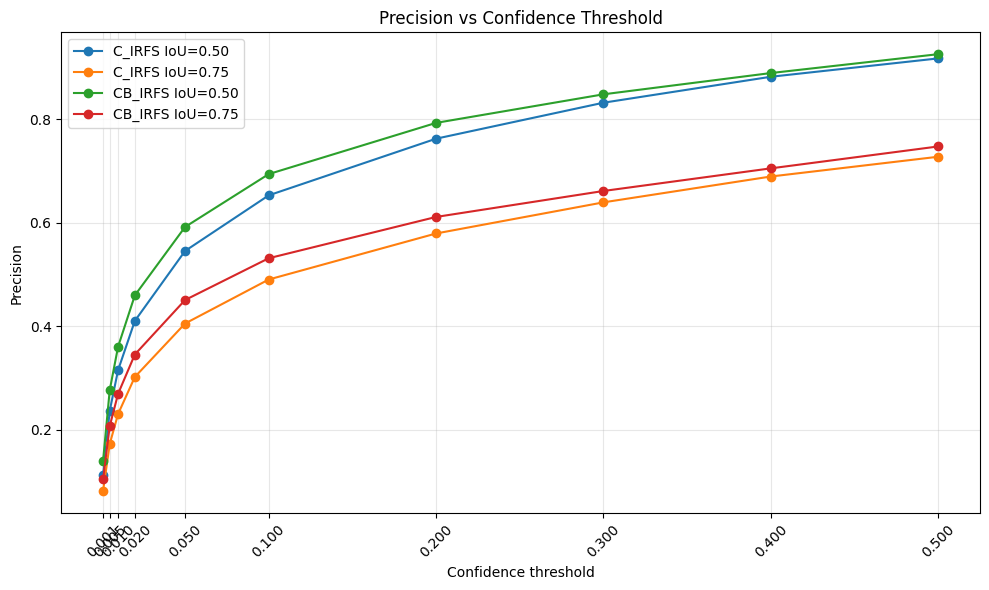

[SAVED] /kaggle/working/YOLO11_seg_expanded/research_experiments/confidence_threshold_analysis/precision_vs_confidence.png


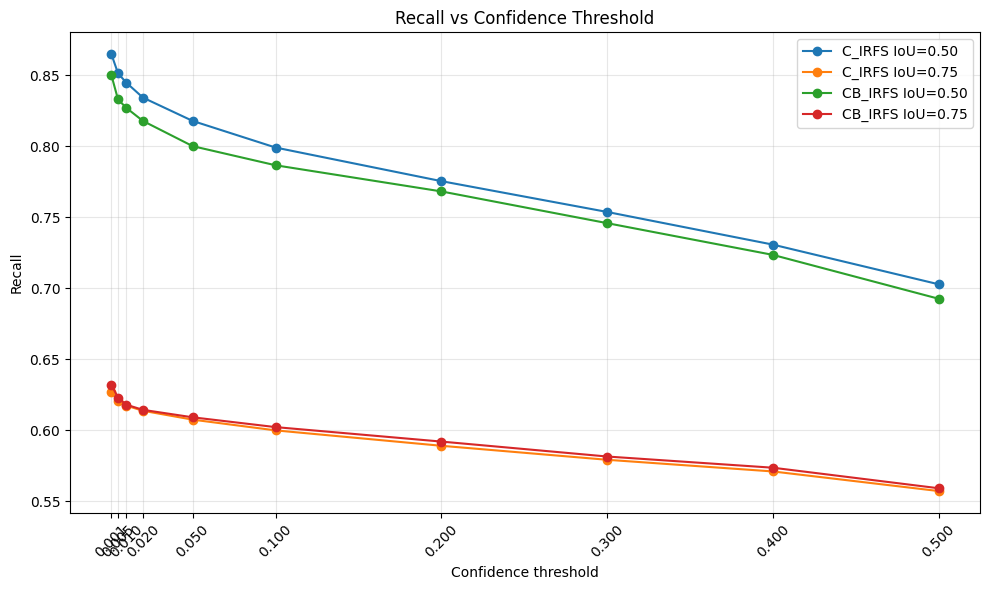

[SAVED] /kaggle/working/YOLO11_seg_expanded/research_experiments/confidence_threshold_analysis/recall_vs_confidence.png


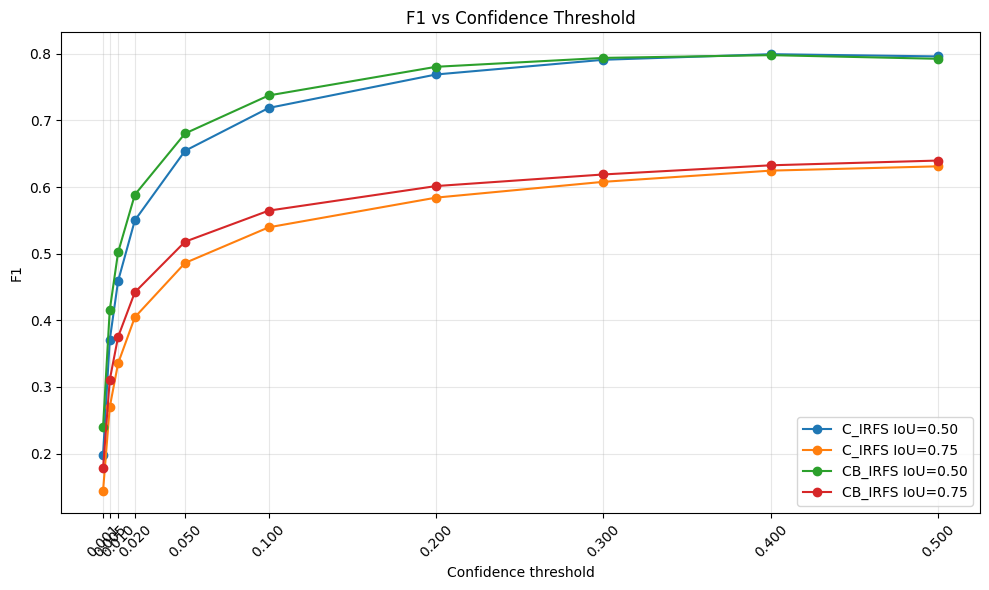

[SAVED] /kaggle/working/YOLO11_seg_expanded/research_experiments/confidence_threshold_analysis/f1_vs_confidence.png

10. EXPORT EXCEL

11. OVERALL CONFIDENCE THRESHOLD RESULTS
  model  confidence_threshold  iou_threshold  pred_count   tp    fp   fn  precision  recall     f1
CB_IRFS                0.0010         0.5000       18570 2586 15984  456     0.1393  0.8501 0.2393
 C_IRFS                0.0010         0.5000       23505 2631 20874  411     0.1119  0.8649 0.1982
CB_IRFS                0.0050         0.5000        9166 2534  6632  508     0.2765  0.8330 0.4151
 C_IRFS                0.0050         0.5000       10951 2590  8361  452     0.2365  0.8514 0.3702
CB_IRFS                0.0100         0.5000        6979 2516  4463  526     0.3605  0.8271 0.5021
 C_IRFS                0.0100         0.5000        8154 2570  5584  472     0.3152  0.8448 0.4591
CB_IRFS                0.0200         0.5000        5413 2488  2925  554     0.4596  0.8179 0.5885
 C_IRFS                0.0200   

In [35]:

# ============================================================
# CELL 17K - CONFIDENCE THRESHOLD ANALYSIS
# C-IRFS vs CB-IRFS
#
# Dataset: 268 validation images
# Ground Truth: 3,042 instances
# Classes: 6
#
# Inference:
#   Base confidence = 0.001
#   Image size      = 960
#   NMS IoU         = 0.70
#   Max detections  = 300
#   Device          = GPU 0
#
# Evaluation:
#   Confidence thresholds:
#       0.001, 0.005, 0.01, 0.02, 0.05,
#       0.10, 0.20, 0.30, 0.40, 0.50
#
#   Mask IoU thresholds:
#       0.50 and 0.75
#
# IMPORTANT:
#   Inference is performed only once per checkpoint.
#   Prediction masks are cached to disk.
#   Every confidence threshold gets a fresh Hungarian matching.
# ============================================================


# ============================================================
# 1. IMPORTS
# ============================================================

import os
import gc
import json
import warnings

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from pathlib import Path
from scipy.optimize import linear_sum_assignment

from ultralytics import YOLO
from ultralytics.utils.ops import scale_masks


# ============================================================
# 2. CONFIGURATION
# ============================================================

ROOT = Path("/kaggle/working/YOLO11_seg_expanded")

OUTPUT_DIR = (
    ROOT
    / "research_experiments"
    / "confidence_threshold_analysis"
)

CACHE_DIR = OUTPUT_DIR / "prediction_cache"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
CACHE_DIR.mkdir(parents=True, exist_ok=True)


MODEL_PATHS = {
    "C_IRFS": (
        ROOT
        / "research_experiments"
        / "C_irfs_t030"
        / "weights"
        / "best.pt"
    ),

    "CB_IRFS": (
        ROOT
        / "kaggle_outputs"
        / "CB_IRFS_sqrt_17ep_v1"
        / "weights"
        / "best.pt"
    ),
}


CLASS_NAMES = [
    "hat",
    "gloves",
    "mask",
    "pants",
    "shoes",
    "long-sleeved shirt",
]

NUM_CLASSES = 6


# Inference configuration.
DEVICE = 0

BASE_CONF = 0.001
IMGSZ = 960
NMS_IOU = 0.70
MAX_DET = 300
HALF = True
RETINA_MASKS = False


# Confidence thresholds to evaluate.
CONF_THRESHOLDS = [
    0.001,
    0.005,
    0.01,
    0.02,
    0.05,
    0.10,
    0.20,
    0.30,
    0.40,
    0.50,
]


# Mask IoU thresholds.
MASK_IOU_THRESHOLDS = [
    0.50,
    0.75,
]


# Ground Truth object-size definitions:
# small:  area ratio < 1%
# medium: 1% <= area ratio < 5%
# large:  area ratio >= 5%

SMALL_MAX_RATIO = 0.01
MEDIUM_MAX_RATIO = 0.05


EXPECTED_IMAGES = 268
EXPECTED_GT_INSTANCES = 3042


# Expected baseline results from Cell 17I-FIX.
# Used to verify that the new inference/cache pipeline
# reproduces the previous conf=0.001 analysis.

EXPECTED_BASELINE = {
    ("C_IRFS", 0.50): {
        "pred_count": 23505,
        "tp": 2631,
        "fp": 20874,
        "fn": 411,
    },

    ("C_IRFS", 0.75): {
        "pred_count": 23505,
        "tp": 1908,
        "fp": 21597,
        "fn": 1134,
    },

    ("CB_IRFS", 0.50): {
        "pred_count": 18570,
        "tp": 2586,
        "fp": 15984,
        "fn": 456,
    },

    ("CB_IRFS", 0.75): {
        "pred_count": 18570,
        "tp": 1923,
        "fp": 16647,
        "fn": 1119,
    },
}


# ============================================================
# 3. VERIFY PREVIOUS CELL STATE
# ============================================================

print("=" * 80)
print("1. VERIFY NOTEBOOK STATE")
print("=" * 80)

required_variables = [
    "image_records",
]

missing = [
    x for x in required_variables
    if x not in globals()
]

if missing:
    raise RuntimeError(
        "Missing variables from previous cells: "
        + ", ".join(missing)
        + ". Run the completed Cell 17I-FIX first."
    )


if len(image_records) != EXPECTED_IMAGES:
    raise RuntimeError(
        f"Expected {EXPECTED_IMAGES} images, "
        f"found {len(image_records)}."
    )


if DEVICE >= torch.cuda.device_count():
    raise RuntimeError(
        f"GPU {DEVICE} is unavailable."
    )


if not torch.cuda.is_available():
    raise RuntimeError("CUDA is unavailable.")


for model_name, checkpoint in MODEL_PATHS.items():

    if not checkpoint.exists():
        raise FileNotFoundError(
            f"Missing checkpoint: {checkpoint}"
        )


for threshold in CONF_THRESHOLDS:

    if threshold < BASE_CONF:
        raise ValueError(
            f"Confidence threshold {threshold} is below "
            f"the inference base threshold {BASE_CONF}."
        )


torch.cuda.set_device(DEVICE)
gc.collect()
torch.cuda.empty_cache()

free_bytes, total_bytes = torch.cuda.mem_get_info(DEVICE)

print("Images:", len(image_records))
print("GPU:", torch.cuda.get_device_name(DEVICE))
print(f"GPU free: {free_bytes / 1024**3:.2f} GB")
print("C-IRFS checkpoint:", MODEL_PATHS["C_IRFS"])
print("CB-IRFS checkpoint:", MODEL_PATHS["CB_IRFS"])

if free_bytes / 1024**3 < 8:
    raise RuntimeError(
        "Not enough free GPU memory. "
        "At least 8 GB is required."
    )

print("\nNotebook verification: PASSED")


# ============================================================
# 4. VERIFY GROUND TRUTH
# ============================================================

print("\n" + "=" * 80)
print("2. VERIFY GROUND TRUTH")
print("=" * 80)

gt_count = 0
gt_class_counts = {
    i: 0 for i in range(NUM_CLASSES)
}

for record in image_records:

    if "gt_objects" not in record:
        raise RuntimeError(
            f"Missing GT objects: {record['image_name']}"
        )

    for obj in record["gt_objects"]:

        class_id = int(obj["class_id"])

        if not 0 <= class_id < NUM_CLASSES:
            raise RuntimeError(
                f"Invalid GT class: {class_id}"
            )

        gt_class_counts[class_id] += 1
        gt_count += 1


EXPECTED_CLASS_COUNTS = {
    0: 829,
    1: 238,
    2: 339,
    3: 446,
    4: 274,
    5: 916,
}


if gt_count != EXPECTED_GT_INSTANCES:
    raise RuntimeError(
        f"Expected {EXPECTED_GT_INSTANCES} GT instances, "
        f"found {gt_count}."
    )


if gt_class_counts != EXPECTED_CLASS_COUNTS:
    raise RuntimeError(
        "GT class counts do not match verified data.\n"
        f"Expected: {EXPECTED_CLASS_COUNTS}\n"
        f"Actual:   {gt_class_counts}"
    )


print("Total GT instances:", gt_count)

for class_id, class_name in enumerate(CLASS_NAMES):
    print(
        f"{class_id}: {class_name:<22} "
        f"{gt_class_counts[class_id]}"
    )

print("\nGround Truth verification: PASSED")


# ============================================================
# 5. OBJECT SIZE CLASSIFICATION
# ============================================================

def classify_size(area_ratio):

    if area_ratio < SMALL_MAX_RATIO:
        return "small"

    if area_ratio < MEDIUM_MAX_RATIO:
        return "medium"

    return "large"


# ============================================================
# 6. RUN INFERENCE AND SAVE CROPPED MASKS
# ============================================================

def infer_and_cache_one_image(model, image_record):

    image_path = Path(image_record["image_path"])

    height = int(image_record["height"])
    width = int(image_record["width"])

    results = model.predict(
        source=str(image_path),

        imgsz=IMGSZ,

        batch=1,

        conf=BASE_CONF,

        iou=NMS_IOU,

        max_det=MAX_DET,

        retina_masks=False,

        half=HALF,

        device=DEVICE,

        verbose=False,

        stream=False,
    )

    predictions = []

    if not results:
        return predictions

    result = results[0]

    if result.boxes is None or result.masks is None:
        del results
        return predictions

    boxes = result.boxes
    raw_masks = result.masks.data

    if raw_masks.ndim != 3:
        raise RuntimeError(
            f"Unexpected raw mask shape: "
            f"{tuple(raw_masks.shape)}"
        )

    class_ids = (
        boxes.cls.detach()
        .cpu()
        .numpy()
        .astype(int)
    )

    confidences = (
        boxes.conf.detach()
        .cpu()
        .numpy()
    )

    num_predictions = min(
        len(class_ids),
        len(confidences),
        len(raw_masks)
    )

    for i in range(num_predictions):

        class_id = int(class_ids[i])

        if not 0 <= class_id < NUM_CLASSES:
            continue

        confidence = float(confidences[i])

        # Mask tensor:
        # [1, H, W] -> [1, 1, H, W].
        one_mask = (
            raw_masks[i:i + 1]
            .detach()
            .float()
            .cpu()
            .unsqueeze(1)
        )

        scaled_mask = scale_masks(
            one_mask,
            (height, width)
        )

        binary_mask = (
            scaled_mask[0, 0].numpy() >= 0.5
        )

        del one_mask, scaled_mask

        ys, xs = np.where(binary_mask)

        if len(xs) == 0:
            del binary_mask
            continue

        x_min = int(xs.min())
        y_min = int(ys.min())

        x_max = int(xs.max()) + 1
        y_max = int(ys.max()) + 1

        cropped_mask = binary_mask[
            y_min:y_max,
            x_min:x_max
        ].copy()

        area = int(cropped_mask.sum())

        if area == 0:
            del binary_mask, cropped_mask
            continue

        area_ratio = area / float(width * height)

        predictions.append({
            "id": i,
            "class_id": class_id,
            "confidence": confidence,

            "bbox": (
                x_min,
                y_min,
                x_max,
                y_max,
            ),

            "mask": cropped_mask.astype(bool),

            "area": area,

            "area_ratio": area_ratio,

            "size": classify_size(area_ratio),
        })

        del binary_mask, cropped_mask

    del raw_masks, boxes, result, results

    return predictions


# ============================================================
# 7. SAVE PREDICTIONS TO COMPRESSED NPZ
# ============================================================

def save_prediction_cache(predictions, output_path):

    n = len(predictions)

    if n == 0:

        np.savez_compressed(
            output_path,

            class_ids=np.empty(0, dtype=np.int16),

            confidences=np.empty(0, dtype=np.float32),

            boxes=np.empty((0, 4), dtype=np.int32),

            areas=np.empty(0, dtype=np.int32),

            area_ratios=np.empty(0, dtype=np.float32),

            shapes=np.empty((0, 2), dtype=np.int32),

            offsets=np.zeros(1, dtype=np.int64),

            flat_masks=np.empty(0, dtype=np.uint8),
        )

        return


    class_ids = []
    confidences = []
    boxes = []
    areas = []
    area_ratios = []
    shapes = []

    offsets = [0]
    mask_parts = []

    for pred in predictions:

        mask = np.asarray(
            pred["mask"],
            dtype=np.uint8
        )

        h, w = mask.shape

        class_ids.append(pred["class_id"])
        confidences.append(pred["confidence"])

        boxes.append(pred["bbox"])

        areas.append(pred["area"])
        area_ratios.append(pred["area_ratio"])

        shapes.append((h, w))

        flattened = mask.reshape(-1)

        mask_parts.append(flattened)

        offsets.append(
            offsets[-1] + len(flattened)
        )


    flat_masks = np.concatenate(mask_parts)

    np.savez_compressed(
        output_path,

        class_ids=np.asarray(
            class_ids,
            dtype=np.int16
        ),

        confidences=np.asarray(
            confidences,
            dtype=np.float32
        ),

        boxes=np.asarray(
            boxes,
            dtype=np.int32
        ).reshape(-1, 4),

        areas=np.asarray(
            areas,
            dtype=np.int32
        ),

        area_ratios=np.asarray(
            area_ratios,
            dtype=np.float32
        ),

        shapes=np.asarray(
            shapes,
            dtype=np.int32
        ).reshape(-1, 2),

        offsets=np.asarray(
            offsets,
            dtype=np.int64
        ),

        flat_masks=flat_masks,
    )


# ============================================================
# 8. LOAD PREDICTIONS FROM CACHE
# ============================================================

def load_prediction_cache(cache_path):

    predictions = []

    with np.load(
        cache_path,
        allow_pickle=False
    ) as data:

        class_ids = data["class_ids"]
        confidences = data["confidences"]

        boxes = data["boxes"]

        areas = data["areas"]
        area_ratios = data["area_ratios"]

        shapes = data["shapes"]
        offsets = data["offsets"]

        flat_masks = data["flat_masks"]

        n = len(class_ids)

        for i in range(n):

            h, w = shapes[i]

            start = int(offsets[i])
            end = int(offsets[i + 1])

            mask = (
                flat_masks[start:end]
                .reshape(int(h), int(w))
                .astype(bool)
            )

            predictions.append({

                "id": i,

                "class_id": int(class_ids[i]),

                "confidence": float(confidences[i]),

                "bbox": tuple(
                    int(x) for x in boxes[i]
                ),

                "mask": mask,

                "area": int(areas[i]),

                "area_ratio": float(area_ratios[i]),

                "size": classify_size(
                    float(area_ratios[i])
                ),
            })

    return predictions


# ============================================================
# 9. RUN AND CACHE ONE MODEL
# ============================================================

def generate_model_cache(model_name, checkpoint):

    print("\n" + "=" * 80)
    print("GENERATING CACHE:", model_name)
    print("=" * 80)

    model_cache_dir = CACHE_DIR / model_name

    model_cache_dir.mkdir(
        parents=True,
        exist_ok=True
    )

    # Clean old cache to ensure the current inference settings
    # are used consistently.
    for old_file in model_cache_dir.glob("*.npz"):
        old_file.unlink()

    model = YOLO(str(checkpoint))

    prediction_counts = []

    manifest_rows = []

    for index, image_record in enumerate(
        image_records,
        start=0
    ):

        predictions = infer_and_cache_one_image(
            model,
            image_record
        )

        cache_path = (
            model_cache_dir
            / f"{index:04d}.npz"
        )

        save_prediction_cache(
            predictions,
            cache_path
        )

        prediction_count = len(predictions)

        prediction_counts.append(
            prediction_count
        )

        manifest_rows.append({
            "index": index,

            "image": image_record["image_name"],

            "split": image_record["split"],

            "prediction_count": prediction_count,

            "cache_file": str(cache_path),
        })

        if (index + 1) % 10 == 0 or index + 1 == len(image_records):

            free_bytes, _ = torch.cuda.mem_get_info(DEVICE)

            print(
                f"[{model_name}] "
                f"{index + 1:3d}/{len(image_records)} | "
                f"predictions={prediction_count:3d} | "
                f"GPU free={free_bytes / 1024**3:.2f} GB"
            )

        del predictions

        if (index + 1) % 10 == 0:
            gc.collect()
            torch.cuda.empty_cache()


    del model

    gc.collect()
    torch.cuda.empty_cache()

    manifest_df = pd.DataFrame(manifest_rows)

    manifest_df.to_csv(
        OUTPUT_DIR / f"{model_name}_cache_manifest.csv",
        index=False
    )

    cache_summary = {

        "model": model_name,

        "num_images": len(image_records),

        "total_predictions": int(
            np.sum(prediction_counts)
        ),

        "mean_predictions_per_image": float(
            np.mean(prediction_counts)
        ),

        "max_predictions_per_image": int(
            np.max(prediction_counts)
        ),

        "images_at_max_det": int(
            np.sum(
                np.asarray(prediction_counts) >= MAX_DET
            )
        ),

        "base_conf": BASE_CONF,

        "imgsz": IMGSZ,

        "nms_iou": NMS_IOU,

        "max_det": MAX_DET,

        "half": HALF,

        "retina_masks": RETINA_MASKS,

    }

    with open(
        OUTPUT_DIR / f"{model_name}_cache_metadata.json",
        "w",
        encoding="utf-8"
    ) as f:

        json.dump(
            cache_summary,
            f,
            indent=2
        )


    print("\nCache summary:")
    print(json.dumps(cache_summary, indent=2))

    if cache_summary["images_at_max_det"] > 0:

        print(
            "\nWARNING: Some images reached max_det=300. "
            "Their detections may have been truncated."
        )

    return cache_summary


# ============================================================
# 10. GENERATE CACHES FOR BOTH CHECKPOINTS
# ============================================================

print("\n" + "=" * 80)
print("3. GENERATE PREDICTION CACHES")
print("=" * 80)

cache_summaries = {}

for model_name, checkpoint in MODEL_PATHS.items():

    cache_summaries[model_name] = generate_model_cache(
        model_name,
        checkpoint
    )


print("\nBoth model caches generated.")


# ============================================================
# 11. MASK IoU BETWEEN CROPPED MASKS
# ============================================================

def cropped_mask_iou(obj_a, obj_b):

    ax1, ay1, ax2, ay2 = obj_a["bbox"]

    bx1, by1, bx2, by2 = obj_b["bbox"]

    x1 = max(ax1, bx1)
    y1 = max(ay1, by1)

    x2 = min(ax2, bx2)
    y2 = min(ay2, by2)

    intersection = 0

    if x2 > x1 and y2 > y1:

        a_crop = obj_a["mask"][
            y1 - ay1:y2 - ay1,
            x1 - ax1:x2 - ax1
        ]

        b_crop = obj_b["mask"][
            y1 - by1:y2 - by1,
            x1 - bx1:x2 - bx1
        ]

        intersection = int(
            np.logical_and(
                a_crop,
                b_crop
            ).sum()
        )


    union = (
        int(obj_a["area"])
        + int(obj_b["area"])
        - intersection
    )

    if union <= 0:
        return 0.0

    return float(intersection / union)


# ============================================================
# 12. PRECOMPUTE FULL IoU MATRIX
# ============================================================

def compute_iou_matrix(gt_objects, pred_objects):

    n_gt = len(gt_objects)
    n_pred = len(pred_objects)

    matrix = np.zeros(
        (n_gt, n_pred),
        dtype=np.float32
    )

    for i, gt_obj in enumerate(gt_objects):

        for j, pred_obj in enumerate(pred_objects):

            matrix[i, j] = cropped_mask_iou(
                gt_obj,
                pred_obj
            )

    return matrix


# ============================================================
# 13. HUNGARIAN MATCHING
# ============================================================

def hungarian_match_from_iou(iou_matrix, threshold):

    n_gt, n_pred = iou_matrix.shape

    if n_gt == 0 or n_pred == 0:
        return []

    matrix_size = max(n_gt, n_pred)

    score = np.zeros(
        (matrix_size, matrix_size),
        dtype=np.float64
    )

    valid = iou_matrix >= threshold

    # Maximize the number of valid matches first,
    # then maximize the total IoU.
    score[:n_gt, :n_pred] = np.where(
        valid,
        1_000_000.0 + iou_matrix,
        -1_000_000.0
    )

    rows, cols = linear_sum_assignment(-score)

    matches = []

    for row, col in zip(rows, cols):

        if row >= n_gt or col >= n_pred:
            continue

        iou_value = float(
            iou_matrix[row, col]
        )

        if iou_value >= threshold:

            matches.append((
                int(row),
                int(col),
                iou_value
            ))

    return matches


# ============================================================
# 14. ANALYZE ONE MODEL ACROSS ALL CONFIDENCE THRESHOLDS
# ============================================================

def analyze_model_thresholds(model_name):

    print("\n" + "=" * 80)
    print("ANALYZING:", model_name)
    print("=" * 80)

    model_cache_dir = CACHE_DIR / model_name

    metric_rows = []

    for image_index, image_record in enumerate(image_records):

        cache_path = (
            model_cache_dir
            / f"{image_index:04d}.npz"
        )

        if not cache_path.exists():

            raise FileNotFoundError(
                f"Missing cache: {cache_path}"
            )

        predictions = load_prediction_cache(
            cache_path
        )

        gt_objects = image_record["gt_objects"]

        # Group predictions and GT by class.
        gt_by_class = {
            c: [
                obj for obj in gt_objects
                if int(obj["class_id"]) == c
            ]
            for c in range(NUM_CLASSES)
        }

        pred_by_class = {
            c: [
                obj for obj in predictions
                if int(obj["class_id"]) == c
            ]
            for c in range(NUM_CLASSES)
        }


        # Precompute IoU once for each class and image.
        # The same IoU matrix is reused for all confidence
        # and mask IoU thresholds.
        iou_by_class = {}

        for class_id in range(NUM_CLASSES):

            iou_by_class[class_id] = compute_iou_matrix(
                gt_by_class[class_id],
                pred_by_class[class_id]
            )


        # Evaluate each confidence threshold.
        for conf_threshold in CONF_THRESHOLDS:

            for mask_iou_threshold in MASK_IOU_THRESHOLDS:

                for class_id in range(NUM_CLASSES):

                    gt_class = gt_by_class[class_id]
                    pred_class = pred_by_class[class_id]

                    iou_full = iou_by_class[class_id]

                    # Keep predictions above the current
                    # confidence threshold.
                    selected_prediction_indices = [
                        j
                        for j, pred in enumerate(pred_class)
                        if pred["confidence"] >= conf_threshold
                    ]

                    selected_count = len(
                        selected_prediction_indices
                    )

                    # Restrict the precomputed IoU matrix
                    # to the surviving predictions.
                    if selected_count > 0:

                        iou_selected = iou_full[
                            :,
                            selected_prediction_indices
                        ]

                    else:

                        iou_selected = np.zeros(
                            (len(gt_class), 0),
                            dtype=np.float32
                        )


                    matches = hungarian_match_from_iou(
                        iou_selected,
                        mask_iou_threshold
                    )

                    matched_gt_indices = {
                        item[0] for item in matches
                    }

                    tp = len(matches)

                    fp = selected_count - tp

                    fn = len(gt_class) - tp

                    precision = (
                        tp / (tp + fp)
                        if (tp + fp) > 0
                        else 0.0
                    )

                    recall = (
                        tp / (tp + fn)
                        if (tp + fn) > 0
                        else 0.0
                    )

                    f1 = (
                        2 * precision * recall
                        / (precision + recall)
                        if (precision + recall) > 0
                        else 0.0
                    )


                    # Size-based GT and TP counts.
                    size_counts = {
                        "small": {
                            "gt": 0,
                            "tp": 0,
                        },

                        "medium": {
                            "gt": 0,
                            "tp": 0,
                        },

                        "large": {
                            "gt": 0,
                            "tp": 0,
                        },
                    }


                    for gt_idx, gt_obj in enumerate(gt_class):

                        size_name = gt_obj["size"]

                        size_counts[size_name]["gt"] += 1

                        if gt_idx in matched_gt_indices:

                            size_counts[size_name]["tp"] += 1


                    row = {

                        "model": model_name,

                        "image": image_record["image_name"],

                        "split": image_record["split"],

                        "class_id": class_id,

                        "class_name": CLASS_NAMES[class_id],

                        "confidence_threshold": conf_threshold,

                        "iou_threshold": mask_iou_threshold,

                        "gt_count": len(gt_class),

                        "pred_count": selected_count,

                        "tp": tp,

                        "fp": fp,

                        "fn": fn,

                        "precision": precision,

                        "recall": recall,

                        "f1": f1,
                    }


                    for size_name in [
                        "small",
                        "medium",
                        "large",
                    ]:

                        gt_size = size_counts[size_name]["gt"]

                        tp_size = size_counts[size_name]["tp"]

                        row[f"{size_name}_gt"] = gt_size

                        row[f"{size_name}_tp"] = tp_size

                        row[f"{size_name}_fn"] = (
                            gt_size - tp_size
                        )


                    metric_rows.append(row)


        del predictions

        if (image_index + 1) % 20 == 0:

            print(
                f"[{model_name}] "
                f"{image_index + 1:3d}/{len(image_records)} "
                f"images analyzed | "
                f"rows={len(metric_rows)}"
            )

            gc.collect()


    return pd.DataFrame(metric_rows)


# ============================================================
# 15. ANALYZE BOTH MODELS
# ============================================================

print("\n" + "=" * 80)
print("4. CONFIDENCE THRESHOLD EVALUATION")
print("=" * 80)

all_metrics = []

for model_name in MODEL_PATHS.keys():

    model_metrics = analyze_model_thresholds(
        model_name
    )

    model_metrics.to_csv(
        OUTPUT_DIR
        / f"{model_name}_confidence_per_image_metrics.csv",
        index=False
    )

    all_metrics.append(model_metrics)

    print(
        f"\n{model_name}: "
        f"{len(model_metrics)} rows"
    )

    del model_metrics
    gc.collect()


metrics_df = pd.concat(
    all_metrics,
    ignore_index=True
)

metrics_df.to_csv(
    OUTPUT_DIR / "ALL_confidence_per_image_metrics.csv",
    index=False
)

print("\nTotal per-image metric rows:", len(metrics_df))


# ============================================================
# 16. SUMMARY HELPER
# ============================================================

def calculate_summary(df, group_columns):

    summary = (
        df
        .groupby(
            group_columns,
            as_index=False
        )
        .agg({

            "gt_count": "sum",

            "pred_count": "sum",

            "tp": "sum",

            "fp": "sum",

            "fn": "sum",

            "small_gt": "sum",

            "small_tp": "sum",

            "small_fn": "sum",

            "medium_gt": "sum",

            "medium_tp": "sum",

            "medium_fn": "sum",

            "large_gt": "sum",

            "large_tp": "sum",

            "large_fn": "sum",

        })
    )


    summary["precision"] = (
        summary["tp"]
        / (
            summary["tp"] + summary["fp"]
        ).replace(0, np.nan)
    ).fillna(0)


    summary["recall"] = (
        summary["tp"]
        / (
            summary["tp"] + summary["fn"]
        ).replace(0, np.nan)
    ).fillna(0)


    summary["f1"] = (
        2 * summary["precision"] * summary["recall"]
        / (
            summary["precision"] + summary["recall"]
        ).replace(0, np.nan)
    ).fillna(0)


    for size_name in [
        "small",
        "medium",
        "large",
    ]:

        summary[f"{size_name}_recall"] = (
            summary[f"{size_name}_tp"]
            / summary[f"{size_name}_gt"].replace(0, np.nan)
        )

    return summary


# ============================================================
# 17. OVERALL SUMMARY
# ============================================================

print("\n" + "=" * 80)
print("5. OVERALL SUMMARY")
print("=" * 80)

overall_summary = calculate_summary(
    metrics_df,

    [
        "model",
        "confidence_threshold",
        "iou_threshold",
    ]
)

overall_summary.to_csv(
    OUTPUT_DIR / "overall_confidence_summary.csv",
    index=False
)


# ============================================================
# 18. PER-CLASS SUMMARY
# ============================================================

print("\n" + "=" * 80)
print("6. PER-CLASS SUMMARY")
print("=" * 80)

class_summary = calculate_summary(
    metrics_df,

    [
        "model",
        "confidence_threshold",
        "iou_threshold",
        "class_id",
        "class_name",
    ]
)

class_summary.to_csv(
    OUTPUT_DIR / "per_class_confidence_summary.csv",
    index=False
)


# ============================================================
# 19. OLD VS NEW SUMMARY
# ============================================================

print("\n" + "=" * 80)
print("7. OLD VS NEW SUMMARY")
print("=" * 80)

split_summary = calculate_summary(
    metrics_df,

    [
        "model",
        "split",
        "confidence_threshold",
        "iou_threshold",
    ]
)

split_summary.to_csv(
    OUTPUT_DIR / "old_new_confidence_summary.csv",
    index=False
)


# ============================================================
# 20. SIZE-BASED RECALL SUMMARY
# ============================================================

size_rows = []

for _, row in class_summary.iterrows():

    for size_name in [
        "small",
        "medium",
        "large",
    ]:

        size_rows.append({

            "model": row["model"],

            "confidence_threshold": row[
                "confidence_threshold"
            ],

            "iou_threshold": row["iou_threshold"],

            "class_id": row["class_id"],

            "class_name": row["class_name"],

            "size": size_name,

            "gt_count": row[f"{size_name}_gt"],

            "tp": row[f"{size_name}_tp"],

            "fn": row[f"{size_name}_fn"],

            "recall": row[f"{size_name}_recall"],

        })


size_summary = pd.DataFrame(size_rows)

size_summary.to_csv(
    OUTPUT_DIR / "size_based_confidence_summary.csv",
    index=False
)


# ============================================================
# 21. BEST GLOBAL CONFIDENCE THRESHOLD
# ============================================================

# IMPORTANT:
# This threshold is selected using the current validation set.
# It is a diagnostic operating point, not an independent test result.

best_global_rows = []

for (
    model_name,
    iou_threshold
), group in overall_summary.groupby(
    ["model", "iou_threshold"]
):

    best_row = (
        group
        .sort_values(
            ["f1", "precision"],
            ascending=[False, False]
        )
        .iloc[0]
    )

    best_global_rows.append({

        "model": model_name,

        "iou_threshold": iou_threshold,

        "best_confidence_threshold": (
            best_row["confidence_threshold"]
        ),

        "precision": best_row["precision"],

        "recall": best_row["recall"],

        "f1": best_row["f1"],

        "tp": best_row["tp"],

        "fp": best_row["fp"],

        "fn": best_row["fn"],

    })


best_global_summary = pd.DataFrame(
    best_global_rows
)

best_global_summary.to_csv(
    OUTPUT_DIR / "best_global_confidence_threshold.csv",
    index=False
)


# ============================================================
# 22. BEST CONFIDENCE THRESHOLD PER CLASS
# ============================================================

best_class_rows = []

for (
    model_name,
    iou_threshold,
    class_id,
    class_name
), group in class_summary.groupby(
    [
        "model",
        "iou_threshold",
        "class_id",
        "class_name",
    ]
):

    best_row = (
        group
        .sort_values(
            ["f1", "precision"],
            ascending=[False, False]
        )
        .iloc[0]
    )

    best_class_rows.append({

        "model": model_name,

        "iou_threshold": iou_threshold,

        "class_id": class_id,

        "class_name": class_name,

        "best_confidence_threshold": (
            best_row["confidence_threshold"]
        ),

        "precision": best_row["precision"],

        "recall": best_row["recall"],

        "f1": best_row["f1"],

        "tp": best_row["tp"],

        "fp": best_row["fp"],

        "fn": best_row["fn"],

    })


best_class_summary = pd.DataFrame(
    best_class_rows
)

best_class_summary.to_csv(
    OUTPUT_DIR / "best_confidence_threshold_per_class.csv",
    index=False
)


# ============================================================
# 23. VERIFY CONFIDENCE=0.001 AGAINST CELL 17I-FIX
# ============================================================

print("\n" + "=" * 80)
print("8. BASELINE REPRODUCTION CHECK")
print("=" * 80)

baseline_rows = []

for (model_name, iou_threshold), expected in (
    EXPECTED_BASELINE.items()
):

    selected = overall_summary[
        (overall_summary["model"] == model_name)
        &
        (
            np.isclose(
                overall_summary["confidence_threshold"],
                BASE_CONF
            )
        )
        &
        (
            np.isclose(
                overall_summary["iou_threshold"],
                iou_threshold
            )
        )
    ]

    if len(selected) != 1:

        raise RuntimeError(
            f"Could not find baseline row for "
            f"{model_name}, IoU={iou_threshold}"
        )

    actual = selected.iloc[0]

    matches = True

    for key in [
        "pred_count",
        "tp",
        "fp",
        "fn",
    ]:

        actual_value = int(actual[key])

        expected_value = int(expected[key])

        if actual_value != expected_value:
            matches = False


    baseline_rows.append({

        "model": model_name,

        "iou_threshold": iou_threshold,

        "expected_pred": expected["pred_count"],

        "actual_pred": int(actual["pred_count"]),

        "expected_tp": expected["tp"],

        "actual_tp": int(actual["tp"]),

        "expected_fp": expected["fp"],

        "actual_fp": int(actual["fp"]),

        "expected_fn": expected["fn"],

        "actual_fn": int(actual["fn"]),

        "match": matches,

    })


baseline_check = pd.DataFrame(
    baseline_rows
)

print(
    baseline_check.to_string(index=False)
)

baseline_check.to_csv(
    OUTPUT_DIR / "baseline_reproduction_check.csv",
    index=False
)

if not baseline_check["match"].all():

    print(
        "\nWARNING: The new conf=0.001 results do not "
        "exactly reproduce Cell 17I-FIX."
    )

    print(
        "Do not interpret the threshold curves until "
        "the discrepancy is investigated."
    )

else:

    print("\nBaseline reproduction: PASSED")


# ============================================================
# 24. PLOT CONFIDENCE CURVES
# ============================================================

print("\n" + "=" * 80)
print("9. GENERATE CONFIDENCE CURVES")
print("=" * 80)

plot_metrics = [
    "precision",
    "recall",
    "f1",
]

for metric_name in plot_metrics:

    plt.figure(figsize=(10, 6))

    for model_name in MODEL_PATHS.keys():

        for iou_threshold in MASK_IOU_THRESHOLDS:

            subset = overall_summary[
                (overall_summary["model"] == model_name)
                &
                (
                    np.isclose(
                        overall_summary["iou_threshold"],
                        iou_threshold
                    )
                )
            ].sort_values("confidence_threshold")

            plt.plot(
                subset["confidence_threshold"],
                subset[metric_name],
                marker="o",
                label=(
                    f"{model_name} "
                    f"IoU={iou_threshold:.2f}"
                )
            )

    plt.xlabel("Confidence threshold")
    plt.ylabel(metric_name.capitalize())

    plt.title(
        f"{metric_name.capitalize()} vs Confidence Threshold"
    )

    plt.xticks(CONF_THRESHOLDS, rotation=45)

    plt.grid(True, alpha=0.3)

    plt.legend()

    plt.tight_layout()

    plot_path = (
        OUTPUT_DIR
        / f"{metric_name}_vs_confidence.png"
    )

    plt.savefig(
        plot_path,
        dpi=200,
        bbox_inches="tight"
    )

    plt.show()

    plt.close()

    print("[SAVED]", plot_path)


# ============================================================
# 25. EXPORT EXCEL WORKBOOK
# ============================================================

print("\n" + "=" * 80)
print("10. EXPORT EXCEL")
print("=" * 80)

excel_path = (
    OUTPUT_DIR
    / "confidence_threshold_analysis.xlsx"
)

with pd.ExcelWriter(
    excel_path,
    engine="openpyxl"
) as writer:

    overall_summary.to_excel(
        writer,
        sheet_name="Overall",
        index=False
    )

    class_summary.to_excel(
        writer,
        sheet_name="Per_Class",
        index=False
    )

    split_summary.to_excel(
        writer,
        sheet_name="Old_vs_New",
        index=False
    )

    size_summary.to_excel(
        writer,
        sheet_name="Size_Recall",
        index=False
    )

    best_global_summary.to_excel(
        writer,
        sheet_name="Best_Global_Threshold",
        index=False
    )

    best_class_summary.to_excel(
        writer,
        sheet_name="Best_Per_Class",
        index=False
    )

    baseline_check.to_excel(
        writer,
        sheet_name="Baseline_Check",
        index=False
    )


# ============================================================
# 26. PRINT OVERALL RESULTS
# ============================================================

print("\n" + "=" * 80)
print("11. OVERALL CONFIDENCE THRESHOLD RESULTS")
print("=" * 80)

display_columns = [
    "model",
    "confidence_threshold",
    "iou_threshold",
    "pred_count",
    "tp",
    "fp",
    "fn",
    "precision",
    "recall",
    "f1",
]

print(
    overall_summary[display_columns]
    .sort_values(
        [
            "iou_threshold",
            "confidence_threshold",
            "model",
        ]
    )
    .to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)


# ============================================================
# 27. PRINT BEST GLOBAL THRESHOLDS
# ============================================================

print("\n" + "=" * 80)
print("12. BEST GLOBAL THRESHOLD ON VALIDATION")
print("=" * 80)

print(
    best_global_summary.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)


# ============================================================
# 28. PRINT BEST THRESHOLD PER CLASS
# ============================================================

print("\n" + "=" * 80)
print("13. BEST THRESHOLD PER CLASS ON VALIDATION")
print("=" * 80)

print(
    best_class_summary.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)


# ============================================================
# 29. FINAL OUTPUT CHECK
# ============================================================

print("\n" + "=" * 80)
print("14. OUTPUT FILES")
print("=" * 80)

expected_files = [

    "ALL_confidence_per_image_metrics.csv",

    "overall_confidence_summary.csv",

    "per_class_confidence_summary.csv",

    "old_new_confidence_summary.csv",

    "size_based_confidence_summary.csv",

    "best_global_confidence_threshold.csv",

    "best_confidence_threshold_per_class.csv",

    "baseline_reproduction_check.csv",

    "precision_vs_confidence.png",

    "recall_vs_confidence.png",

    "f1_vs_confidence.png",

    "confidence_threshold_analysis.xlsx",

]


for filename in expected_files:

    path = OUTPUT_DIR / filename

    if not path.exists():

        raise RuntimeError(
            f"Missing output file: {path}"
        )

    print(
        f"[OK] {filename:<52} "
        f"{path.stat().st_size / 1024**2:.3f} MB"
    )


print("\nPrediction cache location:")
print(CACHE_DIR)

print("\nAnalysis output location:")
print(OUTPUT_DIR)

print("\n" + "=" * 80)
print("CELL 17K COMPLETED SUCCESSFULLY")
print("=" * 80)


1. VERIFY NOTEBOOK STATE
Images: 268
GPU: Tesla T4
GPU free: 13.22 GB
Prediction cache: PASSED

2. VERIFY GROUND TRUTH
Total GT: 3042
Class counts: {0: 829, 1: 238, 2: 339, 3: 446, 4: 274, 5: 916}
Ground Truth verification: PASSED

3. VERIFY CELL 17K RESULTS
Previous metric rows: 64320
Previous confidence thresholds: [np.float64(0.001), np.float64(0.005), np.float64(0.01), np.float64(0.02), np.float64(0.05), np.float64(0.1), np.float64(0.2), np.float64(0.3), np.float64(0.4), np.float64(0.5)]
Cell 17K metrics verification: PASSED

4. EXTENDED CONFIDENCE EVALUATION

--------------------------------------------------------------------------------
MODEL: C_IRFS
--------------------------------------------------------------------------------
[C_IRFS]  25/268 images
[C_IRFS]  50/268 images
[C_IRFS]  75/268 images
[C_IRFS] 100/268 images
[C_IRFS] 125/268 images
[C_IRFS] 150/268 images
[C_IRFS] 175/268 images
[C_IRFS] 200/268 images
[C_IRFS] 225/268 images
[C_IRFS] 250/268 images

------------

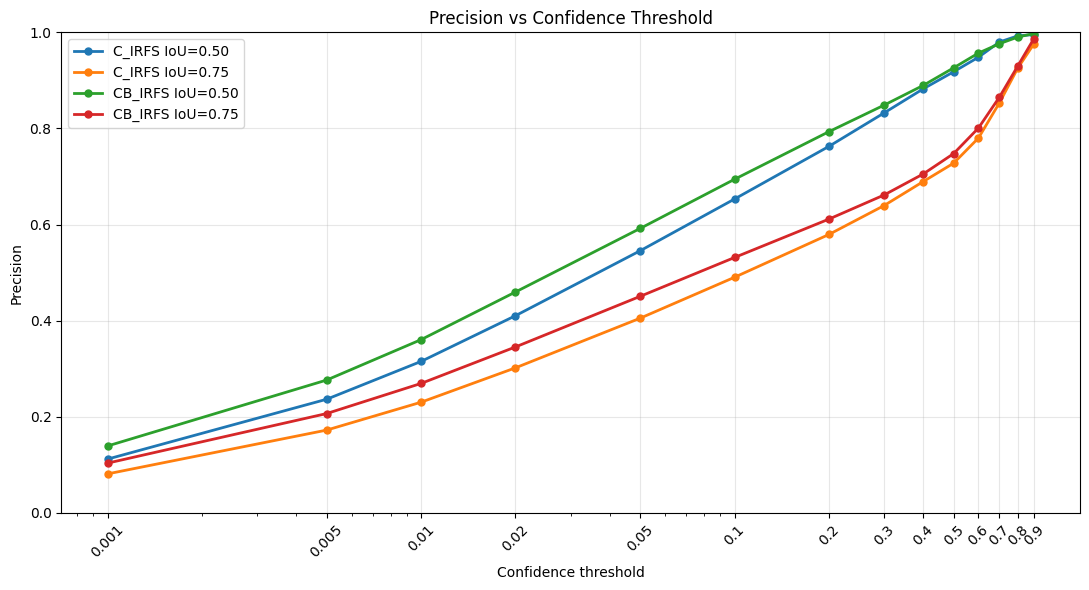

[SAVED] /kaggle/working/YOLO11_seg_expanded/research_experiments/confidence_threshold_analysis_extended/precision_vs_confidence_extended.png


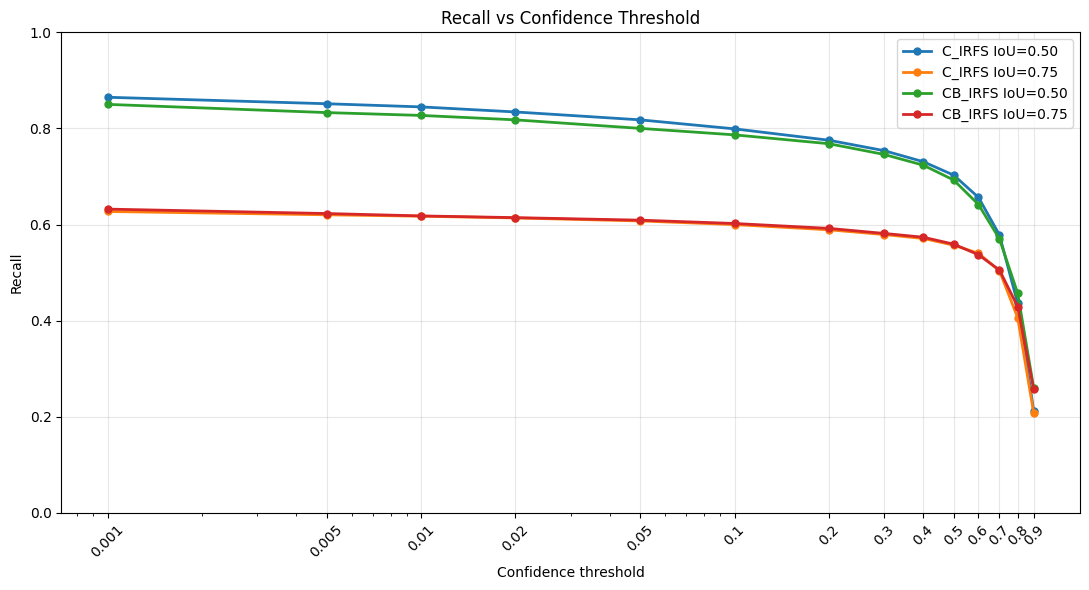

[SAVED] /kaggle/working/YOLO11_seg_expanded/research_experiments/confidence_threshold_analysis_extended/recall_vs_confidence_extended.png


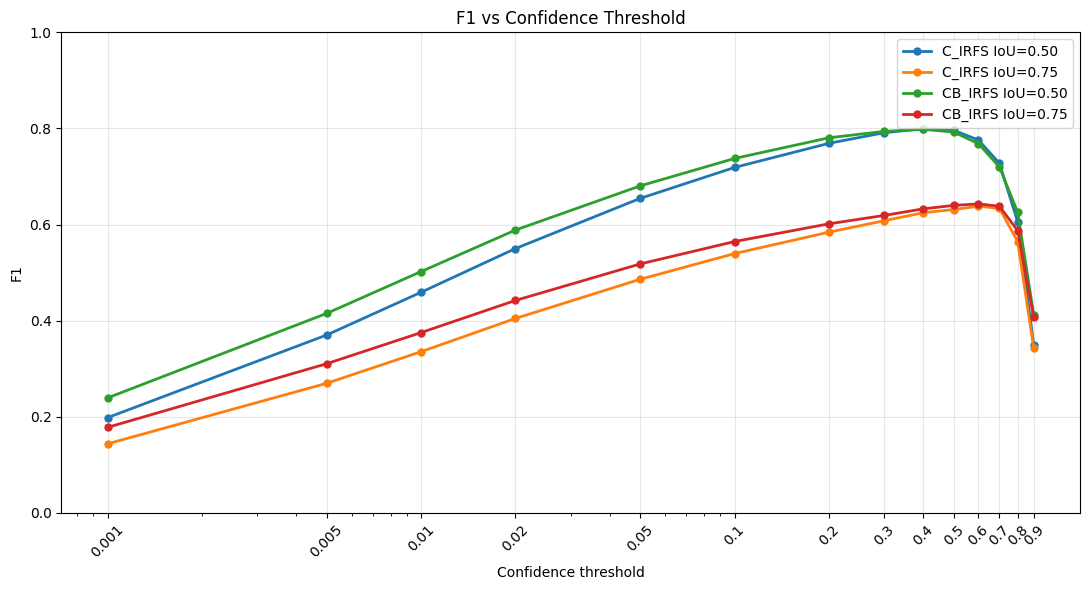

[SAVED] /kaggle/working/YOLO11_seg_expanded/research_experiments/confidence_threshold_analysis_extended/f1_vs_confidence_extended.png

8. FP/FN VISUAL AUDIT

Selecting images with highest FP + FN...
Selected visual examples: 24

9. CREATE FP/FN OVERLAYS
[SAVED] C_IRFS | hat | VHung__crowd_20260908_143140__000220.jpg
[SAVED] C_IRFS | hat | VHung__phone_20260908_133049__000080.jpg
[SAVED] C_IRFS | gloves | QuocHung__screen_on_off_outdoor_pm_20260908_130658__000040.jpg
[SAVED] C_IRFS | gloves | NhatTan__layout_20260908_142002__001430.jpg
[SAVED] C_IRFS | mask | QuocHung__screen_on_off_outdoor_pm_20260908_130658__000230.jpg
[SAVED] C_IRFS | mask | QuocHung__screen_on_off_outdoor_pm_20260908_130658__000210.jpg
[SAVED] C_IRFS | pants | VHung__crowd_20260908_143140__000280.jpg
[SAVED] C_IRFS | pants | VHung__crowd_20260908_143140__000370.jpg
[SAVED] C_IRFS | shoes | VHung__phone_20260908_133049__000050.jpg
[SAVED] C_IRFS | shoes | VHung__phone_20260908_133049__000090.jpg
[SAVED] C_IRFS | long

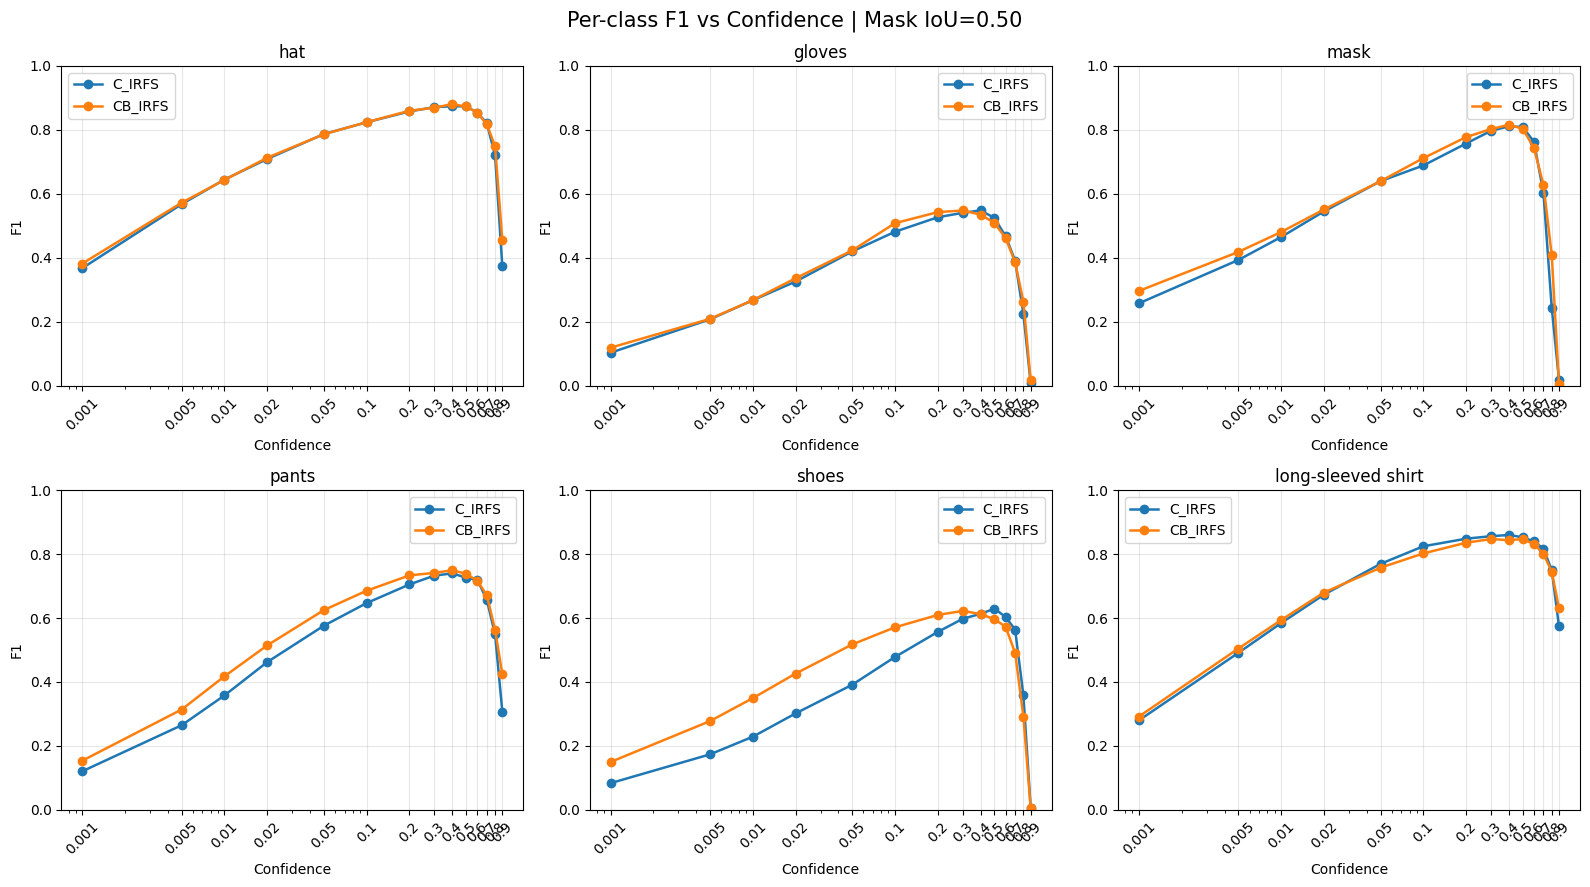

[SAVED] /kaggle/working/YOLO11_seg_expanded/research_experiments/confidence_threshold_analysis_extended/per_class_f1_iou_50_extended.png


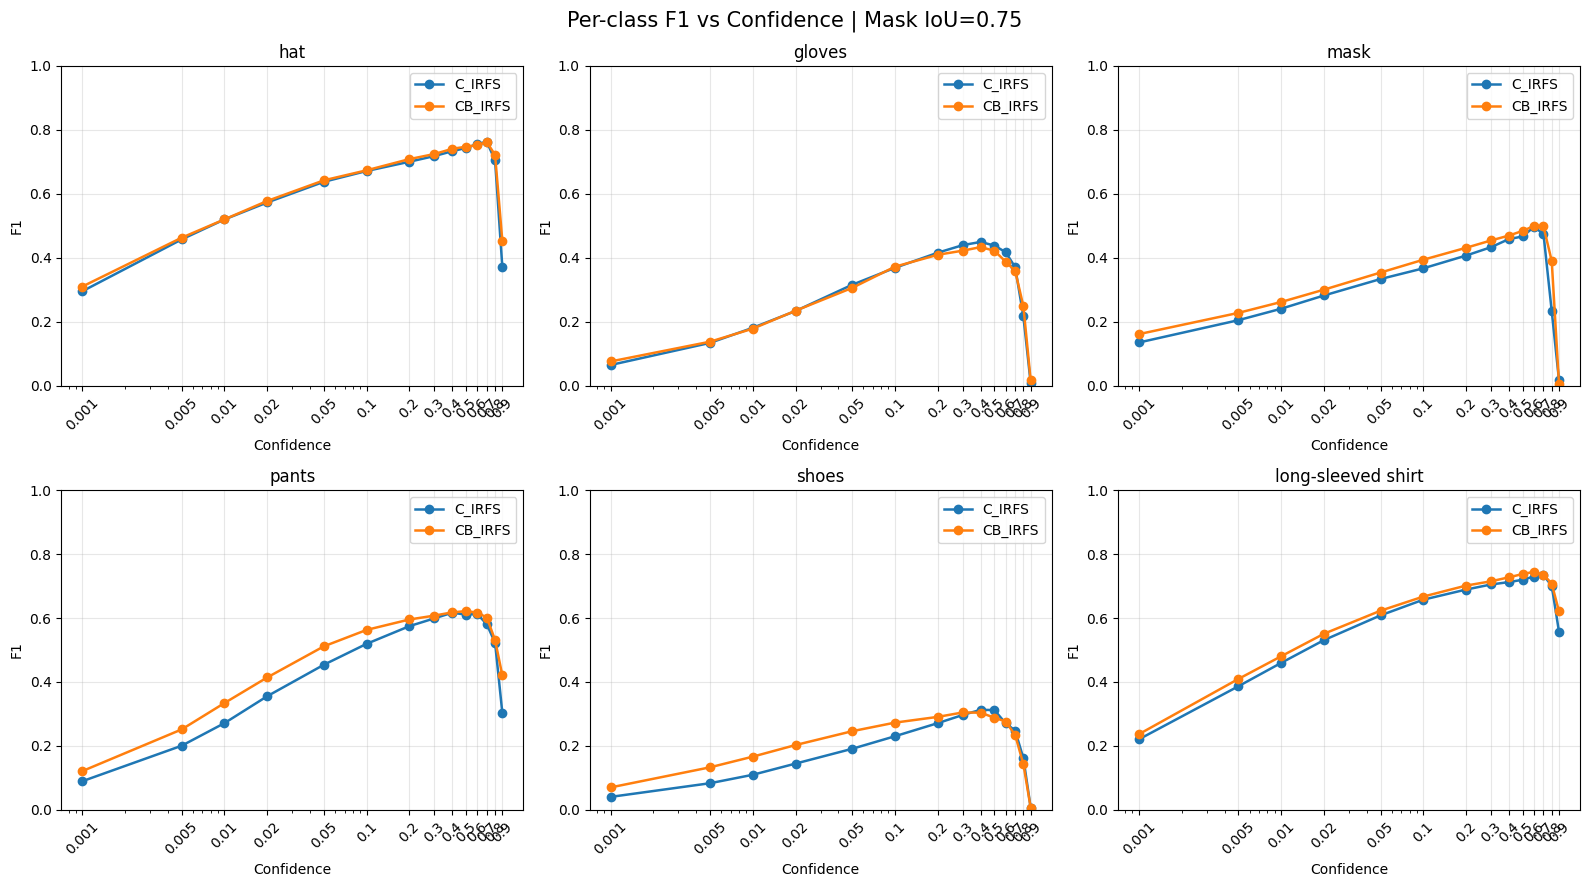

[SAVED] /kaggle/working/YOLO11_seg_expanded/research_experiments/confidence_threshold_analysis_extended/per_class_f1_iou_75_extended.png

11. EXPORT EXCEL

12. EXTENDED OVERALL RESULTS
  model  confidence_threshold  iou_threshold  pred_count   tp    fp   fn  precision  recall     f1
CB_IRFS                0.0010         0.5000       18570 2586 15984  456     0.1393  0.8501 0.2393
 C_IRFS                0.0010         0.5000       23505 2631 20874  411     0.1119  0.8649 0.1982
CB_IRFS                0.0050         0.5000        9166 2534  6632  508     0.2765  0.8330 0.4151
 C_IRFS                0.0050         0.5000       10951 2590  8361  452     0.2365  0.8514 0.3702
CB_IRFS                0.0100         0.5000        6979 2516  4463  526     0.3605  0.8271 0.5021
 C_IRFS                0.0100         0.5000        8154 2570  5584  472     0.3152  0.8448 0.4591
CB_IRFS                0.0200         0.5000        5413 2488  2925  554     0.4596  0.8179 0.5885
 C_IRFS                

In [36]:

# ============================================================
# CELL 17L
# EXTENDED CONFIDENCE ANALYSIS + FP/FN VISUAL AUDIT
#
# Models:
#   C_IRFS
#   CB_IRFS
#
# New confidence thresholds:
#   0.60, 0.70, 0.80, 0.90
#
# Existing thresholds:
#   Loaded from Cell 17K CSV
#
# Mask IoU:
#   0.50, 0.75
#
# Visual audit operating point:
#   Confidence = 0.40
#   Mask IoU   = 0.50
#
# IMPORTANT:
#   - No YOLO inference.
#   - Uses saved prediction cache from Cell 17K.
#   - Uses existing image_records and GT masks.
#   - Re-runs Hungarian matching after confidence filtering.
# ============================================================


# ============================================================
# 1. IMPORTS
# ============================================================

import os
import gc
import json
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from pathlib import Path
from scipy.optimize import linear_sum_assignment


# ============================================================
# 2. CONFIGURATION
# ============================================================

ROOT = Path("/kaggle/working/YOLO11_seg_expanded")

ANALYSIS_DIR = (
    ROOT
    / "research_experiments"
    / "confidence_threshold_analysis"
)

CACHE_DIR = ANALYSIS_DIR / "prediction_cache"

OUTPUT_DIR = (
    ROOT
    / "research_experiments"
    / "confidence_threshold_analysis_extended"
)

VISUAL_DIR = OUTPUT_DIR / "error_visualizations"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
VISUAL_DIR.mkdir(parents=True, exist_ok=True)


MODEL_NAMES = [
    "C_IRFS",
    "CB_IRFS",
]

CLASS_NAMES = [
    "hat",
    "gloves",
    "mask",
    "pants",
    "shoes",
    "long-sleeved shirt",
]

NUM_CLASSES = 6

NEW_CONF_THRESHOLDS = [
    0.60,
    0.70,
    0.80,
    0.90,
]

MASK_IOU_THRESHOLDS = [
    0.50,
    0.75,
]

VIS_CONF = 0.40
VIS_IOU = 0.50

VISUAL_TOP_K = 2

EXPECTED_IMAGES = 268
EXPECTED_GT = 3042

EXPECTED_CLASS_COUNTS = {
    0: 829,
    1: 238,
    2: 339,
    3: 446,
    4: 274,
    5: 916,
}

DEVICE = 0

SMALL_MAX_RATIO = 0.01
MEDIUM_MAX_RATIO = 0.05


# ============================================================
# 3. VERIFY NOTEBOOK STATE
# ============================================================

print("=" * 80)
print("1. VERIFY NOTEBOOK STATE")
print("=" * 80)

if "image_records" not in globals():
    raise RuntimeError(
        "image_records is missing. "
        "Run the completed Cell 17I-FIX first."
    )

if len(image_records) != EXPECTED_IMAGES:
    raise RuntimeError(
        f"Expected {EXPECTED_IMAGES} images, "
        f"found {len(image_records)}."
    )

if not torch.cuda.is_available():
    raise RuntimeError("CUDA is unavailable.")

if torch.cuda.device_count() <= DEVICE:
    raise RuntimeError(f"GPU {DEVICE} is unavailable.")

torch.cuda.set_device(DEVICE)

for model_name in MODEL_NAMES:

    model_cache_dir = CACHE_DIR / model_name

    if not model_cache_dir.exists():
        raise FileNotFoundError(model_cache_dir)

    missing_cache = []

    for i in range(EXPECTED_IMAGES):

        cache_file = model_cache_dir / f"{i:04d}.npz"

        if not cache_file.exists():
            missing_cache.append(str(cache_file))

    if missing_cache:
        raise RuntimeError(
            f"{model_name}: missing {len(missing_cache)} cache files. "
            f"First missing: {missing_cache[:3]}"
        )


print("Images:", len(image_records))
print("GPU:", torch.cuda.get_device_name(DEVICE))

free_bytes, total_bytes = torch.cuda.mem_get_info(DEVICE)

print(f"GPU free: {free_bytes / 1024**3:.2f} GB")

print("Prediction cache: PASSED")


# ============================================================
# 4. VERIFY GROUND TRUTH
# ============================================================

print("\n" + "=" * 80)
print("2. VERIFY GROUND TRUTH")
print("=" * 80)

total_gt = 0

class_counts = {
    i: 0 for i in range(NUM_CLASSES)
}

for record in image_records:

    if "gt_objects" not in record:
        raise RuntimeError(
            f"Missing Ground Truth: {record['image_name']}"
        )

    for obj in record["gt_objects"]:

        class_id = int(obj["class_id"])

        if not 0 <= class_id < NUM_CLASSES:
            raise ValueError(
                f"Invalid GT class ID: {class_id}"
            )

        total_gt += 1
        class_counts[class_id] += 1


if total_gt != EXPECTED_GT:
    raise RuntimeError(
        f"Expected {EXPECTED_GT} GT instances, "
        f"found {total_gt}"
    )

if class_counts != EXPECTED_CLASS_COUNTS:
    raise RuntimeError(
        f"GT class count mismatch.\n"
        f"Expected: {EXPECTED_CLASS_COUNTS}\n"
        f"Actual: {class_counts}"
    )

print("Total GT:", total_gt)
print("Class counts:", class_counts)
print("Ground Truth verification: PASSED")


# ============================================================
# 5. VERIFY CELL 17K RESULTS
# ============================================================

print("\n" + "=" * 80)
print("3. VERIFY CELL 17K RESULTS")
print("=" * 80)

OLD_METRICS_PATH = (
    ANALYSIS_DIR
    / "ALL_confidence_per_image_metrics.csv"
)

if not OLD_METRICS_PATH.exists():
    raise FileNotFoundError(
        f"Cell 17K metrics file not found: {OLD_METRICS_PATH}"
    )

old_metrics = pd.read_csv(OLD_METRICS_PATH)

required_old_columns = [
    "model",
    "image",
    "split",
    "class_id",
    "class_name",
    "confidence_threshold",
    "iou_threshold",
    "gt_count",
    "pred_count",
    "tp",
    "fp",
    "fn",
    "precision",
    "recall",
    "f1",
    "small_gt",
    "small_tp",
    "small_fn",
    "medium_gt",
    "medium_tp",
    "medium_fn",
    "large_gt",
    "large_tp",
    "large_fn",
]

missing_columns = [
    col for col in required_old_columns
    if col not in old_metrics.columns
]

if missing_columns:
    raise RuntimeError(
        "Cell 17K metrics file is missing columns: "
        + ", ".join(missing_columns)
    )

print("Previous metric rows:", len(old_metrics))
print(
    "Previous confidence thresholds:",
    sorted(old_metrics["confidence_threshold"].unique())
)

print("Cell 17K metrics verification: PASSED")


# ============================================================
# 6. LOAD PREDICTION CACHE
# ============================================================

def load_prediction_cache(cache_path):

    predictions = []

    with np.load(
        cache_path,
        allow_pickle=False
    ) as data:

        class_ids = data["class_ids"]
        confidences = data["confidences"]
        boxes = data["boxes"]

        areas = data["areas"]
        area_ratios = data["area_ratios"]

        shapes = data["shapes"]
        offsets = data["offsets"]

        flat_masks = data["flat_masks"]

        for i in range(len(class_ids)):

            h, w = shapes[i]

            start = int(offsets[i])
            end = int(offsets[i + 1])

            mask = (
                flat_masks[start:end]
                .reshape(int(h), int(w))
                .astype(bool)
            )

            area_ratio = float(area_ratios[i])

            if area_ratio < SMALL_MAX_RATIO:
                size = "small"

            elif area_ratio < MEDIUM_MAX_RATIO:
                size = "medium"

            else:
                size = "large"

            predictions.append({

                "id": i,

                "class_id": int(class_ids[i]),

                "confidence": float(confidences[i]),

                "bbox": tuple(
                    int(x) for x in boxes[i]
                ),

                "mask": mask,

                "area": int(areas[i]),

                "area_ratio": area_ratio,

                "size": size,

            })

    return predictions


# ============================================================
# 7. MASK IoU
# ============================================================

def cropped_mask_iou(obj_a, obj_b):

    ax1, ay1, ax2, ay2 = obj_a["bbox"]

    bx1, by1, bx2, by2 = obj_b["bbox"]

    x1 = max(ax1, bx1)
    y1 = max(ay1, by1)

    x2 = min(ax2, bx2)
    y2 = min(ay2, by2)

    intersection = 0

    if x2 > x1 and y2 > y1:

        a_crop = obj_a["mask"][
            y1 - ay1:y2 - ay1,
            x1 - ax1:x2 - ax1
        ]

        b_crop = obj_b["mask"][
            y1 - by1:y2 - by1,
            x1 - bx1:x2 - bx1
        ]

        intersection = int(
            np.logical_and(
                a_crop,
                b_crop
            ).sum()
        )

    union = (
        int(obj_a["area"])
        + int(obj_b["area"])
        - intersection
    )

    if union <= 0:
        return 0.0

    return float(intersection / union)


# ============================================================
# 8. PRECOMPUTE IoU MATRIX
# ============================================================

def compute_iou_matrix(gt_objects, pred_objects):

    matrix = np.zeros(
        (len(gt_objects), len(pred_objects)),
        dtype=np.float32
    )

    for i, gt_obj in enumerate(gt_objects):

        for j, pred_obj in enumerate(pred_objects):

            matrix[i, j] = cropped_mask_iou(
                gt_obj,
                pred_obj
            )

    return matrix


# ============================================================
# 9. HUNGARIAN MATCHING
# ============================================================

def hungarian_match(iou_matrix, threshold):

    n_gt, n_pred = iou_matrix.shape

    if n_gt == 0 or n_pred == 0:
        return []

    size = max(n_gt, n_pred)

    score = np.zeros(
        (size, size),
        dtype=np.float64
    )

    valid = iou_matrix >= threshold

    score[:n_gt, :n_pred] = np.where(
        valid,
        1_000_000.0 + iou_matrix,
        -1_000_000.0
    )

    rows, cols = linear_sum_assignment(-score)

    matches = []

    for r, c in zip(rows, cols):

        if r >= n_gt or c >= n_pred:
            continue

        current_iou = float(iou_matrix[r, c])

        if current_iou >= threshold:

            matches.append((
                int(r),
                int(c),
                current_iou
            ))

    return matches


# ============================================================
# 10. EVALUATE NEW CONFIDENCE THRESHOLDS
# ============================================================

print("\n" + "=" * 80)
print("4. EXTENDED CONFIDENCE EVALUATION")
print("=" * 80)

new_metric_rows = []

audit_summary_rows = []
audit_detail_rows = []


for model_name in MODEL_NAMES:

    print("\n" + "-" * 80)
    print("MODEL:", model_name)
    print("-" * 80)

    model_cache_dir = CACHE_DIR / model_name

    for image_index, record in enumerate(image_records):

        cache_file = (
            model_cache_dir
            / f"{image_index:04d}.npz"
        )

        predictions = load_prediction_cache(
            cache_file
        )

        gt_objects = record["gt_objects"]

        gt_by_class = {
            c: [
                obj for obj in gt_objects
                if int(obj["class_id"]) == c
            ]
            for c in range(NUM_CLASSES)
        }

        pred_by_class = {
            c: [
                obj for obj in predictions
                if int(obj["class_id"]) == c
            ]
            for c in range(NUM_CLASSES)
        }

        iou_by_class = {}

        # Compute mask IoU only once per image/class.
        for class_id in range(NUM_CLASSES):

            iou_by_class[class_id] = compute_iou_matrix(
                gt_by_class[class_id],
                pred_by_class[class_id]
            )


        # ----------------------------------------------------
        # A. NEW CONFIDENCE THRESHOLDS
        # ----------------------------------------------------

        for conf_threshold in NEW_CONF_THRESHOLDS:

            for mask_iou_threshold in MASK_IOU_THRESHOLDS:

                for class_id in range(NUM_CLASSES):

                    gt_class = gt_by_class[class_id]
                    pred_class = pred_by_class[class_id]

                    iou_full = iou_by_class[class_id]

                    selected_indices = [
                        j
                        for j, pred in enumerate(pred_class)
                        if pred["confidence"] >= conf_threshold
                    ]

                    selected_count = len(selected_indices)

                    if selected_count > 0:

                        iou_selected = iou_full[
                            :,
                            selected_indices
                        ]

                    else:

                        iou_selected = np.zeros(
                            (len(gt_class), 0),
                            dtype=np.float32
                        )

                    matches = hungarian_match(
                        iou_selected,
                        mask_iou_threshold
                    )

                    matched_gt = {
                        m[0] for m in matches
                    }

                    tp = len(matches)

                    fp = selected_count - tp

                    fn = len(gt_class) - tp

                    precision = (
                        tp / (tp + fp)
                        if tp + fp > 0 else 0.0
                    )

                    recall = (
                        tp / (tp + fn)
                        if tp + fn > 0 else 0.0
                    )

                    f1 = (
                        2 * precision * recall
                        / (precision + recall)
                        if precision + recall > 0
                        else 0.0
                    )


                    size_counts = {
                        "small": {"gt": 0, "tp": 0},
                        "medium": {"gt": 0, "tp": 0},
                        "large": {"gt": 0, "tp": 0},
                    }

                    for gt_idx, gt_obj in enumerate(gt_class):

                        size_name = gt_obj["size"]

                        size_counts[size_name]["gt"] += 1

                        if gt_idx in matched_gt:
                            size_counts[size_name]["tp"] += 1


                    row = {

                        "model": model_name,

                        "image": record["image_name"],

                        "split": record["split"],

                        "class_id": class_id,

                        "class_name": CLASS_NAMES[class_id],

                        "confidence_threshold": conf_threshold,

                        "iou_threshold": mask_iou_threshold,

                        "gt_count": len(gt_class),

                        "pred_count": selected_count,

                        "tp": tp,

                        "fp": fp,

                        "fn": fn,

                        "precision": precision,

                        "recall": recall,

                        "f1": f1,

                    }

                    for size_name in [
                        "small",
                        "medium",
                        "large",
                    ]:

                        size_gt = size_counts[size_name]["gt"]

                        size_tp = size_counts[size_name]["tp"]

                        row[f"{size_name}_gt"] = size_gt

                        row[f"{size_name}_tp"] = size_tp

                        row[f"{size_name}_fn"] = size_gt - size_tp

                    new_metric_rows.append(row)


        # ----------------------------------------------------
        # B. FP/FN AUDIT AT CONF=0.40, IoU=0.50
        # ----------------------------------------------------

        for class_id in range(NUM_CLASSES):

            gt_class = gt_by_class[class_id]
            pred_class = pred_by_class[class_id]

            iou_full = iou_by_class[class_id]

            selected_indices = [
                j
                for j, pred in enumerate(pred_class)
                if pred["confidence"] >= VIS_CONF
            ]

            selected_predictions = [
                pred_class[j]
                for j in selected_indices
            ]

            if len(selected_indices) > 0:

                iou_selected = iou_full[
                    :,
                    selected_indices
                ]

            else:

                iou_selected = np.zeros(
                    (len(gt_class), 0),
                    dtype=np.float32
                )


            matches = hungarian_match(
                iou_selected,
                VIS_IOU
            )

            matched_gt = {
                m[0] for m in matches
            }

            matched_pred = {
                m[1] for m in matches
            }

            tp = len(matches)

            fp = len(selected_predictions) - tp

            fn = len(gt_class) - tp

            audit_summary_rows.append({

                "model": model_name,

                "image": record["image_name"],

                "split": record["split"],

                "class_id": class_id,

                "class_name": CLASS_NAMES[class_id],

                "confidence_threshold": VIS_CONF,

                "iou_threshold": VIS_IOU,

                "gt": len(gt_class),

                "pred": len(selected_predictions),

                "tp": tp,

                "fp": fp,

                "fn": fn,

                "errors": fp + fn,

            })


            # Matched TP details.
            for gt_idx, pred_idx, iou_value in matches:

                gt_obj = gt_class[gt_idx]

                pred_obj = selected_predictions[pred_idx]

                audit_detail_rows.append({

                    "model": model_name,

                    "image": record["image_name"],

                    "split": record["split"],

                    "class_id": class_id,

                    "class_name": CLASS_NAMES[class_id],

                    "status": "TP",

                    "confidence": pred_obj["confidence"],

                    "mask_iou": iou_value,

                    "gt_size": gt_obj["size"],

                    "pred_size": pred_obj["size"],

                    "max_iou": iou_value,

                    "fp_type": "",

                })


            # Unmatched GT = FN.
            for gt_idx, gt_obj in enumerate(gt_class):

                if gt_idx in matched_gt:
                    continue

                best_iou = (
                    float(iou_selected[gt_idx].max())
                    if len(selected_predictions) > 0
                    else 0.0
                )

                audit_detail_rows.append({

                    "model": model_name,

                    "image": record["image_name"],

                    "split": record["split"],

                    "class_id": class_id,

                    "class_name": CLASS_NAMES[class_id],

                    "status": "FN",

                    "confidence": np.nan,

                    "mask_iou": 0.0,

                    "gt_size": gt_obj["size"],

                    "pred_size": "",

                    "max_iou": best_iou,

                    "fp_type": "",

                })


            # Unmatched prediction = FP.
            for pred_idx, pred_obj in enumerate(
                selected_predictions
            ):

                if pred_idx in matched_pred:
                    continue

                best_iou = (
                    float(iou_selected[:, pred_idx].max())
                    if len(gt_class) > 0
                    else 0.0
                )

                if best_iou >= VIS_IOU:

                    fp_type = (
                        "duplicate_or_competing_prediction"
                    )

                elif best_iou >= 0.10:

                    fp_type = (
                        "partial_overlap_or_localization"
                    )

                else:

                    fp_type = (
                        "no_significant_overlap"
                    )

                audit_detail_rows.append({

                    "model": model_name,

                    "image": record["image_name"],

                    "split": record["split"],

                    "class_id": class_id,

                    "class_name": CLASS_NAMES[class_id],

                    "status": "FP",

                    "confidence": pred_obj["confidence"],

                    "mask_iou": 0.0,

                    "gt_size": "",

                    "pred_size": pred_obj["size"],

                    "max_iou": best_iou,

                    "fp_type": fp_type,

                })


        del predictions

        if (image_index + 1) % 25 == 0:

            print(
                f"[{model_name}] "
                f"{image_index + 1:3d}/{EXPECTED_IMAGES} images"
            )

            gc.collect()


new_metrics = pd.DataFrame(new_metric_rows)

audit_summary_df = pd.DataFrame(
    audit_summary_rows
)

audit_details_df = pd.DataFrame(
    audit_detail_rows
)

print("\nNew metric rows:", len(new_metrics))
print("Visual audit image/class rows:", len(audit_summary_df))
print("Object audit rows:", len(audit_details_df))


# ============================================================
# 11. SAVE NEW THRESHOLD RESULTS
# ============================================================

NEW_METRICS_PATH = (
    OUTPUT_DIR
    / "new_thresholds_per_image_metrics.csv"
)

new_metrics.to_csv(
    NEW_METRICS_PATH,
    index=False
)

print("\nSaved:", NEW_METRICS_PATH)


# ============================================================
# 12. MERGE OLD AND NEW THRESHOLDS
# ============================================================

print("\n" + "=" * 80)
print("5. MERGE OLD AND EXTENDED RESULTS")
print("=" * 80)

combined_metrics = pd.concat(
    [
        old_metrics,
        new_metrics,
    ],
    ignore_index=True
)


unique_key = [
    "model",
    "image",
    "split",
    "class_id",
    "confidence_threshold",
    "iou_threshold",
]


combined_metrics = combined_metrics.drop_duplicates(
    subset=unique_key,
    keep="last"
)

combined_metrics = combined_metrics.sort_values(
    [
        "model",
        "iou_threshold",
        "confidence_threshold",
        "image",
        "class_id",
    ]
).reset_index(drop=True)


combined_metrics.to_csv(
    OUTPUT_DIR / "ALL_confidence_per_image_metrics_extended.csv",
    index=False
)


print("Old rows:", len(old_metrics))
print("New rows:", len(new_metrics))
print("Combined unique rows:", len(combined_metrics))

all_thresholds = sorted(
    combined_metrics["confidence_threshold"].unique()
)

print("All confidence thresholds:", all_thresholds)


# ============================================================
# 13. SUMMARY FUNCTION
# ============================================================

def calculate_summary(df, group_columns):

    size_columns = [
        "small_gt",
        "small_tp",
        "small_fn",
        "medium_gt",
        "medium_tp",
        "medium_fn",
        "large_gt",
        "large_tp",
        "large_fn",
    ]

    aggregation = {

        "gt_count": "sum",

        "pred_count": "sum",

        "tp": "sum",

        "fp": "sum",

        "fn": "sum",

    }

    for col in size_columns:
        aggregation[col] = "sum"


    summary = (
        df
        .groupby(
            group_columns,
            as_index=False
        )
        .agg(aggregation)
    )


    summary["precision"] = (
        summary["tp"]
        / (
            summary["tp"] + summary["fp"]
        ).replace(0, np.nan)
    ).fillna(0)


    summary["recall"] = (
        summary["tp"]
        / (
            summary["tp"] + summary["fn"]
        ).replace(0, np.nan)
    ).fillna(0)


    summary["f1"] = (
        2 * summary["precision"] * summary["recall"]
        / (
            summary["precision"] + summary["recall"]
        ).replace(0, np.nan)
    ).fillna(0)


    for size_name in [
        "small",
        "medium",
        "large",
    ]:

        summary[f"{size_name}_recall"] = (
            summary[f"{size_name}_tp"]
            / summary[f"{size_name}_gt"].replace(0, np.nan)
        )

    return summary


# ============================================================
# 14. OVERALL SUMMARY
# ============================================================

print("\n" + "=" * 80)
print("6. OVERALL SUMMARY")
print("=" * 80)

overall_summary = calculate_summary(
    combined_metrics,

    [
        "model",
        "confidence_threshold",
        "iou_threshold",
    ]
)

overall_summary.to_csv(
    OUTPUT_DIR / "overall_confidence_summary_extended.csv",
    index=False
)


# ============================================================
# 15. PER-CLASS SUMMARY
# ============================================================

class_summary = calculate_summary(
    combined_metrics,

    [
        "model",
        "confidence_threshold",
        "iou_threshold",
        "class_id",
        "class_name",
    ]
)

class_summary.to_csv(
    OUTPUT_DIR / "per_class_confidence_summary_extended.csv",
    index=False
)


# ============================================================
# 16. OLD VS NEW SUMMARY
# ============================================================

split_summary = calculate_summary(
    combined_metrics,

    [
        "model",
        "split",
        "confidence_threshold",
        "iou_threshold",
    ]
)

split_summary.to_csv(
    OUTPUT_DIR / "old_new_confidence_summary_extended.csv",
    index=False
)


# ============================================================
# 17. SIZE BASED SUMMARY
# ============================================================

size_rows = []

for _, row in class_summary.iterrows():

    for size_name in [
        "small",
        "medium",
        "large",
    ]:

        size_rows.append({

            "model": row["model"],

            "confidence_threshold": (
                row["confidence_threshold"]
            ),

            "iou_threshold": row["iou_threshold"],

            "class_id": row["class_id"],

            "class_name": row["class_name"],

            "size": size_name,

            "gt_count": row[f"{size_name}_gt"],

            "tp": row[f"{size_name}_tp"],

            "fn": row[f"{size_name}_fn"],

            "recall": row[f"{size_name}_recall"],

        })


size_summary = pd.DataFrame(size_rows)

size_summary.to_csv(
    OUTPUT_DIR / "size_based_confidence_summary_extended.csv",
    index=False
)


# ============================================================
# 18. BEST GLOBAL THRESHOLD
# ============================================================

best_global_rows = []

for (model_name, iou_threshold), group in (
    overall_summary.groupby(
        ["model", "iou_threshold"]
    )
):

    best_row = (
        group
        .sort_values(
            ["f1", "precision"],
            ascending=[False, False]
        )
        .iloc[0]
    )

    best_global_rows.append({

        "model": model_name,

        "iou_threshold": iou_threshold,

        "best_confidence_threshold": (
            best_row["confidence_threshold"]
        ),

        "precision": best_row["precision"],

        "recall": best_row["recall"],

        "f1": best_row["f1"],

        "tp": best_row["tp"],

        "fp": best_row["fp"],

        "fn": best_row["fn"],

    })


best_global_summary = pd.DataFrame(
    best_global_rows
)

best_global_summary.to_csv(
    OUTPUT_DIR / "best_global_threshold_extended.csv",
    index=False
)


# ============================================================
# 19. BEST PER-CLASS THRESHOLD
# ============================================================

best_class_rows = []

for (
    model_name,
    iou_threshold,
    class_id,
    class_name
), group in class_summary.groupby(
    [
        "model",
        "iou_threshold",
        "class_id",
        "class_name",
    ]
):

    best_row = (
        group
        .sort_values(
            ["f1", "precision"],
            ascending=[False, False]
        )
        .iloc[0]
    )

    best_class_rows.append({

        "model": model_name,

        "iou_threshold": iou_threshold,

        "class_id": class_id,

        "class_name": class_name,

        "best_confidence_threshold": (
            best_row["confidence_threshold"]
        ),

        "precision": best_row["precision"],

        "recall": best_row["recall"],

        "f1": best_row["f1"],

        "tp": best_row["tp"],

        "fp": best_row["fp"],

        "fn": best_row["fn"],

    })


best_class_summary = pd.DataFrame(
    best_class_rows
)

best_class_summary.to_csv(
    OUTPUT_DIR / "best_class_threshold_extended.csv",
    index=False
)


# ============================================================
# 20. PLOT EXTENDED CONFIDENCE CURVES
# ============================================================

print("\n" + "=" * 80)
print("7. GENERATE EXTENDED CURVES")
print("=" * 80)

plot_metrics = [
    "precision",
    "recall",
    "f1",
]

for metric_name in plot_metrics:

    fig, ax = plt.subplots(figsize=(11, 6))

    for model_name in MODEL_NAMES:

        for iou_threshold in MASK_IOU_THRESHOLDS:

            subset = overall_summary[
                (overall_summary["model"] == model_name)
                &
                (
                    np.isclose(
                        overall_summary["iou_threshold"],
                        iou_threshold
                    )
                )
            ].sort_values(
                "confidence_threshold"
            )

            ax.plot(
                subset["confidence_threshold"],
                subset[metric_name],
                marker="o",
                linewidth=2,
                markersize=5,
                label=(
                    f"{model_name} "
                    f"IoU={iou_threshold:.2f}"
                )
            )


    ax.set_xscale("log")

    ax.set_xticks(all_thresholds)

    ax.set_xticklabels(
        [f"{x:.3g}" for x in all_thresholds],
        rotation=45
    )

    ax.set_xlabel("Confidence threshold")
    ax.set_ylabel(metric_name.capitalize())

    ax.set_title(
        f"{metric_name.capitalize()} vs Confidence Threshold"
    )

    ax.set_ylim(0, 1.0)

    ax.grid(True, alpha=0.3)

    ax.legend()

    fig.tight_layout()

    plot_path = (
        OUTPUT_DIR
        / f"{metric_name}_vs_confidence_extended.png"
    )

    fig.savefig(
        plot_path,
        dpi=200,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

    print("[SAVED]", plot_path)


# ============================================================
# 21. FP/FN AUDIT TABLES
# ============================================================

print("\n" + "=" * 80)
print("8. FP/FN VISUAL AUDIT")
print("=" * 80)

audit_summary_df.to_csv(
    OUTPUT_DIR / "visual_audit_image_class_summary.csv",
    index=False
)

audit_details_df.to_csv(
    OUTPUT_DIR / "visual_audit_object_details.csv",
    index=False
)


# FP/FN classification summary.
fp_details = audit_details_df[
    audit_details_df["status"] == "FP"
].copy()

if len(fp_details) > 0:

    fp_breakdown = (
        fp_details
        .groupby(
            [
                "model",
                "class_id",
                "class_name",
                "fp_type",
            ],
            as_index=False
        )
        .size()
        .rename(columns={"size": "count"})
    )

else:

    fp_breakdown = pd.DataFrame()


fp_breakdown.to_csv(
    OUTPUT_DIR / "visual_audit_fp_breakdown.csv",
    index=False
)


# ============================================================
# 22. VISUAL OVERLAY FUNCTION
# ============================================================

def paint_object(
    image,
    obj,
    color,
    alpha=0.35,
    thickness=2
):

    x1, y1, x2, y2 = obj["bbox"]

    x1 = max(0, x1)
    y1 = max(0, y1)

    x2 = min(image.shape[1], x2)
    y2 = min(image.shape[0], y2)

    if x2 <= x1 or y2 <= y1:
        return

    mask = obj["mask"]

    expected_h = y2 - y1
    expected_w = x2 - x1

    if mask.shape != (expected_h, expected_w):
        return

    roi = image[y1:y2, x1:x2]

    color_array = np.asarray(
        color,
        dtype=np.float32
    )

    roi[mask] = (
        roi[mask].astype(np.float32) * (1 - alpha)
        + color_array * alpha
    ).astype(np.uint8)

    cv2.rectangle(
        image,
        (x1, y1),
        (x2 - 1, y2 - 1),
        color,
        thickness
    )


# BGR colors.
COLOR_GT_MATCHED = (0, 200, 0)
COLOR_GT_FN = (0, 0, 255)

COLOR_PRED_MATCHED = (255, 255, 0)
COLOR_PRED_FP = (0, 165, 255)


def create_error_overlay(
    model_name,
    image_index,
    class_id
):

    record = image_records[image_index]

    image_path = Path(record["image_path"])

    original = cv2.imread(str(image_path))

    if original is None:
        raise RuntimeError(
            f"Cannot read image: {image_path}"
        )

    overlay = original.copy()

    cache_file = (
        CACHE_DIR
        / model_name
        / f"{image_index:04d}.npz"
    )

    predictions = load_prediction_cache(
        cache_file
    )

    gt_class = [
        obj for obj in record["gt_objects"]
        if int(obj["class_id"]) == class_id
    ]

    pred_class = [
        obj for obj in predictions
        if (
            int(obj["class_id"]) == class_id
            and obj["confidence"] >= VIS_CONF
        )
    ]

    iou_matrix = compute_iou_matrix(
        gt_class,
        pred_class
    )

    matches = hungarian_match(
        iou_matrix,
        VIS_IOU
    )

    matched_gt = {
        item[0] for item in matches
    }

    matched_pred = {
        item[1] for item in matches
    }

    tp = len(matches)

    fp = len(pred_class) - tp

    fn = len(gt_class) - tp


    # Draw GT first.
    for i, gt_obj in enumerate(gt_class):

        if i in matched_gt:
            color = COLOR_GT_MATCHED
        else:
            color = COLOR_GT_FN

        paint_object(
            overlay,
            gt_obj,
            color,
            alpha=0.32
        )


    # Draw predictions second.
    for j, pred_obj in enumerate(pred_class):

        if j in matched_pred:
            color = COLOR_PRED_MATCHED
        else:
            color = COLOR_PRED_FP

        paint_object(
            overlay,
            pred_obj,
            color,
            alpha=0.30
        )


    # Add information.
    header = (
        f"{model_name} | {CLASS_NAMES[class_id]} | "
        f"conf>={VIS_CONF:.2f} | mask IoU={VIS_IOU:.2f}"
    )

    stats = (
        f"GT={len(gt_class)}  "
        f"Pred={len(pred_class)}  "
        f"TP={tp}  FP={fp}  FN={fn}"
    )

    cv2.rectangle(
        overlay,
        (0, 0),
        (overlay.shape[1], 75),
        (25, 25, 25),
        -1
    )

    cv2.putText(
        overlay,
        header,
        (15, 27),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.75,
        (255, 255, 255),
        2,
        cv2.LINE_AA
    )

    cv2.putText(
        overlay,
        stats,
        (15, 57),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.70,
        (255, 255, 255),
        2,
        cv2.LINE_AA
    )


    # Legend.
    legend_items = [
        ("GT matched", COLOR_GT_MATCHED),
        ("GT false negative", COLOR_GT_FN),
        ("Prediction matched", COLOR_PRED_MATCHED),
        ("Prediction false positive", COLOR_PRED_FP),
    ]

    legend_y = 105

    for label, color in legend_items:

        cv2.rectangle(
            overlay,
            (15, legend_y - 13),
            (35, legend_y + 5),
            color,
            -1
        )

        cv2.putText(
            overlay,
            label,
            (45, legend_y + 2),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.55,
            (255, 255, 255),
            1,
            cv2.LINE_AA
        )

        legend_y += 25


    # Side-by-side original and overlay.
    comparison = np.hstack(
        [original, overlay]
    )

    return comparison, {
        "tp": tp,
        "fp": fp,
        "fn": fn,
        "gt": len(gt_class),
        "pred": len(pred_class),
    }


# ============================================================
# 23. SELECT WORST IMAGES PER MODEL AND CLASS
# ============================================================

print("\nSelecting images with highest FP + FN...")

selected_examples = []

for model_name in MODEL_NAMES:

    for class_id, class_name in enumerate(CLASS_NAMES):

        subset = audit_summary_df[
            (audit_summary_df["model"] == model_name)
            &
            (audit_summary_df["class_id"] == class_id)
        ].copy()

        subset = subset[
            subset["errors"] > 0
        ]

        subset = subset.sort_values(
            [
                "errors",
                "fp",
                "fn",
            ],
            ascending=[
                False,
                False,
                False,
            ]
        )

        for rank, (_, row) in enumerate(
            subset.head(VISUAL_TOP_K).iterrows(),
            start=1
        ):

            selected_examples.append({

                "model": model_name,

                "class_id": class_id,

                "class_name": class_name,

                "image": row["image"],

                "split": row["split"],

                "rank": rank,

                "gt": int(row["gt"]),

                "pred": int(row["pred"]),

                "tp": int(row["tp"]),

                "fp": int(row["fp"]),

                "fn": int(row["fn"]),

                "errors": int(row["errors"]),

            })


selected_examples_df = pd.DataFrame(
    selected_examples
)

selected_examples_df.to_csv(
    OUTPUT_DIR / "selected_visual_error_examples.csv",
    index=False
)

print(
    "Selected visual examples:",
    len(selected_examples_df)
)


# ============================================================
# 24. CREATE OVERLAYS
# ============================================================

print("\n" + "=" * 80)
print("9. CREATE FP/FN OVERLAYS")
print("=" * 80)

image_to_index = {
    record["image_name"]: index
    for index, record in enumerate(image_records)
}

visual_output_rows = []

for _, example in selected_examples_df.iterrows():

    model_name = example["model"]

    class_id = int(example["class_id"])

    image_name = example["image"]

    image_index = image_to_index[image_name]

    comparison, stats = create_error_overlay(
        model_name,
        image_index,
        class_id
    )

    safe_name = (
        str(image_name)
        .replace("/", "_")
        .replace("\\", "_")
    )

    output_name = (
        f"{model_name}_"
        f"class{class_id}_"
        f"rank{int(example['rank'])}_"
        f"{safe_name}.jpg"
    )

    output_path = VISUAL_DIR / output_name

    success = cv2.imwrite(
        str(output_path),
        comparison,
        [
            cv2.IMWRITE_JPEG_QUALITY,
            92
        ]
    )

    if not success:
        raise RuntimeError(
            f"Could not save overlay: {output_path}"
        )

    visual_output_rows.append({

        "model": model_name,

        "class_id": class_id,

        "class_name": example["class_name"],

        "image": image_name,

        "rank": int(example["rank"]),

        "tp": stats["tp"],

        "fp": stats["fp"],

        "fn": stats["fn"],

        "output_file": str(output_path),

    })

    print(
        f"[SAVED] {model_name} | "
        f"{class_name if (class_name := example['class_name']) else ''} | "
        f"{image_name}"
    )


visual_output_df = pd.DataFrame(
    visual_output_rows
)

visual_output_df.to_csv(
    OUTPUT_DIR / "visual_overlay_manifest.csv",
    index=False
)


# ============================================================
# 25. PLOT EXTENDED CURVES - CLASS LEVEL
# ============================================================

print("\n" + "=" * 80)
print("10. PER-CLASS F1 CURVES")
print("=" * 80)

for iou_threshold in MASK_IOU_THRESHOLDS:

    fig, axes = plt.subplots(
        2,
        3,
        figsize=(16, 9)
    )

    axes = axes.flatten()

    for class_id, ax in enumerate(axes):

        for model_name in MODEL_NAMES:

            subset = class_summary[
                (class_summary["model"] == model_name)
                &
                (class_summary["class_id"] == class_id)
                &
                (
                    np.isclose(
                        class_summary["iou_threshold"],
                        iou_threshold
                    )
                )
            ].sort_values(
                "confidence_threshold"
            )

            ax.plot(
                subset["confidence_threshold"],
                subset["f1"],
                marker="o",
                linewidth=1.8,
                label=model_name
            )


        ax.set_xscale("log")

        ax.set_xticks(all_thresholds)

        ax.set_xticklabels(
            [f"{x:.3g}" for x in all_thresholds],
            rotation=45
        )

        ax.set_ylim(0, 1.0)

        ax.set_title(CLASS_NAMES[class_id])

        ax.set_xlabel("Confidence")

        ax.set_ylabel("F1")

        ax.grid(True, alpha=0.3)

        ax.legend()


    fig.suptitle(
        f"Per-class F1 vs Confidence | Mask IoU={iou_threshold:.2f}",
        fontsize=15
    )

    fig.tight_layout()

    plot_path = (
        OUTPUT_DIR
        / f"per_class_f1_iou_{int(iou_threshold*100)}_extended.png"
    )

    fig.savefig(
        plot_path,
        dpi=200,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

    print("[SAVED]", plot_path)


# ============================================================
# 26. EXPORT EXCEL
# ============================================================

print("\n" + "=" * 80)
print("11. EXPORT EXCEL")
print("=" * 80)

excel_path = (
    OUTPUT_DIR
    / "extended_confidence_and_error_audit.xlsx"
)

with pd.ExcelWriter(
    excel_path,
    engine="openpyxl"
) as writer:

    overall_summary.to_excel(
        writer,
        sheet_name="Overall",
        index=False
    )

    class_summary.to_excel(
        writer,
        sheet_name="Per_Class",
        index=False
    )

    split_summary.to_excel(
        writer,
        sheet_name="Old_vs_New",
        index=False
    )

    size_summary.to_excel(
        writer,
        sheet_name="Size_Recall",
        index=False
    )

    best_global_summary.to_excel(
        writer,
        sheet_name="Best_Global",
        index=False
    )

    best_class_summary.to_excel(
        writer,
        sheet_name="Best_Per_Class",
        index=False
    )

    audit_summary_df.to_excel(
        writer,
        sheet_name="Image_Error_Summary",
        index=False
    )

    fp_breakdown.to_excel(
        writer,
        sheet_name="FP_Breakdown",
        index=False
    )

    selected_examples_df.to_excel(
        writer,
        sheet_name="Visual_Examples",
        index=False
    )


# ============================================================
# 27. PRINT EXTENDED OVERALL RESULTS
# ============================================================

print("\n" + "=" * 80)
print("12. EXTENDED OVERALL RESULTS")
print("=" * 80)

display_columns = [
    "model",
    "confidence_threshold",
    "iou_threshold",
    "pred_count",
    "tp",
    "fp",
    "fn",
    "precision",
    "recall",
    "f1",
]

print(
    overall_summary[display_columns]
    .sort_values(
        [
            "iou_threshold",
            "confidence_threshold",
            "model",
        ]
    )
    .to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)


# ============================================================
# 28. PRINT UPDATED BEST THRESHOLDS
# ============================================================

print("\n" + "=" * 80)
print("13. UPDATED BEST GLOBAL THRESHOLDS")
print("=" * 80)

print(
    best_global_summary.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)


print("\n" + "=" * 80)
print("14. UPDATED BEST PER-CLASS THRESHOLDS")
print("=" * 80)

print(
    best_class_summary.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)


# ============================================================
# 29. PRINT FP/FN EXAMPLES
# ============================================================

print("\n" + "=" * 80)
print("15. SELECTED FP/FN VISUAL EXAMPLES")
print("=" * 80)

if len(selected_examples_df) > 0:

    print(
        selected_examples_df.to_string(
            index=False
        )
    )

else:

    print("No FP/FN examples were selected.")


# ============================================================
# 30. OUTPUT VERIFICATION
# ============================================================

print("\n" + "=" * 80)
print("16. OUTPUT VERIFICATION")
print("=" * 80)

expected_outputs = [

    "new_thresholds_per_image_metrics.csv",

    "ALL_confidence_per_image_metrics_extended.csv",

    "overall_confidence_summary_extended.csv",

    "per_class_confidence_summary_extended.csv",

    "old_new_confidence_summary_extended.csv",

    "size_based_confidence_summary_extended.csv",

    "best_global_threshold_extended.csv",

    "best_class_threshold_extended.csv",

    "visual_audit_image_class_summary.csv",

    "visual_audit_object_details.csv",

    "visual_audit_fp_breakdown.csv",

    "selected_visual_error_examples.csv",

    "visual_overlay_manifest.csv",

    "precision_vs_confidence_extended.png",

    "recall_vs_confidence_extended.png",

    "f1_vs_confidence_extended.png",

    "extended_confidence_and_error_audit.xlsx",

]


# The overall curve files are generated in section 20.
# The per-class plots are also included in the output folder.

for filename in expected_outputs:

    path = OUTPUT_DIR / filename

    if not path.exists():

        # Per-class curves have separate filenames.
        if filename.startswith("per_class_"):
            continue

        raise RuntimeError(
            f"Expected output file missing: {path}"
        )

    print(
        f"[OK] {filename:<55} "
        f"{path.stat().st_size / 1024**2:.3f} MB"
    )


visual_files = list(
    VISUAL_DIR.glob("*.jpg")
)

print("\nVisual overlay images:", len(visual_files))

print("\nOutput directory:")
print(OUTPUT_DIR)

print("\nVisual directory:")
print(VISUAL_DIR)


gc.collect()

print("\n" + "=" * 80)
print("CELL 17L COMPLETED SUCCESSFULLY")
print("=" * 80)


In [37]:
import json
from pathlib import Path

cache_dir = Path(
    "/kaggle/working/YOLO11_seg_expanded/"
    "research_experiments/confidence_threshold_analysis"
)

for model in ["C_IRFS", "CB_IRFS"]:

    path = cache_dir / f"{model}_cache_metadata.json"

    with open(path, "r") as f:
        data = json.load(f)

    print("\n", model)
    print("Total predictions:", data["total_predictions"])
    print("Images at max_det:", data["images_at_max_det"])
    print("Max predictions/image:", data["max_predictions_per_image"])


 C_IRFS
Total predictions: 23505
Images at max_det: 0
Max predictions/image: 224

 CB_IRFS
Total predictions: 18570
Images at max_det: 0
Max predictions/image: 195


In [41]:

# ============================================================
# CELL 17M-FIX3 - KAGGLE DOWNLOAD FIX
# Copy HTML to /kaggle/working root
# Generate FileLink using relative path
# ============================================================

import os
import shutil

from pathlib import Path
from IPython.display import display, FileLink

SOURCE = Path(
    "/kaggle/working/YOLO11_seg_expanded/"
    "research_experiments/confidence_threshold_analysis_extended/"
    "html_visual_audit/visual_error_audit_report_compact.html"
)

DESTINATION = Path(
    "/kaggle/working/visual_error_audit_report.html"
)

# 1. Verify source.
if not SOURCE.exists():
    raise FileNotFoundError(
        f"HTML source not found: {SOURCE}"
    )

# 2. Copy to Kaggle working root.
shutil.copy2(SOURCE, DESTINATION)

# 3. Verify copied file.
if not DESTINATION.exists():
    raise RuntimeError("Copy failed.")

if DESTINATION.stat().st_size != SOURCE.stat().st_size:
    raise RuntimeError("File size mismatch after copying.")

size_mb = DESTINATION.stat().st_size / 1024**2

print("=" * 65)
print("HTML DOWNLOAD FILE VERIFIED")
print("=" * 65)

print("File:", DESTINATION.name)
print(f"Size: {size_mb:.2f} MB")
print("Exists:", DESTINATION.exists())

# 4. Change current directory.
os.chdir("/kaggle/working")

# 5. Generate relative FileLink.
print("\nCLICK THE LINK BELOW TO DOWNLOAD:")

display(
    FileLink("visual_error_audit_report.html")
)

print("\nAlternatively, download from Kaggle Output panel.")


HTML DOWNLOAD FILE VERIFIED
File: visual_error_audit_report.html
Size: 21.76 MB
Exists: True

CLICK THE LINK BELOW TO DOWNLOAD:


/kaggle/working/visual_error_audit_report.html


Alternatively, download from Kaggle Output panel.


In [44]:

# =============================================================================
# YOLO11-SEG PPE RESEARCH ARCHIVER — KAGGLE EDITION
# Notebook : PPE_31_10
# Purpose  : Archive dataset, annotations, models, metrics, logs, images,
#            Visual Error Audit, notebook history and research handover.
#
# Input  : /kaggle/input
# Output : /kaggle/working
#
# No Google Colab API.
# No file upload required.
# No external internet required.
# =============================================================================

import os
import sys
import re
import csv
import json
import base64
import hashlib
import shutil
import zipfile
import platform
import subprocess
import importlib.metadata

from pathlib import Path
from datetime import datetime, timezone
from html.parser import HTMLParser
from collections import defaultdict

from IPython.display import display, FileLink, Markdown


# =============================================================================
# 1. CONFIGURATION
# =============================================================================

INPUT_DIR = Path("/kaggle/input")
WORK_DIR = Path("/kaggle/working")

ARCHIVE_PREFIX = "YOLO11_PPE_COMPLETE_RESEARCH"

# Include all Kaggle datasets attached to this notebook.
INCLUDE_ALL_KAGGLE_INPUT = True

# Capture available IPython inputs and outputs.
CAPTURE_NOTEBOOK_HISTORY = True

# Calculate SHA256 for each archived file.
# This also allows later integrity verification.
CALCULATE_SHA256 = True

# Compression level: 1 = faster, suitable for images and model checkpoints.
COMPRESSION_LEVEL = 1

# Maximum text output saved from a single notebook output object.
MAX_OUTPUT_CHARS = 150000

TIMESTAMP = datetime.now().astimezone().strftime("%Y%m%d_%H%M%S")

ARCHIVE_PATH = WORK_DIR / f"{ARCHIVE_PREFIX}_{TIMESTAMP}.zip"

TEMP_DIR = WORK_DIR / f".{ARCHIVE_PREFIX}_TEMP_{TIMESTAMP}"

IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".bmp", ".webp",
    ".tif", ".tiff", ".gif"
}

STORED_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".bmp", ".webp",
    ".tif", ".tiff", ".gif", ".mp4", ".avi",
    ".zip", ".7z", ".rar", ".pt", ".pth",
    ".onnx", ".engine", ".safetensors", ".npy",
    ".npz", ".pkl", ".pickle", ".pdf"
}

SKIP_DIRS = {
    "__pycache__",
    ".ipynb_checkpoints",
    ".cache"
}

print("=" * 80)
print("YOLO11 PPE RESEARCH ARCHIVER — KAGGLE")
print("=" * 80)

print("Timestamp :", TIMESTAMP)
print("Input     :", INPUT_DIR)
print("Working   :", WORK_DIR)
print("Archive   :", ARCHIVE_PATH)


# =============================================================================
# 2. CHECK KAGGLE ENVIRONMENT
# =============================================================================

if not WORK_DIR.exists():
    raise RuntimeError("Không tìm thấy /kaggle/working.")

if not INPUT_DIR.exists():
    raise RuntimeError("Không tìm thấy /kaggle/input.")

disk = shutil.disk_usage(WORK_DIR)

print("\n[DISK]")
print(f"Total     : {disk.total / 1024**3:.2f} GB")
print(f"Used      : {disk.used / 1024**3:.2f} GB")
print(f"Free      : {disk.free / 1024**3:.2f} GB")

input_roots = sorted(
    [p for p in INPUT_DIR.iterdir() if p.is_dir()],
    key=lambda p: p.name.lower()
)

print("\n[KAGGLE INPUT DATASETS]")
for p in input_roots:
    print(" -", p.name)

print("\n[KAGGLE WORKING]")
for p in sorted(WORK_DIR.iterdir(), key=lambda p: p.name.lower()):
    print(" -", p.name)


# =============================================================================
# 3. DISCOVER ALL SOURCE FILES
# =============================================================================

print("\n" + "=" * 80)
print("DISCOVERING PROJECT FILES")
print("=" * 80)

source_files = []
seen_paths = set()

def should_skip(path):

    try:
        resolved = path.resolve()

        if resolved == ARCHIVE_PATH.resolve():
            return True

        if not path.is_file() or path.is_symlink():
            return True

        if any(part in SKIP_DIRS for part in path.parts):
            return True

        if path.name.startswith(ARCHIVE_PREFIX) and path.suffix.lower() == ".zip":
            return True

        if path.suffix.lower() in {".pyc", ".pyo"}:
            return True

        if path.name == ".DS_Store":
            return True

        return False

    except Exception:
        return True


def discover_files(base, archive_root):

    if not base.exists():
        return

    for path in base.rglob("*"):

        try:
            if should_skip(path):
                continue

            resolved = str(path.resolve())

            if resolved in seen_paths:
                continue

            seen_paths.add(resolved)

            relative = path.relative_to(base)
            archive_name = Path(archive_root) / relative

            source_files.append({
                "path": path,
                "archive_path": archive_name.as_posix(),
                "root": str(base),
                "root_type": archive_root
            })

        except Exception as e:
            print("Discovery warning:", path, repr(e))


# Dataset files.
if INCLUDE_ALL_KAGGLE_INPUT:
    discover_files(INPUT_DIR, "kaggle_input")

# Experiment outputs, code, reports, weights and results.
discover_files(WORK_DIR, "kaggle_working")

source_files.sort(key=lambda x: x["archive_path"].lower())

total_source_size = sum(
    x["path"].stat().st_size for x in source_files
)

print(f"\nTotal files discovered : {len(source_files):,}")
print(f"Total original size    : {total_source_size / 1024**3:.3f} GB")

if not source_files:
    raise RuntimeError("Không tìm thấy file nào để lưu.")

# Conservative check: ZIP may not compress images/checkpoints significantly.
required_space = total_source_size + max(
    100 * 1024**2,
    int(total_source_size * 0.03)
)

if required_space > disk.free * 0.97:
    raise RuntimeError(
        "Không đủ dung lượng trống an toàn để tạo archive.\n"
        f"Estimated required: {required_space / 1024**3:.2f} GB\n"
        f"Available: {disk.free / 1024**3:.2f} GB\n"
        "Hãy xem lại INCLUDE_ALL_KAGGLE_INPUT hoặc giải phóng dung lượng."
    )


# =============================================================================
# 4. DATASET INVENTORY
# =============================================================================

print("\n" + "=" * 80)
print("BUILDING DATASET INVENTORY")
print("=" * 80)

dataset_stats = defaultdict(lambda: {
    "files": 0,
    "size_bytes": 0,
    "images": 0,
    "txt_files": 0,
    "yaml_files": 0,
    "csv_files": 0,
    "zip_files": 0,
    "html_files": 0,
    "weight_files": 0
})

for item in source_files:

    path = item["path"]
    root_type = item["root_type"]

    relative = path.relative_to(Path(item["root"]))

    top = relative.parts[0] if relative.parts else "ROOT"
    key = f"{root_type}/{top}"

    ext = path.suffix.lower()
    size = path.stat().st_size

    stat = dataset_stats[key]

    stat["files"] += 1
    stat["size_bytes"] += size

    if ext in IMAGE_EXTENSIONS:
        stat["images"] += 1

    if ext == ".txt":
        stat["txt_files"] += 1

    if ext in {".yaml", ".yml"}:
        stat["yaml_files"] += 1

    if ext == ".csv":
        stat["csv_files"] += 1

    if ext == ".zip":
        stat["zip_files"] += 1

    if ext in {".html", ".htm"}:
        stat["html_files"] += 1

    if ext in {".pt", ".pth", ".onnx", ".engine", ".safetensors"}:
        stat["weight_files"] += 1

dataset_inventory = {
    k: dict(v) for k, v in sorted(dataset_stats.items())
}

print(json.dumps(dataset_inventory, indent=2, ensure_ascii=False))


# =============================================================================
# 5. NOTEBOOK HISTORY
# =============================================================================

TEMP_DIR.mkdir(parents=True, exist_ok=True)

HISTORY_DIR = TEMP_DIR / "notebook_history"
HISTORY_DIR.mkdir(parents=True, exist_ok=True)

history_status = {
    "captured": False,
    "input_cells": 0,
    "output_objects": 0,
    "note": ""
}


def save_output_bundle(bundle, cell_id, output_dir):

    saved = []

    if isinstance(bundle, tuple):
        bundle = bundle[0]

    if not isinstance(bundle, dict):
        return saved

    for mime, value in bundle.items():

        try:

            if mime.startswith("image/"):

                extension = {
                    "image/png": ".png",
                    "image/jpeg": ".jpg",
                    "image/svg+xml": ".svg"
                }.get(mime, ".bin")

                if isinstance(value, str):
                    raw = base64.b64decode(value)
                else:
                    raw = bytes(value)

                target = output_dir / f"cell_{cell_id}_{len(saved)}{extension}"
                target.write_bytes(raw)

                saved.append(target.name)

            elif mime in {"text/plain", "text/html", "text/markdown"}:

                extension = {
                    "text/plain": ".txt",
                    "text/html": ".html",
                    "text/markdown": ".md"
                }[mime]

                target = output_dir / f"cell_{cell_id}_{len(saved)}{extension}"

                target.write_text(
                    str(value)[:MAX_OUTPUT_CHARS],
                    encoding="utf-8",
                    errors="replace"
                )

                saved.append(target.name)

        except Exception as e:
            print("Output capture warning:", repr(e))

    return saved


if CAPTURE_NOTEBOOK_HISTORY:

    try:

        ip = get_ipython()
        namespace = ip.user_ns

        inputs = list(namespace.get("In", []))

        history = []

        for i, code in enumerate(inputs):

            if not str(code).strip():
                continue

            history.append({
                "execution_index": i,
                "source": str(code)
            })

        (HISTORY_DIR / "executed_cells.json").write_text(
            json.dumps(history, ensure_ascii=False, indent=2),
            encoding="utf-8"
        )

        combined = []

        for item in history:

            combined.append(
                "\n\n"
                + "=" * 80
                + f"\nEXECUTION INDEX {item['execution_index']}\n"
                + "=" * 80
                + "\n"
                + item["source"]
            )

        (HISTORY_DIR / "executed_cells.py").write_text(
            "".join(combined),
            encoding="utf-8"
        )

        output_dir = HISTORY_DIR / "outputs"
        output_dir.mkdir(exist_ok=True)

        output_index = []

        outputs = namespace.get("Out", {})

        for cell_id, obj in sorted(outputs.items()):

            if obj is None:
                continue

            saved = []

            # Save textual representation.
            try:

                representation = repr(obj)

                target = output_dir / f"cell_{cell_id}_repr.txt"

                target.write_text(
                    representation[:MAX_OUTPUT_CHARS],
                    encoding="utf-8",
                    errors="replace"
                )

                saved.append(target.name)

            except Exception:
                pass

            # Save figure objects.
            try:

                if hasattr(obj, "savefig"):

                    target = output_dir / f"cell_{cell_id}_figure.png"

                    obj.savefig(
                        target,
                        dpi=180,
                        bbox_inches="tight"
                    )

                    saved.append(target.name)

            except Exception:
                pass

            # Save pandas DataFrames.
            try:

                if (
                    obj.__class__.__module__.startswith("pandas")
                    and hasattr(obj, "to_csv")
                ):

                    target = output_dir / f"cell_{cell_id}_table.csv"

                    obj.to_csv(target, index=True)
                    saved.append(target.name)

            except Exception:
                pass

            # Save PIL images.
            try:

                if (
                    obj.__class__.__module__.startswith("PIL")
                    and hasattr(obj, "save")
                ):

                    target = output_dir / f"cell_{cell_id}_image.png"

                    obj.save(target)
                    saved.append(target.name)

            except Exception:
                pass

            # Capture rich display representations when available.
            try:

                if hasattr(obj, "_repr_mimebundle_"):

                    bundle = obj._repr_mimebundle_()

                    saved += save_output_bundle(
                        bundle,
                        cell_id,
                        output_dir
                    )

            except Exception:
                pass

            output_index.append({
                "execution_index": cell_id,
                "object_type": str(type(obj)),
                "saved_files": saved
            })

        (output_dir / "output_index.json").write_text(
            json.dumps(output_index, ensure_ascii=False, indent=2),
            encoding="utf-8"
        )

        history_status = {
            "captured": True,
            "input_cells": len(history),
            "output_objects": len(output_index),
            "note": (
                "Captured IPython In/Out currently accessible in kernel. "
                "This is not necessarily a complete copy of all frontend "
                "notebook outputs or previous sessions."
            )
        }

    except Exception as e:

        history_status["note"] = (
            "Could not capture IPython history: " + repr(e)
        )

(HISTORY_DIR / "history_status.json").write_text(
    json.dumps(history_status, ensure_ascii=False, indent=2),
    encoding="utf-8"
)


# =============================================================================
# 6. ENVIRONMENT INFORMATION
# =============================================================================

print("\n" + "=" * 80)
print("CAPTURING ENVIRONMENT")
print("=" * 80)

environment = {
    "captured_at_local": datetime.now().astimezone().isoformat(),
    "captured_at_utc": datetime.now(timezone.utc).isoformat(),
    "notebook_name_from_user_context": "PPE_31_10",
    "platform": platform.platform(),
    "machine": platform.machine(),
    "python_version": sys.version,
    "working_directory": os.getcwd(),
    "input_directory": str(INPUT_DIR),
    "working_directory_path": str(WORK_DIR)
}

environment["kaggle_runtime"] = {
    k: os.environ.get(k)
    for k in [
        "KAGGLE_KERNEL_RUN_TYPE",
        "KAGGLE_KERNEL_INTERNET",
        "KAGGLE_URL_BASE"
    ]
    if os.environ.get(k) is not None
}

packages = [
    "ultralytics",
    "torch",
    "torchvision",
    "numpy",
    "opencv-python",
    "opencv-python-headless",
    "Pillow",
    "pandas",
    "matplotlib",
    "scikit-learn",
    "PyYAML",
    "scipy",
    "seaborn",
    "segment-anything"
]

environment["package_versions"] = {}

for package in packages:

    try:
        environment["package_versions"][package] = (
            importlib.metadata.version(package)
        )
    except Exception:
        environment["package_versions"][package] = "Not installed"


try:

    import torch

    environment["torch"] = {
        "version": torch.__version__,
        "cuda_available": torch.cuda.is_available(),
        "cuda_version": torch.version.cuda,
        "device_count": torch.cuda.device_count()
    }

    if torch.cuda.is_available():

        environment["torch"]["gpu_devices"] = [
            torch.cuda.get_device_name(i)
            for i in range(torch.cuda.device_count())
        ]

except Exception as e:

    environment["torch_error"] = repr(e)


def command_output(command):

    try:

        result = subprocess.run(
            command,
            capture_output=True,
            text=True,
            timeout=60
        )

        return (
            (result.stdout or "")
            + ("\n[STDERR]\n" + result.stderr if result.stderr else "")
        )

    except Exception as e:

        return "Command error: " + repr(e)


environment_dir = TEMP_DIR / "environment"
environment_dir.mkdir(exist_ok=True)

(environment_dir / "runtime_environment.json").write_text(
    json.dumps(environment, ensure_ascii=False, indent=2),
    encoding="utf-8"
)

(environment_dir / "pip_freeze.txt").write_text(
    command_output([sys.executable, "-m", "pip", "freeze"]),
    encoding="utf-8"
)

(environment_dir / "nvidia_smi.txt").write_text(
    command_output(["nvidia-smi"]),
    encoding="utf-8"
)

(environment_dir / "disk_usage.txt").write_text(
    command_output(["df", "-h"]),
    encoding="utf-8"
)


# =============================================================================
# 7. EXTRACT VISUAL ERROR AUDIT HTML
# =============================================================================

print("\n" + "=" * 80)
print("PROCESSING VISUAL ERROR AUDIT")
print("=" * 80)

AUDIT_DIR = TEMP_DIR / "visual_error_audit"
AUDIT_DIR.mkdir(exist_ok=True)

DATA_URI_PATTERN = re.compile(
    r"data:image/([A-Za-z0-9.+-]+);base64,([A-Za-z0-9+/=\r\n]+)",
    re.IGNORECASE
)

class AuditHTMLParser(HTMLParser):

    def __init__(self, save_image_callback):

        super().__init__(convert_charrefs=True)

        self.visible_text = []
        self.skip_depth = 0
        self.save_image_callback = save_image_callback
        self.image_tags = 0
        self.data_images_found = 0

    def handle_starttag(self, tag, attrs):

        attrs = dict(attrs)

        if tag in ("script", "style"):
            self.skip_depth += 1

        if tag == "img":

            self.image_tags += 1

            alt = attrs.get("alt") or f"audit_image_{self.image_tags}"

            for attr in ("src", "data-src", "style", "srcset"):

                value = attrs.get(attr)

                if not value:
                    continue

                for match in DATA_URI_PATTERN.finditer(value):

                    self.data_images_found += 1

                    try:

                        image_format = match.group(1).lower()

                        raw = base64.b64decode(
                            re.sub(r"\s+", "", match.group(2))
                        )

                        self.save_image_callback(
                            raw,
                            image_format,
                            alt
                        )

                    except Exception as e:

                        print("Embedded image extraction warning:", repr(e))

        if tag in {
            "div", "p", "tr", "li", "section",
            "h1", "h2", "h3", "br"
        }:
            self.visible_text.append("\n")

    def handle_endtag(self, tag):

        if tag in ("script", "style") and self.skip_depth > 0:
            self.skip_depth -= 1

        if tag in {
            "div", "p", "tr", "li", "section",
            "h1", "h2", "h3"
        }:
            self.visible_text.append("\n")

    def handle_data(self, data):

        if not self.skip_depth and data.strip():
            self.visible_text.append(data.strip())


audit_source_files = [
    x for x in source_files
    if x["path"].suffix.lower() in {".html", ".htm"}
    and any(
        word in x["path"].name.lower()
        for word in ["audit", "visual_error", "error_report"]
    )
]

audit_summary = []
global_image_hashes = set()

for item in audit_source_files:

    html_path = item["path"]

    print("Processing:", html_path)

    extracted_dir = AUDIT_DIR / re.sub(
        r"[^A-Za-z0-9_.-]+",
        "_",
        html_path.stem
    )

    extracted_dir.mkdir(exist_ok=True)

    image_count = 0
    parser = None

    def save_audit_image(raw, image_format, alt):

        nonlocal_placeholder = None
        global_image_hashes.add(hashlib.sha256(raw).hexdigest())

        # Prevent storing repeated Base64 copies.
        digest = hashlib.sha256(raw).hexdigest()

        if digest in getattr(save_audit_image, "seen", set()):
            return

        if not hasattr(save_audit_image, "seen"):
            save_audit_image.seen = set()

        save_audit_image.seen.add(digest)

        safe_name = re.sub(
            r"[^A-Za-z0-9_.-]+",
            "_",
            Path(alt).name
        )

        if Path(safe_name).suffix:
            base_name = Path(safe_name).stem
        else:
            base_name = safe_name

        ext = "jpg" if image_format in {"jpeg", "jpg"} else image_format

        target = extracted_dir / (
            f"{len(list(extracted_dir.iterdir())) + 1:04d}_"
            f"{base_name}.{ext}"
        )

        target.write_bytes(raw)

    parser = AuditHTMLParser(save_audit_image)

    try:

        with open(html_path, "r", encoding="utf-8", errors="replace") as f:

            for chunk in iter(lambda: f.read(1024 * 1024), ""):
                parser.feed(chunk)

        parser.close()

        text_content = re.sub(
            r"\n{3,}",
            "\n\n",
            "\n".join(parser.visible_text)
        )

        (extracted_dir / "audit_visible_text.txt").write_text(
            text_content,
            encoding="utf-8"
        )

        saved_images = [
            p.name for p in extracted_dir.iterdir()
            if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
        ]

        image_count = len(saved_images)

        audit_summary.append({
            "source_html": str(html_path),
            "archive_path": item["archive_path"],
            "img_tags": parser.image_tags,
            "data_image_references": parser.data_images_found,
            "unique_images_extracted": image_count,
            "extracted_directory": extracted_dir.name,
            "images": saved_images
        })

        print(
            "  Image tags:", parser.image_tags,
            "| Base64 refs:", parser.data_images_found,
            "| Extracted unique images:", image_count
        )

    except Exception as e:

        audit_summary.append({
            "source_html": str(html_path),
            "error": repr(e)
        })

        print("  Audit processing error:", repr(e))


(AUDIT_DIR / "audit_inventory.json").write_text(
    json.dumps(audit_summary, ensure_ascii=False, indent=2),
    encoding="utf-8"
)


# =============================================================================
# 8. SUMMARIZE YOLO TRAINING RESULTS
# =============================================================================

print("\n" + "=" * 80)
print("ANALYZING TRAINING CSV FILES")
print("=" * 80)

training_summary = []

for item in source_files:

    path = item["path"]

    if path.suffix.lower() != ".csv":
        continue

    try:

        with open(path, "r", encoding="utf-8-sig", newline="") as f:
            reader = csv.DictReader(f)
            rows = list(reader)

        if not rows:
            continue

        columns = list(rows[0].keys())

        epoch_column = next(
            (
                c for c in columns
                if c and c.strip().lower() == "epoch"
            ),
            None
        )

        metric_columns = [
            c for c in columns
            if c and any(
                key in c.lower()
                for key in [
                    "map50",
                    "precision",
                    "recall",
                    "loss"
                ]
            )
        ]

        if epoch_column is None or not metric_columns:
            continue

        map_columns = [
            c for c in columns
            if c and "map50-95" in c.lower()
        ]

        best_score = None
        best_row = None

        for row in rows:

            values = []

            for c in map_columns:

                try:
                    values.append(float(row[c]))
                except Exception:
                    pass

            if values:

                score = max(values)

                if best_score is None or score > best_score:
                    best_score = score
                    best_row = row

        record = {
            "file": str(path),
            "archive_path": item["archive_path"],
            "epochs_logged": len(rows),
            "columns": columns,
            "last_epoch_results": rows[-1],
            "best_mAP50_95": best_score,
            "best_epoch_results": best_row
        }

        training_summary.append(record)

        print(
            path.name,
            "| Epochs:", len(rows),
            "| Best mAP50-95:", best_score
        )

    except Exception as e:

        print("CSV analysis warning:", path, repr(e))


TRAINING_DIR = TEMP_DIR / "training_analysis"
TRAINING_DIR.mkdir(exist_ok=True)

(TRAINING_DIR / "training_results_summary.json").write_text(
    json.dumps(training_summary, ensure_ascii=False, indent=2),
    encoding="utf-8"
)


# =============================================================================
# 9. RESEARCH HANDOVER DOCUMENT
# =============================================================================

print("\n" + "=" * 80)
print("GENERATING RESEARCH HANDOVER")
print("=" * 80)

handover = r"""
# YOLO11 PPE INSTANCE SEGMENTATION — RESEARCH HANDOVER

Generated automatically from the Kaggle research environment.

Notebook referenced in the research session: PPE_31_10.

---

# 1. PROJECT OBJECTIVE

The project concerns PPE (Personal Protective Equipment) instance
segmentation using YOLO11-seg.

The research workflow includes:

- Dataset preparation.
- Instance polygon annotations.
- Model training and checkpoint management.
- Quantitative evaluation.
- Qualitative visual error analysis.
- Comparison between experimental models.
- Research documentation and reproducibility.

The archive contains the actual files discovered in Kaggle input and working
directories. Consult `archive_summary.json` and `manifest.json` for provenance.

# 2. DATASET AND ANNOTATION CONTEXT

Previous discussion mentioned CVAT instance annotations and YOLO segmentation
polygon TXT labels.

The previously reported class mapping was:

| Class ID | Class |
|---|---|
| 0 | hat |
| 1 | gloves |
| 2 | mask |
| 3 | pants |
| 4 | shoes |
| 5 | long-sleeved shirt |

This mapping must be cross-checked against the actual YAML files in this archive.

A YOLO segmentation annotation line contains:
class_id followed by normalized polygon coordinates.

Do not confuse object detection bounding-box labels with instance segmentation
polygon labels.

Previous discussion also mentioned `job62.zip` and `job54.zip` as CVAT exports.
Their relationship to the current Kaggle dataset must be verified from the
archived data rather than assumed.

# 3. VISUAL ERROR AUDIT — PREVIOUSLY REPORTED RESULTS

An earlier analysis of the Visual Error Audit reported the following:

- Validation images: 268
- Ground Truth instances: 3,042
- Confidence threshold: 0.40
- Mask IoU threshold: 0.50
- Classes: 6
- 24 overlays and 16 unique image names
- Models: CB_IRFS and C_IRFS

## 3.1 Overall metrics

| Metric | CB_IRFS | C_IRFS |
|---|---:|---:|
| GT | 3042 | 3042 |
| Predictions | 2474 | 2519 |
| TP | 2201 | 2223 |
| FP | 273 | 296 |
| FN | 841 | 819 |
| Precision | 0.8897 | 0.8825 |
| Recall | 0.7235 | 0.7308 |
| F1-score | 0.7980 | 0.7995 |

## 3.2 Per-class metrics

| Class | CB F1 | C F1 | CB Recall | C Recall |
|---|---:|---:|---:|---:|
| hat | 0.8804 | 0.8738 | 0.8432 | 0.8311 |
| gloves | 0.5348 | 0.5479 | 0.4202 | 0.4202 |
| mask | 0.8155 | 0.8109 | 0.7434 | 0.7463 |
| pants | 0.7494 | 0.7393 | 0.6637 | 0.6614 |
| shoes | 0.6122 | 0.6131 | 0.4927 | 0.5292 |
| long-sleeved shirt | 0.8434 | 0.8596 | 0.7849 | 0.8090 |

IMPORTANT:
These values are transcribed from the earlier discussion and should be
checked against the original Visual Error Audit report included in this
archive before formal publication.

# 4. PRELIMINARY SCIENTIFIC INTERPRETATION

## 4.1 Model comparison

C_IRFS has F1 = 0.7995, while CB_IRFS has F1 = 0.7980.

The absolute difference is only 0.0015.

Therefore, the result does not establish a meaningful or statistically
significant superiority of either model.

CB_IRFS:
- Higher precision.
- Fewer false positives.
- More conservative predictions.

C_IRFS:
- Higher recall.
- Fewer false negatives.
- Slightly higher overall F1 in the reported validation results.

A repeated-seed experiment and independent test evaluation would be needed
before making a strong model-superiority claim.

## 4.2 Class-level weaknesses

Gloves:
- Lowest F1 among the reported classes.
- Recall approximately 0.42.
- Indicates a substantial missed-instance problem.

Shoes:
- Recall approximately 0.49–0.53.
- Potential difficulty with small objects, occlusion, and localization.
- These are hypotheses to inspect, not established causes.

Long-sleeved shirt:
- Relatively high F1.
- Still has a substantial absolute number of false negatives.
- Interpret FN alongside the number of ground-truth objects.

## 4.3 Important evaluation limitation

The previously discussed audit uses validation data.

Validation diagnostics must not be presented as independent test-set results.

The comparison should be described as a validation-set comparison unless an
independent test set and its evaluation protocol are documented.

# 5. VISUAL ERROR ANALYSIS

The archive includes the original audit HTML and, where possible, extracted
embedded images.

Use them to inspect:

- Duplicate or competing predictions.
- False positives without significant overlap.
- Partial overlap and localization errors.
- Missed objects.
- Boundary and mask-shape quality.
- Class confusion.
- Small and occluded objects.
- Difficult lighting and crowded scenes.

Do not infer the cause of a failure from a metric alone.
Use the corresponding image overlay to support qualitative claims.

# 6. TRAINING AND REPRODUCIBILITY

Inspect:

- `training_analysis/training_results_summary.json`
- Original `results.csv` files.
- `args.yaml` and data YAML files.
- Model weights and checkpoints.
- Training and validation logs.
- Confusion matrices, PR curves, F1 curves and mask prediction images.
- Runtime environment and GPU details.

Important experimental variables to verify:

- Exact YOLO11 model variant.
- Pretrained checkpoint.
- Training/validation/test split.
- Number of epochs.
- Batch size.
- Image resolution.
- Optimizer and learning rate.
- Augmentation settings.
- Random seed.
- Early stopping/patience.
- Confidence and IoU thresholds.
- Software and CUDA versions.

Do not infer missing hyperparameters from the model filename.

# 7. UNRESOLVED RESEARCH QUESTIONS

The archive should be inspected to determine:

1. Whether all datasets use the same class mapping.
2. The final number of images and annotated instances.
3. Whether train/validation/test splits are independent.
4. Whether near-duplicate frames or shared video sequences cause leakage.
5. Whether the two compared models use identical evaluation settings.
6. Whether polygon annotation quality differs by class.
7. Whether the validation results are stable across random seeds.
8. Whether performance improvements generalize to an independent test set.

# 8. STATISTICAL AND SCIENTIFIC CAUTIONS

- A small F1 difference is not automatically a meaningful improvement.
- Precision and recall depend on confidence threshold.
- Mask IoU threshold affects TP/FP/FN matching.
- A class with many instances can dominate aggregate results.
- Raw FP/FN counts should be interpreted relative to class frequency.
- One validation split cannot establish robust generalization.
- Visual examples should not be selected only because they look successful.
- Avoid claiming causality from qualitative examples.

# 9. ARCHIVE STRUCTURE

`kaggle_input/`
    Original Kaggle input datasets.

`kaggle_working/`
    Training runs, outputs, annotations, HTML reports, weights, logs,
    images, and other files in Kaggle working storage.

`notebook_history/`
    IPython input cells and outputs still accessible in the current kernel.

`visual_error_audit/`
    Extracted visible text and embedded image assets from audit HTML.

`training_analysis/`
    Automatically summarized training CSV metrics.

`environment/`
    Python, package, PyTorch, CUDA, GPU and system information.

`archive_meta/`
    Archive summary, research notes and integrity manifest.

# 10. CHATGPT CONTINUATION LIMITATION

This file is a research handover, not an exact transcript of the ChatGPT
conversation.

The Kaggle kernel cannot access the complete history of another ChatGPT chat.

The archive preserves the research context available to this cell,
the actual notebook files, and the previous results summarized above.

Any missing discussion, image attachments, or analysis must be recovered
from the original conversation or its exported files.

# 11. RECOMMENDED NEXT STEP

When opening a new ChatGPT conversation:

1. Upload this archive.
2. Ask ChatGPT to inspect the original HTML audit, dataset, weights,
   training curves and notebook history.
3. Reconcile the actual files against this research handover.
4. Build a verified experiment timeline.
5. Separate measured results, interpretations, and untested hypotheses.
6. Continue the research report from verified evidence only.

END OF RESEARCH HANDOVER.
"""

META_DIR = TEMP_DIR / "archive_meta"
META_DIR.mkdir(exist_ok=True)

(META_DIR / "RESEARCH_HANDOVER.md").write_text(
    handover.strip(),
    encoding="utf-8"
)


# =============================================================================
# 10. SAVE ARCHIVE METADATA
# =============================================================================

archive_summary = {
    "archive_name": ARCHIVE_PATH.name,
    "created_at": datetime.now().astimezone().isoformat(),
    "kaggle_input_included": INCLUDE_ALL_KAGGLE_INPUT,
    "notebook_history": history_status,
    "source_file_count": len(source_files),
    "source_total_bytes": total_source_size,
    "source_size_gb": round(total_source_size / 1024**3, 4),
    "dataset_inventory": dataset_inventory,
    "audit_reports_found": len(audit_source_files),
    "audit_results": audit_summary,
    "extracted_audit_images": sum(
        x.get("unique_images_extracted", 0)
        for x in audit_summary
    ),
    "training_csvs_summarized": len(training_summary),
    "environment": environment
}

(META_DIR / "archive_summary.json").write_text(
    json.dumps(archive_summary, ensure_ascii=False, indent=2),
    encoding="utf-8"
)

README = f"""
# YOLO11 PPE Research Archive

Created: {datetime.now().astimezone().isoformat()}

Original files collected: {len(source_files):,}

Original total size: {total_source_size / 1024**3:.3f} GB

Audit HTML reports found: {len(audit_source_files)}

Extracted audit images: {archive_summary['extracted_audit_images']}

Training CSV files summarized: {len(training_summary)}

IPython input cells captured: {history_status['input_cells']}

IPython output objects captured: {history_status['output_objects']}

## Main files

- RESEARCH_HANDOVER.md
- archive_summary.json
- manifest.json
- training_analysis/training_results_summary.json
- visual_error_audit/audit_inventory.json
- notebook_history/history_status.json
- environment/runtime_environment.json

## Data organization

- kaggle_input/
- kaggle_working/
- notebook_history/
- visual_error_audit/
- training_analysis/
- environment/
- archive_meta/

The original source files are preserved under kaggle_input and
kaggle_working. The original HTML reports are retained.
"""

(META_DIR / "README_ARCHIVE.md").write_text(
    README.strip(),
    encoding="utf-8"
)


# =============================================================================
# 11. CREATE SHA256 MANIFEST AND ZIP ARCHIVE
# =============================================================================

print("\n" + "=" * 80)
print("CREATING FINAL ZIP ARCHIVE")
print("=" * 80)

def sha256_file(path):

    h = hashlib.sha256()

    with open(path, "rb") as f:

        for chunk in iter(lambda: f.read(4 * 1024 * 1024), b""):
            h.update(chunk)

    return h.hexdigest()


def zip_add_file(zf, path, arcname):

    path = Path(path)
    stat = path.stat()

    ext = path.suffix.lower()

    method = (
        zipfile.ZIP_STORED
        if ext in STORED_EXTENSIONS
        else zipfile.ZIP_DEFLATED
    )

    info = zipfile.ZipInfo(
        filename=arcname,
        date_time=datetime.fromtimestamp(stat.st_mtime).timetuple()[:6]
    )

    info.compress_type = method
    info.file_size = stat.st_size
    info.create_system = 3
    info.external_attr = (stat.st_mode & 0xFFFF) << 16

    digest = hashlib.sha256() if CALCULATE_SHA256 else None

    with open(path, "rb") as src, zf.open(
        info,
        mode="w",
        force_zip64=True
    ) as dst:

        for chunk in iter(lambda: src.read(4 * 1024 * 1024), b""):

            dst.write(chunk)

            if digest:
                digest.update(chunk)

    return {
        "archive_path": arcname,
        "size_bytes": stat.st_size,
        "sha256": digest.hexdigest() if digest else None
    }


manifest = []
processed = 0

with zipfile.ZipFile(
    ARCHIVE_PATH,
    mode="w",
    allowZip64=True,
    compression=zipfile.ZIP_DEFLATED,
    compresslevel=COMPRESSION_LEVEL
) as zf:

    # ---------------------------------------------------------
    # Original Kaggle input and working files.
    # ---------------------------------------------------------

    for item in source_files:

        path = item["path"]

        try:

            result = zip_add_file(
                zf,
                path,
                item["archive_path"]
            )

            result["source_path"] = str(path)
            result["root_type"] = item["root_type"]

            manifest.append(result)

            processed += 1

            if processed % 100 == 0:

                print(
                    f"Archived {processed:,}/{len(source_files):,} "
                    f"original files..."
                )

        except Exception as e:

            manifest.append({
                "source_path": str(path),
                "archive_path": item["archive_path"],
                "error": repr(e)
            })

            print("WARNING: Could not archive:", path, repr(e))

    # ---------------------------------------------------------
    # Generated notebook history, audit extracts, environment,
    # training summary and research handover.
    # ---------------------------------------------------------

    generated_files = sorted(
        [p for p in TEMP_DIR.rglob("*") if p.is_file()],
        key=lambda p: p.as_posix().lower()
    )

    generated_count = 0

    for path in generated_files:

        arcname = (
            "research_metadata/"
            + path.relative_to(TEMP_DIR).as_posix()
        )

        try:

            result = zip_add_file(
                zf,
                path,
                arcname
            )

            result["source_path"] = str(path)
            result["root_type"] = "generated_metadata"

            manifest.append(result)

            generated_count += 1

        except Exception as e:

            print("WARNING: Could not archive metadata:", path, repr(e))

    # ---------------------------------------------------------
    # Final manifest.
    # ---------------------------------------------------------

    zf.writestr(
        "archive_meta/manifest.json",
        json.dumps(
            manifest,
            ensure_ascii=False,
            indent=2
        ),
        compress_type=zipfile.ZIP_DEFLATED,
        compresslevel=1
    )

    final_summary = {
        **archive_summary,
        "archived_original_files": processed,
        "archived_generated_files": generated_count,
        "manifest_entries": len(manifest),
        "archive_file": ARCHIVE_PATH.name
    }

    zf.writestr(
        "archive_meta/final_archive_summary.json",
        json.dumps(
            final_summary,
            ensure_ascii=False,
            indent=2
        ),
        compress_type=zipfile.ZIP_DEFLATED,
        compresslevel=1
    )


# =============================================================================
# 12. VERIFY ARCHIVE
# =============================================================================

print("\n" + "=" * 80)
print("VERIFYING ZIP")
print("=" * 80)

try:

    with zipfile.ZipFile(ARCHIVE_PATH, "r") as zf:

        bad_file = zf.testzip()

        archive_members = zf.namelist()

        zip_verification = {
            "archive_exists": ARCHIVE_PATH.exists(),
            "archive_size_bytes": ARCHIVE_PATH.stat().st_size,
            "archive_size_gb": round(
                ARCHIVE_PATH.stat().st_size / 1024**3,
                4
            ),
            "member_count": len(archive_members),
            "zip_integrity": "PASS" if bad_file is None else "FAIL",
            "first_bad_file": bad_file,
            "research_handover_exists": (
                "research_metadata/archive_meta/RESEARCH_HANDOVER.md"
                in archive_members
            ),
            "manifest_exists": (
                "archive_meta/manifest.json" in archive_members
            )
        }

    (WORK_DIR / f"{ARCHIVE_PREFIX}_{TIMESTAMP}_verification.json").write_text(
        json.dumps(zip_verification, ensure_ascii=False, indent=2),
        encoding="utf-8"
    )

    print(json.dumps(zip_verification, ensure_ascii=False, indent=2))

except Exception as e:

    print("ZIP verification error:", repr(e))
    raise


# =============================================================================
# 13. CLEAN TEMPORARY FILES
# =============================================================================

try:

    shutil.rmtree(TEMP_DIR)

    print("\nTemporary build directory removed.")

except Exception as e:

    print("Temporary directory cleanup warning:", repr(e))


# =============================================================================
# 14. FINAL RESULT
# =============================================================================

print("\n" + "=" * 80)
print("YOLO11 PPE RESEARCH ARCHIVE COMPLETED")
print("=" * 80)

print("\nARCHIVE PATH:")
print(ARCHIVE_PATH)

print("\nARCHIVE SIZE:")
print(f"{ARCHIVE_PATH.stat().st_size / 1024**3:.3f} GB")

print("\nORIGINAL FILES:")
print(f"{processed:,}")

print("\nAUDIT REPORTS:")
print(len(audit_source_files))

print("\nEXTRACTED AUDIT IMAGES:")
print(archive_summary["extracted_audit_images"])

print("\nTRAINING CSV SUMMARIES:")
print(len(training_summary))

print("\nNOTEBOOK INPUT CELLS:")
print(history_status["input_cells"])

print("\nNOTEBOOK OUTPUT OBJECTS:")
print(history_status["output_objects"])

print("\nZIP INTEGRITY:")
print(zip_verification["zip_integrity"])

print("\nNEXT STEP:")
print("Open the Kaggle Output panel and refresh /kaggle/working.")
print("Find and download:", ARCHIVE_PATH.name)

try:

    display(Markdown(
        f"### Research archive created\n"
        f"**File:** `{ARCHIVE_PATH.name}`  \n"
        f"**Size:** {ARCHIVE_PATH.stat().st_size / 1024**3:.3f} GB"
    ))

    display(FileLink(str(ARCHIVE_PATH)))

except Exception as e:

    print("Download link display unavailable:", repr(e))

print("\nDONE.")


YOLO11 PPE RESEARCH ARCHIVER — KAGGLE
Timestamp : 20261031_005552
Input     : /kaggle/input
Working   : /kaggle/working
Archive   : /kaggle/working/YOLO11_PPE_COMPLETE_RESEARCH_20261031_005552.zip

[DISK]
Total     : 19.52 GB
Used      : 2.36 GB
Free      : 17.15 GB

[KAGGLE INPUT DATASETS]
 - datasets

[KAGGLE WORKING]
 - .virtual_documents
 - visual_error_audit_report.html
 - weights
 - YOLO11_seg_expanded

DISCOVERING PROJECT FILES

Total files discovered : 11,603
Total original size    : 3.809 GB

BUILDING DATASET INVENTORY
{
  "kaggle_input/datasets": {
    "files": 5472,
    "size_bytes": 1573624415,
    "images": 2982,
    "txt_files": 2388,
    "yaml_files": 15,
    "csv_files": 44,
    "zip_files": 0,
    "html_files": 0,
    "weight_files": 17
  },
  "kaggle_working/.virtual_documents": {
    "files": 1,
    "size_bytes": 435726,
    "images": 0,
    "txt_files": 0,
    "yaml_files": 0,
    "csv_files": 0,
    "zip_files": 0,
    "html_files": 0,
    "weight_files": 0
  },
  

### Research archive created
**File:** `YOLO11_PPE_COMPLETE_RESEARCH_20261031_005552.zip`  
**Size:** 3.716 GB

/kaggle/working/YOLO11_PPE_COMPLETE_RESEARCH_20261031_005552.zip


DONE.


In [45]:

# =============================================================================
# YOLO11 PPE — COMPACT RESEARCH EVIDENCE PACK
#
# Platform : Kaggle Notebook
# Input    : /kaggle/input
# Output   : /kaggle/working
#
# PURPOSE:
# Create a compact evidence package for preparing the LaTeX research report.
#
# INCLUDED:
#   - Dataset YAML, JSON, CSV, TXT metadata
#   - YOLO polygon annotation TXT files
#   - train.txt / val.txt / test.txt
#   - Metadata extracted from CVAT ZIP files
#   - Training results.csv, args.yaml, logs and code
#   - Selected plots and validation images
#   - Visual Error Audit text, sanitized HTML and embedded images
#   - Notebook history available in the current kernel
#   - Annotation statistics and polygon quality checks
#   - Runtime environment and package versions
#   - Research handover document
#
# EXCLUDED:
#   - Original dataset images
#   - Large dataset ZIP files
#   - Model weights: .pt, .pth, .onnx, .engine
#   - Unnecessary temporary files
#
# No Google Colab API.
# No upload required.
# =============================================================================


# =============================================================================
# 1. IMPORTS
# =============================================================================

import os
import sys
import re
import csv
import json
import math
import base64
import hashlib
import shutil
import zipfile
import platform
import importlib.metadata

from pathlib import Path
from datetime import datetime, timezone
from collections import Counter, defaultdict
from html.parser import HTMLParser
from io import BytesIO

from IPython.display import display, FileLink, Markdown


# =============================================================================
# 2. CONFIGURATION
# =============================================================================

INPUT_DIR = Path("/kaggle/input")
WORK_DIR = Path("/kaggle/working")

TIMESTAMP = datetime.now().astimezone().strftime("%Y%m%d_%H%M%S")

ARCHIVE_NAME = f"YOLO11_REPORT_EVIDENCE_{TIMESTAMP}.zip"

OUTPUT_ZIP = WORK_DIR / ARCHIVE_NAME

STAGE = WORK_DIR / f"_REPORT_EVIDENCE_STAGE_{TIMESTAMP}"

# Limits for compact package.
MAX_TEXT_FILE_MB = 35
MAX_NOTEBOOK_MB = 30
MAX_AUDIT_HTML_MB = 250

MAX_AUDIT_IMAGES = 80
MAX_PLOT_IMAGES = 60

MAX_IMAGE_SIDE = 1800
IMAGE_QUALITY = 85

# Inspect dataset ZIP archives, but extract only small metadata/labels.
MAX_ZIP_METADATA_MEMBER_MB = 35
MAX_INPUT_ZIP_SIZE_GB = 15

# Capture current IPython kernel history.
INCLUDE_NOTEBOOK_HISTORY = True

# Calculate SHA256 for copied evidence files.
CALCULATE_SHA256 = True

# Input directories that normally contain raw image/video data.
INPUT_SKIP_DIRS = {
    "images",
    "image",
    "jpegimages",
    "jpgimages",
    "frames",
    "videos",
    "video",
    "raw_images",
    "original_images"
}

# Directories that are not needed for report preparation.
SKIP_DIRS = {
    ".git",
    ".cache",
    "__pycache__",
    ".ipynb_checkpoints",
    "wandb",
    "weights",
    "checkpoints",
    "node_modules"
}

IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".bmp",
    ".webp", ".tif", ".tiff", ".gif"
}

# Important text file formats.
TEXT_EXTENSIONS = {
    ".csv",
    ".yaml",
    ".yml",
    ".json",
    ".md",
    ".txt",
    ".log",
    ".py",
    ".ipynb",
    ".toml",
    ".cfg",
    ".html",
    ".htm"
}

WEIGHT_EXTENSIONS = {
    ".pt",
    ".pth",
    ".onnx",
    ".engine",
    ".safetensors"
}

# Names used to discover experiment plots.
PLOT_KEYWORDS = [
    "results.png",
    "confusion_matrix",
    "pr_curve",
    "f1_curve",
    "p_curve",
    "r_curve",
    "val_batch",
    "train_batch",
    "labels.jpg",
    "labels.png",
    "class_distribution",
    "per_class",
    "comparison",
    "baseline",
    "overlay",
    "prediction",
    "audit",
    "metric",
    "curve"
]

# Possible HTML audit report names.
AUDIT_KEYWORDS = [
    "audit",
    "visual_error",
    "error_report",
    "error_audit"
]


# =============================================================================
# 3. INITIALIZATION
# =============================================================================

print("=" * 80)
print("YOLO11 PPE — COMPACT RESEARCH EVIDENCE ARCHIVER")
print("=" * 80)

print("Timestamp :", TIMESTAMP)
print("Input     :", INPUT_DIR)
print("Working   :", WORK_DIR)
print("Output    :", OUTPUT_ZIP)

if not INPUT_DIR.exists():
    raise RuntimeError("Không tìm thấy /kaggle/input.")

if not WORK_DIR.exists():
    raise RuntimeError("Không tìm thấy /kaggle/working.")

if STAGE.exists():
    shutil.rmtree(STAGE)

STAGE.mkdir(parents=True, exist_ok=True)

disk = shutil.disk_usage(WORK_DIR)

print("\n[DISK INFORMATION]")
print(f"Total : {disk.total / 1024**3:.2f} GB")
print(f"Used  : {disk.used / 1024**3:.2f} GB")
print(f"Free  : {disk.free / 1024**3:.2f} GB")


# =============================================================================
# 4. UTILITY FUNCTIONS
# =============================================================================

included_sources = set()

source_manifest = []

label_files = []

audit_html_files = []

plot_images = []

zip_candidates = []

statistics = {
    "input_metadata_files": 0,
    "working_evidence_files": 0,
    "annotation_files": 0,
    "plot_images": 0,
    "audit_reports": 0,
    "audit_images": 0,
    "excluded_weights": 0,
    "excluded_raw_images": 0,
    "excluded_large_text_files": 0
}


def safe_name(value):

    value = re.sub(
        r"[^A-Za-z0-9_.-]+",
        "_",
        str(value)
    )

    return value[:150] or "unnamed"


def file_size(path):

    try:
        return Path(path).stat().st_size
    except Exception:
        return 0


def sha256_file(path):

    h = hashlib.sha256()

    with open(path, "rb") as f:

        for chunk in iter(
            lambda: f.read(4 * 1024 * 1024),
            b""
        ):
            h.update(chunk)

    return h.hexdigest()


def sha256_bytes(data):

    return hashlib.sha256(data).hexdigest()


def is_inside(path, parent):

    try:

        Path(path).resolve().relative_to(
            Path(parent).resolve()
        )

        return True

    except Exception:

        return False


def save_source_file(source, relative_path, category):

    """
    Copy selected source file into the evidence staging folder.
    Does not modify original source.
    """

    source = Path(source)

    if not source.is_file() or source.is_symlink():
        return None

    resolved = str(source.resolve())

    if resolved in included_sources:
        return None

    destination = STAGE / relative_path

    destination.parent.mkdir(
        parents=True,
        exist_ok=True
    )

    try:

        shutil.copy2(source, destination)

        included_sources.add(resolved)

        record = {
            "source": str(source),
            "archive_path": destination.relative_to(
                STAGE
            ).as_posix(),
            "category": category,
            "size_bytes": file_size(destination),
            "sha256": (
                sha256_file(destination)
                if CALCULATE_SHA256
                else None
            )
        }

        source_manifest.append(record)

        if category == "input_metadata":
            statistics["input_metadata_files"] += 1

        elif category == "working_evidence":
            statistics["working_evidence_files"] += 1

        return destination

    except Exception as e:

        print(
            "WARNING: Copy failed:",
            source,
            repr(e)
        )

        return None


# =============================================================================
# 5. SCAN KAGGLE INPUT AND WORKING DIRECTORIES
# =============================================================================

print("\n" + "=" * 80)
print("[1/10] SCANNING KAGGLE INPUT AND WORKING")
print("=" * 80)


def scan_root(root, input_mode=False):

    """
    INPUT:
      Keep metadata, YAML, JSON, CSV, annotation TXT and split TXT.
      Do not copy raw images.

    WORKING:
      Keep training logs, configurations, metrics, code and selected reports.
      Keep only selected visualization images.
      Do not copy checkpoints.
    """

    root = Path(root)

    if not root.exists():
        return

    root_name = "kaggle_input" if input_mode else "kaggle_working"

    for current, dirs, files in os.walk(root):

        current_path = Path(current)

        # Prune unnecessary directories before walking into them.
        extra_skip = INPUT_SKIP_DIRS if input_mode else set()

        dirs[:] = [
            d for d in dirs
            if d.lower() not in SKIP_DIRS
            and d.lower() not in extra_skip
            and not d.startswith(".")
            and not (
                not input_mode
                and (current_path / d).resolve() == STAGE.resolve()
            )
        ]

        for filename in files:

            path = current_path / filename

            try:

                if path.is_symlink():
                    continue

                if is_inside(path, STAGE):
                    continue

                if path.resolve() == OUTPUT_ZIP.resolve():
                    continue

                if not path.is_file():
                    continue

                ext = path.suffix.lower()

                name_lower = filename.lower()

                relative = path.relative_to(root)

                relative_string = relative.as_posix()

                lower_path = relative_string.lower()

                size = file_size(path)

                # -----------------------------------------------------
                # Exclude model weights.
                # -----------------------------------------------------

                if ext in WEIGHT_EXTENSIONS:

                    statistics["excluded_weights"] += 1
                    continue

                # -----------------------------------------------------
                # Find large HTML audits BEFORE applying text limit.
                # This prevents accidentally ignoring a 40 MB audit.
                # -----------------------------------------------------

                if ext in {".html", ".htm"}:

                    is_audit = any(
                        keyword in name_lower
                        for keyword in AUDIT_KEYWORDS
                    )

                    if is_audit:

                        audit_html_files.append({
                            "path": path,
                            "root_type": root_name,
                            "relative_path": relative_string,
                            "size_bytes": size
                        })

                    continue

                # -----------------------------------------------------
                # INPUT METADATA.
                # -----------------------------------------------------

                if input_mode:

                    is_split_file = name_lower in {
                        "train.txt",
                        "val.txt",
                        "test.txt",
                        "train_list.txt",
                        "val_list.txt"
                    }

                    path_parts = {
                        part.lower()
                        for part in relative.parts
                    }

                    is_label_file = (
                        ext == ".txt"
                        and (
                            "labels" in path_parts
                            or "annotations" in path_parts
                        )
                        and size <= MAX_TEXT_FILE_MB * 1024**2
                    )

                    is_metadata = (
                        ext in {
                            ".yaml",
                            ".yml",
                            ".json",
                            ".csv",
                            ".md",
                            ".py"
                        }
                        and size <= MAX_TEXT_FILE_MB * 1024**2
                    )

                    if is_split_file or is_label_file or is_metadata:

                        destination = (
                            Path("input_metadata")
                            / relative
                        )

                        copied = save_source_file(
                            path,
                            destination,
                            "input_metadata"
                        )

                        if copied and is_label_file:

                            label_files.append({
                                "path": copied,
                                "source": str(path),
                                "archive_path": destination.as_posix(),
                                "source_type": "input_directory"
                            })

                            statistics["annotation_files"] += 1

                    elif ext in IMAGE_EXTENSIONS:

                        statistics["excluded_raw_images"] += 1

                    continue

                # -----------------------------------------------------
                # WORKING EVIDENCE.
                # -----------------------------------------------------

                if ext in TEXT_EXTENSIONS:

                    if size > MAX_TEXT_FILE_MB * 1024**2:

                        statistics["excluded_large_text_files"] += 1
                        continue

                    if ext == ".ipynb" and size > MAX_NOTEBOOK_MB * 1024**2:
                        continue

                    # HTML is handled separately above.
                    destination = (
                        Path("working_evidence")
                        / relative
                    )

                    copied = save_source_file(
                        path,
                        destination,
                        "working_evidence"
                    )

                    if copied and ext == ".txt":

                        path_parts = {
                            part.lower()
                            for part in relative.parts
                        }

                        if (
                            "labels" in path_parts
                            or "annotations" in path_parts
                        ):

                            label_files.append({
                                "path": copied,
                                "source": str(path),
                                "archive_path": destination.as_posix(),
                                "source_type": "working_directory"
                            })

                            statistics["annotation_files"] += 1

                # -----------------------------------------------------
                # Selected visualization evidence.
                # -----------------------------------------------------

                elif ext in IMAGE_EXTENSIONS:

                    relevant_name = any(
                        keyword in name_lower
                        for keyword in PLOT_KEYWORDS
                    )

                    relevant_folder = any(
                        keyword in lower_path
                        for keyword in [
                            "visual_error",
                            "audit",
                            "predict",
                            "validation",
                            "val/",
                            "comparison"
                        ]
                    )

                    if (
                        relevant_name or relevant_folder
                    ) and len(plot_images) < MAX_PLOT_IMAGES:

                        plot_images.append({
                            "path": path,
                            "relative": relative,
                            "source": str(path)
                        })

                    else:

                        statistics["excluded_raw_images"] += 1

            except Exception as e:

                print(
                    "Scan warning:",
                    path,
                    repr(e)
                )


scan_root(INPUT_DIR, input_mode=True)

scan_root(WORK_DIR, input_mode=False)

# Remove duplicated audit paths.
unique_audits = {}

for item in audit_html_files:
    unique_audits[str(item["path"].resolve())] = item

audit_html_files = list(unique_audits.values())

print("Input metadata files :", statistics["input_metadata_files"])
print("Working evidence files:", statistics["working_evidence_files"])
print("Annotation files     :", len(label_files))
print("Potential plots      :", len(plot_images))
print("Audit HTML reports   :", len(audit_html_files))
print("Excluded weights     :", statistics["excluded_weights"])
print("Excluded raw images  :", statistics["excluded_raw_images"])


# =============================================================================
# 6. INSPECT DATASET ZIP FILES WITHOUT EXTRACTING RAW IMAGES
# =============================================================================

print("\n" + "=" * 80)
print("[2/10] INSPECTING DATASET ZIP METADATA")
print("=" * 80)

ZIP_METADATA_DIR = (
    STAGE / "annotations_from_dataset_archives"
)

ZIP_METADATA_DIR.mkdir(
    parents=True,
    exist_ok=True
)

zip_inventory = []

zip_seen = set()

for current, dirs, files in os.walk(INPUT_DIR):

    dirs[:] = [
        d for d in dirs
        if d.lower() not in SKIP_DIRS
        and d.lower() not in INPUT_SKIP_DIRS
        and not d.startswith(".")
    ]

    for filename in files:

        if filename.lower().endswith(".zip"):

            candidate = Path(current) / filename

            resolved = str(candidate.resolve())

            if resolved not in zip_seen:

                zip_seen.add(resolved)
                zip_candidates.append(candidate)


for zip_path in zip_candidates:

    record = {
        "source": str(zip_path),
        "metadata_extracted": 0,
        "images_excluded": 0,
        "archive_size_bytes": file_size(zip_path),
        "errors": []
    }

    if file_size(zip_path) > MAX_INPUT_ZIP_SIZE_GB * 1024**3:

        record["errors"].append(
            "ZIP skipped because archive exceeds configured size limit."
        )

        zip_inventory.append(record)

        continue

    try:

        with zipfile.ZipFile(zip_path, "r") as zf:

            members = zf.infolist()

            for member in members:

                if member.is_dir():
                    continue

                member_path = Path(member.filename)

                ext = member_path.suffix.lower()

                parts = {
                    part.lower()
                    for part in member_path.parts
                }

                is_split = member_path.name.lower() in {
                    "train.txt",
                    "val.txt",
                    "test.txt",
                    "train_list.txt",
                    "val_list.txt",
                    "data.yaml",
                    "classes.txt"
                }

                is_label = (
                    ext == ".txt"
                    and (
                        "labels" in parts
                        or "annotations" in parts
                    )
                )

                is_config = ext in {
                    ".yaml",
                    ".yml",
                    ".json",
                    ".csv",
                    ".md"
                }

                if ext in IMAGE_EXTENSIONS:

                    record["images_excluded"] += 1
                    continue

                if not (is_split or is_label or is_config):
                    continue

                if member.file_size > MAX_ZIP_METADATA_MEMBER_MB * 1024**2:
                    continue

                try:

                    raw = zf.read(member)

                    relative = (
                        Path(safe_name(zip_path.stem))
                        / member_path
                    )

                    target = ZIP_METADATA_DIR / relative

                    target.parent.mkdir(
                        parents=True,
                        exist_ok=True
                    )

                    target.write_bytes(raw)

                    record["metadata_extracted"] += 1

                    if is_label:

                        label_files.append({
                            "path": target,
                            "source": (
                                f"{zip_path}:{member.filename}"
                            ),
                            "archive_path": target.relative_to(
                                STAGE
                            ).as_posix(),
                            "source_type": "input_zip"
                        })

                        statistics["annotation_files"] += 1

                except Exception as e:

                    record["errors"].append(
                        f"{member.filename}: {repr(e)}"
                    )

    except Exception as e:

        record["errors"].append(repr(e))

    zip_inventory.append(record)

    print(
        zip_path.name,
        "| Metadata:", record["metadata_extracted"],
        "| Excluded images:", record["images_excluded"]
    )


# =============================================================================
# 7. EXTRACT VISUAL ERROR AUDIT
# =============================================================================

print("\n" + "=" * 80)
print("[3/10] PROCESSING VISUAL ERROR AUDIT")
print("=" * 80)

AUDIT_DIR = STAGE / "visual_error_audit"

AUDIT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

try:

    from PIL import Image

    PIL_AVAILABLE = True

except Exception:

    PIL_AVAILABLE = False

DATA_URI_RE = re.compile(
    r"data:image/(?P<fmt>[A-Za-z0-9.+-]+);base64,"
    r"(?P<data>[A-Za-z0-9+/=\r\n]+)",
    re.IGNORECASE
)

audit_summary = []

saved_audit_hashes = set()

audit_image_counter = 0


def save_embedded_data_uri(data_uri, output_dir, alt):

    global audit_image_counter

    match = DATA_URI_RE.search(data_uri)

    if not match:
        return None

    if audit_image_counter >= MAX_AUDIT_IMAGES:
        return None

    try:

        encoded = re.sub(
            r"\s+",
            "",
            match.group("data")
        )

        raw = base64.b64decode(encoded)

        digest = sha256_bytes(raw)

        if digest in saved_audit_hashes:
            return None

        saved_audit_hashes.add(digest)

        image_format = match.group("fmt").lower()

        filename = safe_name(
            Path(alt).stem or f"audit_{audit_image_counter + 1}"
        )

        audit_image_counter += 1

        target = output_dir / (
            f"{audit_image_counter:03d}_{filename}.jpg"
        )

        if PIL_AVAILABLE:

            image = Image.open(
                BytesIO(raw)
            ).convert("RGB")

            image.thumbnail(
                (MAX_IMAGE_SIDE, MAX_IMAGE_SIDE)
            )

            image.save(
                target,
                format="JPEG",
                quality=IMAGE_QUALITY,
                optimize=True
            )

        else:

            extension = (
                ".png"
                if image_format == "png"
                else ".jpg"
            )

            target = target.with_suffix(extension)

            target.write_bytes(raw)

        return target

    except Exception as e:

        print(
            "Embedded image extraction warning:",
            repr(e)
        )

        return None


class AuditParser(HTMLParser):

    def __init__(self, output_dir):

        super().__init__(
            convert_charrefs=True
        )

        self.output_dir = output_dir

        self.visible_text = []

        self.skip_depth = 0

        self.image_tags = 0

        self.images_saved = []

    def handle_starttag(self, tag, attrs):

        attrs = dict(attrs)

        if tag in {"script", "style"}:
            self.skip_depth += 1

        if tag == "img":
            self.image_tags += 1

        alt = (
            attrs.get("alt")
            or f"audit_image_{self.image_tags}"
        )

        # Extract images stored in HTML attributes.
        for attr in (
            "src",
            "href",
            "data-src",
            "style"
        ):

            value = attrs.get(attr)

            if not value:
                continue

            for match in DATA_URI_RE.finditer(value):

                saved = save_embedded_data_uri(
                    match.group(0),
                    self.output_dir,
                    alt
                )

                if saved:
                    self.images_saved.append(saved.name)

        if tag in {
            "div",
            "p",
            "tr",
            "li",
            "section",
            "h1",
            "h2",
            "h3",
            "br"
        }:

            self.visible_text.append("\n")

    def handle_endtag(self, tag):

        if (
            tag in {"script", "style"}
            and self.skip_depth > 0
        ):

            self.skip_depth -= 1

        if tag in {
            "div",
            "p",
            "tr",
            "li",
            "section",
            "h1",
            "h2",
            "h3"
        }:

            self.visible_text.append("\n")

    def handle_data(self, data):

        if not self.skip_depth and data.strip():

            self.visible_text.append(
                data.strip()
            )


for item in audit_html_files:

    html_path = item["path"]

    print("\nProcessing:", html_path.name)

    report_dir = (
        AUDIT_DIR / safe_name(html_path.stem)
    )

    report_dir.mkdir(
        parents=True,
        exist_ok=True
    )

    record = {
        "source": str(html_path),
        "size_bytes": file_size(html_path),
        "images_saved": [],
        "status": "pending"
    }

    if file_size(html_path) > MAX_AUDIT_HTML_MB * 1024**2:

        record["status"] = "skipped_size_limit"

        record["note"] = (
            f"HTML exceeds {MAX_AUDIT_HTML_MB} MB limit."
        )

        audit_summary.append(record)

        print(record["note"])

        continue

    try:

        html_text = html_path.read_text(
            encoding="utf-8",
            errors="replace"
        )

        parser = AuditParser(report_dir)

        parser.feed(html_text)
        parser.close()

        # Additional global search:
        # Some reports store Base64 images in JS or CSS,
        # rather than directly inside img src attributes.

        for match in DATA_URI_RE.finditer(html_text):

            if audit_image_counter >= MAX_AUDIT_IMAGES:
                break

            saved = save_embedded_data_uri(
                match.group(0),
                report_dir,
                f"embedded_image_{audit_image_counter + 1}"
            )

            if saved:
                parser.images_saved.append(saved.name)

        visible_text = re.sub(
            r"\n{3,}",
            "\n\n",
            "\n".join(parser.visible_text)
        )

        (report_dir / "audit_visible_text.txt").write_text(
            visible_text,
            encoding="utf-8"
        )

        # Keep the HTML layout and tables without huge Base64 payloads.
        # The extracted images are stored separately.
        sanitized_html = DATA_URI_RE.sub(
            "about:blank",
            html_text
        )

        (report_dir / "audit_sanitized.html").write_text(
            sanitized_html,
            encoding="utf-8"
        )

        saved_images = sorted({
            name for name in parser.images_saved
        })

        record.update({
            "status": "processed",
            "image_tags": parser.image_tags,
            "unique_images_saved": len(saved_images),
            "images_saved": saved_images,
            "visible_text_file": "audit_visible_text.txt",
            "sanitized_html": "audit_sanitized.html"
        })

        statistics["audit_reports"] += 1

        statistics["audit_images"] += len(saved_images)

        audit_summary.append(record)

        print(
            "  IMG tags:", parser.image_tags,
            "| Unique images:", len(saved_images)
        )

    except Exception as e:

        record["status"] = "error"

        record["error"] = repr(e)

        audit_summary.append(record)

        print(
            "  Audit processing error:",
            repr(e)
        )


# =============================================================================
# 8. SAVE SELECTED TRAINING PLOTS AND VALIDATION IMAGES
# =============================================================================

print("\n" + "=" * 80)
print("[4/10] SAVING SELECTED PLOTS")
print("=" * 80)

PLOT_DIR = STAGE / "training_visual_evidence"

PLOT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

plot_inventory = []

plot_hashes = set()

for item in plot_images:

    path = item["path"]

    try:

        digest = sha256_file(path)

        if digest in plot_hashes:
            continue

        plot_hashes.add(digest)

        if PIL_AVAILABLE:

            image = Image.open(
                path
            ).convert("RGB")

            image.thumbnail(
                (MAX_IMAGE_SIDE, MAX_IMAGE_SIDE)
            )

            base_name = safe_name(path.stem)

            target = PLOT_DIR / (
                base_name + ".jpg"
            )

            counter = 1

            while target.exists():

                target = PLOT_DIR / (
                    f"{base_name}_{counter}.jpg"
                )

                counter += 1

            image.save(
                target,
                format="JPEG",
                quality=IMAGE_QUALITY,
                optimize=True
            )

        else:

            target = PLOT_DIR / path.name

            shutil.copy2(
                path,
                target
            )

        plot_inventory.append({
            "source": str(path),
            "saved_as": target.name,
            "size_bytes": file_size(target),
            "sha256_original": digest
        })

        statistics["plot_images"] += 1

    except Exception as e:

        print(
            "Plot warning:",
            path,
            repr(e)
        )


# =============================================================================
# 9. ANALYZE YOLO SEGMENTATION ANNOTATIONS
# =============================================================================

print("\n" + "=" * 80)
print("[5/10] ANALYZING YOLO POLYGON ANNOTATIONS")
print("=" * 80)

CLASS_MAPPING = {
    0: "hat",
    1: "gloves",
    2: "mask",
    3: "pants",
    4: "shoes",
    5: "long-sleeved shirt"
}


def analyze_label_group(items):

    result = {
        "source_type": (
            items[0]["source_type"]
            if items else "unknown"
        ),
        "label_files": 0,
        "empty_label_files": 0,
        "nonempty_lines": 0,
        "valid_polygon_instances": 0,
        "class_counts_all_parseable_lines": {},
        "valid_polygon_counts_by_class": {},
        "split_counts": {},
        "quality_checks": {
            "malformed_lines": 0,
            "too_few_polygon_points": 0,
            "odd_coordinate_count": 0,
            "non_finite_coordinates": 0,
            "out_of_range_coordinates": 0,
            "duplicate_lines_within_file": 0
        },
        "parse_errors": []
    }

    class_counter = Counter()

    valid_counter = Counter()

    split_counter = defaultdict(Counter)

    quality = result["quality_checks"]

    for item in items:

        path = item["path"]

        try:

            text = path.read_text(
                encoding="utf-8",
                errors="replace"
            )

            result["label_files"] += 1

            if not text.strip():

                result["empty_label_files"] += 1

                continue

            path_description = (
                str(item["source"])
                + " "
                + str(item["archive_path"])
            ).lower()

            if "/train/" in path_description:
                split = "train"

            elif "/val/" in path_description:
                split = "val"

            elif "/test/" in path_description:
                split = "test"

            else:
                split = "unknown"

            seen_lines = set()

            for line in text.splitlines():

                line = line.strip()

                if not line:
                    continue

                result["nonempty_lines"] += 1

                if line in seen_lines:

                    quality["duplicate_lines_within_file"] += 1

                seen_lines.add(line)

                parts = line.split()

                if len(parts) < 2:

                    quality["malformed_lines"] += 1

                    continue

                try:

                    class_float = float(parts[0])

                    if not math.isfinite(class_float):
                        raise ValueError("Non-finite class ID")

                    class_id = int(class_float)

                    if class_float != class_id or class_id < 0:
                        raise ValueError("Invalid class ID")

                except Exception:

                    quality["malformed_lines"] += 1

                    continue

                class_counter[class_id] += 1

                try:

                    coordinates = [
                        float(x) for x in parts[1:]
                    ]

                except Exception:

                    quality["malformed_lines"] += 1

                    continue

                if not all(
                    math.isfinite(x)
                    for x in coordinates
                ):

                    quality["non_finite_coordinates"] += 1

                    continue

                if len(coordinates) < 6:

                    quality["too_few_polygon_points"] += 1

                    continue

                if len(coordinates) % 2 != 0:

                    quality["odd_coordinate_count"] += 1

                    continue

                if not all(
                    0.0 <= x <= 1.0
                    for x in coordinates
                ):

                    quality["out_of_range_coordinates"] += 1

                    continue

                valid_counter[class_id] += 1

                split_counter[split][class_id] += 1

                result["valid_polygon_instances"] += 1

        except Exception as e:

            result["parse_errors"].append({
                "file": str(path),
                "error": repr(e)
            })

    result["class_counts_all_parseable_lines"] = {
        f"{k}: {CLASS_MAPPING.get(k, 'unknown')}" : v
        for k, v in sorted(class_counter.items())
    }

    result["valid_polygon_counts_by_class"] = {
        f"{k}: {CLASS_MAPPING.get(k, 'unknown')}" : v
        for k, v in sorted(valid_counter.items())
    }

    result["split_counts"] = {
        split: {
            f"{k}: {CLASS_MAPPING.get(k, 'unknown')}": v
            for k, v in sorted(counter.items())
        }
        for split, counter in split_counter.items()
    }

    return result


annotation_statistics = {
    "class_mapping_used_for_display": CLASS_MAPPING,
    "total_label_sources": len(label_files),
    "warning": (
        "Different source groups may contain duplicate copies of the "
        "same labels. Do not sum groups without checking file identity."
    ),
    "groups": []
}

for source_type in [
    "input_directory",
    "working_directory",
    "input_zip"
]:

    selected = [
        item for item in label_files
        if item["source_type"] == source_type
    ]

    if selected:

        group_result = analyze_label_group(
            selected
        )

        annotation_statistics["groups"].append(
            group_result
        )

        print(
            "\nSource:", source_type,
            "| TXT:", group_result["label_files"],
            "| Valid polygons:", group_result["valid_polygon_instances"]
        )

        print(
            "Class counts:",
            group_result["valid_polygon_counts_by_class"]
        )

(STAGE / "annotation_statistics.json").write_text(
    json.dumps(
        annotation_statistics,
        ensure_ascii=False,
        indent=2
    ),
    encoding="utf-8"
)


# =============================================================================
# 10. ANALYZE TRAINING RESULTS CSV
# =============================================================================

print("\n" + "=" * 80)
print("[6/10] ANALYZING TRAINING RESULTS")
print("=" * 80)

training_results = []

for record in source_manifest:

    if Path(record["archive_path"]).suffix.lower() != ".csv":
        continue

    csv_path = (
        STAGE / record["archive_path"]
    )

    try:

        with open(
            csv_path,
            "r",
            encoding="utf-8-sig",
            newline=""
        ) as f:

            reader = csv.DictReader(f)

            rows = list(reader)

        if not rows:
            continue

        columns = list(rows[0].keys())

        epoch_column = next(
            (
                c for c in columns
                if c and c.strip().lower() == "epoch"
            ),
            None
        )

        metric_columns = [
            c for c in columns
            if c and any(
                key in c.lower()
                for key in [
                    "precision",
                    "recall",
                    "map50",
                    "loss"
                ]
            )
        ]

        if epoch_column is None or not metric_columns:
            continue

        best_by_metric = {}

        for column in metric_columns:

            if "map50" not in column.lower():
                continue

            valid_values = []

            for row in rows:

                try:

                    value = float(
                        row[column]
                    )

                    if math.isfinite(value):

                        valid_values.append(
                            (value, row)
                        )

                except Exception:
                    pass

            if valid_values:

                best_value, best_row = max(
                    valid_values,
                    key=lambda item: item[0]
                )

                best_by_metric[column] = {
                    "value": best_value,
                    "epoch": best_row.get(epoch_column),
                    "best_row": best_row
                }

        training_results.append({
            "csv": record["archive_path"],
            "epochs_logged": len(rows),
            "columns": columns,
            "first_epoch": rows[0],
            "last_epoch": rows[-1],
            "best_map_metrics": best_by_metric
        })

        print(
            Path(record["archive_path"]).name,
            "| Epochs:", len(rows),
            "| mAP metrics:", list(best_by_metric.keys())
        )

    except Exception as e:

        print(
            "CSV analysis warning:",
            csv_path,
            repr(e)
        )


TRAINING_DIR = STAGE / "training_analysis"

TRAINING_DIR.mkdir(
    parents=True,
    exist_ok=True
)

(TRAINING_DIR / "training_results_summary.json").write_text(
    json.dumps(
        training_results,
        ensure_ascii=False,
        indent=2
    ),
    encoding="utf-8"
)

training_index = [
    "# Training results index",
    "",
    "Each entry points to an original CSV preserved in `working_evidence/`.",
    ""
]

for item in training_results:

    training_index.append(
        f"- `{item['csv']}` — "
        f"{item['epochs_logged']} epochs"
    )

(TRAINING_DIR / "training_results_index.md").write_text(
    "\n".join(training_index),
    encoding="utf-8"
)


# =============================================================================
# 11. CAPTURE NOTEBOOK HISTORY
# =============================================================================

print("\n" + "=" * 80)
print("[7/10] CAPTURING NOTEBOOK HISTORY")
print("=" * 80)

HISTORY_DIR = STAGE / "notebook_history"

HISTORY_DIR.mkdir(
    parents=True,
    exist_ok=True
)

history_status = {
    "captured": False,
    "input_cells": 0,
    "output_objects": 0,
    "note": ""
}

# Redact some common secret formats before saving code history.
SECRET_PATTERNS = [
    (
        re.compile(
            r'(?i)(api[_-]?key|access[_-]?token|password|secret)'
            r'(\s*[:=]\s*)(["\']).*?\3'
        ),
        r'\1\2"[REDACTED]"'
    ),
    (
        re.compile(
            r'(?i)(authorization\s*[:=]\s*)(["\'])'
            r'(?:bearer\s+)?[^"\']+\2'
        ),
        r'\1"[REDACTED]"'
    ),
    (
        re.compile(
            r'(?i)(bearer\s+)[A-Za-z0-9._~+/-]+=*'
        ),
        r'\1[REDACTED]'
    )
]


def redact_secrets(text):

    result = str(text)

    for pattern, replacement in SECRET_PATTERNS:

        result = pattern.sub(
            replacement,
            result
        )

    return result


if INCLUDE_NOTEBOOK_HISTORY:

    try:

        ip = get_ipython()

        namespace = ip.user_ns

        inputs = list(
            namespace.get("In", [])
        )

        cell_records = []

        for i, code in enumerate(inputs):

            if not str(code).strip():
                continue

            cell_records.append({
                "execution_index": i,
                "source": redact_secrets(code)
            })

        (HISTORY_DIR / "executed_cells.json").write_text(
            json.dumps(
                cell_records,
                ensure_ascii=False,
                indent=2
            ),
            encoding="utf-8"
        )

        combined_code = []

        for item in cell_records:

            combined_code.append(
                "\n\n"
                + "#" * 75
                + f"\n# CELL {item['execution_index']}\n"
                + "#" * 75
                + "\n"
                + item["source"]
            )

        (HISTORY_DIR / "executed_cells.py").write_text(
            "".join(combined_code),
            encoding="utf-8"
        )

        # Capture accessible Out objects as text.
        # Rich images and very large in-memory arrays are not copied here.
        outputs = namespace.get("Out", {})

        output_records = []

        for cell_id, obj in sorted(outputs.items()):

            try:

                representation = redact_secrets(
                    repr(obj)
                )

                filename = (
                    f"cell_{cell_id}_output.txt"
                )

                (HISTORY_DIR / filename).write_text(
                    representation[:50000],
                    encoding="utf-8",
                    errors="replace"
                )

                output_records.append({
                    "cell": cell_id,
                    "type": str(type(obj)),
                    "file": filename
                })

            except Exception:
                pass

        history_status = {
            "captured": True,
            "input_cells": len(cell_records),
            "output_objects": len(output_records),
            "note": (
                "Only current kernel In/Out. It cannot recover "
                "outputs from previous sessions or every frontend display."
            )
        }

    except Exception as e:

        history_status["note"] = repr(e)


(HISTORY_DIR / "history_status.json").write_text(
    json.dumps(
        history_status,
        ensure_ascii=False,
        indent=2
    ),
    encoding="utf-8"
)


# =============================================================================
# 12. CAPTURE RUNTIME ENVIRONMENT
# =============================================================================

print("\n" + "=" * 80)
print("[8/10] CAPTURING RUNTIME ENVIRONMENT")
print("=" * 80)

ENV_DIR = STAGE / "environment"

ENV_DIR.mkdir(
    parents=True,
    exist_ok=True
)

environment = {
    "captured_at_local": datetime.now().astimezone().isoformat(),
    "captured_at_utc": datetime.now(timezone.utc).isoformat(),
    "notebook_context": "PPE_31_10",
    "python": sys.version,
    "platform": platform.platform(),
    "machine": platform.machine(),
    "working_directory": os.getcwd(),
    "packages": {}
}

for package in [
    "ultralytics",
    "torch",
    "torchvision",
    "numpy",
    "opencv-python",
    "opencv-python-headless",
    "Pillow",
    "pandas",
    "matplotlib",
    "scikit-learn",
    "PyYAML",
    "scipy",
    "albumentations"
]:

    try:

        environment["packages"][package] = (
            importlib.metadata.version(package)
        )

    except Exception:

        environment["packages"][package] = "Not installed"


try:

    import torch

    environment["torch"] = {
        "version": torch.__version__,
        "cuda_available": torch.cuda.is_available(),
        "cuda_version": torch.version.cuda,
        "device_count": torch.cuda.device_count()
    }

    if torch.cuda.is_available():

        environment["torch"]["gpu_devices"] = [
            torch.cuda.get_device_name(i)
            for i in range(torch.cuda.device_count())
        ]

except Exception as e:

    environment["torch_error"] = repr(e)


(ENV_DIR / "runtime_environment.json").write_text(
    json.dumps(
        environment,
        ensure_ascii=False,
        indent=2
    ),
    encoding="utf-8"
)


def command_output(command):

    try:

        result = subprocess.run(
            command,
            capture_output=True,
            text=True,
            timeout=60
        )

        return (
            result.stdout or ""
        ) + (
            "\n[STDERR]\n" + result.stderr
            if result.stderr else ""
        )

    except Exception as e:

        return repr(e)


(ENV_DIR / "pip_freeze.txt").write_text(
    command_output([
        sys.executable,
        "-m",
        "pip",
        "freeze"
    ]),
    encoding="utf-8"
)

(ENV_DIR / "nvidia_smi.txt").write_text(
    command_output(["nvidia-smi"]),
    encoding="utf-8"
)

(ENV_DIR / "disk_usage.txt").write_text(
    command_output(["df", "-h"]),
    encoding="utf-8"
)


# =============================================================================
# 13. RESEARCH HANDOVER DOCUMENT
# =============================================================================

print("\n" + "=" * 80)
print("[9/10] GENERATING RESEARCH HANDOVER")
print("=" * 80)

handover = r"""
# YOLO11 PPE INSTANCE SEGMENTATION — RESEARCH HANDOVER

## 1. Project objective

The research project investigates YOLO11 instance segmentation on a
PPE dataset containing six classes.

The workflow includes:
- CVAT instance annotation.
- Polygon annotation export.
- Dataset quality control.
- Train/validation split preparation.
- YOLO11-seg baseline training.
- Resolution changes and fine-tuning.
- Copy-Paste augmentation.
- Class-aware oversampling.
- Quantitative evaluation.
- Visual error analysis.

This package is a compact evidence package for report preparation.
It does not contain the original image dataset or model checkpoints.

## 2. Class mapping previously supplied

| Class ID | Class |
|---|---|
| 0 | hat |
| 1 | gloves |
| 2 | mask |
| 3 | pants |
| 4 | shoes |
| 5 | long-sleeved shirt |

The class mapping should be checked against the actual `data.yaml`.

## 3. Dataset information previously recorded

The research notes previously reported:

- job54.zip: 297 images.
- job62.zip: 298 images.
- Combined dataset: 595 unique images.
- Train: 476 images.
- Validation: 119 images.
- Train instances: 6,455.
- Validation instances: 1,434.
- Total instances: 7,889.

These values are transcribed from the earlier report draft.
They should be verified against the actual files in this evidence package.

### Previously reported class distribution

| Class | Train | Validation | Total |
|---|---:|---:|---:|
| hat | 2064 | 365 | 2429 |
| gloves | 688 | 182 | 870 |
| mask | 692 | 184 | 876 |
| pants | 700 | 166 | 866 |
| shoes | 393 | 126 | 519 |
| long-sleeved shirt | 1918 | 411 | 2329 |
| Total | 6455 | 1434 | 7889 |

Shoes is the class with the fewest reported instances.

## 4. Dataset split methodology

The previous report describes splitting by recording session
rather than randomly splitting adjacent frames.

This is intended to reduce leakage caused by near-duplicate frames.

Reported split:

Train:
- BaoAnh__screen_on_off_outdoor_pm_20260908_130620: 43 images
- BaoAnh__screen_on_off_outdoor_pm_20260908_131056: 26 images
- NhatTan__crowd_20260908_143116: 45 images
- NhatTan__layout_20260908_142209: 90 images
- QuocHung__phone_20260908_133350: 38 images
- QuocHung__screen_on_off_outdoor_pm_20260908_130802: 63 images
- QuocHung__screen_on_off_outdoor_pm_20260908_130831: 171 images

Validation:
- BaoAnh__screen_on_off_20260908_113356: 11 images
- NhatTan__layout_20260908_142002: 82 images
- QuocHung__screen_on_off_outdoor_pm_20260908_130658: 26 images

These session names and counts are from the earlier report draft.
Verify against train.txt and val.txt before publication.

## 5. Annotation quality control previously reported

Earlier notes mention:
- Two unannotated frames were accepted.
- One image contained two polygons that were identical.
- The duplicate polygon was corrected.
- A TXT file was missing in an earlier export and was subsequently
  investigated through CVAT.

An additional validation annotation issue was recorded in:
`NhatTan__layout_20260908_142002__001090.txt`

The file was reported to contain 17 nonempty lines but only 16 unique
lines. This was corrected and the validation set was reported to contain
1,434 instances.

These observations must be reconciled with the archived labels.

## 6. Baseline experiment — 640 px

Previously reported configuration:

- Model: YOLO11s-seg.
- Image size: 640.
- Batch: 8.
- Maximum epochs: 100.
- Patience: 25.
- Optimizer: Auto.
- Seed: 42.
- Deterministic: enabled.
- AMP: enabled.
- Workers: 2.
- Mosaic: 0.8.
- MixUp: 0.
- Close Mosaic: 10.
- Additional augmentation: blur/motion blur, brightness/contrast,
  and Gaussian noise.

The baseline reportedly stopped after 49 epochs.
Best checkpoint: epoch 24.

| Metric | Box | Mask |
|---|---:|---:|
| Precision | 77.4% | 77.1% |
| Recall | 56.1% | 55.0% |
| mAP50 | 62.2% | 60.5% |
| mAP50-95 | 37.9% | 34.8% |

These figures are transcribed from the previous report draft.

## 7. Resolution and fine-tuning experiments

Previously reported records:

| Experiment | Mask P | Mask R | Mask mAP50 | Mask mAP50-95 |
|---|---:|---:|---:|---:|
| Baseline 640 | 77.1% | 55.0% | 60.5% | 34.8% |
| Baseline checkpoint evaluated at 960 | 72.7% | 57.3% | 64.2% | 37.1% |
| Fine-tune 960, training log | 80.8% | 63.5% | 68.8% | 40.8% |
| Fine-tune 960, reevaluation | 80.4% | 63.5% | 68.6% | 40.3% |
| Fine-tune 960 checkpoint evaluated at 1280 | 79.1% | 62.0% | 68.8% | 42.4% |
| Separate home_finetune run | 75.0% | 63.9% | 67.8% | 39.9% |

Important distinction:
- Evaluating a fixed checkpoint at another resolution does not update
  the model's weights.
- Fine-tuning updates the weights.
- Results from separate checkpoints or environments should not
  automatically be merged.

## 8. E1, E2 and E3 — sequential 1280 px fine-tuning

Previously reported shared setup:
- YOLO11s-seg.
- GPU: NVIDIA Tesla T4.
- Image size: 1280.
- Batch size: 2.
- Optimizer: AdamW.
- Initial learning rate: 0.0003.
- Final learning-rate factor: 0.01.
- Warmup epochs: 2.
- Weight decay: 0.0005.
- Seed: 42.
- AMP: enabled.
- Workers: 2.
- Mosaic: 0.40.
- MixUp: 0.
- Close Mosaic: 8.

### E1

- 1280 px.
- Copy-Paste disabled.
- No additional class-aware oversampling.
- Reported run length: 25 epochs.
- Best checkpoint: epoch 13.

### E2

- Initialized from E1 best checkpoint.
- Copy-Paste = 0.10.
- Copy-Paste mode = mixup.
- Standard MixUp = 0.
- Reported run length: 17 epochs.
- Best checkpoint: epoch 7.

### E3

- Initialized from E2 best checkpoint.
- Copy-Paste = 0.10.
- Shoes images were repeated twice in the train list.
- Half of the gloves-only images were repeated once.
- Validation split remained unchanged.
- Reported run length: 15 epochs.
- Best checkpoint: epoch 5.

### Overall results reported in the previous draft

| Metric | E1 | E2 | E3 |
|---|---:|---:|---:|
| Box Precision | 83.8% | 80.8% | 81.8% |
| Box Recall | 61.7% | 61.7% | 63.7% |
| Box mAP50 | 69.7% | 69.7% | 71.7% |
| Box mAP50-95 | 45.3% | 44.8% | 47.4% |
| Mask Precision | 84.7% | 83.3% | 80.8% |
| Mask Recall | 62.7% | 63.2% | 66.8% |
| Mask mAP50 | 70.7% | 70.9% | 73.4% |
| Mask mAP50-95 | 44.2% | 44.5% | 45.5% |

### E1 per-class mask metrics

| Class | P | R | mAP50 | mAP50-95 |
|---|---:|---:|---:|---:|
| hat | 91.2% | 71.1% | 84.4% | 56.2% |
| gloves | 80.3% | 48.4% | 54.5% | 33.7% |
| mask | 80.9% | 70.7% | 74.6% | 36.6% |
| pants | 84.0% | 63.3% | 73.9% | 52.1% |
| shoes | 78.7% | 48.4% | 53.0% | 23.1% |
| long-sleeved shirt | 93.0% | 74.2% | 84.1% | 63.5% |

### E2 per-class mask metrics

| Class | P | R | mAP50 | mAP50-95 |
|---|---:|---:|---:|---:|
| hat | 92.5% | 72.9% | 86.7% | 57.3% |
| gloves | 76.1% | 48.9% | 57.6% | 35.7% |
| mask | 87.3% | 68.5% | 73.3% | 36.6% |
| pants | 78.9% | 65.7% | 72.4% | 50.9% |
| shoes | 76.4% | 46.8% | 53.1% | 23.0% |
| long-sleeved shirt | 88.9% | 76.2% | 82.6% | 63.8% |

### E3 per-class mask metrics

| Class | P | R | mAP50 | mAP50-95 |
|---|---:|---:|---:|---:|
| hat | 84.5% | 81.8% | 87.1% | 56.8% |
| gloves | 71.8% | 51.6% | 60.3% | 37.0% |
| mask | 76.8% | 71.7% | 73.4% | 35.9% |
| pants | 82.6% | 69.9% | 79.1% | 53.1% |
| shoes | 78.9% | 50.6% | 54.9% | 25.2% |
| long-sleeved shirt | 90.3% | 75.1% | 85.6% | 64.7% |

All E1-E3 values above are transcribed from the supplied report draft.
They must be compared against the archived CSVs and validation outputs.

## 9. Preliminary E1-E3 interpretation

E3 has the highest reported:
- Mask mAP50: 73.4%.
- Mask mAP50-95: 45.5%.
- Mask recall: 66.8%.

However:
- E3 mask precision is 80.8%, lower than E1 at 84.7%.
- Shoes remains the weakest class by mask mAP50-95.
- Gloves recall improves only to 51.6%.
- Mask mAP50-95 decreases from E1/E2 to E3.

E2 is initialized from E1, and E3 from E2.
This is sequential fine-tuning, not a fully controlled ablation.

It is therefore not valid to attribute all E3 improvements solely
to oversampling.

A controlled comparison should restart all branches from the
same initial checkpoint and change one augmentation factor at a time.

## 10. Separate Visual Error Audit: CB_IRFS vs C_IRFS

A previously inspected HTML audit was described as containing:
- 268 validation images.
- 3,042 ground-truth instances.
- Confidence threshold: 0.40.
- Mask IoU threshold: 0.50.
- 6 classes.
- 24 overlays and 16 unique image names.
- Model identifiers: CB_IRFS and C_IRFS.

Previously reported metrics:

| Metric | CB_IRFS | C_IRFS |
|---|---:|---:|
| TP | 2201 | 2223 |
| FP | 273 | 296 |
| FN | 841 | 819 |
| Precision | 0.8897 | 0.8825 |
| Recall | 0.7235 | 0.7308 |
| F1 | 0.7980 | 0.7995 |

Interpretation:
- C_IRFS has a slightly higher F1.
- The absolute difference is 0.0015.
- CB_IRFS has fewer false positives.
- C_IRFS has fewer false negatives.
- Neither model can be declared clearly superior from this
  small F1 difference alone.

This audit is a separate comparison.
Do not merge it with E1-E3 unless the exact checkpoints,
validation data and evaluation protocol establish their relationship.

The audit figures must be checked against the original HTML.

## 11. Scientific limitations

- A validation set is not an independent test set.
- Repeated configuration selection using the same validation set
  can lead to optimistic performance estimates.
- One split is not sufficient to prove robust generalization.
- Sequential fine-tuning does not isolate causal contributions
  of individual augmentation methods.
- A higher mAP does not guarantee better operational performance
  under every false-positive/false-negative cost.
- Per-class errors should be inspected visually.
- Annotation errors may affect both training and validation.
- Class imbalance is a plausible issue, but should be connected
  to observed per-class errors before claiming it as the cause.

## 12. Evidence package contents

`input_metadata/`
    YAML, JSON, CSV, split TXT and annotation files from Kaggle input.

`annotations_from_dataset_archives/`
    Annotation TXT, data.yaml and split lists extracted from CVAT ZIPs.
    Original images are not extracted.

`working_evidence/`
    Training logs, configs, results CSV, code and experiment metadata.

`training_visual_evidence/`
    Selected training curves, confusion matrices, validation and prediction
    images, compressed for report use.

`visual_error_audit/`
    Audit visible text, sanitized HTML and extracted embedded images.

`training_analysis/`
    Automatically summarized results.csv files.

`annotation_statistics.json`
    Polygon statistics and basic coordinate validity checks.

`notebook_history/`
    Code inputs and outputs still accessible in the current kernel.

`environment/`
    Python, package versions, CUDA, GPU and system information.

## 13. Important distinction between evidence and reported values

The experiment tables in this document were transcribed from the
previously supplied LaTeX draft.

They are not independently measured by this evidence pack.

For the final report:
1. Compare the values with original results.csv files.
2. Check args.yaml for each run.
3. Inspect the audit HTML for its separate model comparison.
4. Check the dataset split lists.
5. Explain discrepancies rather than silently selecting the
   most favorable value.

## 14. Recommended final report organization

1. Introduction and research objective.
2. Dataset collection and CVAT annotation.
3. Annotation format and quality control.
4. Class distribution and train/validation splitting.
5. YOLO11-seg architecture and methodology.
6. Baseline at 640 px.
7. Resolution experiments and 960 px fine-tuning.
8. 1280 px sequential experiments E1-E3.
9. Overall and per-class results.
10. Visual error audit.
11. Discussion and limitations.
12. Conclusion and future experiments.

END OF RESEARCH HANDOVER.
"""

(STAGE / "RESEARCH_HANDOVER.md").write_text(
    handover.strip(),
    encoding="utf-8"
)


# =============================================================================
# 14. SAVE EVIDENCE INVENTORIES
# =============================================================================

print("\n" + "=" * 80)
print("[10/10] SAVING INVENTORIES AND BUILDING ZIP")
print("=" * 80)

(STAGE / "dataset_zip_inventory.json").write_text(
    json.dumps(
        zip_inventory,
        ensure_ascii=False,
        indent=2
    ),
    encoding="utf-8"
)

(STAGE / "visual_error_audit_inventory.json").write_text(
    json.dumps(
        audit_summary,
        ensure_ascii=False,
        indent=2
    ),
    encoding="utf-8"
)

(STAGE / "plot_inventory.json").write_text(
    json.dumps(
        plot_inventory,
        ensure_ascii=False,
        indent=2
    ),
    encoding="utf-8"
)

(STAGE / "source_manifest.json").write_text(
    json.dumps(
        source_manifest,
        ensure_ascii=False,
        indent=2
    ),
    encoding="utf-8"
)

summary = {
    "created_at": datetime.now().astimezone().isoformat(),
    "archive_name": ARCHIVE_NAME,
    "source_files_included": len(source_manifest),
    "annotation_files_found": len(label_files),
    "audit_reports_processed": statistics["audit_reports"],
    "audit_images_extracted": statistics["audit_images"],
    "selected_plots": statistics["plot_images"],
    "training_csvs_summarized": len(training_results),
    "dataset_zip_archives_inspected": len(zip_inventory),
    "notebook_history": history_status,
    "excluded_weights": statistics["excluded_weights"],
    "excluded_raw_images": statistics["excluded_raw_images"],
    "excluded_large_text_files": statistics["excluded_large_text_files"],
    "statistics": statistics,
    "important_note": (
        "Compact evidence package, not a complete training backup."
    )
}

(STAGE / "EVIDENCE_PACK_SUMMARY.json").write_text(
    json.dumps(
        summary,
        ensure_ascii=False,
        indent=2
    ),
    encoding="utf-8"
)

README = f"""
# YOLO11 PPE — COMPACT REPORT EVIDENCE PACK

Created: {summary['created_at']}

## Purpose

A compact package containing research evidence for preparing the
Vietnamese LaTeX report.

## Contents

- Dataset YAML and metadata.
- CVAT polygon TXT labels when available.
- Train/validation/test split lists.
- Metadata extracted from dataset ZIPs.
- Training results CSV and configuration.
- Training logs.
- Selected training and validation plots.
- Visual Error Audit text and extracted images.
- Notebook code history from the current kernel.
- Runtime environment and GPU information.
- Annotation statistics.
- Research handover.

## Intentionally excluded

- Original dataset images.
- Large dataset ZIP files.
- Model checkpoints and weights.
- Unnecessary temporary files.

## Main entry points

1. `RESEARCH_HANDOVER.md`
2. `EVIDENCE_PACK_SUMMARY.json`
3. `annotation_statistics.json`
4. `training_analysis/training_results_summary.json`
5. `visual_error_audit/`
6. `training_visual_evidence/`
7. `environment/runtime_environment.json`

IMPORTANT:
The previous experiment values in RESEARCH_HANDOVER.md are transcribed
from the user's earlier report draft. Verify them against original
experiment logs before publishing.
"""

(STAGE / "README.md").write_text(
    README.strip(),
    encoding="utf-8"
)


# =============================================================================
# 15. CHECK AVAILABLE SPACE BEFORE CREATING ZIP
# =============================================================================

stage_size = sum(
    p.stat().st_size
    for p in STAGE.rglob("*")
    if p.is_file()
)

disk = shutil.disk_usage(WORK_DIR)

print("\nStaging size:", f"{stage_size / 1024**2:.2f} MB")

print(
    "Remaining disk:",
    f"{disk.free / 1024**3:.2f} GB"
)

if stage_size + 100 * 1024**2 > disk.free:

    raise RuntimeError(
        "Không đủ dung lượng trống để tạo ZIP an toàn. "
        "Kiểm tra /kaggle/working."
    )


# =============================================================================
# 16. CREATE COMPACT ZIP
# =============================================================================

print("\nCreating ZIP archive...")

with zipfile.ZipFile(
    OUTPUT_ZIP,
    mode="w",
    compression=zipfile.ZIP_DEFLATED,
    compresslevel=3,
    allowZip64=True
) as zf:

    all_files = sorted(
        [
            p for p in STAGE.rglob("*")
            if p.is_file()
        ],
        key=lambda p: p.as_posix().lower()
    )

    for index, path in enumerate(all_files, 1):

        archive_path = path.relative_to(STAGE).as_posix()

        # JPEG and PNG already contain compressed data.
        # ZIP_STORED avoids wasting CPU on image recompression.
        if path.suffix.lower() in IMAGE_EXTENSIONS:

            zf.write(
                path,
                arcname=archive_path,
                compress_type=zipfile.ZIP_STORED
            )

        else:

            zf.write(
                path,
                arcname=archive_path,
                compress_type=zipfile.ZIP_DEFLATED,
                compresslevel=3
            )

        if index % 100 == 0:

            print(
                f"  Added {index:,}/{len(all_files):,} files"
            )


# =============================================================================
# 17. VERIFY ZIP INTEGRITY
# =============================================================================

print("\nVerifying ZIP integrity...")

with zipfile.ZipFile(
    OUTPUT_ZIP,
    "r"
) as zf:

    damaged_file = zf.testzip()

    archive_members = zf.namelist()

    member_count = len(archive_members)

if damaged_file is not None:

    raise RuntimeError(
        f"ZIP verification failed: {damaged_file}"
    )

verification = {
    "archive": ARCHIVE_NAME,
    "exists": OUTPUT_ZIP.exists(),
    "size_bytes": file_size(OUTPUT_ZIP),
    "size_mb": round(
        file_size(OUTPUT_ZIP) / 1024**2,
        2
    ),
    "member_count": member_count,
    "integrity": "PASS",
    "research_handover_exists": (
        "RESEARCH_HANDOVER.md" in archive_members
    ),
    "annotation_statistics_exists": (
        "annotation_statistics.json" in archive_members
    ),
    "training_summary_exists": (
        "training_analysis/training_results_summary.json"
        in archive_members
    )
}

(WORK_DIR / f"YOLO11_EVIDENCE_VERIFICATION_{TIMESTAMP}.json").write_text(
    json.dumps(
        verification,
        ensure_ascii=False,
        indent=2
    ),
    encoding="utf-8"
)


# =============================================================================
# 18. FINAL REPORT
# =============================================================================

final_size = file_size(OUTPUT_ZIP)

print("\n" + "=" * 80)
print("COMPACT RESEARCH EVIDENCE PACK COMPLETED")
print("=" * 80)

print("\nOUTPUT FILE:")
print(OUTPUT_ZIP)

print("\nFILE SIZE:")
print(f"{final_size / 1024**2:.2f} MB")

print("\nZIP MEMBERS:")
print(member_count)

print("\nINCLUDED EVIDENCE:")
print("  Original metadata files :", statistics["input_metadata_files"])
print("  Working evidence files  :", statistics["working_evidence_files"])
print("  Annotation TXT files    :", statistics["annotation_files"])
print("  Training CSV summaries  :", len(training_results))
print("  Audit reports processed :", statistics["audit_reports"])
print("  Audit images extracted  :", statistics["audit_images"])
print("  Selected plots          :", statistics["plot_images"])
print("  Notebook input cells    :", history_status["input_cells"])

print("\nEXCLUDED:")
print("  Model weights           :", statistics["excluded_weights"])
print("  Raw images              :", statistics["excluded_raw_images"])
print("  Large text files        :", statistics["excluded_large_text_files"])

print("\nZIP INTEGRITY:")
print(verification["integrity"])

print("\nDOWNLOAD:")

display(
    Markdown(
        f"""
### Research Evidence Pack

**File:** `{ARCHIVE_NAME}`

**Size:** {final_size / 1024**2:.2f} MB

**ZIP integrity:** PASS

Tải file từ liên kết bên dưới hoặc mở Output trong Kaggle.
"""
    )
)

display(
    FileLink(str(OUTPUT_ZIP))
)

print("\nSTAGING DIRECTORY:")
print(STAGE)

print("\nDONE.")


YOLO11 PPE — COMPACT RESEARCH EVIDENCE ARCHIVER
Timestamp : 20261031_012443
Input     : /kaggle/input
Working   : /kaggle/working
Output    : /kaggle/working/YOLO11_REPORT_EVIDENCE_20261031_012443.zip

[DISK INFORMATION]
Total : 19.52 GB
Used  : 6.07 GB
Free  : 13.43 GB

[1/10] SCANNING KAGGLE INPUT AND WORKING
Input metadata files : 2472
Working evidence files: 2542
Annotation files     : 4768
Potential plots      : 60
Audit HTML reports   : 3
Excluded weights     : 6
Excluded raw images  : 3552

[2/10] INSPECTING DATASET ZIP METADATA

[3/10] PROCESSING VISUAL ERROR AUDIT

Processing: visual_error_audit_report.html
  IMG tags: 25 | Unique images: 24

Processing: visual_error_audit_report.html
  IMG tags: 25 | Unique images: 0

Processing: visual_error_audit_report_compact.html
  IMG tags: 25 | Unique images: 0

[4/10] SAVING SELECTED PLOTS

[5/10] ANALYZING YOLO POLYGON ANNOTATIONS

Source: input_directory | TXT: 2384 | Valid polygons: 33985
Class counts: {'0: hat': 10364, '1: gloves'


### Research Evidence Pack

**File:** `YOLO11_REPORT_EVIDENCE_20261031_012443.zip`

**Size:** 49.69 MB

**ZIP integrity:** PASS

Tải file từ liên kết bên dưới hoặc mở Output trong Kaggle.


/kaggle/working/YOLO11_REPORT_EVIDENCE_20261031_012443.zip


STAGING DIRECTORY:
/kaggle/working/_REPORT_EVIDENCE_STAGE_20261031_012443

DONE.


In [46]:

# =============================================================================
# YOLO11 PPE — SINGLE SELF-CONTAINED HTML RESEARCH DOSSIER
#
# Reads:
#   /kaggle/working/YOLO11_REPORT_EVIDENCE_20261031_012443.zip
#
# If the ZIP is unavailable:
#   Falls back to selected files in /kaggle/working and /kaggle/input.
#
# Creates:
#   /kaggle/working/YOLO11_COMPLETE_RESEARCH_DOSSIER_TIMESTAMP.html
#
# This HTML embeds its text, tables, and compressed images.
# No need to upload the original 4GB archive.
# =============================================================================


# =============================================================================
# 1. IMPORTS
# =============================================================================

import os
import re
import sys
import csv
import json
import math
import html
import base64
import zipfile
import hashlib
import platform
import importlib.metadata

from pathlib import Path
from datetime import datetime, timezone
from collections import Counter, defaultdict
from html.parser import HTMLParser
from io import BytesIO

from IPython.display import display, FileLink, Markdown


# =============================================================================
# 2. CONFIGURATION
# =============================================================================

WORK_DIR = Path("/kaggle/working")
INPUT_DIR = Path("/kaggle/input")

# Exact compact evidence archive generated by the previous cell.
PREFERRED_ZIP = (
    WORK_DIR /
    "YOLO11_REPORT_EVIDENCE_20261031_012443.zip"
)

# Automatically find the newest matching ZIP if the exact path is absent.
ZIP_PATTERN = "YOLO11_REPORT_EVIDENCE_*.zip"

TIMESTAMP = datetime.now().astimezone().strftime(
    "%Y%m%d_%H%M%S"
)

OUTPUT_HTML = (
    WORK_DIR /
    f"YOLO11_COMPLETE_RESEARCH_DOSSIER_{TIMESTAMP}.html"
)

# Text/document limits.
MAX_TEXT_FILE_MB = 8
MAX_INLINE_TEXT_TOTAL_MB = 8
MAX_AUDIT_TEXT_MB = 8
MAX_HTML_SOURCE_MB = 100

# Annotation samples.
MAX_LABEL_SAMPLES = 8
MAX_LINES_PER_LABEL_SAMPLE = 8

# Images embedded into the HTML.
MAX_EMBED_IMAGES = 45
MAX_AUDIT_IMAGES = 28
MAX_PLOT_IMAGES = 20

MAX_IMAGE_SIDE = 1500
MAX_SINGLE_IMAGE_BYTES = 300 * 1024
MAX_TOTAL_IMAGE_BYTES = 7 * 1024 * 1024

IMAGE_QUALITY_LEVELS = [88, 80, 72, 65]

# File types and folders.
IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".bmp",
    ".webp", ".tif", ".tiff", ".gif"
}

WEIGHT_EXTENSIONS = {
    ".pt", ".pth", ".onnx",
    ".engine", ".safetensors"
}

SKIP_DIRS = {
    ".git",
    ".cache",
    "__pycache__",
    ".ipynb_checkpoints",
    "wandb",
    "weights",
    "checkpoints",
    "node_modules"
}

INPUT_SKIP_DIRS = {
    "images", "image",
    "frames", "videos", "video",
    "raw_images", "original_images"
}

AUDIT_KEYWORDS = [
    "visual_error",
    "error_audit",
    "error_report",
    "audit"
]

PLOT_KEYWORDS = [
    "results.png",
    "confusion_matrix",
    "pr_curve",
    "f1_curve",
    "p_curve",
    "r_curve",
    "val_batch",
    "train_batch",
    "labels.jpg",
    "labels.png",
    "class_distribution",
    "per_class",
    "comparison",
    "baseline",
    "overlay",
    "prediction",
    "metric",
    "curve"
]

CLASS_NAMES = {
    0: "hat",
    1: "gloves",
    2: "mask",
    3: "pants",
    4: "shoes",
    5: "long-sleeved shirt"
}


# =============================================================================
# 3. INITIALIZATION
# =============================================================================

print("=" * 80)
print("YOLO11 PPE — COMPLETE RESEARCH DOSSIER")
print("=" * 80)

print("Output:", OUTPUT_HTML)

if not WORK_DIR.exists():
    raise RuntimeError("Không tìm thấy /kaggle/working.")

try:
    from PIL import Image
    PIL_AVAILABLE = True
except Exception:
    PIL_AVAILABLE = False

if not PIL_AVAILABLE:
    print(
        "WARNING: Pillow chưa có. "
        "Ảnh sẽ được nhúng ở định dạng gốc nếu phù hợp."
    )


# =============================================================================
# 4. FIND EVIDENCE ZIP
# =============================================================================

print("\n[1/8] Locating evidence archive...")

source_zip = None

if PREFERRED_ZIP.exists():

    source_zip = PREFERRED_ZIP

else:

    candidates = list(
        WORK_DIR.glob(ZIP_PATTERN)
    )

    if candidates:

        source_zip = max(
            candidates,
            key=lambda p: p.stat().st_mtime
        )

if source_zip:

    print("Found evidence ZIP:", source_zip.name)
    print(
        "ZIP size:",
        f"{source_zip.stat().st_size / 1024**2:.2f} MB"
    )

else:

    print(
        "Evidence ZIP not found. "
        "Will scan current Kaggle folders instead."
    )


# =============================================================================
# 5. BUILD VIRTUAL FILE INDEX
# =============================================================================

print("\n[2/8] Building evidence file index...")

entries = []

zip_handle = None

filesystem_map = {}


if source_zip is not None:

    zip_handle = zipfile.ZipFile(
        source_zip,
        mode="r"
    )

    for info in zip_handle.infolist():

        if info.is_dir():
            continue

        name = info.filename.replace("\\", "/")

        entries.append({
            "name": name,
            "size": info.file_size,
            "source": "evidence_zip"
        })


else:

    def scan_filesystem(root, root_name, input_mode=False):

        for current, dirs, files in os.walk(root):

            current_path = Path(current)

            extra_skip = (
                INPUT_SKIP_DIRS
                if input_mode else set()
            )

            dirs[:] = [
                d for d in dirs
                if d.lower() not in SKIP_DIRS
                and d.lower() not in extra_skip
                and not d.startswith(".")
                and not (
                    current_path / d
                ).resolve().is_relative_to(
                    OUTPUT_HTML.parent.resolve()
                )
                if not (
                    current_path / d
                ).resolve().name.startswith(
                    "_REPORT_EVIDENCE_STAGE_"
                )
            ]

            for filename in files:

                path = current_path / filename

                if path.is_symlink() or not path.is_file():
                    continue

                if path.suffix.lower() in WEIGHT_EXTENSIONS:
                    continue

                ext = path.suffix.lower()

                relative = path.relative_to(root)

                if input_mode:

                    if ext in IMAGE_EXTENSIONS:
                        continue

                    if ext == ".txt":

                        if (
                            "labels" not in {
                                p.lower() for p in relative.parts
                            }
                            and filename.lower() not in {
                                "train.txt", "val.txt", "test.txt"
                            }
                        ):
                            continue

                    elif ext not in {
                        ".yaml", ".yml", ".json", ".csv", ".md"
                    }:
                        continue

                else:

                    if ext not in (
                        {
                            ".csv", ".yaml", ".yml", ".json",
                            ".md", ".txt", ".log", ".py",
                            ".html", ".htm"
                        }
                        | IMAGE_EXTENSIONS
                    ):
                        continue

                    if ext in IMAGE_EXTENSIONS:

                        path_lower = relative.as_posix().lower()

                        if not any(
                            key in path_lower
                            for key in PLOT_KEYWORDS + AUDIT_KEYWORDS
                        ):
                            continue

                name = (
                    root_name + "/" + relative.as_posix()
                )

                filesystem_map[name] = path

                entries.append({
                    "name": name,
                    "size": path.stat().st_size,
                    "source": "filesystem"
                })

    scan_filesystem(
        INPUT_DIR,
        "kaggle_input",
        input_mode=True
    )

    scan_filesystem(
        WORK_DIR,
        "kaggle_working",
        input_mode=False
    )


def read_entry(name, max_bytes=None):

    if zip_handle is not None:

        raw = zip_handle.read(name)

    else:

        raw = filesystem_map[name].read_bytes()

    if max_bytes is not None and len(raw) > max_bytes:

        raise ValueError(
            f"File exceeds read limit: {name}"
        )

    return raw


# Find the original audit HTML still present in working,
# even if it was not included in the compact evidence ZIP.

external_audit_paths = []

for current, dirs, files in os.walk(WORK_DIR):

    dirs[:] = [
        d for d in dirs
        if d.lower() not in SKIP_DIRS
        and not d.startswith(".")
        and not d.startswith("_REPORT_EVIDENCE_STAGE_")
    ]

    for filename in files:

        lower = filename.lower()

        if (
            lower.endswith((".html", ".htm"))
            and any(key in lower for key in AUDIT_KEYWORDS)
        ):

            p = Path(current) / filename

            if (
                p.exists()
                and p.stat().st_size
                <= MAX_HTML_SOURCE_MB * 1024**2
            ):

                external_audit_paths.append(p)


# De-duplicate.
external_audit_paths = list({
    str(p.resolve()): p
    for p in external_audit_paths
}.values())

entries.sort(
    key=lambda x: x["name"].lower()
)

print("Indexed files:", len(entries))
print("Original audit HTML files found:", len(external_audit_paths))


# =============================================================================
# 6. IDENTIFY IMPORTANT FILES
# =============================================================================

print("\n[3/8] Classifying research evidence...")

def normalized_name(name):

    return name.replace("\\", "/").lower()


def is_label_file(name):

    lower = normalized_name(name)

    parts = lower.split("/")

    return (
        Path(lower).suffix == ".txt"
        and (
            "labels" in parts
            or "annotations" in parts
        )
    )


def is_split_file(name):

    return Path(name).name.lower() in {
        "train.txt",
        "val.txt",
        "test.txt",
        "train_list.txt",
        "val_list.txt"
    }


def is_audit_text(name):

    lower = normalized_name(name)

    return (
        "audit_visible_text.txt" in lower
        or (
            Path(lower).suffix == ".txt"
            and "audit" in lower
        )
    )


def image_priority(name):

    lower = normalized_name(name)

    if "visual_error_audit" in lower:
        return 0

    if "audit" in lower or "overlay" in lower:
        return 1

    if "training_visual_evidence" in lower:
        return 2

    if any(k in lower for k in PLOT_KEYWORDS):
        return 3

    return 10


label_entries = [
    x for x in entries
    if is_label_file(x["name"])
]

split_entries = [
    x for x in entries
    if is_split_file(x["name"])
]

yaml_entries = [
    x for x in entries
    if Path(x["name"]).suffix.lower() in {".yaml", ".yml"}
]

results_csv_entries = [
    x for x in entries
    if Path(x["name"]).name.lower() == "results.csv"
]

args_entries = [
    x for x in entries
    if Path(x["name"]).name.lower() in {
        "args.yaml", "args.yml"
    }
]

audit_text_entries = [
    x for x in entries
    if is_audit_text(x["name"])
]

image_entries = [
    x for x in entries
    if Path(x["name"]).suffix.lower() in IMAGE_EXTENSIONS
    and (
        "visual_error_audit" in normalized_name(x["name"])
        or "training_visual_evidence" in normalized_name(x["name"])
        or any(
            k in normalized_name(x["name"])
            for k in PLOT_KEYWORDS
        )
    )
]

print("Annotation TXT:", len(label_entries))
print("Split files:", len(split_entries))
print("YAML files:", len(yaml_entries))
print("Training results.csv:", len(results_csv_entries))
print("args.yaml:", len(args_entries))
print("Audit text files:", len(audit_text_entries))
print("Image assets:", len(image_entries))


# =============================================================================
# 7. READ IMPORTANT TEXT FILES
# =============================================================================

print("\n[4/8] Reading research documents, logs and configurations...")

text_sections = []

text_bytes_used = 0

text_budget = (
    MAX_INLINE_TEXT_TOTAL_MB
    * 1024 * 1024
)

text_budget_excluded = []

def add_text_section(title, filename, raw, category="document"):

    global text_bytes_used

    if isinstance(raw, bytes):

        content = raw.decode(
            "utf-8",
            errors="replace"
        )

    else:

        content = str(raw)

    size = len(content.encode("utf-8"))

    if text_bytes_used + size > text_budget:

        text_budget_excluded.append(filename)

        return False

    text_sections.append({
        "title": title,
        "filename": filename,
        "content": content,
        "category": category,
        "size": size
    })

    text_bytes_used += size

    return True


def text_priority(name):

    lower = normalized_name(name)

    # Highest priority: research handover.
    if "research_handover.md" in lower:
        return 0

    # Explicit summaries and statistics.
    if any(
        keyword in lower
        for keyword in [
            "annotation_statistics",
            "training_results_summary",
            "evidence_pack_summary",
            "archive_summary",
            "visual_error_audit_inventory",
            "dataset_zip_inventory"
        ]
    ):
        return 1

    # YAML configs and splits.
    if (
        Path(lower).suffix in {".yaml", ".yml"}
        or is_split_file(name)
        or Path(lower).name in {"readme.md"}
    ):
        return 2

    # Audit text.
    if is_audit_text(name):
        return 3

    # Training CSV.
    if Path(lower).suffix == ".csv":
        return 4

    # Training arguments and logs.
    if (
        "args." in lower
        or lower.endswith(".log")
        or "executed_cells.py" in lower
    ):
        return 5

    # Code and other documentation.
    return 6


text_candidates = []

for item in entries:

    name = item["name"]

    ext = Path(name).suffix.lower()

    if ext not in {
        ".csv", ".yaml", ".yml", ".json",
        ".md", ".txt", ".log", ".py",
        ".html", ".htm"
    }:
        continue

    if is_label_file(name):
        continue

    if is_audit_text(name):

        if item["size"] > MAX_AUDIT_TEXT_MB * 1024**2:
            continue

    elif ext in {".html", ".htm"}:

        if item["size"] > 2 * 1024**2:
            continue

        if not any(
            key in normalized_name(name)
            for key in AUDIT_KEYWORDS
        ):
            continue

    elif ext == ".ipynb":
        continue

    elif item["size"] > MAX_TEXT_FILE_MB * 1024**2:
        continue

    # Avoid including arbitrary tiny TXT noise.
    if (
        ext == ".txt"
        and not is_split_file(name)
        and "notebook_history" not in normalized_name(name)
        and "audit" not in normalized_name(name)
        and "readme" not in Path(name).name.lower()
        and "log" not in normalized_name(name)
    ):
        continue

    text_candidates.append(item)


text_candidates.sort(
    key=lambda x: (
        text_priority(x["name"]),
        x["name"].lower()
    )
)

for item in text_candidates:

    name = item["name"]

    try:

        raw = read_entry(
            name,
            max_bytes=MAX_AUDIT_TEXT_MB * 1024**2
        )

        ext = Path(name).suffix.lower()

        # Pretty print JSON for easier reading.
        if ext == ".json":

            try:

                data = json.loads(
                    raw.decode("utf-8", errors="replace")
                )

                raw = json.dumps(
                    data,
                    ensure_ascii=False,
                    indent=2
                ).encode("utf-8")

            except Exception:
                pass

        add_text_section(
            title=Path(name).name,
            filename=name,
            raw=raw,
            category=ext.replace(".", "").upper()
        )

    except Exception as e:

        print("Text read warning:", name, repr(e))


# =============================================================================
# 8. READ ORIGINAL AUDIT HTML IF PRESENT
# =============================================================================

print("\nExtracting any original Visual Error Audit HTML...")

class VisibleHTMLTextParser(HTMLParser):

    def __init__(self):

        super().__init__(convert_charrefs=True)

        self.text = []

        self.skip_depth = 0

        self.img_tags = 0

    def handle_starttag(self, tag, attrs):

        if tag in {"script", "style"}:

            self.skip_depth += 1

        if tag == "img":

            self.img_tags += 1

        if tag in {
            "div", "p", "tr", "li", "section",
            "h1", "h2", "h3", "br"
        }:

            self.text.append("\n")

    def handle_endtag(self, tag):

        if (
            tag in {"script", "style"}
            and self.skip_depth > 0
        ):

            self.skip_depth -= 1

        if tag in {
            "div", "p", "tr", "li", "section",
            "h1", "h2", "h3"
        }:

            self.text.append("\n")

    def handle_data(self, data):

        if not self.skip_depth and data.strip():

            self.text.append(data.strip())


external_audit_contents = []

for path in external_audit_paths:

    try:

        raw = path.read_text(
            encoding="utf-8",
            errors="replace"
        )

        parser = VisibleHTMLTextParser()

        parser.feed(raw)
        parser.close()

        visible_text = re.sub(
            r"\n{3,}",
            "\n\n",
            "\n".join(parser.text)
        )

        if visible_text.strip():

            external_audit_contents.append({
                "source": str(path),
                "text": visible_text,
                "img_tags": parser.img_tags
            })

            add_text_section(
                title=f"Original Audit: {path.name}",
                filename=str(path),
                raw=visible_text,
                category="ORIGINAL AUDIT HTML TEXT"
            )

    except Exception as e:

        print(
            "Original audit read warning:",
            path,
            repr(e)
        )


# =============================================================================
# 9. READ ANNOTATION SAMPLES
# =============================================================================

print("\n[5/8] Reading representative polygon labels...")

label_samples = []

# Prioritize diverse paths, but don't include every TXT label.
for item in label_entries:

    if len(label_samples) >= MAX_LABEL_SAMPLES:
        break

    name = item["name"]

    try:

        raw = read_entry(
            name,
            max_bytes=2 * 1024**2
        )

        content = raw.decode(
            "utf-8",
            errors="replace"
        )

        nonempty = [
            line.strip()
            for line in content.splitlines()
            if line.strip()
        ]

        if not nonempty:
            continue

        label_samples.append({
            "name": name,
            "content": "\n".join(
                nonempty[:MAX_LINES_PER_LABEL_SAMPLE]
            ),
            "total_lines": len(nonempty)
        })

    except Exception:
        pass


# =============================================================================
# 10. BUILD TRAINING METRICS TABLE FROM RESULTS.CSV
# =============================================================================

print("\n[6/8] Extracting quantitative training metrics...")

def find_metric_column(columns, keyword, suffix=None):

    for column in columns:

        lower = column.lower()

        if keyword.lower() not in lower:
            continue

        if suffix and suffix.lower() not in lower:
            continue

        return column

    return None


def format_metric(value):

    try:

        x = float(value)

        if not math.isfinite(x):
            return str(value)

        if abs(x) <= 1.0:
            return f"{x * 100:.2f}%"

        return f"{x:.4f}"

    except Exception:

        return str(value)


def analyze_results_csv(item):

    name = item["name"]

    try:

        raw = read_entry(
            name,
            max_bytes=8 * 1024**2
        )

        text = raw.decode(
            "utf-8-sig",
            errors="replace"
        )

        reader = csv.DictReader(
            text.splitlines()
        )

        rows = list(reader)

        if not rows:
            return None

        columns = list(rows[0].keys())

        epoch_col = find_metric_column(
            columns,
            "epoch"
        )

        if epoch_col is None:
            return None

        # Mask metrics.
        mask_precision = find_metric_column(
            columns, "precision", "(m)"
        )

        mask_recall = find_metric_column(
            columns, "recall", "(m)"
        )

        mask_map50 = find_metric_column(
            columns, "map50", "(m)"
        )

        mask_map95 = find_metric_column(
            columns, "map50-95", "(m)"
        )

        # Box metrics.
        box_precision = find_metric_column(
            columns, "precision", "(b)"
        )

        box_recall = find_metric_column(
            columns, "recall", "(b)"
        )

        box_map50 = find_metric_column(
            columns, "map50", "(b)"
        )

        box_map95 = find_metric_column(
            columns, "map50-95", "(b)"
        )

        def get_numeric(row, column):

            if column is None:
                return None

            try:

                value = float(row[column])

                if math.isfinite(value):
                    return value

            except Exception:
                pass

            return None

        best_row = None

        if mask_map95:

            valid_rows = []

            for row in rows:

                value = get_numeric(
                    row,
                    mask_map95
                )

                if value is not None:

                    valid_rows.append(
                        (value, row)
                    )

            if valid_rows:

                _, best_row = max(
                    valid_rows,
                    key=lambda x: x[0]
                )

        if best_row is None:
            best_row = rows[-1]

        metrics = {
            "mask_precision": get_numeric(best_row, mask_precision),
            "mask_recall": get_numeric(best_row, mask_recall),
            "mask_map50": get_numeric(best_row, mask_map50),
            "mask_map50_95": get_numeric(best_row, mask_map95),
            "box_precision": get_numeric(best_row, box_precision),
            "box_recall": get_numeric(best_row, box_recall),
            "box_map50": get_numeric(best_row, box_map50),
            "box_map50_95": get_numeric(best_row, box_map95)
        }

        return {
            "file": name,
            "run": Path(name).parent.name,
            "epoch_count": len(rows),
            "epoch_of_max_mask_map50_95": best_row.get(epoch_col),
            "metrics": metrics,
            "columns": columns,
            "last_row": rows[-1]
        }

    except Exception as e:

        print(
            "CSV parsing warning:",
            name,
            repr(e)
        )

        return None


metric_records = []

for item in results_csv_entries:

    record = analyze_results_csv(item)

    if record:
        metric_records.append(record)


# =============================================================================
# 11. PARSE DATA SPLIT COUNTS
# =============================================================================

split_summary = []

for item in split_entries:

    try:

        raw = read_entry(
            item["name"],
            max_bytes=5 * 1024**2
        )

        content = raw.decode(
            "utf-8",
            errors="replace"
        )

        lines = [
            line.strip()
            for line in content.splitlines()
            if line.strip()
        ]

        split_summary.append({
            "file": item["name"],
            "entries": len(lines),
            "examples": lines[:5]
        })

    except Exception:
        pass


# =============================================================================
# 12. COMPRESS AND EMBED VISUAL EVIDENCE
# =============================================================================

print("\nEmbedding audit images and training plots...")

embedded_images = []

total_image_bytes = 0

seen_image_hashes = set()

audit_image_count = 0

plot_image_count = 0


def compress_image(raw):

    """
    Resize and compress image for self-contained HTML.
    Attempts several sizes and JPEG qualities.
    """

    if not PIL_AVAILABLE:

        if len(raw) <= MAX_SINGLE_IMAGE_BYTES:

            return raw, "image/jpeg"

        return None, None

    try:

        original = Image.open(
            BytesIO(raw)
        )

        image = original.convert("RGB")

        for side in [
            MAX_IMAGE_SIDE,
            1200,
            1000,
            850,
            700
        ]:

            resized = image.copy()

            resized.thumbnail(
                (side, side)
            )

            for quality in IMAGE_QUALITY_LEVELS:

                buffer = BytesIO()

                resized.save(
                    buffer,
                    format="JPEG",
                    quality=quality,
                    optimize=True
                )

                data = buffer.getvalue()

                if len(data) <= MAX_SINGLE_IMAGE_BYTES:

                    return data, "image/jpeg"

        # Last attempt: very small image.
        resized = image.copy()

        resized.thumbnail((550, 550))

        buffer = BytesIO()

        resized.save(
            buffer,
            format="JPEG",
            quality=55,
            optimize=True
        )

        data = buffer.getvalue()

        if len(data) <= MAX_SINGLE_IMAGE_BYTES:

            return data, "image/jpeg"

    except Exception:
        return None, None

    return None, None


def add_image(raw, name, source, category):

    global total_image_bytes
    global audit_image_count
    global plot_image_count

    if len(embedded_images) >= MAX_EMBED_IMAGES:
        return False

    digest = sha256(raw)

    if digest in seen_image_hashes:
        return False

    if category == "audit":

        if audit_image_count >= MAX_AUDIT_IMAGES:
            return False

    else:

        if plot_image_count >= MAX_PLOT_IMAGES:
            return False

    compressed, mime = compress_image(raw)

    if compressed is None:
        return False

    if (
        total_image_bytes + len(compressed)
        > MAX_TOTAL_IMAGE_BYTES
    ):

        return False

    seen_image_hashes.add(digest)

    encoded = base64.b64encode(
        compressed
    ).decode("ascii")

    record = {
        "name": name,
        "source": source,
        "category": category,
        "mime": mime,
        "base64": encoded,
        "bytes": len(compressed),
        "sha256_original": digest
    }

    embedded_images.append(record)

    total_image_bytes += len(compressed)

    if category == "audit":
        audit_image_count += 1
    else:
        plot_image_count += 1

    return True


# 12A. Prioritize saved audit images.
image_entries.sort(
    key=lambda x: (
        image_priority(x["name"]),
        x["name"].lower()
    )
)

for item in image_entries:

    if len(embedded_images) >= MAX_EMBED_IMAGES:
        break

    if total_image_bytes >= MAX_TOTAL_IMAGE_BYTES:
        break

    name = item["name"]

    lower = normalized_name(name)

    category = (
        "audit"
        if (
            "visual_error_audit" in lower
            or "audit" in lower
            or "overlay" in lower
        )
        else "plot"
    )

    try:

        raw = read_entry(
            name,
            max_bytes=15 * 1024**2
        )

        add_image(
            raw,
            Path(name).name,
            name,
            category
        )

    except Exception as e:

        print(
            "Image read warning:",
            name,
            repr(e)
        )


# 12B. Extract Base64 images from original HTML still on Kaggle.
DATA_URI_RE = re.compile(
    r"data:image/(?P<fmt>[A-Za-z0-9.+-]+);base64,"
    r"(?P<data>[A-Za-z0-9+/=\r\n]+)",
    re.IGNORECASE
)

for html_path in external_audit_paths:

    if len(embedded_images) >= MAX_EMBED_IMAGES:
        break

    try:

        html_text = html_path.read_text(
            encoding="utf-8",
            errors="replace"
        )

        for i, match in enumerate(
            DATA_URI_RE.finditer(html_text),
            1
        ):

            if len(embedded_images) >= MAX_EMBED_IMAGES:
                break

            if total_image_bytes >= MAX_TOTAL_IMAGE_BYTES:
                break

            try:

                raw = base64.b64decode(
                    re.sub(
                        r"\s+",
                        "",
                        match.group("data")
                    )
                )

                add_image(
                    raw,
                    f"{html_path.stem}_image_{i}",
                    str(html_path),
                    "audit"
                )

            except Exception:
                pass

    except Exception as e:

        print(
            "Original audit image extraction warning:",
            repr(e)
        )


print("Audit images embedded:", audit_image_count)
print("Plot images embedded :", plot_image_count)
print("Total images         :", len(embedded_images))
print("Image payload size   :", f"{total_image_bytes / 1024**2:.2f} MB")


# =============================================================================
# 13. PREPARE HTML COMPONENTS
# =============================================================================

print("\nBuilding HTML report...")

def esc(value):

    return html.escape(
        str(value),
        quote=True
    )


def make_table(headers, rows):

    if not rows:

        return (
            "<p class='muted'>"
            "Không có dữ liệu để hiển thị."
            "</p>"
        )

    head = "".join(
        f"<th>{esc(x)}</th>"
        for x in headers
    )

    body = []

    for row in rows:

        cells = "".join(
            f"<td>{esc(x)}</td>"
            for x in row
        )

        body.append(
            f"<tr>{cells}</tr>"
        )

    return (
        "<div class='table-wrap'>"
        "<table>"
        f"<thead><tr>{head}</tr></thead>"
        f"<tbody>{''.join(body)}</tbody>"
        "</table>"
        "</div>"
    )


def details_block(title, content, filename=None):

    suffix = (
        f"<span class='file-name'>{esc(filename)}</span>"
        if filename else ""
    )

    return (
        "<details class='evidence-detail'>"
        "<summary>"
        f"<span>{esc(title)}</span>"
        f"{suffix}"
        "</summary>"
        f"<pre>{esc(content)}</pre>"
        "</details>"
    )


# =============================================================================
# 14. SUMMARY CARDS
# =============================================================================

source_mode = (
    source_zip.name
    if source_zip is not None
    else "Filesystem fallback"
)

summary_cards = [
    ("Source", source_mode),
    ("Evidence files indexed", f"{len(entries):,}"),
    ("Annotation TXT files", f"{len(label_entries):,}"),
    ("results.csv", f"{len(results_csv_entries):,}"),
    ("Audit text files", f"{len(audit_text_entries):,}"),
    ("Audit images embedded", f"{audit_image_count:,}"),
    ("Training plots embedded", f"{plot_image_count:,}"),
    ("Text evidence sections", f"{len(text_sections):,}")
]

cards_html = "".join(
    (
        "<div class='stat-card'>"
        f"<div class='stat-label'>{esc(label)}</div>"
        f"<div class='stat-value'>{esc(value)}</div>"
        "</div>"
    )
    for label, value in summary_cards
)


# =============================================================================
# 15. METRIC TABLE
# =============================================================================

metric_headers = [
    "Run",
    "Epoch logged",
    "Epoch with max mask mAP50-95",
    "Mask P",
    "Mask R",
    "Mask mAP50",
    "Mask mAP50-95",
    "Box mAP50",
    "Box mAP50-95"
]

metric_rows = []

for item in metric_records:

    m = item["metrics"]

    def fmt(key):

        value = m.get(key)

        return (
            format_metric(value)
            if value is not None
            else "N/A"
        )

    metric_rows.append([
        item["run"],
        item["epoch_count"],
        item["epoch_of_max_mask_map50_95"] or "N/A",
        fmt("mask_precision"),
        fmt("mask_recall"),
        fmt("mask_map50"),
        fmt("mask_map50_95"),
        fmt("box_map50"),
        fmt("box_map50_95")
    ])

metrics_html = make_table(
    metric_headers,
    metric_rows
)


# Full results.csv files.
csv_details_html = ""

for item in results_csv_entries:

    name = item["name"]

    try:

        raw = read_entry(
            name,
            max_bytes=8 * 1024**2
        )

        content = raw.decode(
            "utf-8-sig",
            errors="replace"
        )

        csv_details_html += details_block(
            f"Training CSV: {Path(name).parent.name}",
            content,
            name
        )

    except Exception:
        pass


# =============================================================================
# 16. SPLIT AND ANNOTATION SECTIONS
# =============================================================================

split_rows = [
    [
        Path(x["file"]).name,
        x["entries"],
        "; ".join(x["examples"])
    ]
    for x in split_summary
]

split_html = make_table(
    ["Split file", "Number of entries", "First examples"],
    split_rows
)


label_sample_html = ""

for item in label_samples:

    label_sample_html += details_block(
        f"Annotation sample ({item['total_lines']} lines)",
        item["content"],
        item["name"]
    )


# =============================================================================
# 17. VISUAL GALLERY
# =============================================================================

def make_gallery(category):

    records = [
        item
        for item in embedded_images
        if item["category"] == category
    ]

    if not records:

        return (
            "<p class='muted'>"
            "Không tìm thấy ảnh phù hợp trong nguồn dữ liệu."
            "</p>"
        )

    output = []

    for item in records:

        src = (
            f"data:{item['mime']};base64,"
            f"{item['base64']}"
        )

        output.append(
            "<figure class='image-card'>"
            f"<img src='{src}' alt='{esc(item['name'])}' loading='lazy'>"
            "<figcaption>"
            f"<strong>{esc(item['name'])}</strong>"
            f"<br><span>{esc(item['source'])}</span>"
            f"<br>{item['bytes'] / 1024:.1f} KB"
            "</figcaption>"
            "</figure>"
        )

    return (
        "<div class='gallery'>"
        + "".join(output)
        + "</div>"
    )


audit_gallery = make_gallery("audit")

plot_gallery = make_gallery("plot")


# =============================================================================
# 18. FULL TEXT EVIDENCE SECTIONS
# =============================================================================

text_sections_html = ""

# Put research handover first.
text_sections.sort(
    key=lambda x: (
        0 if "research_handover" in normalized_name(x["filename"])
        else 1 if "audit" in normalized_name(x["filename"])
        else 2,
        x["filename"].lower()
    )
)

for item in text_sections:

    text_sections_html += details_block(
        item["title"],
        item["content"],
        item["filename"]
    )


# =============================================================================
# 19. FILE INVENTORY
# =============================================================================

inventory_rows = []

for item in entries[:1500]:

    inventory_rows.append([
        item["name"],
        f"{item['size'] / 1024:.1f} KB"
    ])

inventory_html = make_table(
    ["Evidence file", "Original size"],
    inventory_rows
)

inventory_note = (
    f"Hiển thị {len(inventory_rows):,} / {len(entries):,} file. "
    "Các file annotation TXT riêng lẻ được liệt kê nhưng không nhúng toàn "
    "bộ tọa độ polygon vào HTML; thay vào đó có thống kê và ví dụ đại diện."
)


# =============================================================================
# 20. NOTEBOOK HISTORY SUMMARY
# =============================================================================

history_files = [
    x for x in entries
    if (
        "notebook_history" in normalized_name(x["name"])
        or "executed_cells" in normalized_name(x["name"])
    )
]

history_rows = [
    [
        x["name"],
        f"{x['size'] / 1024:.1f} KB"
    ]
    for x in history_files
]

history_html = make_table(
    ["Notebook history file", "Size"],
    history_rows
)


# =============================================================================
# 21. COMPLETENESS AND SCIENTIFIC LIMITATIONS
# =============================================================================

omissions = []

if not source_zip:
    omissions.append(
        "Compact evidence ZIP không tìm thấy; HTML được tạo từ dữ liệu "
        "hiện còn trong Kaggle folders."
    )

if not label_entries:
    omissions.append(
        "Không tìm thấy polygon TXT trong evidence source."
    )

if not results_csv_entries:
    omissions.append(
        "Không tìm thấy results.csv để kiểm tra trực tiếp các metric."
    )

if not audit_text_entries and not external_audit_contents:
    omissions.append(
        "Không tìm thấy nội dung Visual Error Audit."
    )

if not embedded_images:
    omissions.append(
        "Không có ảnh nào được nhúng vào HTML."
    )

if text_budget_excluded:
    omissions.append(
        f"{len(text_budget_excluded)} file văn bản bị bỏ qua do giới hạn "
        "dung lượng nhúng."
    )

if audit_image_count < 1:
    omissions.append(
        "Không trích xuất được ảnh audit. Có thể HTML gốc không còn "
        "hoặc ảnh không được lưu dưới dạng Base64 trong file."
    )

omission_html = (
    "<ul>"
    + "".join(
        f"<li>{esc(x)}</li>"
        for x in omissions
    )
    + "</ul>"
    if omissions else
    "<p class='success'>"
    "Không phát hiện thiếu sót thuộc các điều kiện kiểm tra cơ bản."
    "</p>"
)


# =============================================================================
# 22. FINAL SELF-CONTAINED HTML
# =============================================================================

print("\nGenerating final HTML document...")


html_document = f"""<!DOCTYPE html>
<html lang="vi">
<head>
<meta charset="UTF-8">
<meta name="viewport" content="width=device-width, initial-scale=1.0">

<title>YOLO11 PPE — Complete Research Dossier</title>

<style>

:root {{
    --navy: #17365D;
    --blue: #2F75B5;
    --light-blue: #EAF2F8;
    --grey: #5B6573;
    --light-grey: #F5F7FA;
    --border: #D4DCE5;
    --green: #26734D;
    --red: #B33A3A;
}}

* {{
    box-sizing: border-box;
}}

body {{
    margin: 0;
    background: #F1F3F6;
    color: #202B38;
    font-family: Arial, "Noto Sans", sans-serif;
    line-height: 1.65;
}}

header {{
    background: linear-gradient(125deg, #17365D, #2F75B5);
    color: white;
    padding: 44px 7%;
}}

header h1 {{
    margin: 0;
    font-size: clamp(27px, 4vw, 42px);
    line-height: 1.2;
}}

header p {{
    opacity: 0.9;
    margin-bottom: 0;
}}

.container {{
    max-width: 1450px;
    margin: 25px auto;
    padding: 0 22px;
}}

.panel {{
    background: white;
    border: 1px solid var(--border);
    border-radius: 12px;
    padding: 25px;
    margin-bottom: 22px;
    box-shadow: 0 2px 8px rgba(0,0,0,0.035);
}}

h2 {{
    color: var(--navy);
    border-bottom: 2px solid var(--light-blue);
    padding-bottom: 10px;
    margin-top: 0;
}}

h3 {{
    color: var(--blue);
}}

h4 {{
    color: var(--navy);
}}

.stat-grid {{
    display: grid;
    grid-template-columns: repeat(auto-fit, minmax(175px, 1fr));
    gap: 12px;
    margin-bottom: 22px;
}}

.stat-card {{
    background: var(--light-blue);
    border: 1px solid #D6E5F1;
    border-radius: 10px;
    padding: 15px;
    min-width: 0;
}}

.stat-label {{
    font-size: 12px;
    color: var(--grey);
    font-weight: bold;
    text-transform: uppercase;
    overflow-wrap: anywhere;
}}

.stat-value {{
    font-size: 19px;
    font-weight: bold;
    color: var(--navy);
    margin-top: 7px;
    overflow-wrap: anywhere;
}}

nav {{
    display: flex;
    flex-wrap: wrap;
    gap: 8px;
    margin-bottom: 22px;
}}

nav a {{
    text-decoration: none;
    color: var(--navy);
    background: white;
    border: 1px solid var(--border);
    border-radius: 7px;
    padding: 7px 11px;
    font-size: 13px;
}}

nav a:hover {{
    background: var(--light-blue);
}}

.table-wrap {{
    overflow-x: auto;
    width: 100%;
}}

table {{
    border-collapse: collapse;
    width: 100%;
    font-size: 13px;
    min-width: 580px;
}}

th {{
    background: var(--navy);
    color: white;
    text-align: left;
    padding: 10px;
    white-space: nowrap;
}}

td {{
    border-bottom: 1px solid var(--border);
    padding: 9px 10px;
    vertical-align: top;
    overflow-wrap: anywhere;
}}

tr:nth-child(even) {{
    background: #F7F9FB;
}}

details.evidence-detail {{
    border: 1px solid var(--border);
    border-radius: 8px;
    margin: 10px 0;
    overflow: hidden;
    background: white;
}}

details.evidence-detail summary {{
    cursor: pointer;
    padding: 12px 15px;
    background: var(--light-grey);
    font-weight: bold;
    color: var(--navy);
    display: flex;
    justify-content: space-between;
    align-items: center;
    gap: 12px;
}}

details.evidence-detail[open] summary {{
    border-bottom: 1px solid var(--border);
}}

.file-name {{
    font-size: 11px;
    font-weight: normal;
    color: var(--grey);
    overflow-wrap: anywhere;
    text-align: right;
}}

pre {{
    white-space: pre-wrap;
    overflow-wrap: anywhere;
    padding: 15px;
    margin: 0;
    font-family: Consolas, "DejaVu Sans Mono", monospace;
    font-size: 12px;
    line-height: 1.5;
    max-height: 750px;
    overflow-y: auto;
    background: #FCFCFD;
}}

.gallery {{
    display: grid;
    grid-template-columns: repeat(auto-fill, minmax(260px, 1fr));
    gap: 15px;
}}

.image-card {{
    margin: 0;
    border: 1px solid var(--border);
    border-radius: 9px;
    overflow: hidden;
    background: white;
}}

.image-card img {{
    display: block;
    width: 100%;
    height: 230px;
    object-fit: contain;
    background: #F3F5F7;
}}

.image-card figcaption {{
    padding: 10px;
    font-size: 12px;
    overflow-wrap: anywhere;
}}

.image-card figcaption span {{
    color: var(--grey);
}}

.muted {{
    color: var(--grey);
}}

.warning {{
    color: var(--red);
}}

.success {{
    color: var(--green);
    font-weight: bold;
}}

.note {{
    background: #FFF8E8;
    border-left: 4px solid #D8A84E;
    padding: 14px;
    margin: 15px 0;
}}

.info {{
    background: var(--light-blue);
    border-left: 4px solid var(--blue);
    padding: 14px;
    margin: 15px 0;
}}

footer {{
    text-align: center;
    color: var(--grey);
    padding: 35px;
    font-size: 12px;
}}

@media print {{

    body {{
        background: white;
    }}

    .container {{
        max-width: none;
    }}

    nav {{
        display: none;
    }}

    details.evidence-detail {{
        break-inside: avoid;
    }}

    details.evidence-detail pre {{
        max-height: none;
        overflow: visible;
    }}

}}

</style>
</head>

<body>

<header>

<h1>YOLO11 PPE Instance Segmentation</h1>

<p>Complete Research Dossier — Hồ sơ bằng chứng nghiên cứu</p>

<p>
Generated: {esc(datetime.now().astimezone().isoformat())}
</p>

<p>
Source: {esc(source_mode)}
</p>

</header>


<div class="container">


<nav>
<a href="#overview">Tổng quan</a>
<a href="#handover">Research handover</a>
<a href="#metrics">Training metrics</a>
<a href="#dataset">Dataset & annotation</a>
<a href="#audit">Visual audit</a>
<a href="#images">Ảnh thực nghiệm</a>
<a href="#documents">Tài liệu gốc</a>
<a href="#notebook">Notebook history</a>
<a href="#inventory">File inventory</a>
<a href="#limitations">Giới hạn</a>
</nav>


<section class="panel" id="overview">

<h2>1. Tổng quan hồ sơ</h2>

<div class="stat-grid">
{cards_html}
</div>

<div class="info">
<strong>Mục đích:</strong>
Tài liệu này được tạo để chuyển giao quá trình nghiên cứu YOLO11-seg
sang một cuộc trò chuyện mới và cung cấp bằng chứng để viết báo cáo
LaTeX. Đây là HTML độc lập, các ảnh được nhúng trực tiếp và không
cần truy cập ZIP gốc để xem chúng.
</div>

<p><strong>Source archive:</strong> {esc(source_mode)}</p>

<p><strong>Kích thước payload ảnh:</strong>
{total_image_bytes / 1024**2:.2f} MB trước khi mã hóa Base64.</p>

<p><strong>Số metric CSV đọc được:</strong>
{len(metric_records)}</p>

</section>


<section class="panel" id="handover">

<h2>2. Research handover — Tóm tắt toàn bộ quá trình nghiên cứu</h2>

<p>
Phần này chứa các mục tiêu, thiết kế thí nghiệm, cấu hình, số liệu và
diễn giải đã được ghi trong hồ sơ trước đó. Các kết quả được chép từ
bản báo cáo cũ phải tiếp tục đối chiếu với log gốc trước khi công bố.
</p>

{''.join(
    details_block(
        item["title"],
        item["content"],
        item["filename"]
    )
    for item in text_sections
    if "research_handover.md" in normalized_name(item["filename"])
)}

</section>


<section class="panel" id="metrics">

<h2>3. Training metrics — Trích xuất từ results.csv</h2>

<p>
Bảng được tính tự động từ các file results.csv tìm thấy trong evidence
archive. Epoch hiển thị là epoch có giá trị mask mAP50-95 lớn nhất
trong CSV, không mặc định đó là epoch được Ultralytics chọn làm
checkpoint best theo fitness.
</p>

{metrics_html}

<h3>CSV gốc</h3>

{csv_details_html if csv_details_html else
    "<p class='muted'>Không tìm thấy results.csv phù hợp.</p>"}

</section>


<section class="panel" id="dataset">

<h2>4. Dataset và annotation</h2>

<h3>4.1. Class mapping</h3>

{make_table(
    ["Class ID", "Class name"],
    [
        [k, v]
        for k, v in CLASS_NAMES.items()
    ]
)}

<h3>4.2. Train / validation / test split</h3>

{split_html}

<h3>4.3. Annotation polygon samples</h3>

<p>
Các dòng TXT được giữ ở dạng polygon: class ID tiếp theo là các cặp tọa
độ x/y chuẩn hóa. Chỉ nhúng một số ví dụ đại diện, không nhân bản toàn
bộ hàng trăm file label vào HTML.
</p>

{label_sample_html if label_sample_html else
    "<p class='muted'>Không tìm thấy annotation TXT mẫu.</p>"}

<h3>4.4. Annotation statistics</h3>

{''.join(
    details_block(
        item["title"],
        item["content"],
        item["filename"]
    )
    for item in text_sections
    if "annotation_statistics" in normalized_name(item["filename"])
)}

</section>


<section class="panel" id="audit">

<h2>5. Visual Error Audit</h2>

<p>
Các ảnh audit được lấy từ HTML đã xử lý trước đó hoặc từ bản HTML
gốc còn trong /kaggle/working. Báo cáo văn bản, bảng và nhận xét
được lưu ở mục tài liệu gốc.
</p>

<p>
<strong>Số ảnh audit đã nhúng:</strong>
{audit_image_count}
</p>

{audit_gallery}

<h3>Audit text và bảng kết quả</h3>

{''.join(
    details_block(
        item["title"],
        item["content"],
        item["filename"]
    )
    for item in text_sections
    if "audit" in normalized_name(item["filename"])
    or "error_report" in normalized_name(item["filename"])
)}

</section>


<section class="panel" id="images">

<h2>6. Training curves, validation và prediction images</h2>

<p>
Các ảnh được giảm kích thước và nén để HTML có thể được tải lên và
đọc thuận tiện. Hình ảnh gốc không bị chỉnh sửa.
</p>

<p><strong>Training plots / validation images:</strong>
{plot_image_count}</p>

{plot_gallery}

</section>


<section class="panel" id="documents">

<h2>7. Configurations, logs và tài liệu gốc</h2>

<p>
Mở từng mục bên dưới để xem nội dung file. Chú ý các file args.yaml,
data.yaml, train.txt, val.txt, results.csv và notebook history.
</p>

{text_sections_html}

</section>


<section class="panel" id="notebook">

<h2>8. Notebook execution history</h2>

{history_html}

<p>
Chỉ những cell và outputs còn tồn tại trong IPython kernel lúc tạo
evidence pack mới được lưu. Không thể khôi phục toàn bộ frontend outputs
của các session đã kết thúc.
</p>

</section>


<section class="panel" id="inventory">

<h2>9. Evidence file inventory</h2>

<p>{esc(inventory_note)}</p>

{inventory_html}

</section>


<section class="panel" id="limitations">

<h2>10. Completeness audit và giới hạn bằng chứng</h2>

{omission_html}

<div class="note">
<strong>Quan trọng khi viết báo cáo khoa học:</strong>

<ul>
<li>Phân biệt box metrics với mask metrics.</li>
<li>Phân biệt validation với independent test.</li>
<li>Không gộp CB_IRFS/C_IRFS với E1/E2/E3 nếu chưa xác minh quan hệ checkpoint.</li>
<li>E1, E2, E3 là chuỗi fine-tuning nối tiếp; không xem là ablation độc lập.</li>
<li>Không khẳng định oversampling là nguyên nhân duy nhất làm E3 cải thiện.</li>
<li>Kiểm tra lại mọi con số với results.csv và Visual Error Audit gốc.</li>
<li>Không biến giả thuyết về đối tượng nhỏ, che khuất hoặc annotation lỗi thành kết luận đã chứng minh.</li>
</ul>
</div>

<p>
HTML này là hồ sơ bằng chứng và tài liệu bàn giao nghiên cứu;
không phải transcript nguyên văn của toàn bộ cuộc trò chuyện ChatGPT.
</p>

</section>


</div>


<footer>

YOLO11 PPE Research Dossier<br>
Generated locally in Kaggle Notebook.<br>
All embedded images and document text are self-contained.

</footer>

</body>
</html>
"""


# =============================================================================
# 23. WRITE HTML FILE
# =============================================================================

print("\nWriting HTML file...")

OUTPUT_HTML.write_text(
    html_document,
    encoding="utf-8"
)

if zip_handle is not None:
    zip_handle.close()


# =============================================================================
# 24. VERIFY OUTPUT
# =============================================================================

print("\nVerifying generated HTML...")

html_size = OUTPUT_HTML.stat().st_size

saved_html = OUTPUT_HTML.read_text(
    encoding="utf-8",
    errors="replace"
)

verification = {
    "output": str(OUTPUT_HTML),
    "exists": OUTPUT_HTML.exists(),
    "size_bytes": html_size,
    "size_mb": round(html_size / 1024**2, 2),
    "html_open_tag": "<html" in saved_html.lower(),
    "html_close_tag": "</html>" in saved_html.lower(),
    "embedded_image_count": len(embedded_images),
    "embedded_audit_images": audit_image_count,
    "embedded_plot_images": plot_image_count,
    "text_sections": len(text_sections),
    "training_csvs_analyzed": len(metric_records),
    "source_zip_used": str(source_zip) if source_zip else None,
    "status": "PASS"
}

print(
    json.dumps(
        verification,
        ensure_ascii=False,
        indent=2
    )
)

if not verification["html_open_tag"] or not verification["html_close_tag"]:
    raise RuntimeError("HTML verification failed.")


# =============================================================================
# 25. FINAL OUTPUT
# =============================================================================

print("\n" + "=" * 80)
print("COMPLETE RESEARCH DOSSIER CREATED")
print("=" * 80)

print("\nFILE:")
print(OUTPUT_HTML)

print("\nSIZE:")
print(f"{html_size / 1024**2:.2f} MB")

print("\nEMBEDDED CONTENT:")
print("  Text sections        :", len(text_sections))
print("  Audit images         :", audit_image_count)
print("  Training plots       :", plot_image_count)
print("  Training CSVs        :", len(metric_records))
print("  Annotation TXT found :", len(label_entries))
print("  Label samples        :", len(label_samples))

print("\nHTML STATUS: PASS")

display(
    Markdown(
        f"""
# HTML Research Dossier created

**File:** `{OUTPUT_HTML.name}`

**Size:** {html_size / 1024**2:.2f} MB

**Embedded audit images:** {audit_image_count}

**Embedded training images:** {plot_image_count}

**Training CSV analyzed:** {len(metric_records)}

**HTML verification:** PASS
"""
    )
)

display(
    FileLink(str(OUTPUT_HTML))
)

print("\nDownload this ONE HTML file from the link above.")
print("You can also find it in /kaggle/working.")


YOLO11 PPE — COMPLETE RESEARCH DOSSIER
Output: /kaggle/working/YOLO11_COMPLETE_RESEARCH_DOSSIER_20261031_014216.html

[1/8] Locating evidence archive...
Found evidence ZIP: YOLO11_REPORT_EVIDENCE_20261031_012443.zip
ZIP size: 49.69 MB

[2/8] Building evidence file index...
Indexed files: 5119
Original audit HTML files found: 3

[3/8] Classifying research evidence...
Annotation TXT: 4768
Split files: 8
YAML files: 36
Training results.csv: 17
args.yaml: 17
Audit text files: 3
Image assets: 84

[4/8] Reading research documents, logs and configurations...

Extracting any original Visual Error Audit HTML...

[5/8] Reading representative polygon labels...

[6/8] Extracting quantitative training metrics...

Embedding audit images and training plots...
Image read warning: visual_error_audit/visual_error_audit_report/001_VHung__crowd_20260908_143140__000220.jpg NameError("name 'sha256' is not defined")
Image read warning: visual_error_audit/visual_error_audit_report/002_BaoAnh__screen_on_off_20


# HTML Research Dossier created

**File:** `YOLO11_COMPLETE_RESEARCH_DOSSIER_20261031_014216.html`

**Size:** 8.59 MB

**Embedded audit images:** 0

**Embedded training images:** 0

**Training CSV analyzed:** 17

**HTML verification:** PASS


/kaggle/working/YOLO11_COMPLETE_RESEARCH_DOSSIER_20261031_014216.html


Download this ONE HTML file from the link above.
You can also find it in /kaggle/working.


In [47]:

# =============================================================================
# YOLO11 PPE — RESEARCH WEBSITE GENERATOR
#
# SOURCE:
# YOLO11_COMPLETE_RESEARCH_DOSSIER_20261031_014216.html
#
# OUTPUT:
# /kaggle/working/YOLO11_RESEARCH_WEBSITE/
# /kaggle/working/YOLO11_RESEARCH_WEBSITE.zip
#
# FEATURES:
# - Complete original report preserved.
# - Website homepage and navigation.
# - Search across all extracted research sections.
# - Separate downloadable TXT for each section.
# - Full text export.
# - Original Base64 images remain inside report.html.
# - Ready for local browsing or GitHub Pages deployment.
# =============================================================================

import os
import re
import json
import html
import shutil
import zipfile
import hashlib

from pathlib import Path
from datetime import datetime
from html.parser import HTMLParser

from IPython.display import display, Markdown, FileLink


# =============================================================================
# 1. CONFIGURATION
# =============================================================================

WORK_DIR = Path("/kaggle/working")

SOURCE_NAME = "YOLO11_COMPLETE_RESEARCH_DOSSIER_20261031_014216.html"

SOURCE_HTML = WORK_DIR / SOURCE_NAME

WEBSITE_DIR = WORK_DIR / "YOLO11_RESEARCH_WEBSITE"

SECTION_DIR = WEBSITE_DIR / "sections"

OUTPUT_ZIP = WORK_DIR / "YOLO11_RESEARCH_WEBSITE.zip"

TIMESTAMP = datetime.now().astimezone().isoformat()

MAX_SOURCE_SIZE_GB = 2

print("=" * 75)
print("YOLO11 RESEARCH WEBSITE GENERATOR")
print("=" * 75)


# =============================================================================
# 2. FIND ORIGINAL HTML
# =============================================================================

print("\n[1/7] Locating original dossier...")

source_bytes = None
source_description = None

if SOURCE_HTML.exists():

    source_bytes = SOURCE_HTML.read_bytes()

    source_description = str(SOURCE_HTML)

else:

    print("Exact path not found. Searching Kaggle directories...")

    candidates = []

    for root in [WORK_DIR, Path("/kaggle/input")]:

        if not root.exists():
            continue

        for current, dirs, files in os.walk(root):

            dirs[:] = [
                d for d in dirs
                if d.lower() not in {
                    ".git",
                    ".cache",
                    "__pycache__",
                    "weights",
                    "checkpoints"
                }
                and not d.startswith("_REPORT_EVIDENCE_STAGE_")
                and not d.startswith("YOLO11_RESEARCH_WEBSITE")
            ]

            if SOURCE_NAME in files:

                candidates.append(
                    Path(current) / SOURCE_NAME
                )

    if candidates:

        selected = max(
            candidates,
            key=lambda p: p.stat().st_mtime
        )

        source_bytes = selected.read_bytes()

        source_description = str(selected)

    else:

        # Last fallback: look inside existing ZIP archives.
        print("Searching ZIP archives for the original HTML...")

        for zp in WORK_DIR.glob("*.zip"):

            try:

                with zipfile.ZipFile(zp, "r") as zf:

                    matches = [
                        name for name in zf.namelist()
                        if Path(name).name == SOURCE_NAME
                    ]

                    if matches:

                        source_bytes = zf.read(matches[0])

                        source_description = (
                            f"{zp.name}:{matches[0]}"
                        )

                        break

            except Exception:
                continue


if source_bytes is None:

    raise FileNotFoundError(
        "\nKhông tìm thấy file:\n"
        f"{SOURCE_NAME}\n\n"
        "Hãy kiểm tra file có còn trong /kaggle/working không. "
        "Nếu chỉ còn bản tải xuống trên máy tính, hãy đưa nó trở lại "
        "Kaggle thông qua giao diện upload trước khi chạy cell."
    )


if len(source_bytes) > MAX_SOURCE_SIZE_GB * 1024**3:

    raise RuntimeError("File HTML vượt giới hạn đọc an toàn.")


source_hash = hashlib.sha256(source_bytes).hexdigest()

source_text = source_bytes.decode(
    "utf-8",
    errors="replace"
)

print("Source:", source_description)
print(f"Size: {len(source_bytes) / 1024**2:.2f} MB")
print("SHA256:", source_hash)


# =============================================================================
# 3. HTML PARSER — EXTRACT ALL VISIBLE SECTIONS
# =============================================================================

print("\n[2/7] Extracting report sections...")


class ResearchHTMLParser(HTMLParser):

    def __init__(self):

        super().__init__(convert_charrefs=True)

        self.sections = []

        self.current_section = None

        self.all_text = []

        self.skip_depth = 0

        self.heading_depth = 0

        self.current_heading = []

    def add_text(self, text):

        if self.skip_depth > 0:
            return

        self.all_text.append(text)

        if self.current_section is not None:

            self.current_section["parts"].append(text)

        if self.heading_depth > 0:

            self.current_heading.append(text)

    def handle_starttag(self, tag, attrs):

        attrs = dict(attrs)

        if tag in {"script", "style", "noscript"}:

            self.skip_depth += 1
            return

        if self.skip_depth > 0:
            return

        if tag == "section":

            section_id = attrs.get("id")

            self.current_section = {
                "id": section_id or f"section_{len(self.sections)+1}",
                "title": "",
                "parts": [],
                "tag": "section"
            }

            self.sections.append(
                self.current_section
            )

        if tag in {"h1", "h2", "h3", "h4"}:

            self.heading_depth += 1

            if self.heading_depth == 1:
                self.current_heading = []

        if tag in {
            "div", "p", "tr", "li",
            "article", "header", "footer",
            "h1", "h2", "h3", "h4",
            "blockquote", "pre"
        }:

            self.add_text("\n")

        elif tag in {"td", "th"}:

            self.add_text(" | ")

        elif tag == "br":

            self.add_text("\n")

        elif tag == "img":

            alt = attrs.get("alt", "").strip()

            if alt:
                self.add_text(f"\n[Hình ảnh: {alt}]\n")

        elif tag == "a":

            title = attrs.get("title", "").strip()

            if title:
                self.add_text(f" [Link: {title}] ")

    def handle_endtag(self, tag):

        if tag in {"script", "style", "noscript"}:

            if self.skip_depth > 0:
                self.skip_depth -= 1

            return

        if self.skip_depth > 0:
            return

        if tag in {"h1", "h2", "h3", "h4"}:

            if self.heading_depth > 0:

                self.heading_depth -= 1

                if self.heading_depth == 0:

                    title = "".join(
                        self.current_heading
                    ).strip()

                    if (
                        self.current_section is not None
                        and not self.current_section["title"]
                        and title
                    ):

                        self.current_section["title"] = title

        if tag in {
            "div", "p", "tr", "li",
            "article", "header", "footer",
            "h1", "h2", "h3", "h4",
            "blockquote", "pre"
        }:

            self.add_text("\n")

        elif tag in {"td", "th"}:

            self.add_text(" | ")

        if tag == "section":

            self.current_section = None

    def handle_data(self, data):

        if self.skip_depth > 0:
            return

        if not data:
            return

        self.add_text(data)


parser = ResearchHTMLParser()

parser.feed(source_text)

parser.close()


def clean_text(parts):

    text = "".join(parts)

    text = text.replace("\r\n", "\n")
    text = text.replace("\r", "\n")

    text = re.sub(
        r"[ \t]+",
        " ",
        text
    )

    text = re.sub(
        r" *\n *",
        "\n",
        text
    )

    text = re.sub(
        r"\n{3,}",
        "\n\n",
        text
    )

    return text.strip()


all_text = clean_text(
    parser.all_text
)

sections = []

for index, item in enumerate(
    parser.sections,
    1
):

    content = clean_text(
        item["parts"]
    )

    if not content:
        continue

    title = (
        item["title"]
        or content.split("\n")[0][:120]
        or item["id"]
    )

    section_id = item["id"]

    filename = (
        f"{index:02d}_"
        + re.sub(
            r"[^A-Za-z0-9_-]+",
            "_",
            section_id
        )
        + ".txt"
    )

    sections.append({
        "number": index,
        "id": section_id,
        "title": title,
        "filename": filename,
        "content": content,
        "characters": len(content),
        "words": len(content.split())
    })


if not sections:

    sections = [{
        "number": 1,
        "id": "full_report",
        "title": "Toàn bộ báo cáo",
        "filename": "01_full_report.txt",
        "content": all_text,
        "characters": len(all_text),
        "words": len(all_text.split())
    }]


print("Sections:", len(sections))
print("Total words:", f"{len(all_text.split()):,}")
print("Total characters:", f"{len(all_text):,}")


# =============================================================================
# 4. PREPARE WEBSITE FOLDER
# =============================================================================

print("\n[3/7] Creating website structure...")

if WEBSITE_DIR.exists():

    shutil.rmtree(
        WEBSITE_DIR
    )

WEBSITE_DIR.mkdir(
    parents=True,
    exist_ok=True
)

SECTION_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# Preserve the original HTML without modification.
(WEBSITE_DIR / "report.html").write_bytes(
    source_bytes
)

# Save full text.
(WEBSITE_DIR / "full_text.txt").write_text(
    all_text,
    encoding="utf-8"
)

# Save separate section documents.
website_sections = []

for item in sections:

    target = (
        SECTION_DIR / item["filename"]
    )

    header = (
        "YOLO11 PPE RESEARCH DOSSIER\n"
        + "=" * 70
        + "\n"
        + item["title"]
        + "\n"
        + "=" * 70
        + "\n\n"
    )

    target.write_text(
        header + item["content"],
        encoding="utf-8"
    )

    website_sections.append({
        "number": item["number"],
        "id": item["id"],
        "title": item["title"],
        "filename": item["filename"],
        "words": item["words"],
        "characters": item["characters"],
        "content": item["content"],
        "preview": item["content"][:450]
    })


# Save machine-readable index.
(WEBSITE_DIR / "sections.json").write_text(
    json.dumps(
        website_sections,
        ensure_ascii=False,
        indent=2
    ),
    encoding="utf-8"
)


# =============================================================================
# 5. GENERATE WEBSITE HOMEPAGE
# =============================================================================

print("\n[4/7] Building interactive homepage...")

# Prevent closing a script element through a text value.
sections_js = json.dumps(
    website_sections,
    ensure_ascii=False
).replace(
    "</",
    "<\\/"
)

total_words = len(all_text.split())

total_chars = len(all_text)

report_size = len(source_bytes)

cards_html = []

for item in website_sections:

    card = f"""
    <article class="section-card"
             data-title="{html.escape(item['title'], quote=True)}"
             data-id="{html.escape(item['id'], quote=True)}">

        <div class="section-number">
            SECTION {item['number']:02d}
        </div>

        <h3>{html.escape(item['title'])}</h3>

        <p class="preview">
            {html.escape(item['preview'])}
        </p>

        <div class="card-footer">

            <span>
                {item['words']:,} words
            </span>

            <a href="sections/{html.escape(item['filename'], quote=True)}"
               download>
                Download TXT
            </a>

        </div>

    </article>
    """

    cards_html.append(card)


homepage = f"""<!DOCTYPE html>
<html lang="vi">

<head>

<meta charset="UTF-8">

<meta name="viewport"
      content="width=device-width, initial-scale=1.0">

<title>YOLO11 PPE Research Portal</title>

<style>

:root {{

    --navy: #17365D;
    --blue: #2F75B5;
    --light: #F2F6FA;
    --border: #D8E1EA;
    --text: #263445;
    --muted: #677586;
    --green: #26734D;

}}

* {{
    box-sizing: border-box;
}}

body {{

    margin: 0;

    background: #F2F4F7;

    color: var(--text);

    font-family:
        Arial,
        "Noto Sans",
        sans-serif;

    line-height: 1.65;

}}

.hero {{

    background:
        linear-gradient(125deg, #17365D, #2F75B5);

    color: white;

    padding: 60px max(calc((100% - 1250px)/2), 25px);

}}

.hero h1 {{

    font-size: clamp(28px, 5vw, 48px);

    margin: 0;

    line-height: 1.2;

}}

.hero p {{

    opacity: 0.9;

}}

.container {{

    max-width: 1250px;

    margin: auto;

    padding: 28px 22px;

}}

.panel {{

    background: white;

    border: 1px solid var(--border);

    border-radius: 13px;

    padding: 25px;

    margin-bottom: 22px;

    box-shadow: 0 3px 12px rgba(0,0,0,0.035);

}}

h2 {{

    color: var(--navy);

}}

.stats {{

    display: grid;

    grid-template-columns:
        repeat(auto-fit, minmax(170px, 1fr));

    gap: 13px;

    margin-top: 18px;

}}

.stat {{

    background: var(--light);

    border: 1px solid var(--border);

    border-radius: 10px;

    padding: 15px;

}}

.stat strong {{

    display: block;

    color: var(--navy);

    font-size: 23px;

}}

.stat span {{

    font-size: 12px;

    color: var(--muted);

}}

.actions {{

    display: flex;

    flex-wrap: wrap;

    gap: 12px;

    margin-top: 18px;

}}

.button {{

    display: inline-block;

    background: var(--navy);

    color: white;

    text-decoration: none;

    padding: 11px 17px;

    border-radius: 7px;

    font-weight: bold;

    font-size: 14px;

}}

.button.secondary {{

    background: white;

    color: var(--navy);

    border: 1px solid var(--border);

}}

.search-box {{

    width: 100%;

    padding: 15px;

    border: 1px solid #B9C7D5;

    border-radius: 8px;

    font-size: 16px;

    outline-color: var(--blue);

}}

.section-grid {{

    display: grid;

    grid-template-columns:
        repeat(auto-fit, minmax(280px, 1fr));

    gap: 17px;

}}

.section-card {{

    background: white;

    border: 1px solid var(--border);

    border-radius: 10px;

    padding: 18px;

    min-width: 0;

}}

.section-number {{

    color: var(--blue);

    font-size: 11px;

    font-weight: bold;

    letter-spacing: 1px;

}}

.section-card h3 {{

    color: var(--navy);

    margin: 9px 0;

}}

.preview {{

    font-size: 13px;

    color: var(--muted);

    overflow-wrap: anywhere;

    white-space: pre-line;

}}

.card-footer {{

    display: flex;

    justify-content: space-between;

    align-items: center;

    gap: 10px;

    border-top: 1px solid var(--border);

    padding-top: 12px;

    margin-top: 15px;

    font-size: 12px;

}}

.card-footer a {{

    color: var(--blue);

    font-weight: bold;

    text-decoration: none;

}}

.card-footer a:hover {{

    text-decoration: underline;

}}

#result-count {{

    color: var(--muted);

    margin: 12px 0;

    font-size: 13px;

}}

.note {{

    background: #FFF8E8;

    border-left: 4px solid #D8A84E;

    padding: 14px;

    margin-top: 14px;

}}

footer {{

    text-align: center;

    padding: 30px;

    color: var(--muted);

    font-size: 12px;

}}

@media (max-width: 600px) {{

    .panel {{
        padding: 17px;
    }}

    .card-footer {{
        flex-wrap: wrap;
    }}

}}

</style>

</head>


<body>


<div class="hero">

    <h1>YOLO11 PPE Research Portal</h1>

    <p>
        Complete research archive — Dataset, CVAT Annotation,
        Training, Evaluation and Visual Error Analysis.
    </p>

    <p>
        Generated: {html.escape(TIMESTAMP)}
    </p>

</div>


<div class="container">


<section class="panel">

    <h2>Research Overview</h2>

    <p>
        Đây là cổng tra cứu toàn bộ hồ sơ nghiên cứu YOLO11 PPE
        được trích xuất từ báo cáo HTML gốc.
    </p>

    <div class="stats">

        <div class="stat">
            <strong>{len(sections)}</strong>
            <span>Research sections</span>
        </div>

        <div class="stat">
            <strong>{total_words:,}</strong>
            <span>Total words</span>
        </div>

        <div class="stat">
            <strong>{total_chars:,}</strong>
            <span>Total characters</span>
        </div>

        <div class="stat">
            <strong>{report_size / 1024**2:.2f} MB</strong>
            <span>Original report</span>
        </div>

    </div>

    <div class="actions">

        <a class="button"
           href="report.html"
           target="_blank">
            Open Complete Original Report
        </a>

        <a class="button secondary"
           href="full_text.txt"
           download>
            Download Full Text
        </a>

        <a class="button secondary"
           href="sections.json"
           download>
            Download Research Index
        </a>

    </div>

</section>


<section class="panel">

    <h2>Search Research Contents</h2>

    <p>
        Tìm theo từ khóa, tên thí nghiệm, chỉ số, lớp đối tượng
        hoặc nội dung phân tích.
    </p>

    <input
        id="search"
        class="search-box"
        type="search"
        placeholder="Ví dụ: E3, gloves, mAP50-95, Copy-Paste..."
    >

    <div id="result-count"></div>

</section>


<section class="panel">

    <h2>Research Sections</h2>

    <div id="sections" class="section-grid">

        {''.join(cards_html)}

    </div>

</section>


<section class="panel">

    <h2>How to use this website</h2>

    <ol>

        <li>
            Dùng thanh tìm kiếm để tìm một phần nội dung.
        </li>

        <li>
            Bấm Download TXT để lấy riêng nội dung phần đó.
        </li>

        <li>
            Bấm Open Complete Original Report để xem toàn bộ
            bảng biểu và hình ảnh.
        </li>

        <li>
            Download Full Text để lấy toàn bộ nội dung văn bản
            trong một file TXT.
        </li>

    </ol>

    <div class="note">

        <strong>Research integrity:</strong>

        Website giữ nguyên báo cáo HTML gốc.
        Các số liệu ghi trong research handover vẫn cần được
        đối chiếu với results.csv và báo cáo audit gốc trước
        khi đưa vào báo cáo khoa học chính thức.

    </div>

</section>


</div>


<footer>

    YOLO11 PPE — Research Portal<br>
    Original report preserved without modification.

</footer>


<script>

const DATA = {sections_js};

const search = document.getElementById("search");

const container = document.getElementById("sections");

const counter = document.getElementById("result-count");


function renderSections(query = "") {{

    const q = query.trim().toLocaleLowerCase("vi");

    const filtered = DATA.filter(item => {{

        const target = (
            item.title + " " +
            item.id + " " +
            item.content
        ).toLocaleLowerCase("vi");

        return target.includes(q);

    }});

    container.replaceChildren();

    filtered.forEach(item => {{

        const card = document.createElement("article");

        card.className = "section-card";

        const number = document.createElement("div");

        number.className = "section-number";

        number.textContent =
            "SECTION " + String(item.number).padStart(2, "0");

        const title = document.createElement("h3");

        title.textContent = item.title;

        const preview = document.createElement("p");

        preview.className = "preview";

        preview.textContent = item.preview;

        const footer = document.createElement("div");

        footer.className = "card-footer";

        const words = document.createElement("span");

        words.textContent =
            item.words.toLocaleString() + " words";

        const download = document.createElement("a");

        download.textContent = "Download TXT";

        download.href = "sections/" + item.filename;

        download.download = "";

        footer.append(words, download);

        card.append(number, title, preview, footer);

        container.append(card);

    }});

    counter.textContent =
        "Showing " + filtered.length +
        " / " + DATA.length + " sections";

    if (filtered.length === 0) {{

        const message = document.createElement("p");

        message.className = "muted";

        message.textContent =
            "Không tìm thấy nội dung phù hợp.";

        container.append(message);

    }}

}}


search.addEventListener(
    "input",
    event => renderSections(event.target.value)
);


renderSections();

</script>


</body>

</html>
"""


(WEBSITE_DIR / "index.html").write_text(
    homepage,
    encoding="utf-8"
)


# =============================================================================
# 6. README AND WEBSITE METADATA
# =============================================================================

print("\n[5/7] Saving website metadata...")


readme = f"""
# YOLO11 PPE Research Website

## Contents

- index.html: website homepage and search interface.
- report.html: original complete report, preserved unchanged.
- full_text.txt: all extracted visible text.
- sections.json: section metadata and searchable contents.
- sections/: individually downloadable section text files.

## How to open locally

1. Extract `YOLO11_RESEARCH_WEBSITE.zip`.
2. Open `index.html` in Chrome.
3. Use the search box to find any research section.
4. Open `report.html` to view original figures and tables.

## How to publish online with GitHub Pages

1. Create a GitHub repository.
2. Upload the contents of this website folder into the repository root.
3. Open Settings > Pages.
4. Choose Deploy from a branch.
5. Select the main branch and root folder.
6. Save and wait for GitHub Pages deployment.
7. Open the URL provided by GitHub.

## Important

This is a static website package.
Kaggle creates the files but does not automatically host them
on a public Internet address.

## Source integrity

Original source file:
{SOURCE_NAME}

Source SHA256:
{source_hash}

Generated:
{TIMESTAMP}
"""

(WEBSITE_DIR / "README.md").write_text(
    readme.strip(),
    encoding="utf-8"
)


website_metadata = {
    "website_name": "YOLO11 PPE Research Portal",
    "generated_at": TIMESTAMP,
    "source_file": SOURCE_NAME,
    "source_path": source_description,
    "source_sha256": source_hash,
    "source_size_bytes": len(source_bytes),
    "sections": len(sections),
    "total_words": total_words,
    "total_characters": total_chars,
    "website_pages": [
        "index.html",
        "report.html"
    ],
    "section_text_directory": "sections/"
}

(WEBSITE_DIR / "website_metadata.json").write_text(
    json.dumps(
        website_metadata,
        ensure_ascii=False,
        indent=2
    ),
    encoding="utf-8"
)


# =============================================================================
# 7. CREATE WEBSITE ZIP
# =============================================================================

print("\n[6/7] Packaging static website...")


if OUTPUT_ZIP.exists():
    OUTPUT_ZIP.unlink()


with zipfile.ZipFile(
    OUTPUT_ZIP,
    "w",
    compression=zipfile.ZIP_DEFLATED,
    compresslevel=2,
    allowZip64=True
) as zf:

    all_files = sorted(
        [
            p for p in WEBSITE_DIR.rglob("*")
            if p.is_file()
        ],
        key=lambda p: p.as_posix().lower()
    )

    for i, path in enumerate(all_files, 1):

        relative = path.relative_to(
            WEBSITE_DIR.parent
        ).as_posix()

        zf.write(
            path,
            arcname=relative
        )

        if i % 10 == 0:

            print(
                f"  Packaged {i}/{len(all_files)} files"
            )


# =============================================================================
# 8. VERIFY WEBSITE
# =============================================================================

print("\n[7/7] Verifying website...")


required_files = [
    WEBSITE_DIR / "index.html",
    WEBSITE_DIR / "report.html",
    WEBSITE_DIR / "full_text.txt",
    WEBSITE_DIR / "sections.json",
    WEBSITE_DIR / "README.md",
    WEBSITE_DIR / "website_metadata.json"
]

for required in required_files:

    if not required.exists():

        raise RuntimeError(
            f"Missing required website file: {required}"
        )


# Check original report is preserved byte-for-byte.
copied_report_hash = hashlib.sha256(
    (WEBSITE_DIR / "report.html").read_bytes()
).hexdigest()

if copied_report_hash != source_hash:

    raise RuntimeError(
        "Original report integrity check failed."
    )


# Check website ZIP.
with zipfile.ZipFile(
    OUTPUT_ZIP,
    "r"
) as zf:

    damaged = zf.testzip()

    zip_files = zf.namelist()

    if damaged is not None:

        raise RuntimeError(
            f"Website ZIP integrity failed: {damaged}"
        )


# Check all TXT sections.
section_count = len(
    list(SECTION_DIR.glob("*.txt"))
)

if section_count != len(sections):

    raise RuntimeError(
        "Section TXT file count mismatch."
    )


zip_size = OUTPUT_ZIP.stat().st_size

website_size = sum(
    p.stat().st_size
    for p in WEBSITE_DIR.rglob("*")
    if p.is_file()
)

print("\n" + "=" * 75)
print("YOLO11 RESEARCH WEBSITE CREATED SUCCESSFULLY")
print("=" * 75)

print("\nWEBSITE DIRECTORY:")
print(WEBSITE_DIR)

print("\nWEBSITE ZIP:")
print(OUTPUT_ZIP)

print("\nWEBSITE SIZE:")
print(f"{website_size / 1024**2:.2f} MB")

print("\nZIP SIZE:")
print(f"{zip_size / 1024**2:.2f} MB")

print("\nSECTIONS:")
print(section_count)

print("\nTOTAL WORDS:")
print(f"{total_words:,}")

print("\nORIGINAL HTML SHA256:")
print(source_hash)

print("\nORIGINAL HTML INTEGRITY:")
print("PASS")

print("\nWEBSITE ZIP INTEGRITY:")
print("PASS")

print("\nWEBSITE ZIP CONTENTS:")
for name in zip_files[:25]:
    print(" -", name)

print("\nDOWNLOAD WEBSITE ZIP:")

display(
    Markdown(
        f"""
## Website ready

**Website:** `YOLO11_RESEARCH_WEBSITE`

**ZIP:** `{OUTPUT_ZIP.name}`

**Sections:** {section_count}

**Total words:** {total_words:,}

**Original report integrity:** PASS

**ZIP integrity:** PASS
"""
    )
)

display(
    FileLink(str(OUTPUT_ZIP))
)

print("\nDIRECT HOMEPAGE FILE:")
display(
    FileLink(str(WEBSITE_DIR / "index.html"))
)

print("\nDONE.")


YOLO11 RESEARCH WEBSITE GENERATOR

[1/7] Locating original dossier...
Source: /kaggle/working/YOLO11_COMPLETE_RESEARCH_DOSSIER_20261031_014216.html
Size: 8.59 MB
SHA256: a01159032856dc87076c39ad7ca3c9ff476f1d8c0acbdd8cb9c980ee846be98a

[2/7] Extracting report sections...
Sections: 10
Total words: 125,146
Total characters: 8,844,187

[3/7] Creating website structure...

[4/7] Building interactive homepage...

[5/7] Saving website metadata...

[6/7] Packaging static website...
  Packaged 10/16 files

[7/7] Verifying website...

YOLO11 RESEARCH WEBSITE CREATED SUCCESSFULLY

WEBSITE DIRECTORY:
/kaggle/working/YOLO11_RESEARCH_WEBSITE

WEBSITE ZIP:
/kaggle/working/YOLO11_RESEARCH_WEBSITE.zip

WEBSITE SIZE:
42.55 MB

ZIP SIZE:
3.52 MB

SECTIONS:
10

TOTAL WORDS:
125,146

ORIGINAL HTML SHA256:
a01159032856dc87076c39ad7ca3c9ff476f1d8c0acbdd8cb9c980ee846be98a

ORIGINAL HTML INTEGRITY:
PASS

WEBSITE ZIP INTEGRITY:
PASS

WEBSITE ZIP CONTENTS:
 - YOLO11_RESEARCH_WEBSITE/full_text.txt
 - YOLO11_RESE


## Website ready

**Website:** `YOLO11_RESEARCH_WEBSITE`

**ZIP:** `YOLO11_RESEARCH_WEBSITE.zip`

**Sections:** 10

**Total words:** 125,146

**Original report integrity:** PASS

**ZIP integrity:** PASS


/kaggle/working/YOLO11_RESEARCH_WEBSITE.zip


DIRECT HOMEPAGE FILE:


/kaggle/working/YOLO11_RESEARCH_WEBSITE/index.html


DONE.
